# TNMA Landslide Susceptibility Study

## Notebook 02: Spatial Modeling, Ensemble Uncertainty, and XAI for 14 Landslide Conditioning Factors

This notebook continues from the finalized Notebook 01 raster-preparation workflow. It builds a spatially defensible landslide susceptibility modeling framework using 14 retained landslide conditioning factors (LCFs). Terrain Ruggedness Index (TRI) is excluded from the final workflow because the revised mixed-type dependence audit identified strong redundancy with Slope.

The notebook uses screened pseudo-absences, nested spatial cross-validation, rainfall-candidate selection, calibrated SVM, XGBoost and CatBoost models, ensemble uncertainty, SHAP, SHAP-IQ, Owen-style grouped attribution and GeoShapley diagnostics.

All final figures are saved at 700 dpi. Heavy stages are resume-safe and write COMPLETE checkpoints only after output validation.


In [1]:
# =============================================================================
# CELL 0A - INSTALL ONLY MISSING PACKAGES
# =============================================================================

import sys
import subprocess
import importlib.util

REQUIRED_PACKAGES = {
    "optuna": "optuna>=4.4",
    "catboost": "catboost>=1.2",
    "xgboost": "xgboost>=2.0",
    "shap": "shap>=0.47",
    "shapiq": "shapiq>=1.7.0",
    "geoshapley": "geoshapley==0.2.0.0",
    "libpysal": "libpysal>=4.12",
    "esda": "esda>=2.7",
    "statsmodels": "statsmodels>=0.14",
    "pyarrow": "pyarrow>=16",
    "tqdm": "tqdm>=4.66",
}

missing_specs = [
    spec for module_name, spec in REQUIRED_PACKAGES.items()
    if importlib.util.find_spec(module_name) is None
]

if missing_specs:
    print("Installing missing packages:")
    for spec in missing_specs:
        print("  -", spec)
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", *missing_specs]
    )
else:
    print("All required packages are already available.")

print("Package preflight complete.")

Installing missing packages:
  - optuna>=4.4
  - catboost>=1.2
  - shapiq>=1.7.0
  - geoshapley==0.2.0.0
Package preflight complete.


In [2]:
# =============================================================================
# CELL 0B - IMPORTS, DRIVE, VERSIONS, AND REPRODUCIBILITY SEED
# =============================================================================

import os
import gc
import re
import sys
import json
import math
import time
import shutil
import pickle
import hashlib
import itertools
import warnings
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterio.windows import Window
from rasterio.transform import rowcol, xy
from rasterio.crs import CRS

from scipy import stats
from scipy.optimize import curve_fit, minimize
from scipy.spatial import cKDTree, distance
from scipy.interpolate import griddata
from scipy.special import expit, logit

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score,
    balanced_accuracy_score, cohen_kappa_score,
    matthews_corrcoef, brier_score_loss, confusion_matrix,
)
from sklearn.calibration import calibration_curve

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

import joblib
import optuna
import shap
import shapiq

from libpysal.weights import KNN
from esda.moran import Moran
from statsmodels.stats.outliers_influence import variance_inflation_factor

from tqdm.auto import tqdm
from IPython.display import display, Image as IPImage

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except Exception as exc:
    print("Google Drive mount note:", exc)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

PACKAGE_VERSIONS = {
    "Python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "geopandas": gpd.__version__,
    "rasterio": rasterio.__version__,
    "scikit-learn": __import__("sklearn").__version__,
    "xgboost": __import__("xgboost").__version__,
    "catboost": __import__("catboost").__version__,
    "optuna": optuna.__version__,
    "shap": shap.__version__,
    "shapiq": getattr(shapiq, "__version__", "unknown"),
}

try:
    import geoshapley
    PACKAGE_VERSIONS["geoshapley"] = getattr(geoshapley, "__version__", "0.2.0.0")
except Exception:
    PACKAGE_VERSIONS["geoshapley"] = "import failed"

print("Runtime ready.")
display(pd.DataFrame({"Package": PACKAGE_VERSIONS.keys(), "Version": PACKAGE_VERSIONS.values()}))

Mounted at /content/drive
Runtime ready.


,Package,Version
0,Python,3.13.15
1,numpy,2.1.3
2,pandas,2.2.3
3,geopandas,1.1.4
4,rasterio,1.5.1
5,scikit-learn,1.6.1
6,xgboost,3.4.1
7,catboost,1.2.10
8,optuna,5.0.0
9,shap,0.52.0


In [3]:
# =============================================================================
# CELL 0C - MASTER LOCKS, DIRECTORIES, FIGURE SETTINGS, AND RESUME HELPERS
# =============================================================================

PROJECT_ROOT = Path("/content/drive/MyDrive/TNMA LS STUDY")

NB1_CHECKPOINT_DIR = PROJECT_ROOT / "08_Checkpoints_Notebook01"
NB1_MANIFEST = NB1_CHECKPOINT_DIR / "Notebook01_FINAL_MANIFEST.json"
NB1_COMPLETE = NB1_CHECKPOINT_DIR / "Notebook01_COMPLETE.state.json"

NB2_ROOT = PROJECT_ROOT / "10_Notebook02"

NB2_DIRS = {
    "root": NB2_ROOT,
    "sampling": NB2_ROOT / "01_Sampling",
    "spatial": NB2_ROOT / "02_Spatial_CV",
    "rainfall": NB2_ROOT / "03_Rainfall_Selection",
    "models": NB2_ROOT / "04_Models",
    "optuna": NB2_ROOT / "05_Optuna",
    "validation": NB2_ROOT / "06_Validation",
    "ensemble": NB2_ROOT / "07_Ensemble",
    "maps": NB2_ROOT / "08_Probability_Maps",
    "classes": NB2_ROOT / "09_Susceptibility_Classes",
    "uncertainty": NB2_ROOT / "10_Uncertainty",
    "shap": NB2_ROOT / "11_SHAP",
    "shapiq": NB2_ROOT / "12_SHAPIQ",
    "owen": NB2_ROOT / "13_Owen",
    "geoshapley": NB2_ROOT / "14_GeoShapley",
    "figures": NB2_ROOT / "15_Figures",
    "tables": NB2_ROOT / "16_Tables",
    "checkpoints": NB2_ROOT / "17_Checkpoints",
    "repro": NB2_ROOT / "18_Reproducibility",
}

for _p in NB2_DIRS.values():
    _p.mkdir(parents=True, exist_ok=True)

NOTEBOOK2_VERSION = "TNMA_LS_NOTEBOOK02_14LCF_v2.0_2026-09-08"

TARGET_CRS = CRS.from_epsg(32630)
TARGET_RES = 30.0

PA_EXCLUSION_M = 90.0
PA_BROAD_POOL_N = 60000
PA_PRIMARY_N = 300
PA_SENSITIVITY_REALIZATIONS = 5
GOWER_Q_LOW = 0.60
GOWER_Q_HIGH = 0.95

OUTER_FOLDS = 5
INNER_FOLDS_TARGET = 5
INNER_FOLDS_FALLBACK = 4

OPTUNA_TRIALS_OUTER = 60
OPTUNA_TRIALS_FINAL = 60

LEARNING_CURVE_FRACTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]
LEARNING_CURVE_REPEATS = 5

RASTER_WINDOW = 512

SHAP_BACKGROUND_N = 100
SHAP_EXPLAIN_N = 150
SHAP_CHUNK_N = 25
SHAP_MAX_EVALS = 29

SHAPIQ_INDEX = "FSII"
SHAPIQ_MAX_ORDER = 3
SHAPIQ_BUDGET = 4096

OWEN_BACKGROUND_N = 20

GEOSHAPLEY_LATTICE_M = 90.0
GEOSHAPLEY_BATCH_N = 200

FIG_DPI = 700
FONT_BASE = 13
FONT_LABEL = 14
FONT_TITLE = 15
FONT_LEGEND = 13

SUSCEPTIBILITY_BREAKS = np.array([0.00, 0.20, 0.40, 0.60, 0.80, 1.0000001])
SUSCEPTIBILITY_NAMES = {
    1: "Very Low", 2: "Low", 3: "Moderate", 4: "High", 5: "Very High"
}

FINAL_CONCEPTUAL_FEATURES = [
    "Elevation", "Slope", "Aspect", "Profile_Curvature", "TPI",
    "TWI", "SPI", "Rainfall", "LULC", "NDVI", "Road_Distance",
    "Lithology", "Fault_Distance", "Soil_Type",
]

CATEGORICAL_CONCEPTUAL = ["LULC", "Lithology", "Soil_Type"]

COALITIONS = {
    "Terrain morphology": [
        "Elevation", "Slope", "Aspect", "Profile_Curvature", "TPI"
    ],
    "Hydrologic & Climatic": ["TWI", "SPI", "Rainfall"],
    "Surface & Anthropogenic": ["LULC", "NDVI", "Road_Distance"],
    "Geology & Soils": ["Lithology", "Fault_Distance", "Soil_Type"],
}

LCF_ABBR = {
    "Elevation": "Elevation", "Slope": "Slope", "Aspect": "Aspect",
    "Profile_Curvature": "PC", "TPI": "TPI",
    "TWI": "TWI", "SPI": "SPI", "Rainfall": "Rainfall",
    "LULC": "LULC", "NDVI": "NDVI", "Road_Distance": "RD",
    "Lithology": "Lithology", "Fault_Distance": "FD", "Soil_Type": "ST",
}

# Backward-compatible alias used by existing plotting utilities.
PREDICTOR_ABBR = LCF_ABBR

LCF_DISPLAY_ORDER = [
    "Elevation", "Slope", "Aspect", "PC", "TPI", "TWI", "SPI",
    "Rainfall", "LULC", "NDVI", "RD", "Lithology", "FD", "ST",
]

def sha256_file(path, chunk_size=1024 * 1024):
    path = Path(path)
    h = hashlib.sha256()
    with path.open("rb") as f:
        while True:
            b = f.read(chunk_size)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

def stable_signature(payload):
    txt = json.dumps(
        payload, sort_keys=True, separators=(",", ":"),
        ensure_ascii=False, default=str
    )
    return hashlib.sha256(txt.encode("utf-8")).hexdigest()

def atomic_json(data, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.parent / f".{path.name}.tmp"
    tmp.unlink(missing_ok=True)
    with tmp.open("w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, ensure_ascii=False, default=str)
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, path)

def atomic_csv(df, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.parent / f".{path.name}.tmp"
    tmp.unlink(missing_ok=True)
    df.to_csv(tmp, index=False)
    os.replace(tmp, path)

def atomic_parquet(df, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.parent / f".{path.name}.tmp"
    tmp.unlink(missing_ok=True)
    df.to_parquet(tmp, index=False)
    os.replace(tmp, path)

def atomic_joblib(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.parent / f".{path.name}.tmp"
    tmp.unlink(missing_ok=True)
    joblib.dump(obj, tmp)
    os.replace(tmp, path)

def read_json(path):
    with Path(path).open("r", encoding="utf-8") as f:
        return json.load(f)

def state_matches(path, signature_value, required=None):
    path = Path(path)
    if not path.exists():
        return False
    try:
        d = read_json(path)
    except Exception:
        return False
    if d.get("Status") != "COMPLETE" or d.get("Signature") != signature_value:
        return False
    if required:
        for p in required:
            if not Path(p).exists():
                return False
    return True

def dataframe_hash(df, columns=None):
    z = df.copy()
    if columns is not None:
        z = z[columns].copy()
    z = z.reset_index(drop=True)
    payload = pd.util.hash_pandas_object(z, index=False).values.tobytes()
    return hashlib.sha256(payload).hexdigest()

def safe_onehot():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

def save_figure(fig, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    display(fig)
    plt.close(fig)

def draw_scale_bar(ax, xmin, xmax, ymin, ymax, length_m=5000.0, label="5 km"):
    xrange_ = xmax - xmin
    yrange_ = ymax - ymin
    x2 = xmax - 0.06 * xrange_
    x1 = x2 - length_m
    y = ymin + 0.045 * yrange_
    tick = 0.012 * yrange_
    ax.plot([x1, x2], [y, y], color="black", linewidth=1.4, zorder=10)
    ax.plot([x1, x1], [y - tick, y + tick], color="black", linewidth=1.2, zorder=10)
    ax.plot([x2, x2], [y - tick, y + tick], color="black", linewidth=1.2, zorder=10)
    ax.text((x1 + x2) / 2, y + 1.6 * tick, label, ha="center", va="bottom",
            fontsize=FONT_BASE, color="black", zorder=10)

def clean_map_axes(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

atomic_csv(
    pd.DataFrame({"Package": list(PACKAGE_VERSIONS.keys()),
                  "Version": list(PACKAGE_VERSIONS.values())}),
    NB2_DIRS["repro"] / "Package_Versions.csv",
)

print("Notebook 02 locks initialized.")
print("Output root:", NB2_ROOT)

Notebook 02 locks initialized.
Output root: /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02


In [4]:
# =============================================================================
# CELL 1 - STRICT NOTEBOOK 01 HANDOFF AND 17 CANDIDATE-LCF VALIDATION
# =============================================================================
# Notebook 01 is frozen. This cell verifies its COMPLETE state, final manifest,
# candidate LCF paths and hashes, exact 30 m grid, corrected Aspect state, and
# rainfall-preparation state. It never recreates Notebook 01 products.
# =============================================================================

if not NB1_MANIFEST.exists():
    raise FileNotFoundError(f"Notebook 01 final manifest not found:\n{NB1_MANIFEST}")

if not NB1_COMPLETE.exists():
    raise FileNotFoundError(f"Notebook 01 COMPLETE state not found:\n{NB1_COMPLETE}")

NB1_MANIFEST_DATA = read_json(NB1_MANIFEST)
NB1_COMPLETE_DATA = read_json(NB1_COMPLETE)

if NB1_MANIFEST_DATA.get("Status") != "COMPLETE":
    raise RuntimeError("Notebook 01 final manifest is not COMPLETE.")

if NB1_COMPLETE_DATA.get("Status") != "COMPLETE":
    raise RuntimeError("Notebook 01 completion state is not COMPLETE.")

NB1_SIGNATURE = (
    NB1_MANIFEST_DATA.get("Notebook_Signature")
    or NB1_MANIFEST_DATA.get("Signature")
    or NB1_COMPLETE_DATA.get("Signature")
)

if not NB1_SIGNATURE:
    raise RuntimeError("Notebook 01 scientific signature could not be resolved.")

if (
    NB1_MANIFEST_DATA.get("Notebook_Signature") is not None
    and NB1_COMPLETE_DATA.get("Signature") is not None
    and NB1_MANIFEST_DATA.get("Notebook_Signature")
    != NB1_COMPLETE_DATA.get("Signature")
):
    raise RuntimeError(
        "Notebook 01 final manifest and COMPLETE-state signatures disagree."
    )

PREDICTOR_DIR = PROJECT_ROOT / "05_Predictor_Candidates_30m"

PREDICTOR_PATHS_17 = {
    "Elevation": PREDICTOR_DIR / "Elevation.tif",
    "Slope": PREDICTOR_DIR / "Slope.tif",
    "Aspect": PREDICTOR_DIR / "Aspect.tif",
    "Profile_Curvature": PREDICTOR_DIR / "Curvature.tif",
    "TPI": PREDICTOR_DIR / "TPI.tif",
    "TRI": PREDICTOR_DIR / "TRI.tif",
    "TWI": PREDICTOR_DIR / "TWI.tif",
    "SPI": PREDICTOR_DIR / "SPI.tif",
    "NDVI": PREDICTOR_DIR / "NDVI.tif",
    "Road_Distance": PREDICTOR_DIR / "Road_Distance.tif",
    "Fault_Distance": PREDICTOR_DIR / "Fault_Distance.tif",
    "MAP": PREDICTOR_DIR / "Rainfall_MAP_2016_2025.tif",
    "Rx1day": PREDICTOR_DIR / "Rainfall_Rx1day_2016_2025.tif",
    "Rx5day": PREDICTOR_DIR / "Rainfall_Rx5day_2016_2025.tif",
    "Lithology": PREDICTOR_DIR / "Lithology.tif",
    "Soil_Type": PREDICTOR_DIR / "Soil_Type.tif",
    "LULC": PREDICTOR_DIR / "LULC.tif",
}

if len(PREDICTOR_PATHS_17) != 17:
    raise RuntimeError("Notebook 01 handoff must contain exactly 17 candidates.")

for name, path in PREDICTOR_PATHS_17.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing Notebook 01 candidate LCF {name}:\n{path}")

with rasterio.open(PREDICTOR_PATHS_17["Elevation"]) as ref:
    MASTER_CRS = ref.crs
    MASTER_TRANSFORM = ref.transform
    MASTER_WIDTH = int(ref.width)
    MASTER_HEIGHT = int(ref.height)
    MASTER_NODATA = ref.nodata
    REF_BOUNDS = ref.bounds
    elevation = ref.read(1).astype("float64")

if MASTER_CRS != TARGET_CRS:
    raise RuntimeError(f"Master CRS mismatch: {MASTER_CRS} != {TARGET_CRS}")

if not np.allclose(
    [abs(MASTER_TRANSFORM.a), abs(MASTER_TRANSFORM.e)],
    [TARGET_RES, TARGET_RES],
    atol=1e-3,
):
    raise RuntimeError("Notebook 01 master grid is not 30 m.")

MASTER_MASK = np.isfinite(elevation)
if MASTER_NODATA is not None:
    MASTER_MASK &= ~np.isclose(
        elevation,
        MASTER_NODATA,
        rtol=0.0,
        atol=1e-6,
    )

TNMA_PIXEL_COUNT = int(MASTER_MASK.sum())

manifest_grid = NB1_MANIFEST_DATA.get("Master_Grid", {})
manifest_pixel_count = (
    manifest_grid.get("TNMA_Pixels")
    or manifest_grid.get("TNMA_Pixel_Count")
    or NB1_COMPLETE_DATA.get("Master_Grid", {}).get("TNMA_Pixels")
)

if (
    manifest_pixel_count is not None
    and int(manifest_pixel_count) != TNMA_PIXEL_COUNT
):
    raise RuntimeError(
        f"TNMA pixel-count mismatch: manifest={manifest_pixel_count}, "
        f"observed={TNMA_PIXEL_COUNT}"
    )

GRID_SIGNATURE = (
    manifest_grid.get("Signature")
    or NB1_MANIFEST_DATA.get("Grid_Signature")
    or NB1_COMPLETE_DATA.get("Grid_Signature")
)

BOUNDARY_SIGNATURE = (
    NB1_MANIFEST_DATA.get("Boundary", {}).get("Signature")
    or NB1_MANIFEST_DATA.get("Boundary_Signature")
    or NB1_COMPLETE_DATA.get("Boundary_Signature")
)

manifest_predictors = NB1_MANIFEST_DATA.get("Predictors", {})
PREDICTOR_HASHES_17 = {}
handoff_rows = []

for name, path in PREDICTOR_PATHS_17.items():
    with rasterio.open(path) as src:
        if src.count != 1:
            raise RuntimeError(f"{name}: expected one raster band.")
        if src.crs != MASTER_CRS:
            raise RuntimeError(f"{name}: CRS mismatch.")
        if src.width != MASTER_WIDTH or src.height != MASTER_HEIGHT:
            raise RuntimeError(f"{name}: dimension mismatch.")
        if not np.allclose(
            tuple(src.transform),
            tuple(MASTER_TRANSFORM),
            atol=1e-8,
        ):
            raise RuntimeError(f"{name}: affine-transform mismatch.")

        arr = src.read(1)
        nodata = src.nodata

    valid = np.isfinite(arr)
    if nodata is not None:
        valid &= ~np.isclose(arr, nodata, rtol=0.0, atol=1e-6)

    if name in {"Lithology", "Soil_Type", "LULC"}:
        valid &= arr != 0

    inside_valid = int((valid & MASTER_MASK).sum())
    outside_valid = int((valid & ~MASTER_MASK).sum())

    if inside_valid != TNMA_PIXEL_COUNT:
        raise RuntimeError(
            f"{name}: incomplete TNMA coverage "
            f"({inside_valid:,}/{TNMA_PIXEL_COUNT:,})."
        )

    if outside_valid != 0:
        raise RuntimeError(
            f"{name}: {outside_valid:,} valid cells outside TNMA."
        )

    current_hash = sha256_file(path)
    PREDICTOR_HASHES_17[name] = current_hash

    expected_hash = None
    if isinstance(manifest_predictors.get(name), dict):
        expected_hash = manifest_predictors[name].get("SHA256")

    if expected_hash and current_hash != expected_hash:
        raise RuntimeError(
            f"{name}: SHA256 differs from frozen Notebook 01 manifest."
        )

    handoff_rows.append({
        "Predictor": name,
        "Path": str(path),
        "SHA256": current_hash,
        "TNMA_Pixels": inside_valid,
        "Status": "PASS",
    })

# Strict Aspect checkpoint and independent recheck.
ASPECT_STATE = (
    NB1_CHECKPOINT_DIR
    / "Aspect_Florinsky_5x5_Correction.state.json"
)

if not ASPECT_STATE.exists():
    raise FileNotFoundError(
        f"Aspect correction checkpoint missing:\n{ASPECT_STATE}"
    )

aspect_state = read_json(ASPECT_STATE)

if aspect_state.get("Status") != "COMPLETE":
    raise RuntimeError("Aspect correction checkpoint is not COMPLETE.")

if int(
    aspect_state.get("Remaining_Invalid_Steep_Minus1_Cells", -1)
) != 0:
    raise RuntimeError(
        "Aspect correction checkpoint reports invalid steep -1 cells."
    )

expected_aspect_hash = aspect_state.get("Final_Aspect_SHA256")

if (
    expected_aspect_hash
    and expected_aspect_hash != PREDICTOR_HASHES_17["Aspect"]
):
    raise RuntimeError(
        "Current Aspect.tif does not match the successful correction checkpoint."
    )

with rasterio.open(PREDICTOR_PATHS_17["Aspect"]) as src:
    asp = src.read(1).astype("float64")
    asp_nodata = src.nodata

with rasterio.open(PREDICTOR_PATHS_17["Slope"]) as src:
    slp = src.read(1).astype("float64")

asp_valid = MASTER_MASK & np.isfinite(asp)

if asp_nodata is not None:
    asp_valid &= ~np.isclose(asp, asp_nodata, atol=1e-6)

flat = asp_valid & np.isclose(
    asp,
    -1.0,
    rtol=0.0,
    atol=1e-6,
)

directional = asp_valid & ~flat

if directional.any():
    if float(asp[directional].min()) < -1e-6:
        raise RuntimeError("Aspect contains negative directional values.")
    if float(asp[directional].max()) >= 360.0 + 1e-6:
        raise RuntimeError("Aspect contains directional values >= 360 degrees.")

if int((flat & (slp > 1e-5)).sum()) != 0:
    raise RuntimeError("Aspect -1 sentinel occurs on non-flat terrain.")

# Rainfall completion checkpoint.
RAIN_STATE = (
    NB1_CHECKPOINT_DIR
    / "Rainfall_Candidates_2016_2025.state.json"
)

if not RAIN_STATE.exists():
    raise FileNotFoundError(
        f"Rainfall completion checkpoint missing:\n{RAIN_STATE}"
    )

rain_state = read_json(RAIN_STATE)

if rain_state.get("Status") != "COMPLETE":
    raise RuntimeError("Rainfall candidate checkpoint is not COMPLETE.")

HANDOFF_SIGNATURE = stable_signature({
    "notebook2_version": NOTEBOOK2_VERSION,
    "notebook1_signature": NB1_SIGNATURE,
    "boundary_signature": BOUNDARY_SIGNATURE,
    "grid_signature": GRID_SIGNATURE,
    "predictor_hashes": PREDICTOR_HASHES_17,
    "aspect_state_signature": aspect_state.get("Signature"),
    "rain_state_signature": rain_state.get("Signature"),
})

HANDOFF_CSV = NB2_DIRS["tables"] / "Notebook01_Handoff_Audit.csv"
HANDOFF_STATE = (
    NB2_DIRS["checkpoints"]
    / "Notebook01_Handoff.state.json"
)

handoff_df = pd.DataFrame(handoff_rows)

atomic_csv(
    handoff_df,
    HANDOFF_CSV,
)

atomic_json(
    {
        "Status": "COMPLETE",
        "Signature": HANDOFF_SIGNATURE,
        "Notebook01_Signature": NB1_SIGNATURE,
        "Boundary_Signature": BOUNDARY_SIGNATURE,
        "Grid_Signature": GRID_SIGNATURE,
        "TNMA_Pixel_Count": TNMA_PIXEL_COUNT,
        "Aspect_Genuine_Flat_Cells": int(flat.sum()),
        "Aspect_Invalid_Steep_Minus1_Cells": 0,
        "Rainfall_State_Signature": rain_state.get("Signature"),
        "Completed_UTC": pd.Timestamp.utcnow().isoformat(),
    },
    HANDOFF_STATE,
)

print("=" * 110)
print("NOTEBOOK 01 STRICT HANDOFF COMPLETE")
print("=" * 110)
print("Notebook 01 signature :", NB1_SIGNATURE)
print("Boundary signature    :", BOUNDARY_SIGNATURE)
print("Grid signature        :", GRID_SIGNATURE)
print("Master grid           :", MASTER_WIDTH, "x", MASTER_HEIGHT)
print("TNMA pixels           :", f"{TNMA_PIXEL_COUNT:,}")
print("Aspect flat -1 cells  :", f"{int(flat.sum()):,}")
print("Aspect invalid -1     : 0")
display(handoff_df)

NOTEBOOK 01 STRICT HANDOFF COMPLETE
Notebook 01 signature : 82fb34228f332682970c11f22a6a76c42eecd66c216e7f870fa0ace091eea99f
Boundary signature    : c0d05b0e002c05754e12b4081a3eadfee737ee824e3922edcca406c10e9f44f0
Grid signature        : 3447742bec1c00a7c27fd0fb57e09d23762bddaafedf2589faafcdc970b58ee4
Master grid           : 1126 x 1733
TNMA pixels           : 1,009,231
Aspect flat -1 cells  : 575
Aspect invalid -1     : 0


,Predictor,Path,SHA256,TNMA_Pixels,Status
0,Elevation,/content/drive/MyDrive/TNMA LS STUDY/05_Predic...,946f5be258cb27d38955418000b274ae75706d5dca68d6...,1009231,PASS
1,Slope,/content/drive/MyDrive/TNMA LS STUDY/05_Predic...,8df90b7a430566985b1edcb18c7e425b0152827bc6490b...,1009231,PASS
2,Aspect,/content/drive/MyDrive/TNMA LS STUDY/05_Predic...,427dd6a97bd5390ee9d08f1b54a3a8b672b22591e04efd...,1009231,PASS
3,Profile_Curvature,/content/drive/MyDrive/TNMA LS STUDY/05_Predic...,2185785ad56dcb1f2f9706183269c8fe4f2ebc10e89df7...,1009231,PASS
4,TPI,/content/drive/MyDrive/TNMA LS STUDY/05_Predic...,ca8d4d21f2157115ed30b2ef01ffbff003a20c42fbe088...,1009231,PASS
5,TRI,/content/drive/MyDrive/TNMA LS STUDY/05_Predic...,18c874853c3c06a1083ca179c337250fd329479f4503bc...,1009231,PASS
6,TWI,/content/drive/MyDrive/TNMA LS STUDY/05_Predic...,8127dc992ae1e5581ad48e62e40da5e315d983d5d6964f...,1009231,PASS
7,SPI,/content/drive/MyDrive/TNMA LS STUDY/05_Predic...,28125ec0e15d7133d014c387d071176895f4b32f12f478...,1009231,PASS
8,NDVI,/content/drive/MyDrive/TNMA LS STUDY/05_Predic...,c117acb46dd7b42b535adec330681d6e038b6cb12d228f...,1009231,PASS
9,Road_Distance,/content/drive/MyDrive/TNMA LS STUDY/05_Predic...,52178a25297cdc0571ee7720f9c8eb439f65bce8940981...,1009231,PASS


In [5]:
# =============================================================================
# CELL 2 - RESOLVE 200 LANDSLIDE PRESENCES AND EXTRACT ALL 17 CANDIDATE LCFS
# =============================================================================
# Resolution priority:
# 1. Notebook 01 manifest source if valid.
# 2. Controlled search inside TNMA LS STUDY only.
# A candidate is accepted only if it contains exactly 200 unique landslide
# points whose coordinates fall on the authoritative TNMA master grid.
# =============================================================================

PRESENCE_TABLE = (
    NB2_DIRS["sampling"]
    / "Landslide_Presence_200_With_17_Predictors.parquet"
)

PRESENCE_STATE = (
    NB2_DIRS["checkpoints"]
    / "Landslide_Presence_Extraction.state.json"
)

def resolve_column(df, names):
    lookup = {
        str(c).strip().lower(): c
        for c in df.columns
    }
    for name in names:
        if name.lower() in lookup:
            return lookup[name.lower()]
    return None

X_NAMES = [
    "x", "easting", "point_x", "x_coord",
    "longitude", "lon",
]

Y_NAMES = [
    "y", "northing", "point_y", "y_coord",
    "latitude", "lat",
]

ID_NAMES = [
    "oid_", "oid", "objectid", "fid", "id",
]

TARGET_NAMES = [
    "ls", "landslide", "target", "class",
]

def coords_to_target(xv, yv):
    xv = np.asarray(xv, dtype="float64")
    yv = np.asarray(yv, dtype="float64")

    if not np.isfinite(xv).all() or not np.isfinite(yv).all():
        raise ValueError("Coordinate arrays contain non-finite values.")

    geographic = (
        np.max(np.abs(xv)) <= 180
        and np.max(np.abs(yv)) <= 90
    )

    if geographic:
        from pyproj import Transformer

        tr = Transformer.from_crs(
            "EPSG:4326",
            TARGET_CRS,
            always_xy=True,
        )

        xv, yv = tr.transform(xv, yv)

        xv = np.asarray(xv, dtype="float64")
        yv = np.asarray(yv, dtype="float64")

    return xv, yv

def grid_check_xy(xv, yv):
    rr, cc = rowcol(
        MASTER_TRANSFORM,
        xv,
        yv,
    )

    rr = np.asarray(rr, dtype=int)
    cc = np.asarray(cc, dtype=int)

    inside_extent = (
        (rr >= 0)
        & (rr < MASTER_HEIGHT)
        & (cc >= 0)
        & (cc < MASTER_WIDTH)
    )

    if not inside_extent.all():
        return False, None, None

    if not MASTER_MASK[rr, cc].all():
        return False, None, None

    return True, rr, cc

def inventory_name_score(path):
    text = str(path).lower()

    score = 0

    for token, value in [
        ("landslide", 100),
        ("inventory", 90),
        ("harmon", 70),
        ("point", 20),
        ("tnma", 15),
        ("audit", -60),
        ("predictor", -100),
        ("rainfall", -100),
        ("figure", -100),
        ("transition", -100),
    ]:
        if token in text:
            score += value

    return score

def evaluate_gdf(gdf, source):
    if len(gdf) != 200:
        return None

    if gdf.crs is None:
        return None

    if gdf.geometry.isna().any():
        return None

    if not gdf.geometry.geom_type.eq("Point").all():
        return None

    z = gdf.to_crs(TARGET_CRS).copy()

    xv = z.geometry.x.to_numpy(dtype="float64")
    yv = z.geometry.y.to_numpy(dtype="float64")

    if pd.DataFrame({"x": xv, "y": yv}).duplicated().any():
        return None

    target_col = resolve_column(
        z.drop(columns="geometry"),
        TARGET_NAMES,
    )

    if target_col is not None:
        values = sorted(
            pd.to_numeric(
                z[target_col],
                errors="coerce",
            )
            .dropna()
            .astype(int)
            .unique()
            .tolist()
        )

        if values not in [[1], []]:
            return None

    ok, rr, cc = grid_check_xy(xv, yv)

    if not ok:
        return None

    return {
        "source": str(source),
        "gdf": z,
        "x": xv,
        "y": yv,
        "row": rr,
        "col": cc,
    }

def evaluate_csv(df, source):
    if len(df) != 200:
        return None

    xc = resolve_column(df, X_NAMES)
    yc = resolve_column(df, Y_NAMES)

    if xc is None or yc is None:
        return None

    xv = pd.to_numeric(
        df[xc],
        errors="coerce",
    ).to_numpy(dtype="float64")

    yv = pd.to_numeric(
        df[yc],
        errors="coerce",
    ).to_numpy(dtype="float64")

    if not np.isfinite(xv).all() or not np.isfinite(yv).all():
        return None

    xv, yv = coords_to_target(xv, yv)

    if pd.DataFrame({"x": xv, "y": yv}).duplicated().any():
        return None

    target_col = resolve_column(
        df,
        TARGET_NAMES,
    )

    if target_col is not None:
        values = sorted(
            pd.to_numeric(
                df[target_col],
                errors="coerce",
            )
            .dropna()
            .astype(int)
            .unique()
            .tolist()
        )

        if values not in [[1], []]:
            return None

    ok, rr, cc = grid_check_xy(xv, yv)

    if not ok:
        return None

    z = gpd.GeoDataFrame(
        df.copy(),
        geometry=gpd.points_from_xy(xv, yv),
        crs=TARGET_CRS,
    )

    return {
        "source": str(source),
        "gdf": z,
        "x": xv,
        "y": yv,
        "row": rr,
        "col": cc,
    }

def resolve_inventory_200():
    candidates = []

    manifest_source = (
        NB1_MANIFEST_DATA
        .get("Landslide_Inventory", {})
        .get("Source")
    )

    if manifest_source:
        try:
            p = Path(str(manifest_source))
            if p.exists():
                candidates.append(p)
        except Exception:
            pass

    for ext in ("*.gpkg", "*.shp", "*.csv"):
        candidates.extend(
            PROJECT_ROOT.rglob(ext)
        )

    candidates = sorted(
        set(
            p
            for p in candidates
            if p.exists()
        ),
        key=lambda p: (
            -inventory_name_score(p),
            str(p),
        ),
    )

    audit_rows = []

    for path in candidates:
        lname = path.name.lower()

        if any(
            token in lname
            for token in [
                "predictor",
                "rainfall",
                "lookup",
                "mapping",
                "transition",
                "categorical",
                "figure",
                "manifest",
                "qc",
            ]
        ):
            continue

        try:
            if path.suffix.lower() in {".gpkg", ".shp"}:
                obj = evaluate_gdf(
                    gpd.read_file(path),
                    path,
                )

            elif path.suffix.lower() == ".csv":
                obj = evaluate_csv(
                    pd.read_csv(path),
                    path,
                )

            else:
                obj = None

            audit_rows.append(
                {
                    "Source": str(path),
                    "Score": inventory_name_score(path),
                    "Accepted": obj is not None,
                }
            )

            if obj is not None:
                return obj, pd.DataFrame(audit_rows)

        except Exception as exc:
            audit_rows.append(
                {
                    "Source": str(path),
                    "Score": inventory_name_score(path),
                    "Accepted": False,
                    "Error": f"{type(exc).__name__}: {exc}",
                }
            )

    return None, pd.DataFrame(audit_rows)

inventory_obj, inventory_resolution_audit = resolve_inventory_200()

if inventory_obj is None:
    audit_path = (
        NB2_DIRS["tables"]
        / "Inventory_Resolution_Audit.csv"
    )

    atomic_csv(
        inventory_resolution_audit,
        audit_path,
    )

    raise RuntimeError(
        "A valid 200-point TNMA landslide inventory could not be resolved. "
        f"Resolution audit saved to:\n{audit_path}"
    )

INVENTORY_SOURCE = inventory_obj["source"]

presence_x = inventory_obj["x"]
presence_y = inventory_obj["y"]
presence_rows = inventory_obj["row"]
presence_cols = inventory_obj["col"]
presence_gdf = inventory_obj["gdf"]

id_col = resolve_column(
    presence_gdf.drop(columns="geometry"),
    ID_NAMES,
)

if id_col is not None and presence_gdf[id_col].notna().all():
    original_ids = (
        presence_gdf[id_col]
        .astype(str)
        .to_numpy()
    )
else:
    original_ids = np.array(
        [
            f"LS_{i+1:04d}"
            for i in range(200)
        ],
        dtype=object,
    )

presence_df = pd.DataFrame(
    {
        "Sample_ID": [
            f"LS_{i+1:04d}"
            for i in range(200)
        ],
        "Original_ID": original_ids,
        "Class": 1,
        "Easting": presence_x,
        "Northing": presence_y,
        "Row": presence_rows,
        "Col": presence_cols,
    }
)

for name, path in PREDICTOR_PATHS_17.items():
    with rasterio.open(path) as src:
        arr = src.read(1)
        nodata = src.nodata

    values = arr[
        presence_rows,
        presence_cols,
    ]

    valid = np.isfinite(values)

    if nodata is not None:
        valid &= ~np.isclose(
            values,
            nodata,
            rtol=0.0,
            atol=1e-6,
        )

    if name in CATEGORICAL_CONCEPTUAL:
        valid &= values != 0

    if not valid.all():
        raise RuntimeError(
            f"{name}: invalid predictor values at landslide presences."
        )

    presence_df[name] = values

bad_presence_aspect = (
    (presence_df["Aspect"] < 0)
    & (~np.isclose(
        presence_df["Aspect"],
        -1.0,
        rtol=0.0,
        atol=1e-6,
    ))
)

if bad_presence_aspect.any():
    raise RuntimeError(
        "Unexpected negative Aspect value at landslide presences."
    )

PRESENCE_SIGNATURE = stable_signature(
    {
        "handoff": HANDOFF_SIGNATURE,
        "inventory_source": INVENTORY_SOURCE,
        "coords_hash": dataframe_hash(
            presence_df,
            [
                "Sample_ID",
                "Easting",
                "Northing",
                "Row",
                "Col",
            ],
        ),
        "predictor_hashes": PREDICTOR_HASHES_17,
    }
)

atomic_parquet(
    presence_df,
    PRESENCE_TABLE,
)

atomic_csv(
    inventory_resolution_audit,
    NB2_DIRS["tables"]
    / "Inventory_Resolution_Audit.csv",
)

atomic_json(
    {
        "Status": "COMPLETE",
        "Signature": PRESENCE_SIGNATURE,
        "Source": INVENTORY_SOURCE,
        "Count": len(presence_df),
        "Table": str(PRESENCE_TABLE),
        "Completed_UTC": pd.Timestamp.utcnow().isoformat(),
    },
    PRESENCE_STATE,
)

print("=" * 110)
print("LANDSLIDE PRESENCE HANDOFF COMPLETE")
print("=" * 110)
print("Source:", INVENTORY_SOURCE)
print("Count :", len(presence_df))
display(presence_df.head())

LANDSLIDE PRESENCE HANDOFF COMPLETE
Source: /content/drive/MyDrive/TNMA LS STUDY/01_Input_Data/TNMALSpt_harmonised_UTM30N.csv
Count : 200


,Sample_ID,Original_ID,Class,Easting,Northing,Row,Col,Elevation,Slope,Aspect,...,SPI,NDVI,Road_Distance,Fault_Distance,MAP,Rx1day,Rx5day,Lithology,Soil_Type,LULC
0,LS_0001,1,1,603215.9991,585253.0281,288,314,81.0,4.552142,199.265793,...,4.777047,0.737475,3955.451904,1323.064575,1580.073975,60.756248,115.084488,5,1,2
1,LS_0002,2,1,610887.8423,588708.4694,173,569,112.0,2.692040,2.224900,...,2.943233,0.205437,67.082039,0.000000,1662.728638,66.789139,118.022720,6,1,10
2,LS_0003,3,1,612623.0843,547346.4219,1552,627,66.0,1.131505,65.803749,...,4.043602,0.672642,570.000000,4926.032715,1530.768311,74.615875,146.135132,4,1,2
3,LS_0004,4,1,609839.9318,575303.6423,620,534,69.0,4.963862,63.107147,...,33.872726,0.731034,2105.350342,657.951355,1607.299805,62.792015,116.973656,4,3,2
4,LS_0005,5,1,613836.0139,589589.7797,144,668,103.0,16.836504,305.607544,...,27.235146,0.274943,335.410187,657.951355,1690.826660,67.448875,120.974396,6,1,7


In [6]:
# =============================================================================
# CELL 3 - PSEUDO-ABSENCE GENERATION WITH TRI-FREE GOWER RELIABILITY SCREENING
# HEAVY / RESUME-SAFE
# =============================================================================
#
# Workflow:
# landslides -> 90 m technical exclusion -> broad TNMA candidate pool ->
# mixed-type Gower environmental dissimilarity screening ->
# reproducible random primary sample of 300.
#
# Rainfall is excluded from pseudo-absence environmental screening.
# Candidate selection avoids the maximum-distance tail to prevent
# artificially easy negatives.
# =============================================================================

PA_ACCEPTED_POOL = (
    NB2_DIRS["sampling"]
    / "Pseudoabsence_Gower_Accepted_Pool.parquet"
)

PA_PRIMARY_FILE = (
    NB2_DIRS["sampling"]
    / "Pseudoabsence_Primary_300.parquet"
)

PA_STATE = (
    NB2_DIRS["checkpoints"]
    / "Pseudoabsence_Primary.state.json"
)

PA_ALT_FILES = [
    NB2_DIRS["sampling"]
    / f"Pseudoabsence_Sensitivity_{i:02d}_300.parquet"
    for i in range(
        1,
        PA_SENSITIVITY_REALIZATIONS + 1,
    )
]

NONRAIN_SCREEN_FEATURES = [
    "Elevation",
    "Slope",
    "Aspect",
    "Profile_Curvature",
    "TPI",
    "TWI",
    "SPI",
    "NDVI",
    "Road_Distance",
    "Fault_Distance",
    "Lithology",
    "Soil_Type",
    "LULC",
]

SCREEN_CATEGORICAL = [
    "Lithology",
    "Soil_Type",
    "LULC",
]

SCREEN_CONTINUOUS = [
    feature
    for feature in NONRAIN_SCREEN_FEATURES
    if feature not in (
        SCREEN_CATEGORICAL
        + ["Aspect"]
    )
]

PA_SIGNATURE = stable_signature(
    {
        "version": NOTEBOOK2_VERSION,
        "handoff": HANDOFF_SIGNATURE,
        "presence_signature": PRESENCE_SIGNATURE,
        "exclusion_m": PA_EXCLUSION_M,
        "broad_pool_n": PA_BROAD_POOL_N,
        "primary_n": PA_PRIMARY_N,
        "gower_q_low": GOWER_Q_LOW,
        "gower_q_high": GOWER_Q_HIGH,
        "screen_features": NONRAIN_SCREEN_FEATURES,
        "categorical": SCREEN_CATEGORICAL,
        "rainfall_excluded": True,
        "seed": RANDOM_SEED,
    }
)

required_pa_outputs = [
    PA_ACCEPTED_POOL,
    PA_PRIMARY_FILE,
    *PA_ALT_FILES,
]

if state_matches(
    PA_STATE,
    PA_SIGNATURE,
    required_pa_outputs,
):
    print(
        "✓ RESTORE: validated pseudo-absence products."
    )

    pa_accepted_df = pd.read_parquet(
        PA_ACCEPTED_POOL
    )

    pa_primary_df = pd.read_parquet(
        PA_PRIMARY_FILE
    )

else:
    print(
        "→ COMPUTE: pseudo-absence Gower workflow."
    )

    rng = np.random.default_rng(
        RANDOM_SEED
    )

    mask_rows, mask_cols = np.where(
        MASTER_MASK
    )

    all_x, all_y = xy(
        MASTER_TRANSFORM,
        mask_rows,
        mask_cols,
        offset="center",
    )

    all_x = np.asarray(
        all_x,
        dtype="float64",
    )

    all_y = np.asarray(
        all_y,
        dtype="float64",
    )

    presence_tree = cKDTree(
        np.column_stack(
            [
                presence_x,
                presence_y,
            ]
        )
    )

    nearest_distance, _ = (
        presence_tree.query(
            np.column_stack(
                [
                    all_x,
                    all_y,
                ]
            ),
            k=1,
            workers=-1,
        )
    )

    eligible = (
        nearest_distance
        >=
        PA_EXCLUSION_M
    )

    eligible_rows = (
        mask_rows[eligible]
    )

    eligible_cols = (
        mask_cols[eligible]
    )

    eligible_x = (
        all_x[eligible]
    )

    eligible_y = (
        all_y[eligible]
    )

    eligible_distance = (
        nearest_distance[eligible]
    )

    if len(eligible_rows) < PA_PRIMARY_N:
        raise RuntimeError(
            "Landslide exclusion leaves too few pseudo-absence pixels."
        )

    broad_n = min(
        PA_BROAD_POOL_N,
        len(eligible_rows),
    )

    broad_idx = rng.choice(
        len(eligible_rows),
        size=broad_n,
        replace=False,
    )

    broad = pd.DataFrame(
        {
            "Row": eligible_rows[broad_idx],
            "Col": eligible_cols[broad_idx],
            "Easting": eligible_x[broad_idx],
            "Northing": eligible_y[broad_idx],
            "Nearest_Landslide_Distance_m":
                eligible_distance[broad_idx],
        }
    )

    for name in NONRAIN_SCREEN_FEATURES:
        with rasterio.open(
            PREDICTOR_PATHS_17[name]
        ) as src:
            arr = src.read(1)

        broad[name] = arr[
            broad["Row"].to_numpy(dtype=int),
            broad["Col"].to_numpy(dtype=int),
        ]

    presence_screen = presence_df[
        NONRAIN_SCREEN_FEATURES
    ].copy()

    candidate_screen = broad[
        NONRAIN_SCREEN_FEATURES
    ].copy()

    ranges = {}

    for feature in SCREEN_CONTINUOUS:
        combined = np.concatenate(
            [
                presence_screen[feature]
                .to_numpy(dtype="float64"),
                candidate_screen[feature]
                .to_numpy(dtype="float64"),
            ]
        )

        feature_range = float(
            np.nanmax(combined)
            -
            np.nanmin(combined)
        )

        ranges[feature] = (
            feature_range
            if feature_range > 0
            else 1.0
        )

    p_n = len(presence_screen)
    c_n = len(candidate_screen)

    nearest_gower = np.empty(
        c_n,
        dtype="float64",
    )

    gower_chunk_size = 4000

    for start in tqdm(
        range(
            0,
            c_n,
            gower_chunk_size,
        ),
        desc="Gower screening",
    ):
        stop = min(
            start + gower_chunk_size,
            c_n,
        )

        block = candidate_screen.iloc[
            start:stop
        ]

        m = len(block)

        distance_sum = np.zeros(
            (
                m,
                p_n,
            ),
            dtype="float32",
        )

        feature_count = 0

        for feature in SCREEN_CONTINUOUS:
            cv = (
                block[feature]
                .to_numpy(dtype="float64")
                [:, None]
            )

            pv = (
                presence_screen[feature]
                .to_numpy(dtype="float64")
                [None, :]
            )

            distance_sum += (
                np.abs(
                    cv
                    -
                    pv
                )
                /
                ranges[feature]
            ).astype("float32")

            feature_count += 1

        # Circular Aspect contribution.
        candidate_aspect = (
            block["Aspect"]
            .to_numpy(dtype="float64")
        )

        presence_aspect = (
            presence_screen["Aspect"]
            .to_numpy(dtype="float64")
        )

        candidate_flat = np.isclose(
            candidate_aspect,
            -1.0,
            rtol=0.0,
            atol=1e-6,
        )

        presence_flat = np.isclose(
            presence_aspect,
            -1.0,
            rtol=0.0,
            atol=1e-6,
        )

        csin = np.where(
            candidate_flat,
            0.0,
            np.sin(
                np.deg2rad(
                    candidate_aspect
                )
            ),
        )

        ccos = np.where(
            candidate_flat,
            0.0,
            np.cos(
                np.deg2rad(
                    candidate_aspect
                )
            ),
        )

        psin = np.where(
            presence_flat,
            0.0,
            np.sin(
                np.deg2rad(
                    presence_aspect
                )
            ),
        )

        pcos = np.where(
            presence_flat,
            0.0,
            np.cos(
                np.deg2rad(
                    presence_aspect
                )
            ),
        )

        circular_distance = (
            np.sqrt(
                (
                    csin[:, None]
                    -
                    psin[None, :]
                ) ** 2
                +
                (
                    ccos[:, None]
                    -
                    pcos[None, :]
                ) ** 2
            )
            /
            2.0
        )

        distance_sum += (
            circular_distance.astype(
                "float32"
            )
        )

        feature_count += 1

        for feature in SCREEN_CATEGORICAL:
            cv = (
                block[feature]
                .to_numpy()
                [:, None]
            )

            pv = (
                presence_screen[feature]
                .to_numpy()
                [None, :]
            )

            distance_sum += (
                cv
                !=
                pv
            ).astype("float32")

            feature_count += 1

        gower = (
            distance_sum
            /
            float(feature_count)
        )

        nearest_gower[start:stop] = np.min(
            gower,
            axis=1,
        )

        del distance_sum
        del gower
        gc.collect()

    broad[
        "Nearest_Gower_Distance"
    ] = nearest_gower

    q_low = float(
        np.quantile(
            nearest_gower,
            GOWER_Q_LOW,
        )
    )

    q_high = float(
        np.quantile(
            nearest_gower,
            GOWER_Q_HIGH,
        )
    )

    accepted_mask = (
        (
            broad["Nearest_Gower_Distance"]
            >=
            q_low
        )
        &
        (
            broad["Nearest_Gower_Distance"]
            <=
            q_high
        )
    )

    pa_accepted_df = (
        broad.loc[
            accepted_mask
        ]
        .copy()
        .reset_index(drop=True)
    )

    if len(pa_accepted_df) < PA_PRIMARY_N:
        raise RuntimeError(
            "Gower screening retained fewer than 300 candidates."
        )

    primary_idx = rng.choice(
        len(pa_accepted_df),
        size=PA_PRIMARY_N,
        replace=False,
    )

    pa_primary_df = (
        pa_accepted_df
        .iloc[primary_idx]
        .copy()
        .reset_index(drop=True)
    )

    pa_primary_df.insert(
        0,
        "Sample_ID",
        [
            f"PA_{i+1:04d}"
            for i in range(
                PA_PRIMARY_N
            )
        ],
    )

    pa_primary_df[
        "Class"
    ] = 0

    pa_primary_df[
        "Realization"
    ] = "Primary"

    atomic_parquet(
        pa_accepted_df,
        PA_ACCEPTED_POOL,
    )

    atomic_parquet(
        pa_primary_df,
        PA_PRIMARY_FILE,
    )

    for alt_i, alt_path in enumerate(
        PA_ALT_FILES,
        start=1,
    ):
        alt_rng = np.random.default_rng(
            RANDOM_SEED
            +
            1000
            +
            alt_i
        )

        idx = alt_rng.choice(
            len(pa_accepted_df),
            size=PA_PRIMARY_N,
            replace=False,
        )

        alt = (
            pa_accepted_df
            .iloc[idx]
            .copy()
            .reset_index(drop=True)
        )

        alt.insert(
            0,
            "Sample_ID",
            [
                f"PA_S{alt_i:02d}_{j+1:04d}"
                for j in range(
                    PA_PRIMARY_N
                )
            ],
        )

        alt["Class"] = 0

        alt[
            "Realization"
        ] = (
            f"Sensitivity_{alt_i:02d}"
        )

        atomic_parquet(
            alt,
            alt_path,
        )

    qc_df = pd.DataFrame(
        {
            "Item": [
                "TNMA pixels",
                "Exclusion distance m",
                "Eligible cells after exclusion",
                "Broad candidate pool",
                "Gower lower quantile",
                "Gower upper quantile",
                "Gower lower threshold",
                "Gower upper threshold",
                "Accepted Gower candidates",
                "Primary pseudo-absences",
                "Sensitivity realizations",
                "Rainfall used in Gower screening",
            ],
            "Value": [
                TNMA_PIXEL_COUNT,
                PA_EXCLUSION_M,
                len(eligible_rows),
                broad_n,
                GOWER_Q_LOW,
                GOWER_Q_HIGH,
                q_low,
                q_high,
                len(pa_accepted_df),
                len(pa_primary_df),
                PA_SENSITIVITY_REALIZATIONS,
                "NO",
            ],
        }
    )

    atomic_csv(
        qc_df,
        NB2_DIRS["tables"]
        / "Pseudoabsence_Gower_QC.csv",
    )

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature": PA_SIGNATURE,
            "Exclusion_Distance_m": PA_EXCLUSION_M,
            "Broad_Pool_N": broad_n,
            "Gower_Quantile_Band": [
                GOWER_Q_LOW,
                GOWER_Q_HIGH,
            ],
            "Accepted_N": len(pa_accepted_df),
            "Primary_N": len(pa_primary_df),
            "Primary": str(PA_PRIMARY_FILE),
            "Sensitivity_Files": [
                str(p)
                for p in PA_ALT_FILES
            ],
            "Rainfall_Excluded_From_Screening": True,
            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        PA_STATE,
    )

print("=" * 110)
print("PSEUDO-ABSENCE SCREENING COMPLETE")
print("=" * 110)
print("Accepted pool :", f"{len(pa_accepted_df):,}")
print("Primary set   :", len(pa_primary_df))
print("Exclusion     :", f"{PA_EXCLUSION_M:.0f} m")
print("Rainfall      : excluded from Gower screening")
display(pa_primary_df.head())

✓ RESTORE: validated pseudo-absence products.
PSEUDO-ABSENCE SCREENING COMPLETE
Accepted pool : 21,000
Primary set   : 300
Exclusion     : 90 m
Rainfall      : excluded from Gower screening


,Sample_ID,Row,Col,Easting,Northing,Nearest_Landslide_Distance_m,Elevation,Slope,Aspect,Profile_Curvature,...,SPI,NDVI,Road_Distance,Fault_Distance,Lithology,Soil_Type,LULC,Nearest_Gower_Distance,Class,Realization
0,PA_0001,1226,337,603915.0,557115.0,6283.174843,117.0,11.674953,92.002991,0.004870,...,12.012865,0.685453,1800.999756,906.972961,4,2,2,0.093324,0,Primary
1,PA_0002,1216,372,604965.0,557415.0,5884.116159,135.0,9.966206,331.513458,0.000533,...,26.357832,0.697718,1276.322876,1868.689331,4,2,2,0.122989,0,Primary
2,PA_0003,934,574,611025.0,565875.0,1702.656262,64.0,6.739888,259.474884,-0.001928,...,0.090000,0.585395,2612.757080,510.000000,4,1,1,0.129534,0,Primary
3,PA_0004,240,374,605025.0,586695.0,1386.223799,89.0,7.680073,319.654724,-0.000131,...,8.091081,0.492341,4642.154785,1461.095459,6,1,2,0.115631,0,Primary
4,PA_0005,1158,744,616125.0,559155.0,7116.835567,57.0,5.075147,112.875877,-0.000166,...,4.898366,0.693735,42.426407,241.867737,11,1,2,0.105936,0,Primary


In [7]:
# =============================================================================
# CELL 4 - BUILD PRIMARY 500-SAMPLE TABLE WITH ALL 17 NOTEBOOK 01 CANDIDATES
# =============================================================================

MODEL_TABLE_17 = (
    NB2_DIRS["sampling"]
    / "Primary_Model_Table_500_17_Candidates.parquet"
)

MODEL_TABLE_STATE = (
    NB2_DIRS["checkpoints"]
    / "Primary_Model_Table_17.state.json"
)

MODEL_TABLE_SIGNATURE = stable_signature(
    {
        "presence_signature": PRESENCE_SIGNATURE,
        "pseudoabsence_signature": PA_SIGNATURE,
        "predictor_hashes": PREDICTOR_HASHES_17,
    }
)

if state_matches(
    MODEL_TABLE_STATE,
    MODEL_TABLE_SIGNATURE,
    [MODEL_TABLE_17],
):
    model17_df = pd.read_parquet(
        MODEL_TABLE_17
    )

    print(
        "✓ RESTORE: primary 500-sample model table."
    )

else:
    pa = pd.read_parquet(
        PA_PRIMARY_FILE
    ).copy()

    for name, path in PREDICTOR_PATHS_17.items():
        if name in pa.columns:
            continue

        with rasterio.open(path) as src:
            arr = src.read(1)

        pa[name] = arr[
            pa["Row"].to_numpy(dtype=int),
            pa["Col"].to_numpy(dtype=int),
        ]

    presence_part = presence_df[
        [
            "Sample_ID",
            "Class",
            "Easting",
            "Northing",
            "Row",
            "Col",
            *PREDICTOR_PATHS_17.keys(),
        ]
    ].copy()

    presence_part[
        "Realization"
    ] = "Presence"

    pa_part = pa[
        [
            "Sample_ID",
            "Class",
            "Easting",
            "Northing",
            "Row",
            "Col",
            *PREDICTOR_PATHS_17.keys(),
            "Realization",
        ]
    ].copy()

    model17_df = pd.concat(
        [
            presence_part,
            pa_part,
        ],
        ignore_index=True,
    )

    if len(model17_df) != 500:
        raise RuntimeError(
            f"Expected 500 primary samples, observed {len(model17_df)}."
        )

    if model17_df[
        "Sample_ID"
    ].duplicated().any():
        raise RuntimeError(
            "Primary model table contains duplicate Sample_ID values."
        )

    if model17_df[
        ["Row", "Col"]
    ].duplicated().any():
        raise RuntimeError(
            "Primary model table contains duplicate raster cells."
        )

    class_counts = (
        model17_df[
            "Class"
        ]
        .value_counts()
        .to_dict()
    )

    if (
        class_counts.get(1, 0) != 200
        or
        class_counts.get(0, 0) != 300
    ):
        raise RuntimeError(
            f"Unexpected class composition: {class_counts}"
        )

    predictor_columns = list(
        PREDICTOR_PATHS_17.keys()
    )

    if model17_df[
        predictor_columns
    ].isna().any().any():
        raise RuntimeError(
            "Primary model table contains missing candidate LCF values."
        )

    atomic_parquet(
        model17_df,
        MODEL_TABLE_17,
    )

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature": MODEL_TABLE_SIGNATURE,
            "Rows": len(model17_df),
            "Landslides":
                int(
                    (
                        model17_df["Class"]
                        ==
                        1
                    ).sum()
                ),
            "Pseudoabsences":
                int(
                    (
                        model17_df["Class"]
                        ==
                        0
                    ).sum()
                ),
            "Table": str(MODEL_TABLE_17),
            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        MODEL_TABLE_STATE,
    )

PRIMARY_SAMPLE_HASH = dataframe_hash(
    model17_df,
    [
        "Sample_ID",
        "Class",
        "Easting",
        "Northing",
        "Row",
        "Col",
    ],
)

print(
    "Primary sample hash:",
    PRIMARY_SAMPLE_HASH,
)

display(
    model17_df[
        "Class"
    ]
    .value_counts()
    .rename_axis("Class")
    .to_frame("Count")
)

✓ RESTORE: primary 500-sample model table.
Primary sample hash: a29e26d4e124736ed8ebdb4484ce0a7bac40b6475a2a7751f2b543e4b4b2d70d


,Count
Class,
0,300
1,200


In [8]:
# =============================================================================
# CELL 5 - EMPIRICAL RESPONSE SEMIVARIOGRAM, BLOCK SIZE, AND NESTED SPATIAL FOLDS
# HEAVY / RESUME-SAFE
# =============================================================================
#
# Block size is estimated from an empirical semivariogram of the binary
# response before model comparison. It is not selected to maximize AUC.
#
# Spatial blocks remain indivisible groups. A deterministic greedy allocator
# balances total samples and both classes across folds.
# =============================================================================

SPATIAL_FOLD_TABLE = (
    NB2_DIRS["spatial"]
    / "Primary_Spatial_Fold_Assignments.parquet"
)

SPATIAL_BLOCK_JSON = (
    NB2_DIRS["spatial"]
    / "Empirical_Block_Definition.json"
)

SPATIAL_STATE = (
    NB2_DIRS["checkpoints"]
    / "Spatial_Block_and_Folds.state.json"
)

SEMIVARIOGRAM_CSV = (
    NB2_DIRS["tables"]
    / "Response_Semivariogram.csv"
)

SEMIVARIOGRAM_FIG = (
    NB2_DIRS["figures"]
    / "Response_Semivariogram_Block_Range.png"
)

SPATIAL_SIGNATURE = stable_signature(
    {
        "sample_hash": PRIMARY_SAMPLE_HASH,
        "target_outer_folds": OUTER_FOLDS,
        "target_inner_folds": INNER_FOLDS_TARGET,
        "fallback_inner_folds": INNER_FOLDS_FALLBACK,
        "method":
            "binary_response_semivariogram_exponential_practical_range",
        "seed": RANDOM_SEED,
    }
)

def exponential_semivariogram(
    h,
    nugget,
    sill,
    scale,
):
    scale = np.maximum(
        scale,
        1e-9,
    )

    return (
        nugget
        +
        sill
        *
        (
            1.0
            -
            np.exp(
                -h / scale
            )
        )
    )

def estimate_block_range(df):
    coords = df[
        [
            "Easting",
            "Northing",
        ]
    ].to_numpy(dtype="float64")

    y = df[
        "Class"
    ].to_numpy(dtype="float64")

    dists = distance.pdist(
        coords,
        metric="euclidean",
    )

    ydiff = distance.pdist(
        y[:, None],
        metric="euclidean",
    )

    gamma = (
        0.5
        *
        ydiff ** 2
    )

    max_h = float(
        np.quantile(
            dists,
            0.80,
        )
    )

    bins = np.linspace(
        0.0,
        max_h,
        21,
    )

    centers = (
        0.5
        *
        (
            bins[:-1]
            +
            bins[1:]
        )
    )

    rows = []

    for i in range(
        len(bins) - 1
    ):
        mask = (
            (dists >= bins[i])
            &
            (dists < bins[i + 1])
        )

        rows.append(
            {
                "Bin": i + 1,
                "Distance_m":
                    centers[i],
                "Pair_Count":
                    int(
                        mask.sum()
                    ),
                "Semivariance":
                    (
                        float(
                            np.mean(
                                gamma[mask]
                            )
                        )
                        if mask.any()
                        else np.nan
                    ),
            }
        )

    sv = pd.DataFrame(
        rows
    )

    fit = (
        sv.dropna()
        .query(
            "Pair_Count >= 20"
        )
        .copy()
    )

    if len(fit) < 5:
        raise RuntimeError(
            "Too few populated semivariogram bins."
        )

    x = fit[
        "Distance_m"
    ].to_numpy(dtype="float64")

    g = fit[
        "Semivariance"
    ].to_numpy(dtype="float64")

    initial_nugget = max(
        0.0,
        float(
            np.min(g)
        ),
    )

    initial_sill = max(
        1e-4,
        float(
            np.max(g)
            -
            initial_nugget
        ),
    )

    initial_scale = max(
        250.0,
        float(
            np.median(x)
        )
        /
        3.0,
    )

    try:
        pars, _ = curve_fit(
            exponential_semivariogram,
            x,
            g,
            p0=[
                initial_nugget,
                initial_sill,
                initial_scale,
            ],
            bounds=(
                [
                    0.0,
                    1e-8,
                    30.0,
                ],
                [
                    1.0,
                    2.0,
                    max_h * 3.0,
                ],
            ),
            maxfev=20000,
        )

        nugget, sill, scale = map(
            float,
            pars,
        )

        practical_range = (
            3.0
            *
            scale
        )

        method = (
            "Exponential semivariogram practical range = 3 × fitted scale"
        )

    except Exception:
        plateau = float(
            np.nanmax(g)
        )

        target = (
            0.95
            *
            plateau
        )

        candidates = fit.loc[
            fit["Semivariance"]
            >=
            target,
            "Distance_m",
        ]

        if candidates.empty:
            practical_range = float(
                fit[
                    "Distance_m"
                ].iloc[-1]
            )

        else:
            practical_range = float(
                candidates.iloc[0]
            )

        nugget = np.nan
        sill = np.nan
        scale = practical_range / 3.0

        method = (
            "First empirical distance reaching 95% of observed semivariance plateau"
        )

    block_size = max(
        250.0,
        math.ceil(
            practical_range
            /
            250.0
        )
        *
        250.0,
    )

    return (
        sv,
        {
            "Nugget": nugget,
            "Sill": sill,
            "Scale_m": scale,
            "Practical_Range_m":
                float(practical_range),
            "Block_Size_m":
                float(block_size),
            "Method": method,
        },
    )

def assign_groups_to_folds(
    group_ids,
    y,
    n_folds,
):
    group_ids = np.asarray(
        group_ids
    )

    y = np.asarray(
        y,
        dtype=int,
    )

    unique_groups = np.unique(
        group_ids
    )

    if len(unique_groups) < n_folds:
        raise ValueError(
            "Fewer spatial groups than requested folds."
        )

    group_rows = []

    for group in unique_groups:
        mask = (
            group_ids
            ==
            group
        )

        group_rows.append(
            {
                "group": group,
                "n":
                    int(
                        mask.sum()
                    ),
                "pos":
                    int(
                        y[mask].sum()
                    ),
                "neg":
                    int(
                        mask.sum()
                        -
                        y[mask].sum()
                    ),
            }
        )

    group_stats = pd.DataFrame(
        group_rows
    )

    group_stats[
        "mixed"
    ] = (
        (
            group_stats["pos"]
            >
            0
        )
        &
        (
            group_stats["neg"]
            >
            0
        )
    ).astype(int)

    group_stats = (
        group_stats
        .sort_values(
            [
                "mixed",
                "n",
                "pos",
            ],
            ascending=[
                False,
                False,
                False,
            ],
        )
        .reset_index(drop=True)
    )

    fold_n = np.zeros(
        n_folds,
        dtype=float,
    )

    fold_pos = np.zeros(
        n_folds,
        dtype=float,
    )

    fold_neg = np.zeros(
        n_folds,
        dtype=float,
    )

    target_n = (
        len(y)
        /
        n_folds
    )

    target_pos = (
        y.sum()
        /
        n_folds
    )

    target_neg = (
        (
            len(y)
            -
            y.sum()
        )
        /
        n_folds
    )

    mapping = {}

    for _, row in group_stats.iterrows():
        scores = []

        for fold in range(
            n_folds
        ):
            nn = fold_n.copy()
            pp = fold_pos.copy()
            qq = fold_neg.copy()

            nn[fold] += row["n"]
            pp[fold] += row["pos"]
            qq[fold] += row["neg"]

            score = (
                np.var(
                    nn
                    /
                    max(
                        target_n,
                        1e-9,
                    )
                )
                +
                np.var(
                    pp
                    /
                    max(
                        target_pos,
                        1e-9,
                    )
                )
                +
                np.var(
                    qq
                    /
                    max(
                        target_neg,
                        1e-9,
                    )
                )
            )

            scores.append(
                score
            )

        chosen = int(
            np.argmin(
                scores
            )
        )

        mapping[
            row["group"]
        ] = chosen

        fold_n[
            chosen
        ] += row["n"]

        fold_pos[
            chosen
        ] += row["pos"]

        fold_neg[
            chosen
        ] += row["neg"]

    folds = np.array(
        [
            mapping[group]
            for group in group_ids
        ],
        dtype=int,
    )

    for fold in range(
        n_folds
    ):
        mask = (
            folds
            ==
            fold
        )

        if (
            not mask.any()
            or
            len(
                np.unique(
                    y[mask]
                )
            )
            <
            2
        ):
            raise ValueError(
                f"Fold {fold} does not contain both classes."
            )

    return (
        folds,
        mapping,
    )

if state_matches(
    SPATIAL_STATE,
    SPATIAL_SIGNATURE,
    [
        SPATIAL_FOLD_TABLE,
        SPATIAL_BLOCK_JSON,
        SEMIVARIOGRAM_CSV,
    ],
):
    spatial_df = pd.read_parquet(
        SPATIAL_FOLD_TABLE
    )

    block_info = read_json(
        SPATIAL_BLOCK_JSON
    )

    BLOCK_SIZE_M = float(
        block_info[
            "Block_Size_m"
        ]
    )

    print(
        "✓ RESTORE: validated spatial-block framework."
    )

else:
    (
        semivariogram_df,
        block_info,
    ) = estimate_block_range(
        model17_df
    )

    BLOCK_SIZE_M = float(
        block_info[
            "Block_Size_m"
        ]
    )

    xmin = float(
        REF_BOUNDS.left
    )

    ymin = float(
        REF_BOUNDS.bottom
    )

    spatial_df = model17_df[
        [
            "Sample_ID",
            "Class",
            "Easting",
            "Northing",
        ]
    ].copy()

    spatial_df[
        "Block_X"
    ] = np.floor(
        (
            spatial_df["Easting"]
            -
            xmin
        )
        /
        BLOCK_SIZE_M
    ).astype(int)

    spatial_df[
        "Block_Y"
    ] = np.floor(
        (
            spatial_df["Northing"]
            -
            ymin
        )
        /
        BLOCK_SIZE_M
    ).astype(int)

    spatial_df[
        "Spatial_Block"
    ] = (
        spatial_df["Block_X"].astype(str)
        +
        "_"
        +
        spatial_df["Block_Y"].astype(str)
    )

    y = spatial_df[
        "Class"
    ].to_numpy(dtype=int)

    outer_folds, _ = assign_groups_to_folds(
        spatial_df[
            "Spatial_Block"
        ].to_numpy(),
        y,
        OUTER_FOLDS,
    )

    spatial_df[
        "Outer_Fold"
    ] = outer_folds

    INNER_FOLDS_BY_OUTER = {}

    for outer_fold in range(
        OUTER_FOLDS
    ):
        train_mask = (
            spatial_df[
                "Outer_Fold"
            ].to_numpy(dtype=int)
            !=
            outer_fold
        )

        train_groups = spatial_df.loc[
            train_mask,
            "Spatial_Block",
        ].to_numpy()

        train_y = y[
            train_mask
        ]

        inner_n = (
            INNER_FOLDS_TARGET
        )

        try:
            inner_folds, _ = assign_groups_to_folds(
                train_groups,
                train_y,
                inner_n,
            )

        except Exception:
            inner_n = (
                INNER_FOLDS_FALLBACK
            )

            inner_folds, _ = assign_groups_to_folds(
                train_groups,
                train_y,
                inner_n,
            )

        inner_col = (
            f"Inner_Fold_Outer_{outer_fold}"
        )

        spatial_df[
            inner_col
        ] = -1

        spatial_df.loc[
            train_mask,
            inner_col,
        ] = inner_folds

        INNER_FOLDS_BY_OUTER[
            str(outer_fold)
        ] = int(
            inner_n
        )

    # Hard nested-fold QC.
    for outer_fold in range(
        OUTER_FOLDS
    ):
        test_mask = (
            spatial_df[
                "Outer_Fold"
            ]
            ==
            outer_fold
        )

        if spatial_df.loc[
            test_mask,
            "Class",
        ].nunique() != 2:
            raise RuntimeError(
                f"Outer fold {outer_fold} does not contain both classes."
            )

        inner_col = (
            f"Inner_Fold_Outer_{outer_fold}"
        )

        train_mask = (
            ~test_mask
        )

        expected_inner = (
            INNER_FOLDS_BY_OUTER[
                str(outer_fold)
            ]
        )

        observed_inner = sorted(
            spatial_df.loc[
                train_mask,
                inner_col,
            ]
            .astype(int)
            .unique()
            .tolist()
        )

        if observed_inner != list(
            range(
                expected_inner
            )
        ):
            raise RuntimeError(
                f"Outer fold {outer_fold}: invalid inner-fold labels."
            )

        for inner_fold in observed_inner:
            mask = (
                train_mask
                &
                (
                    spatial_df[
                        inner_col
                    ]
                    ==
                    inner_fold
                )
            )

            if spatial_df.loc[
                mask,
                "Class",
            ].nunique() != 2:
                raise RuntimeError(
                    f"Outer {outer_fold}, inner {inner_fold} lacks a class."
                )

    atomic_parquet(
        spatial_df,
        SPATIAL_FOLD_TABLE,
    )

    atomic_csv(
        semivariogram_df,
        SEMIVARIOGRAM_CSV,
    )

    block_info[
        "Grid_Origin_Easting"
    ] = xmin

    block_info[
        "Grid_Origin_Northing"
    ] = ymin

    block_info[
        "Outer_Folds"
    ] = OUTER_FOLDS

    block_info[
        "Inner_Folds_By_Outer"
    ] = INNER_FOLDS_BY_OUTER

    atomic_json(
        block_info,
        SPATIAL_BLOCK_JSON,
    )

    fig, ax = plt.subplots(
        figsize=(
            9,
            6,
        )
    )

    ax.scatter(
        semivariogram_df[
            "Distance_m"
        ]
        /
        1000.0,
        semivariogram_df[
            "Semivariance"
        ],
        s=35,
    )

    if np.isfinite(
        block_info.get(
            "Nugget",
            np.nan,
        )
    ):
        valid_sv = (
            semivariogram_df
            .dropna()
        )

        xx = np.linspace(
            0,
            valid_sv[
                "Distance_m"
            ].max(),
            300,
        )

        yy = exponential_semivariogram(
            xx,
            block_info["Nugget"],
            block_info["Sill"],
            block_info["Scale_m"],
        )

        ax.plot(
            xx / 1000.0,
            yy,
            linewidth=1.4,
        )

    ax.axvline(
        block_info[
            "Practical_Range_m"
        ]
        /
        1000.0,
        linestyle="--",
        linewidth=1.2,
        label="Estimated practical range",
    )

    ax.set_xlabel(
        "Separation distance (km)",
        fontsize=FONT_LABEL,
    )

    ax.set_ylabel(
        "Semivariance",
        fontsize=FONT_LABEL,
    )

    ax.tick_params(
        labelsize=FONT_BASE
    )

    ax.legend(
        fontsize=FONT_LEGEND
    )

    ax.set_title(
        "Empirical spatial dependence of the binary response",
        fontsize=FONT_TITLE,
    )

    save_figure(
        fig,
        SEMIVARIOGRAM_FIG,
    )

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature": SPATIAL_SIGNATURE,
            "Block_Info": block_info,
            "Fold_Table":
                str(
                    SPATIAL_FOLD_TABLE
                ),
            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        SPATIAL_STATE,
    )

print("=" * 110)
print("SPATIAL BLOCK AND NESTED FOLD FRAMEWORK COMPLETE")
print("=" * 110)
print(
    "Practical range (m):",
    block_info[
        "Practical_Range_m"
    ],
)
print(
    "Block size (m)     :",
    BLOCK_SIZE_M,
)

display(
    spatial_df
    .groupby(
        "Outer_Fold"
    )["Class"]
    .value_counts()
    .unstack(
        fill_value=0
    )
)

✓ RESTORE: validated spatial-block framework.
SPATIAL BLOCK AND NESTED FOLD FRAMEWORK COMPLETE
Practical range (m): 8753.452674908796
Block size (m)     : 9000.0


Class,0,1
Outer_Fold,,
0,60,34
1,60,41
2,57,42
3,58,44
4,65,39


In [9]:
# =============================================================================
# CELL 6 - COMMON MODELING, LCF, CALIBRATION, AND METRIC UTILITIES
# =============================================================================

spatial_df = pd.read_parquet(
    SPATIAL_FOLD_TABLE
)

model17_df = pd.read_parquet(
    MODEL_TABLE_17
)

if "TRI" in FINAL_CONCEPTUAL_FEATURES:
    raise RuntimeError("TRI must not be in the final LCF framework.")

if not model17_df[
    "Sample_ID"
].equals(
    spatial_df[
        "Sample_ID"
    ]
):
    spatial_df = (
        spatial_df
        .set_index(
            "Sample_ID"
        )
        .loc[
            model17_df[
                "Sample_ID"
            ]
        ]
        .reset_index()
    )

def build_conceptual_frame(
    df,
    rainfall_column,
    include_geo=False,
):
    out = pd.DataFrame(
        index=df.index
    )

    for feature in FINAL_CONCEPTUAL_FEATURES:
        if feature == "Rainfall":
            out[
                "Rainfall"
            ] = df[
                rainfall_column
            ].to_numpy()

        else:
            out[
                feature
            ] = df[
                feature
            ].to_numpy()

    if include_geo:
        out[
            "Easting"
        ] = df[
            "Easting"
        ].to_numpy(dtype="float64")

        out[
            "Northing"
        ] = df[
            "Northing"
        ].to_numpy(dtype="float64")

    return out

def to_internal_model_frame(
    X_conceptual,
    include_geo=False,
):
    X = X_conceptual.copy()

    aspect = pd.to_numeric(
        X[
            "Aspect"
        ],
        errors="coerce",
    ).to_numpy(dtype="float64")

    flat_mask = np.isclose(
        aspect,
        -1.0,
        rtol=0.0,
        atol=1e-6,
    )

    X[
        "Aspect_sin"
    ] = np.where(
        flat_mask,
        0.0,
        np.sin(
            np.deg2rad(
                aspect
            )
        ),
    )

    X[
        "Aspect_cos"
    ] = np.where(
        flat_mask,
        0.0,
        np.cos(
            np.deg2rad(
                aspect
            )
        ),
    )

    X = X.drop(
        columns=[
            "Aspect"
        ]
    )

    for category in CATEGORICAL_CONCEPTUAL:
        X[
            category
        ] = (
            pd.to_numeric(
                X[
                    category
                ],
                errors="raise",
            )
            .round()
            .astype(int)
            .astype(str)
        )

    ordered = [
        "Elevation",
        "Slope",
        "Profile_Curvature",
        "TPI",
        "TWI",
        "SPI",
        "Rainfall",
        "NDVI",
        "Road_Distance",
        "Fault_Distance",
        "Aspect_sin",
        "Aspect_cos",
        "LULC",
        "Lithology",
        "Soil_Type",
    ]

    if include_geo:
        ordered += [
            "Easting",
            "Northing",
        ]

    return X[
        ordered
    ].copy()

def internal_columns(
    include_geo=False,
):
    cols = [
        "Elevation",
        "Slope",
        "Profile_Curvature",
        "TPI",
        "TWI",
        "SPI",
        "Rainfall",
        "NDVI",
        "Road_Distance",
        "Fault_Distance",
        "Aspect_sin",
        "Aspect_cos",
        "LULC",
        "Lithology",
        "Soil_Type",
    ]

    if include_geo:
        cols += [
            "Easting",
            "Northing",
        ]

    return cols

def continuous_internal_columns(
    include_geo=False,
):
    cols = [
        "Elevation",
        "Slope",
        "Profile_Curvature",
        "TPI",
        "TWI",
        "SPI",
        "Rainfall",
        "NDVI",
        "Road_Distance",
        "Fault_Distance",
        "Aspect_sin",
        "Aspect_cos",
    ]

    if include_geo:
        cols += [
            "Easting",
            "Northing",
        ]

    return cols

def categorical_internal_columns():
    return [
        "LULC",
        "Lithology",
        "Soil_Type",
    ]

BASELINE_PARAMS = {
    "SVM": {
        "kernel": "rbf",
        "C": 1.0,
        "gamma": "scale",
    },
    "XGBoost": {
        "n_estimators": 300,
        "max_depth": 5,
        "learning_rate": 0.05,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "min_child_weight": 1.0,
        "gamma": 0.0,
        "reg_alpha": 0.0,
        "reg_lambda": 1.0,
    },
    "CatBoost": {
        "iterations": 350,
        "depth": 6,
        "learning_rate": 0.05,
        "l2_leaf_reg": 3.0,
        "random_strength": 1.0,
        "bagging_temperature": 1.0,
    },
}

def build_raw_model(
    model_name,
    params,
    y_train,
    include_geo=False,
):
    params = dict(
        params
    )

    y_train = np.asarray(
        y_train,
        dtype=int,
    )

    n_pos = max(
        1,
        int(
            (
                y_train
                ==
                1
            ).sum()
        ),
    )

    n_neg = max(
        1,
        int(
            (
                y_train
                ==
                0
            ).sum()
        ),
    )

    neg_pos_ratio = (
        n_neg
        /
        n_pos
    )

    continuous = continuous_internal_columns(
        include_geo=include_geo
    )

    categorical = categorical_internal_columns()

    if model_name == "SVM":
        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "continuous",
                    StandardScaler(),
                    continuous,
                ),
                (
                    "categorical",
                    safe_onehot(),
                    categorical,
                ),
            ],
            remainder="drop",
        )

        svm_params = {
            "kernel":
                params.get(
                    "kernel",
                    "rbf",
                ),
            "C":
                float(
                    params.get(
                        "C",
                        1.0,
                    )
                ),
            "class_weight":
                "balanced",
            "probability":
                False,
            "random_state":
                RANDOM_SEED,
        }

        if svm_params[
            "kernel"
        ] in {
            "rbf",
            "poly",
            "sigmoid",
        }:
            svm_params[
                "gamma"
            ] = params.get(
                "gamma",
                "scale",
            )

        if svm_params[
            "kernel"
        ] == "poly":
            svm_params[
                "degree"
            ] = int(
                params.get(
                    "degree",
                    3,
                )
            )

            svm_params[
                "coef0"
            ] = float(
                params.get(
                    "coef0",
                    0.0,
                )
            )

        if svm_params[
            "kernel"
        ] == "sigmoid":
            svm_params[
                "coef0"
            ] = float(
                params.get(
                    "coef0",
                    0.0,
                )
            )

        return Pipeline(
            [
                (
                    "preprocess",
                    preprocessor,
                ),
                (
                    "model",
                    SVC(
                        **svm_params
                    ),
                ),
            ]
        )

    if model_name == "XGBoost":
        preprocessor = ColumnTransformer(
            transformers=[
                (
                    "continuous",
                    "passthrough",
                    continuous,
                ),
                (
                    "categorical",
                    safe_onehot(),
                    categorical,
                ),
            ],
            remainder="drop",
        )

        model = XGBClassifier(
            objective=
                "binary:logistic",
            eval_metric=
                "logloss",
            tree_method=
                "hist",
            random_state=
                RANDOM_SEED,
            n_jobs=
                -1,
            scale_pos_weight=
                neg_pos_ratio,
            n_estimators=
                int(
                    params.get(
                        "n_estimators",
                        300,
                    )
                ),
            max_depth=
                int(
                    params.get(
                        "max_depth",
                        5,
                    )
                ),
            learning_rate=
                float(
                    params.get(
                        "learning_rate",
                        0.05,
                    )
                ),
            subsample=
                float(
                    params.get(
                        "subsample",
                        0.85,
                    )
                ),
            colsample_bytree=
                float(
                    params.get(
                        "colsample_bytree",
                        0.85,
                    )
                ),
            min_child_weight=
                float(
                    params.get(
                        "min_child_weight",
                        1.0,
                    )
                ),
            gamma=
                float(
                    params.get(
                        "gamma",
                        0.0,
                    )
                ),
            reg_alpha=
                float(
                    params.get(
                        "reg_alpha",
                        0.0,
                    )
                ),
            reg_lambda=
                float(
                    params.get(
                        "reg_lambda",
                        1.0,
                    )
                ),
        )

        return Pipeline(
            [
                (
                    "preprocess",
                    preprocessor,
                ),
                (
                    "model",
                    model,
                ),
            ]
        )

    if model_name == "CatBoost":
        cat_indices = [
            internal_columns(
                include_geo=include_geo
            ).index(
                category
            )
            for category in categorical
        ]

        return CatBoostClassifier(
            loss_function=
                "Logloss",
            eval_metric=
                "AUC",
            verbose=
                False,
            random_seed=
                RANDOM_SEED,
            allow_writing_files=
                False,
            thread_count=
                -1,
            class_weights=
                [
                    1.0,
                    neg_pos_ratio,
                ],
            cat_features=
                cat_indices,
            iterations=
                int(
                    params.get(
                        "iterations",
                        350,
                    )
                ),
            depth=
                int(
                    params.get(
                        "depth",
                        6,
                    )
                ),
            learning_rate=
                float(
                    params.get(
                        "learning_rate",
                        0.05,
                    )
                ),
            l2_leaf_reg=
                float(
                    params.get(
                        "l2_leaf_reg",
                        3.0,
                    )
                ),
            random_strength=
                float(
                    params.get(
                        "random_strength",
                        1.0,
                    )
                ),
            bagging_temperature=
                float(
                    params.get(
                        "bagging_temperature",
                        1.0,
                    )
                ),
        )

    raise ValueError(
        f"Unknown model family: {model_name}"
    )

def fit_raw_model(
    model_name,
    params,
    X_conceptual,
    y,
    include_geo=False,
):
    X_internal = to_internal_model_frame(
        X_conceptual,
        include_geo=include_geo,
    )

    model = build_raw_model(
        model_name,
        params,
        y,
        include_geo=include_geo,
    )

    model.fit(
        X_internal,
        y,
    )

    return model

def raw_model_score(
    model_name,
    model,
    X_conceptual,
    include_geo=False,
):
    X_internal = to_internal_model_frame(
        X_conceptual,
        include_geo=include_geo,
    )

    if model_name == "SVM":
        return np.asarray(
            model.decision_function(
                X_internal
            ),
            dtype="float64",
        )

    probability = np.asarray(
        model.predict_proba(
            X_internal
        )[:, 1],
        dtype="float64",
    )

    probability = np.clip(
        probability,
        1e-7,
        1.0 - 1e-7,
    )

    return logit(
        probability
    )

def fit_platt(
    raw_scores,
    y,
):
    raw_scores = np.asarray(
        raw_scores,
        dtype="float64",
    ).reshape(
        -1,
        1,
    )

    y = np.asarray(
        y,
        dtype=int,
    )

    calibrator = LogisticRegression(
        solver="lbfgs",
        max_iter=2000,
        random_state=RANDOM_SEED,
    )

    calibrator.fit(
        raw_scores,
        y,
    )

    return calibrator

def apply_platt(
    calibrator,
    raw_scores,
):
    raw_scores = np.asarray(
        raw_scores,
        dtype="float64",
    ).reshape(
        -1,
        1,
    )

    probability = (
        calibrator
        .predict_proba(
            raw_scores
        )[:, 1]
    )

    return np.clip(
        probability,
        0.0,
        1.0,
    )

def predict_bundle_probability(
    bundle,
    X_conceptual,
):
    score = raw_model_score(
        bundle[
            "model_name"
        ],
        bundle[
            "model"
        ],
        X_conceptual,
        include_geo=
            bundle.get(
                "include_geo",
                False,
            ),
    )

    return apply_platt(
        bundle[
            "calibrator"
        ],
        score,
    )

def classification_metrics(
    y_true,
    probability,
    threshold=0.5,
):
    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    probability = np.asarray(
        probability,
        dtype="float64",
    )

    predicted = (
        probability
        >=
        threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predicted,
        labels=[
            0,
            1,
        ],
    ).ravel()

    return {
        "AUROC":
            roc_auc_score(
                y_true,
                probability,
            ),
        "AUPRC":
            average_precision_score(
                y_true,
                probability,
            ),
        "Accuracy":
            accuracy_score(
                y_true,
                predicted,
            ),
        "Precision":
            precision_score(
                y_true,
                predicted,
                zero_division=0,
            ),
        "Recall":
            recall_score(
                y_true,
                predicted,
                zero_division=0,
            ),
        "Specificity":
            tn
            /
            max(
                tn + fp,
                1,
            ),
        "F1":
            f1_score(
                y_true,
                predicted,
                zero_division=0,
            ),
        "Balanced_Accuracy":
            balanced_accuracy_score(
                y_true,
                predicted,
            ),
        "Kappa":
            cohen_kappa_score(
                y_true,
                predicted,
            ),
        "MCC":
            matthews_corrcoef(
                y_true,
                predicted,
            ),
        "Brier":
            brier_score_loss(
                y_true,
                probability,
            ),
    }

def conceptual_numeric_matrix(
    df,
):
    return (
        df[
            FINAL_CONCEPTUAL_FEATURES
        ]
        .astype(
            "float64"
        )
        .copy()
    )

print(
    "Common modeling utilities ready."
)

Common modeling utilities ready.


In [10]:
# =============================================================================
# CELL 7 - STUDY-WIDE RAINFALL LCF SELECTION
# HEAVY / RESUME-SAFE
# =============================================================================
#
# MAP, Rx1day, and Rx5day are compared under the same saved nested spatial
# framework. Baseline model families are used only to choose the rainfall
# representation before final hyperparameter tuning.
#
# Selection hierarchy:
# 1. Number of model-family × outer-fold wins by mean inner spatial AUPRC.
# 2. Overall mean spatial AUPRC.
# 3. Lower maximum absolute Spearman redundancy with other continuous factors.
# =============================================================================

RAINFALL_RESULT_CSV = (
    NB2_DIRS["rainfall"]
    / "Rainfall_Selection_All_Units.csv"
)

RAINFALL_WINNER_JSON = (
    NB2_DIRS["rainfall"]
    / "Selected_Rainfall.json"
)

RAINFALL_STATE = (
    NB2_DIRS["checkpoints"]
    / "Rainfall_Selection.state.json"
)

RAIN_UNIT_DIR = (
    NB2_DIRS["rainfall"]
    / "units"
)

RAIN_UNIT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RAINFALL_CANDIDATES = [
    "MAP",
    "Rx1day",
    "Rx5day",
]

MODEL_FAMILIES = [
    "SVM",
    "XGBoost",
    "CatBoost",
]

RAINFALL_SELECTION_SIGNATURE = stable_signature(
    {
        "sample_hash": PRIMARY_SAMPLE_HASH,
        "spatial_signature": SPATIAL_SIGNATURE,
        "rainfall_candidates":
            RAINFALL_CANDIDATES,
        "baseline_params":
            BASELINE_PARAMS,
        "primary_metric":
            "AUPRC",
        "same_folds_all_models":
            True,
        "final_lcf_framework":
            FINAL_CONCEPTUAL_FEATURES,
        "tri_excluded":
            True,
    }
)

def rainfall_selection_unit(
    model_name,
    rainfall_name,
    outer_fold,
):
    out_file = (
        RAIN_UNIT_DIR
        /
        (
            f"{model_name}_"
            f"Outer{outer_fold}_"
            f"{rainfall_name}.csv"
        )
    )

    unit_signature = stable_signature(
        {
            "stage":
                RAINFALL_SELECTION_SIGNATURE,
            "model":
                model_name,
            "rain":
                rainfall_name,
            "outer":
                outer_fold,
            "params":
                BASELINE_PARAMS[
                    model_name
                ],
        }
    )

    if out_file.exists():
        old = pd.read_csv(
            out_file
        )

        if (
            len(old) == 1
            and
            old.loc[
                0,
                "Signature",
            ]
            ==
            unit_signature
            and
            old.loc[
                0,
                "Status",
            ]
            ==
            "COMPLETE"
        ):
            return old.iloc[
                0
            ].to_dict()

    outer_train = (
        spatial_df[
            "Outer_Fold"
        ].to_numpy(dtype=int)
        !=
        outer_fold
    )

    inner_col = (
        f"Inner_Fold_Outer_{outer_fold}"
    )

    inner_labels = sorted(
        spatial_df.loc[
            outer_train,
            inner_col,
        ]
        .astype(int)
        .unique()
        .tolist()
    )

    fold_scores = []

    for inner_fold in inner_labels:
        train_mask = (
            outer_train
            &
            (
                spatial_df[
                    inner_col
                ].to_numpy(dtype=int)
                !=
                inner_fold
            )
        )

        valid_mask = (
            outer_train
            &
            (
                spatial_df[
                    inner_col
                ].to_numpy(dtype=int)
                ==
                inner_fold
            )
        )

        X_train = build_conceptual_frame(
            model17_df.loc[
                train_mask
            ],
            rainfall_column=
                rainfall_name,
        )

        y_train = (
            model17_df.loc[
                train_mask,
                "Class",
            ]
            .to_numpy(dtype=int)
        )

        X_valid = build_conceptual_frame(
            model17_df.loc[
                valid_mask
            ],
            rainfall_column=
                rainfall_name,
        )

        y_valid = (
            model17_df.loc[
                valid_mask,
                "Class",
            ]
            .to_numpy(dtype=int)
        )

        model = fit_raw_model(
            model_name,
            BASELINE_PARAMS[
                model_name
            ],
            X_train,
            y_train,
        )

        raw_score = raw_model_score(
            model_name,
            model,
            X_valid,
        )

        auprc = (
            average_precision_score(
                y_valid,
                raw_score,
            )
        )

        auroc = (
            roc_auc_score(
                y_valid,
                raw_score,
            )
        )

        fold_scores.append(
            (
                auprc,
                auroc,
            )
        )

        del model
        gc.collect()

    row = {
        "Model":
            model_name,
        "Outer_Fold":
            outer_fold,
        "Rainfall":
            rainfall_name,
        "Inner_Folds":
            len(
                inner_labels
            ),
        "Mean_AUPRC":
            float(
                np.mean(
                    [
                        x[0]
                        for x in fold_scores
                    ]
                )
            ),
        "SD_AUPRC":
            float(
                np.std(
                    [
                        x[0]
                        for x in fold_scores
                    ],
                    ddof=1,
                )
            )
            if len(fold_scores) > 1
            else 0.0,
        "Mean_AUROC":
            float(
                np.mean(
                    [
                        x[1]
                        for x in fold_scores
                    ]
                )
            ),
        "Signature":
            unit_signature,
        "Status":
            "COMPLETE",
    }

    atomic_csv(
        pd.DataFrame(
            [
                row
            ]
        ),
        out_file,
    )

    return row

if state_matches(
    RAINFALL_STATE,
    RAINFALL_SELECTION_SIGNATURE,
    [
        RAINFALL_RESULT_CSV,
        RAINFALL_WINNER_JSON,
    ],
):
    rainfall_results = pd.read_csv(
        RAINFALL_RESULT_CSV
    )

    rainfall_winner_data = read_json(
        RAINFALL_WINNER_JSON
    )

    SELECTED_RAINFALL = (
        rainfall_winner_data[
            "Selected_Rainfall"
        ]
    )

    print(
        "✓ RESTORE: selected rainfall =",
        SELECTED_RAINFALL,
    )

else:
    rows = []

    for model_name in MODEL_FAMILIES:
        for outer_fold in range(
            OUTER_FOLDS
        ):
            for rainfall_name in RAINFALL_CANDIDATES:
                print(
                    "Rainfall selection:",
                    model_name,
                    "| outer",
                    outer_fold,
                    "|",
                    rainfall_name,
                )

                rows.append(
                    rainfall_selection_unit(
                        model_name,
                        rainfall_name,
                        outer_fold,
                    )
                )

    rainfall_results = pd.DataFrame(
        rows
    )

    unit_winners = (
        rainfall_results
        .sort_values(
            [
                "Model",
                "Outer_Fold",
                "Mean_AUPRC",
                "Mean_AUROC",
            ],
            ascending=[
                True,
                True,
                False,
                False,
            ],
        )
        .groupby(
            [
                "Model",
                "Outer_Fold",
            ],
            as_index=False,
        )
        .first()
    )

    win_counts = (
        unit_winners[
            "Rainfall"
        ]
        .value_counts()
        .reindex(
            RAINFALL_CANDIDATES,
            fill_value=0,
        )
    )

    performance_summary = (
        rainfall_results
        .groupby(
            "Rainfall"
        )
        .agg(
            Mean_AUPRC=(
                "Mean_AUPRC",
                "mean",
            ),
            Mean_AUROC=(
                "Mean_AUROC",
                "mean",
            ),
        )
        .reindex(
            RAINFALL_CANDIDATES
        )
    )

    other_continuous = [
        "Elevation",
        "Slope",
        "Profile_Curvature",
        "TPI",
        "TWI",
        "SPI",
        "NDVI",
        "Road_Distance",
        "Fault_Distance",
    ]

    redundancy = {}

    for rainfall_name in RAINFALL_CANDIDATES:
        values = []

        for feature in other_continuous:
            rho, _ = stats.spearmanr(
                model17_df[
                    rainfall_name
                ].to_numpy(dtype="float64"),
                model17_df[
                    feature
                ].to_numpy(dtype="float64"),
            )

            if np.isfinite(
                rho
            ):
                values.append(
                    abs(
                        float(
                            rho
                        )
                    )
                )

        redundancy[
            rainfall_name
        ] = (
            max(values)
            if values
            else np.nan
        )

    rainfall_ranking = pd.DataFrame(
        {
            "Rainfall":
                RAINFALL_CANDIDATES,
            "Selection_Wins":
                [
                    int(
                        win_counts[
                            name
                        ]
                    )
                    for name in RAINFALL_CANDIDATES
                ],
            "Mean_AUPRC":
                [
                    float(
                        performance_summary.loc[
                            name,
                            "Mean_AUPRC",
                        ]
                    )
                    for name in RAINFALL_CANDIDATES
                ],
            "Mean_AUROC":
                [
                    float(
                        performance_summary.loc[
                            name,
                            "Mean_AUROC",
                        ]
                    )
                    for name in RAINFALL_CANDIDATES
                ],
            "Max_Abs_Spearman_Redundancy":
                [
                    float(
                        redundancy[
                            name
                        ]
                    )
                    for name in RAINFALL_CANDIDATES
                ],
        }
    )

    rainfall_ranking = (
        rainfall_ranking
        .sort_values(
            [
                "Selection_Wins",
                "Mean_AUPRC",
                "Max_Abs_Spearman_Redundancy",
            ],
            ascending=[
                False,
                False,
                True,
            ],
        )
        .reset_index(drop=True)
    )

    SELECTED_RAINFALL = str(
        rainfall_ranking.loc[
            0,
            "Rainfall",
        ]
    )

    atomic_csv(
        rainfall_results,
        RAINFALL_RESULT_CSV,
    )

    atomic_csv(
        rainfall_ranking,
        NB2_DIRS["tables"]
        / "Rainfall_Selection_Ranking.csv",
    )

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature":
                RAINFALL_SELECTION_SIGNATURE,
            "Selected_Rainfall":
                SELECTED_RAINFALL,
            "Selection_Rule":
                (
                    "Model-family × outer-fold win count by "
                    "mean inner spatial AUPRC; overall mean "
                    "spatial AUPRC tie-break; lower maximum "
                    "absolute Spearman redundancy final tie-break."
                ),
            "Rainfall_Ranking":
                rainfall_ranking.to_dict(
                    orient="records"
                ),
            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        RAINFALL_WINNER_JSON,
    )

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature":
                RAINFALL_SELECTION_SIGNATURE,
            "Selected_Rainfall":
                SELECTED_RAINFALL,
            "Results":
                str(
                    RAINFALL_RESULT_CSV
                ),
            "Winner_File":
                str(
                    RAINFALL_WINNER_JSON
                ),
            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        RAINFALL_STATE,
    )

print("=" * 110)
print("STUDY-WIDE RAINFALL WINNER")
print("=" * 110)
print(
    "Selected rainfall:",
    SELECTED_RAINFALL,
)

display(
    pd.read_csv(
        NB2_DIRS["tables"]
        / "Rainfall_Selection_Ranking.csv"
    )
)

✓ RESTORE: selected rainfall = Rx5day
STUDY-WIDE RAINFALL WINNER
Selected rainfall: Rx5day


,Rainfall,Selection_Wins,Mean_AUPRC,Mean_AUROC,Max_Abs_Spearman_Redundancy
0,Rx5day,14,0.728856,0.793414,0.200757
1,Rx1day,1,0.700583,0.756087,0.297050
2,MAP,0,0.694689,0.762698,0.592717


In [11]:
# =============================================================================
# CELL 8 - FINAL 14-LCF MIXED-TYPE DEPENDENCE AUDIT WITH GROUPED GVIF
# =============================================================================
#
# Purpose
# -----------------------------------------------------------------------------
# This cell audits dependence among the final landslide conditioning factors
# (LCFs) after TRI removal.
#
# Final retained LCFs:
#   Elevation, Slope, Aspect, PC, TPI, TWI, SPI, Rainfall, LULC, NDVI,
#   RD, Lithology, FD, ST
#
# Internal source names are retained for raster and table compatibility:
#   PC = Profile_Curvature
#   RD = Road_Distance
#   FD = Fault_Distance
#   ST = Soil_Type
#
# Scientific framework
# -----------------------------------------------------------------------------
# 1. Continuous single-column LCFs:
#      Pearson correlation, Spearman rank correlation, VIF and tolerance.
#
# 2. Multi-column LCFs:
#      Aspect      -> Aspect_sin + Aspect_cos -> grouped GVIF.
#      LULC        -> k - 1 treatment-coded dummy variables -> grouped GVIF.
#      Lithology   -> k - 1 treatment-coded dummy variables -> grouped GVIF.
#      ST          -> k - 1 treatment-coded dummy variables -> grouped GVIF.
#
# 3. Categorical pairwise association:
#      Bias-corrected Cramer's V.
#
# 4. Mixed categorical-continuous association:
#      Correlation ratio eta and eta squared.
#
# Formula lock
# -----------------------------------------------------------------------------
# For a single-column LCF j:
#
#      VIF_j = 1 / (1 - R_j^2)
#
# where R_j^2 is obtained from an auxiliary OLS regression of LCF j on all
# remaining expanded-design columns with an intercept.
#
#      Tolerance_j = 1 / VIF_j = 1 - R_j^2
#
# For a grouped multi-column term G:
#
#      GVIF_G = det(S_G) / det(S_E)
#
# where S_G is the covariance matrix of the grouped term and S_E is the
# covariance matrix of residuals after the grouped term is regressed on all
# remaining expanded-design columns with an intercept.
#
#      Adjusted GVIF = GVIF_G^(1 / (2 * df))
#
# For df = 1, GVIF equals ordinary VIF and Adjusted GVIF equals sqrt(VIF).
#
# Categorical class codes are never treated as continuous quantities.
# They enter GVIF only through k - 1 treatment-coded dummy variables.
#
# Display policy
# -----------------------------------------------------------------------------
# Exactly five Colab displays:
#   1. Pearson lower-triangle heatmap.
#   2. Continuous VIF and tolerance table.
#   3. Grouped GVIF table for Aspect, LULC, Lithology and ST.
#   4. Cramer's V categorical table.
#   5. Eta-squared heatmap in blue shades.
#
# All detailed audit tables and figures are saved to Drive.
# =============================================================================

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import stats
from statsmodels.api import OLS, add_constant
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Image as IPImage

# =============================================================================
# 8.1 FINAL 14-LCF LOCKS
# =============================================================================

FINAL_CONCEPTUAL_FEATURES = [
    "Elevation",
    "Slope",
    "Aspect",
    "Profile_Curvature",
    "TPI",
    "TWI",
    "SPI",
    "Rainfall",
    "LULC",
    "NDVI",
    "Road_Distance",
    "Lithology",
    "Fault_Distance",
    "Soil_Type",
]

LCF_LABEL = {
    "Elevation": "Elevation",
    "Slope": "Slope",
    "Aspect": "Aspect",
    "Profile_Curvature": "PC",
    "TPI": "TPI",
    "TWI": "TWI",
    "SPI": "SPI",
    "Rainfall": "Rainfall",
    "LULC": "LULC",
    "NDVI": "NDVI",
    "Road_Distance": "RD",
    "Lithology": "Lithology",
    "Fault_Distance": "FD",
    "Soil_Type": "ST",
}

# Keep the notebook-wide plotting alias synchronized.
PREDICTOR_ABBR = LCF_LABEL.copy()

CONTINUOUS_SINGLE_TERMS = [
    "Elevation",
    "Slope",
    "Profile_Curvature",
    "TPI",
    "TWI",
    "SPI",
    "Rainfall",
    "NDVI",
    "Road_Distance",
    "Fault_Distance",
]

CATEGORICAL_TERMS = [
    "LULC",
    "Lithology",
    "Soil_Type",
]

MULTI_COLUMN_TERMS = [
    "Aspect",
    "LULC",
    "Lithology",
    "Soil_Type",
]

ETA_CONTINUOUS_TERMS = CONTINUOUS_SINGLE_TERMS.copy()

if len(FINAL_CONCEPTUAL_FEATURES) != 14:
    raise RuntimeError("The final LCF framework must contain exactly 14 LCFs.")

if "TRI" in FINAL_CONCEPTUAL_FEATURES:
    raise RuntimeError("TRI must not enter the final 14-LCF framework.")

# =============================================================================
# 8.2 METHOD VERSION, THRESHOLDS AND FIGURE FONTS
# =============================================================================

DEPENDENCE_METHOD_VERSION = "TNMA_14LCF_MIXEDTYPE_GVIF_v1_2026-09-08"

VIF_REVIEW_THRESHOLD = 5.0
VIF_HIGH_THRESHOLD = 10.0

ADJ_GVIF_REVIEW_THRESHOLD = float(np.sqrt(VIF_REVIEW_THRESHOLD))
ADJ_GVIF_HIGH_THRESHOLD = float(np.sqrt(VIF_HIGH_THRESHOLD))

PAIRWISE_CORR_REVIEW_THRESHOLD = 0.70
FDR_ALPHA = 0.05
EPS = 1e-12
GVIF_NUMERIC_TOL = 1e-10
VERIFY_RTOL = 1e-6
VERIFY_ATOL = 1e-8

DEP_DPI = 700
DEP_FONT_TICK = 15
DEP_FONT_ANNOT = 15
DEP_FONT_LABEL = 17
DEP_FONT_TITLE = 20
DEP_FONT_LEGEND = 15

# =============================================================================
# 8.3 OUTPUT PATHS
# =============================================================================

FINAL_MODEL_TABLE = NB2_DIRS["sampling"] / "Primary_Final_Model_Table_500_14_LCF.parquet"

DEPENDENCE_STATE = NB2_DIRS["checkpoints"] / "LCF_Dependence_14LCF_GVIF.state.json"
DEPENDENCE_FIG_DIR = NB2_DIRS["figures"] / "LCF_Dependence_14LCF_GVIF"
DEPENDENCE_FIG_DIR.mkdir(parents=True, exist_ok=True)

PEARSON_CSV = NB2_DIRS["tables"] / "LCF_Pearson_Continuous_14LCF.csv"
PEARSON_P_CSV = NB2_DIRS["tables"] / "LCF_Pearson_PValues_14LCF.csv"
PEARSON_Q_CSV = NB2_DIRS["tables"] / "LCF_Pearson_FDR_QValues_14LCF.csv"

SPEARMAN_CSV = NB2_DIRS["tables"] / "LCF_Spearman_Continuous_14LCF.csv"
SPEARMAN_P_CSV = NB2_DIRS["tables"] / "LCF_Spearman_PValues_14LCF.csv"
SPEARMAN_Q_CSV = NB2_DIRS["tables"] / "LCF_Spearman_FDR_QValues_14LCF.csv"

PAIRWISE_CSV = NB2_DIRS["tables"] / "LCF_Continuous_Pairwise_Ranking_14LCF.csv"
CONTINUOUS_VIF_CSV = NB2_DIRS["tables"] / "LCF_Continuous_VIF_Tolerance_14LCF.csv"

GROUPED_GVIF_CSV = NB2_DIRS["tables"] / "LCF_Grouped_GVIF_Aspect_Categorical_14LCF.csv"
ALL_TERM_GVIF_CSV = NB2_DIRS["tables"] / "LCF_All_Term_GVIF_Audit_14LCF.csv"
GVIF_VERIFY_CSV = NB2_DIRS["tables"] / "LCF_GVIF_df1_Verification_14LCF.csv"
CATEGORY_ENCODING_CSV = NB2_DIRS["tables"] / "LCF_Categorical_Treatment_Encoding_14LCF.csv"
EXPANDED_DESIGN_AUDIT_CSV = NB2_DIRS["tables"] / "LCF_Expanded_Design_Audit_14LCF.csv"

CRAMERS_CSV = NB2_DIRS["tables"] / "LCF_CramersV_Categorical_14LCF.csv"
CRAMERS_LONG_CSV = NB2_DIRS["tables"] / "LCF_CramersV_Categorical_Pairs_14LCF.csv"

ETA_CSV = NB2_DIRS["tables"] / "LCF_Eta_EtaSquared_Mixed_14LCF.csv"
ETA_MATRIX_CSV = NB2_DIRS["tables"] / "LCF_EtaSquared_Matrix_14LCF.csv"

DEPENDENCE_SUMMARY_CSV = NB2_DIRS["tables"] / "LCF_Dependence_Summary_14LCF.csv"

FIG_PEARSON = DEPENDENCE_FIG_DIR / "01_Pearson_LowerTriangle_14LCF.png"
FIG_SPEARMAN = DEPENDENCE_FIG_DIR / "02_Spearman_LowerTriangle_14LCF.png"
FIG_INFLATION = DEPENDENCE_FIG_DIR / "03_Adjusted_VIF_GVIF_14LCF.png"
FIG_CRAMERS = DEPENDENCE_FIG_DIR / "04_CramersV_Categorical_14LCF.png"
FIG_ETA = DEPENDENCE_FIG_DIR / "05_EtaSquared_Blues_14LCF.png"

ALL_DEPENDENCE_FIGURES = [
    FIG_PEARSON,
    FIG_SPEARMAN,
    FIG_INFLATION,
    FIG_CRAMERS,
    FIG_ETA,
]

# =============================================================================
# 8.4 BUILD FINAL 14-LCF TABLE
# =============================================================================

required_id_columns = [
    "Sample_ID",
    "Class",
    "Easting",
    "Northing",
    "Row",
    "Col",
]

missing_id = [column for column in required_id_columns if column not in model17_df.columns]
if missing_id:
    raise RuntimeError(f"Missing required sample columns: {missing_id}")

final_model_df = model17_df[required_id_columns].copy()

for lcf in FINAL_CONCEPTUAL_FEATURES:
    if lcf == "Rainfall":
        if SELECTED_RAINFALL not in model17_df.columns:
            raise RuntimeError(f"Selected rainfall column missing: {SELECTED_RAINFALL}")
        final_model_df["Rainfall"] = model17_df[SELECTED_RAINFALL].to_numpy()
    else:
        if lcf not in model17_df.columns:
            raise RuntimeError(f"Required LCF missing from model17_df: {lcf}")
        final_model_df[lcf] = model17_df[lcf].to_numpy()

if final_model_df[FINAL_CONCEPTUAL_FEATURES].isna().any().any():
    missing_counts = final_model_df[FINAL_CONCEPTUAL_FEATURES].isna().sum()
    missing_counts = missing_counts[missing_counts > 0]
    raise RuntimeError(f"Missing values detected in final 14-LCF table:\n{missing_counts}")

if "TRI" in final_model_df.columns:
    raise RuntimeError("TRI unexpectedly entered the final 14-LCF table.")

atomic_parquet(final_model_df, FINAL_MODEL_TABLE)

FINAL_SAMPLE_HASH = dataframe_hash(
    final_model_df,
    ["Sample_ID", "Class", "Easting", "Northing", *FINAL_CONCEPTUAL_FEATURES],
)

# =============================================================================
# 8.5 BUILD EXPANDED DESIGN FOR VIF/GVIF
# =============================================================================

expanded_design = pd.DataFrame(index=final_model_df.index)
term_to_columns = {}

for lcf in CONTINUOUS_SINGLE_TERMS:
    expanded_design[lcf] = final_model_df[lcf].astype("float64")
    term_to_columns[lcf] = [lcf]

aspect_raw = final_model_df["Aspect"].astype("float64").to_numpy()
aspect_flat = np.isclose(aspect_raw, -1.0, rtol=0.0, atol=1e-6)
invalid_aspect = (~aspect_flat) & ((aspect_raw < 0.0) | (aspect_raw >= 360.0))

if invalid_aspect.any():
    bad = np.unique(aspect_raw[invalid_aspect])[:20]
    raise RuntimeError(
        "Invalid Aspect values detected. Expected -1 for flat cells or "
        f"0 <= Aspect < 360. Examples: {bad}"
    )

aspect_rad = np.deg2rad(np.where(aspect_flat, 0.0, aspect_raw))
expanded_design["Aspect_sin"] = np.where(aspect_flat, 0.0, np.sin(aspect_rad))
expanded_design["Aspect_cos"] = np.where(aspect_flat, 0.0, np.cos(aspect_rad))
term_to_columns["Aspect"] = ["Aspect_sin", "Aspect_cos"]

category_encoding_rows = []
category_reference = {}
category_level_count = {}

for lcf in CATEGORICAL_TERMS:
    values = final_model_df[lcf].astype(str)

    levels = sorted(values.unique().tolist())
    if len(levels) < 2:
        raise RuntimeError(f"{lcf} contains fewer than two categories.")

    counts = values.value_counts()
    max_count = int(counts.max())
    reference_candidates = sorted([level for level, count in counts.items() if int(count) == max_count])
    ref_level = reference_candidates[0]

    category_reference[lcf] = ref_level
    category_level_count[lcf] = len(levels)

    dummy_cols = []

    for level in levels:
        is_reference = str(level) == ref_level
        category_encoding_rows.append(
            {
                "LCF": LCF_LABEL[lcf],
                "Internal_Name": lcf,
                "Category": str(level),
                "Count": int((values == str(level)).sum()),
                "Reference_Category": bool(is_reference),
            }
        )

        if is_reference:
            continue

        safe_level = re.sub(r"[^A-Za-z0-9]+", "_", str(level)).strip("_")
        col = f"{lcf}__{safe_level}"
        expanded_design[col] = (values == str(level)).astype("float64")
        dummy_cols.append(col)

    term_to_columns[lcf] = dummy_cols

category_encoding_df = pd.DataFrame(category_encoding_rows)

if not np.isfinite(expanded_design.to_numpy(dtype="float64")).all():
    raise RuntimeError("Expanded diagnostic design contains non-finite values.")

zero_variance_cols = expanded_design.columns[
    expanded_design.std(axis=0, ddof=1) <= EPS
].tolist()

if zero_variance_cols:
    raise RuntimeError(f"Expanded diagnostic design contains zero-variance columns: {zero_variance_cols}")

expanded_z = (expanded_design - expanded_design.mean(axis=0)) / expanded_design.std(axis=0, ddof=1)

expanded_rank = int(np.linalg.matrix_rank(expanded_z.to_numpy(dtype="float64")))
expanded_col_count = int(expanded_z.shape[1])

expanded_design_audit_df = pd.DataFrame(
    [
        {"Item": "Observations", "Value": len(final_model_df)},
        {"Item": "Final LCF count", "Value": 14},
        {"Item": "Expanded diagnostic columns", "Value": expanded_col_count},
        {"Item": "Expanded matrix rank", "Value": expanded_rank},
        {"Item": "Full column rank", "Value": bool(expanded_rank == expanded_col_count)},
        {"Item": "TRI included", "Value": False},
        {"Item": "Raw categorical codes used directly in VIF", "Value": False},
        {"Item": "Raw Aspect degrees used directly in VIF", "Value": False},
    ]
)

# =============================================================================
# 8.6 SIGNATURE
# =============================================================================

DEPENDENCE_SIGNATURE = stable_signature(
    {
        "method_version": DEPENDENCE_METHOD_VERSION,
        "sample_hash": FINAL_SAMPLE_HASH,
        "selected_rainfall": SELECTED_RAINFALL,
        "final_lcfs": FINAL_CONCEPTUAL_FEATURES,
        "lcf_labels": LCF_LABEL,
        "tri_excluded": True,
        "continuous_single_terms": CONTINUOUS_SINGLE_TERMS,
        "multi_column_terms": MULTI_COLUMN_TERMS,
        "categorical_terms": CATEGORICAL_TERMS,
        "category_encoding": "k_minus_1_treatment_coding",
        "reference_strategy": "modal_category_then_lexicographic_tie_break",
        "aspect_representation": ["Aspect_sin", "Aspect_cos"],
        "ordinary_vif_formula": "1/(1-R_squared), auxiliary OLS with intercept",
        "grouped_gvif_formula": "det(S_group)/det(S_residual)",
        "adjusted_gvif_formula": "GVIF^(1/(2*df))",
        "cramers_v": "bias_corrected",
        "mixed_association": "eta_squared",
        "figure_dpi": DEP_DPI,
        "minimum_font_pt": DEP_FONT_TICK,
    }
)

# =============================================================================
# 8.7 STATISTICAL HELPERS
# =============================================================================

def label_list(values):
    return [LCF_LABEL.get(value, value) for value in values]

def safe_pearsonr(x, y):
    x = np.asarray(x, dtype="float64")
    y = np.asarray(y, dtype="float64")
    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]

    if len(x) < 3:
        return np.nan, np.nan

    if np.std(x, ddof=1) <= EPS or np.std(y, ddof=1) <= EPS:
        return np.nan, np.nan

    result = stats.pearsonr(x, y)
    return float(result[0]), float(result[1])

def safe_spearmanr(x, y):
    x = np.asarray(x, dtype="float64")
    y = np.asarray(y, dtype="float64")
    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]

    if len(x) < 3:
        return np.nan, np.nan

    if np.std(x, ddof=1) <= EPS or np.std(y, ddof=1) <= EPS:
        return np.nan, np.nan

    result = stats.spearmanr(x, y)
    return float(result[0]), float(result[1])

def correlation_matrices(dataframe, method):
    names = list(dataframe.columns)
    n = len(names)

    coef = pd.DataFrame(np.eye(n), index=names, columns=names, dtype="float64")
    pval = pd.DataFrame(np.zeros((n, n)), index=names, columns=names, dtype="float64")

    for i in range(n):
        for j in range(i + 1, n):
            a = names[i]
            b = names[j]

            if method == "pearson":
                r, p = safe_pearsonr(dataframe[a], dataframe[b])
            elif method == "spearman":
                r, p = safe_spearmanr(dataframe[a], dataframe[b])
            else:
                raise ValueError(f"Unsupported correlation method: {method}")

            coef.loc[a, b] = r
            coef.loc[b, a] = r
            pval.loc[a, b] = p
            pval.loc[b, a] = p

    qval = pd.DataFrame(np.nan, index=names, columns=names, dtype="float64")
    np.fill_diagonal(qval.values, 0.0)

    locations = []
    pvalues = []

    for i in range(n):
        for j in range(i + 1, n):
            p = pval.iloc[i, j]
            if np.isfinite(p):
                locations.append((i, j))
                pvalues.append(float(p))

    if pvalues:
        _, qvalues, _, _ = multipletests(pvalues, alpha=FDR_ALPHA, method="fdr_bh")

        for (i, j), q in zip(locations, qvalues):
            qval.iloc[i, j] = float(q)
            qval.iloc[j, i] = float(q)

    return coef, pval, qval

def positive_logdet(matrix):
    matrix = np.asarray(matrix, dtype="float64")
    matrix = (matrix + matrix.T) / 2.0
    eigenvalues = np.linalg.eigvalsh(matrix)

    if np.any(eigenvalues <= GVIF_NUMERIC_TOL):
        return None

    return float(np.sum(np.log(eigenvalues)))

def grouped_gvif(standardized_design, group_columns):
    all_columns = list(standardized_design.columns)
    group_columns = list(group_columns)
    missing = [column for column in group_columns if column not in all_columns]

    if missing:
        raise RuntimeError(f"Grouped GVIF requested missing columns: {missing}")

    remaining_columns = [column for column in all_columns if column not in group_columns]

    Xg = standardized_design[group_columns].to_numpy(dtype="float64")
    n = Xg.shape[0]
    df = Xg.shape[1]

    if remaining_columns:
        Xr = add_constant(standardized_design[remaining_columns], has_constant="add").to_numpy(dtype="float64")
    else:
        Xr = np.ones((n, 1), dtype="float64")

    beta = np.linalg.lstsq(Xr, Xg, rcond=None)[0]
    resid = Xg - Xr @ beta

    Sg = (Xg.T @ Xg) / float(n - 1)
    Se = (resid.T @ resid) / float(n - 1)

    logdet_g = positive_logdet(Sg)
    if logdet_g is None:
        raise RuntimeError(f"Singular marginal covariance for grouped LCF columns: {group_columns}")

    logdet_e = positive_logdet(Se)
    if logdet_e is None:
        gvif = np.inf
    else:
        log_gvif = logdet_g - logdet_e
        gvif = np.inf if log_gvif > 700 else float(np.exp(log_gvif))

    if np.isfinite(gvif) and gvif < 1.0:
        if gvif >= 1.0 - 1e-6:
            gvif = 1.0
        else:
            raise RuntimeError(f"GVIF below 1 for {group_columns}: {gvif}")

    adjusted = np.inf if not np.isfinite(gvif) else float(gvif ** (1.0 / (2.0 * df)))

    return {
        "DF": int(df),
        "GVIF": gvif,
        "Adjusted_GVIF": adjusted,
    }

def manual_single_vif(standardized_design, column):
    y = standardized_design[column].to_numpy(dtype="float64")
    X = add_constant(
        standardized_design.drop(columns=[column]),
        has_constant="add",
    ).to_numpy(dtype="float64")

    fit = OLS(y, X).fit()
    r2 = float(fit.rsquared)
    tolerance = max(0.0, float(1.0 - r2))
    vif = np.inf if tolerance <= EPS else float(1.0 / tolerance)

    return r2, vif, tolerance

def cramers_v_bias_corrected(x, y):
    x = pd.Series(x).astype(str)
    y = pd.Series(y).astype(str)
    table = pd.crosstab(x, y)

    if min(table.shape) < 2:
        return 0.0

    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = float(table.to_numpy().sum())

    if n <= 1:
        return 0.0

    phi2 = chi2 / n
    r, k = table.shape

    phi2_corr = max(0.0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denom = min(k_corr - 1, r_corr - 1)

    if denom <= 0:
        return 0.0

    return float(np.clip(np.sqrt(phi2_corr / denom), 0.0, 1.0))

def correlation_ratio_eta(categories, values):
    categories = pd.Series(categories).astype(str).reset_index(drop=True)
    values = np.asarray(values, dtype="float64")

    valid = np.isfinite(values)
    categories = categories.loc[valid].reset_index(drop=True)
    values = values[valid]

    if len(values) == 0:
        return np.nan, np.nan

    grand_mean = float(np.mean(values))
    ss_total = float(np.sum((values - grand_mean) ** 2))

    if ss_total <= EPS:
        return 0.0, 0.0

    cat_array = categories.to_numpy()
    ss_between = 0.0

    for category in categories.unique():
        mask = cat_array == category
        group_values = values[mask]
        ss_between += float(len(group_values)) * (float(np.mean(group_values)) - grand_mean) ** 2

    eta_squared = float(np.clip(ss_between / ss_total, 0.0, 1.0))
    eta = float(np.sqrt(eta_squared))

    return eta, eta_squared

def vif_status(vif):
    if not np.isfinite(vif):
        return "Singular"
    if vif >= VIF_HIGH_THRESHOLD:
        return "High"
    if vif >= VIF_REVIEW_THRESHOLD:
        return "Elevated"
    return "Low"

def adjusted_gvif_status(value):
    if not np.isfinite(value):
        return "Singular"
    if value >= ADJ_GVIF_HIGH_THRESHOLD:
        return "High"
    if value >= ADJ_GVIF_REVIEW_THRESHOLD:
        return "Elevated"
    return "Low"

def save_dep_figure(fig, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=DEP_DPI, bbox_inches="tight", facecolor="white")
    plt.close(fig)

# =============================================================================
# 8.8 REQUIRED OUTPUTS
# =============================================================================

DEPENDENCE_REQUIRED_OUTPUTS = [
    FINAL_MODEL_TABLE,
    PEARSON_CSV,
    PEARSON_P_CSV,
    PEARSON_Q_CSV,
    SPEARMAN_CSV,
    SPEARMAN_P_CSV,
    SPEARMAN_Q_CSV,
    PAIRWISE_CSV,
    CONTINUOUS_VIF_CSV,
    GROUPED_GVIF_CSV,
    ALL_TERM_GVIF_CSV,
    GVIF_VERIFY_CSV,
    CATEGORY_ENCODING_CSV,
    EXPANDED_DESIGN_AUDIT_CSV,
    CRAMERS_CSV,
    CRAMERS_LONG_CSV,
    ETA_CSV,
    ETA_MATRIX_CSV,
    DEPENDENCE_SUMMARY_CSV,
    *ALL_DEPENDENCE_FIGURES,
]

# =============================================================================
# 8.9 COMPUTE OR RESTORE
# =============================================================================

if state_matches(DEPENDENCE_STATE, DEPENDENCE_SIGNATURE, DEPENDENCE_REQUIRED_OUTPUTS):
    print("✓ RESTORE: validated 14-LCF mixed-type dependence audit.")

else:
    print("→ COMPUTE: 14-LCF mixed-type dependence audit.")

    # -------------------------------------------------------------------------
    # Continuous Pearson and Spearman.
    # Raw Aspect degrees are excluded because Aspect is circular.
    # -------------------------------------------------------------------------
    continuous_corr_df = final_model_df[CONTINUOUS_SINGLE_TERMS].astype("float64").copy()

    pearson, pearson_p, pearson_q = correlation_matrices(continuous_corr_df, method="pearson")
    spearman, spearman_p, spearman_q = correlation_matrices(continuous_corr_df, method="spearman")

    pairwise_rows = []
    corr_names = list(continuous_corr_df.columns)

    for i in range(len(corr_names)):
        for j in range(i + 1, len(corr_names)):
            a = corr_names[i]
            b = corr_names[j]

            r = float(pearson.loc[a, b])
            rho = float(spearman.loc[a, b])
            max_abs = max(abs(r), abs(rho))

            pairwise_rows.append(
                {
                    "LCF_1": LCF_LABEL[a],
                    "LCF_2": LCF_LABEL[b],
                    "Internal_1": a,
                    "Internal_2": b,
                    "Pearson_r": r,
                    "Pearson_p": float(pearson_p.loc[a, b]),
                    "Pearson_FDR_q": float(pearson_q.loc[a, b]),
                    "Spearman_rho": rho,
                    "Spearman_p": float(spearman_p.loc[a, b]),
                    "Spearman_FDR_q": float(spearman_q.loc[a, b]),
                    "Maximum_Absolute_Association": max_abs,
                    "Review_Abs_Association_GE_0_70": bool(max_abs >= PAIRWISE_CORR_REVIEW_THRESHOLD),
                }
            )

    pairwise_df = (
        pd.DataFrame(pairwise_rows)
        .sort_values("Maximum_Absolute_Association", ascending=False)
        .reset_index(drop=True)
    )
    pairwise_df.insert(0, "Rank", np.arange(1, len(pairwise_df) + 1))

    # -------------------------------------------------------------------------
    # GVIF for all terms, including df = 1 terms for verification.
    # -------------------------------------------------------------------------
    all_term_rows = []
    gvif_lookup = {}

    for term in FINAL_CONCEPTUAL_FEATURES:
        result = grouped_gvif(expanded_z, term_to_columns[term])
        gvif_lookup[term] = result

        all_term_rows.append(
            {
                "LCF": LCF_LABEL[term],
                "Internal_Name": term,
                "DF": result["DF"],
                "GVIF": result["GVIF"],
                "Adjusted_GVIF": result["Adjusted_GVIF"],
                "Internal_Columns": " | ".join(term_to_columns[term]),
            }
        )

    all_term_gvif_df = pd.DataFrame(all_term_rows)

    # -------------------------------------------------------------------------
    # Ordinary VIF/tolerance for one-column continuous LCFs.
    # Each one-column LCF is evaluated against the full expanded design.
    # -------------------------------------------------------------------------
    continuous_vif_rows = []
    verification_rows = []

    for term in CONTINUOUS_SINGLE_TERMS:
        r2, vif, tolerance = manual_single_vif(expanded_z, term)

        gvif_value = gvif_lookup[term]["GVIF"]

        if np.isfinite(vif) and np.isfinite(gvif_value):
            verified = bool(np.isclose(vif, gvif_value, rtol=VERIFY_RTOL, atol=VERIFY_ATOL))
            diff = abs(vif - gvif_value)
        elif np.isinf(vif) and np.isinf(gvif_value):
            verified = True
            diff = 0.0
        else:
            verified = False
            diff = np.inf

        if not verified:
            raise RuntimeError(
                f"df = 1 GVIF verification failed for {term}. "
                f"OLS VIF = {vif}; grouped GVIF = {gvif_value}."
            )

        continuous_vif_rows.append(
            {
                "LCF": LCF_LABEL[term],
                "Internal_Name": term,
                "Auxiliary_R2": r2,
                "VIF": vif,
                "Tolerance": tolerance,
                "Status": vif_status(vif),
            }
        )

        verification_rows.append(
            {
                "LCF": LCF_LABEL[term],
                "Internal_Name": term,
                "OLS_VIF": vif,
                "Grouped_GVIF_df1": gvif_value,
                "Absolute_Difference": diff,
                "Verification": "PASS",
            }
        )

    continuous_vif_df = (
        pd.DataFrame(continuous_vif_rows)
        .sort_values("VIF", ascending=False)
        .reset_index(drop=True)
    )

    gvif_verification_df = pd.DataFrame(verification_rows)

    grouped_rows = []

    for term in MULTI_COLUMN_TERMS:
        result = gvif_lookup[term]

        if term == "Aspect":
            n_categories = np.nan
            ref = "Not applicable"
            representation = "Aspect_sin + Aspect_cos"
        else:
            n_categories = int(category_level_count[term])
            ref = category_reference[term]
            representation = f"{n_categories - 1} treatment-coded contrasts"

        grouped_rows.append(
            {
                "LCF": LCF_LABEL[term],
                "Internal_Name": term,
                "DF": int(result["DF"]),
                "GVIF": result["GVIF"],
                "Adjusted_GVIF": result["Adjusted_GVIF"],
                "Adjusted_GVIF_Status": adjusted_gvif_status(result["Adjusted_GVIF"]),
                "Number_of_Categories": n_categories,
                "Reference_Category": ref,
                "Diagnostic_Representation": representation,
            }
        )

    grouped_gvif_df = pd.DataFrame(grouped_rows)

    # -------------------------------------------------------------------------
    # Bias-corrected Cramer's V for categorical LCFs.
    # -------------------------------------------------------------------------
    cramers_matrix = pd.DataFrame(index=CATEGORICAL_TERMS, columns=CATEGORICAL_TERMS, dtype="float64")
    cramers_pair_rows = []

    for i, a in enumerate(CATEGORICAL_TERMS):
        for j, b in enumerate(CATEGORICAL_TERMS):
            value = 1.0 if a == b else cramers_v_bias_corrected(final_model_df[a], final_model_df[b])
            cramers_matrix.loc[a, b] = value

            if j > i:
                cramers_pair_rows.append(
                    {
                        "LCF_1": LCF_LABEL[a],
                        "LCF_2": LCF_LABEL[b],
                        "Internal_1": a,
                        "Internal_2": b,
                        "Bias_Corrected_Cramers_V": value,
                    }
                )

    cramers_long_df = (
        pd.DataFrame(cramers_pair_rows)
        .sort_values("Bias_Corrected_Cramers_V", ascending=False)
        .reset_index(drop=True)
    )

    cramers_display = cramers_matrix.copy()
    cramers_display.index = label_list(cramers_display.index)
    cramers_display.columns = label_list(cramers_display.columns)

    # -------------------------------------------------------------------------
    # Eta squared for categorical-continuous relationships.
    # -------------------------------------------------------------------------
    eta_rows = []

    for cat in CATEGORICAL_TERMS:
        for cont in ETA_CONTINUOUS_TERMS:
            eta, eta2 = correlation_ratio_eta(final_model_df[cat], final_model_df[cont])
            eta_rows.append(
                {
                    "Categorical_LCF": LCF_LABEL[cat],
                    "Continuous_LCF": LCF_LABEL[cont],
                    "Categorical_Internal": cat,
                    "Continuous_Internal": cont,
                    "Eta": eta,
                    "Eta_Squared": eta2,
                }
            )

    eta_df = pd.DataFrame(eta_rows)

    eta_matrix = (
        eta_df
        .pivot(index="Categorical_Internal", columns="Continuous_Internal", values="Eta_Squared")
        .reindex(index=CATEGORICAL_TERMS, columns=ETA_CONTINUOUS_TERMS)
    )

    eta_display_matrix = eta_matrix.copy()
    eta_display_matrix.index = label_list(eta_display_matrix.index)
    eta_display_matrix.columns = label_list(eta_display_matrix.columns)

    # -------------------------------------------------------------------------
    # Summary.
    # -------------------------------------------------------------------------
    strongest_pair = pairwise_df.iloc[0]
    max_vif = continuous_vif_df.iloc[0]
    max_gvif = grouped_gvif_df.sort_values("Adjusted_GVIF", ascending=False).iloc[0]
    max_eta = eta_df.loc[eta_df["Eta_Squared"].idxmax()]
    max_cramers = cramers_long_df.iloc[0] if len(cramers_long_df) else None

    summary_df = pd.DataFrame(
        [
            {
                "Diagnostic": "Final LCF count",
                "Value": 14,
                "Interpretation": "TRI excluded after redundancy screening.",
            },
            {
                "Diagnostic": "Selected rainfall LCF",
                "Value": SELECTED_RAINFALL,
                "Interpretation": "Current rainfall candidate selected by nested spatial validation.",
            },
            {
                "Diagnostic": "Strongest continuous pair",
                "Value": f"{strongest_pair['LCF_1']} vs {strongest_pair['LCF_2']}",
                "Interpretation": f"max(|r|, |rho|) = {strongest_pair['Maximum_Absolute_Association']:.4f}",
            },
            {
                "Diagnostic": "Maximum continuous VIF",
                "Value": float(max_vif["VIF"]),
                "Interpretation": str(max_vif["LCF"]),
            },
            {
                "Diagnostic": "Largest adjusted grouped GVIF",
                "Value": float(max_gvif["Adjusted_GVIF"]),
                "Interpretation": str(max_gvif["LCF"]),
            },
            {
                "Diagnostic": "Strongest categorical pair",
                "Value": (
                    f"{max_cramers['LCF_1']} vs {max_cramers['LCF_2']}"
                    if max_cramers is not None
                    else "NA"
                ),
                "Interpretation": (
                    f"Cramer's V = {max_cramers['Bias_Corrected_Cramers_V']:.4f}"
                    if max_cramers is not None
                    else "NA"
                ),
            },
            {
                "Diagnostic": "Strongest mixed association",
                "Value": f"{max_eta['Categorical_LCF']} vs {max_eta['Continuous_LCF']}",
                "Interpretation": f"eta squared = {max_eta['Eta_Squared']:.4f}",
            },
            {
                "Diagnostic": "Categorical codes directly used in VIF",
                "Value": "NO",
                "Interpretation": "Categorical LCFs are treatment-coded and assessed using grouped GVIF.",
            },
            {
                "Diagnostic": "Aspect treated as one conceptual LCF",
                "Value": "YES",
                "Interpretation": "Aspect is internally represented by sine and cosine.",
            },
            {
                "Diagnostic": "df = 1 GVIF/VIF verification",
                "Value": "PASS",
                "Interpretation": "Grouped GVIF equals OLS VIF for one-column LCFs.",
            },
        ]
    )

    # -------------------------------------------------------------------------
    # Save tables.
    # -------------------------------------------------------------------------
    pearson_save = pearson.copy()
    pearson_save.index = label_list(pearson_save.index)
    pearson_save.columns = label_list(pearson_save.columns)

    spearman_save = spearman.copy()
    spearman_save.index = label_list(spearman_save.index)
    spearman_save.columns = label_list(spearman_save.columns)

    atomic_csv(pearson_save.reset_index(names="LCF"), PEARSON_CSV)
    atomic_csv(pearson_p.reset_index(names="LCF"), PEARSON_P_CSV)
    atomic_csv(pearson_q.reset_index(names="LCF"), PEARSON_Q_CSV)

    atomic_csv(spearman_save.reset_index(names="LCF"), SPEARMAN_CSV)
    atomic_csv(spearman_p.reset_index(names="LCF"), SPEARMAN_P_CSV)
    atomic_csv(spearman_q.reset_index(names="LCF"), SPEARMAN_Q_CSV)

    atomic_csv(pairwise_df, PAIRWISE_CSV)
    atomic_csv(continuous_vif_df, CONTINUOUS_VIF_CSV)
    atomic_csv(grouped_gvif_df, GROUPED_GVIF_CSV)
    atomic_csv(all_term_gvif_df, ALL_TERM_GVIF_CSV)
    atomic_csv(gvif_verification_df, GVIF_VERIFY_CSV)
    atomic_csv(category_encoding_df, CATEGORY_ENCODING_CSV)
    atomic_csv(expanded_design_audit_df, EXPANDED_DESIGN_AUDIT_CSV)
    atomic_csv(cramers_display.reset_index(names="LCF"), CRAMERS_CSV)
    atomic_csv(cramers_long_df, CRAMERS_LONG_CSV)
    atomic_csv(eta_df, ETA_CSV)
    atomic_csv(eta_display_matrix.reset_index(names="Categorical_LCF"), ETA_MATRIX_CSV)
    atomic_csv(summary_df, DEPENDENCE_SUMMARY_CSV)

    # -------------------------------------------------------------------------
    # Figure 1: Pearson lower-triangle heatmap.
    # -------------------------------------------------------------------------
    pearson_plot = pearson.copy()
    pearson_plot.index = label_list(pearson_plot.index)
    pearson_plot.columns = label_list(pearson_plot.columns)

    values = pearson_plot.to_numpy(dtype="float64")
    upper_mask = np.triu(np.ones_like(values, dtype=bool), k=1)
    masked_values = np.ma.array(values, mask=upper_mask)

    fig, ax = plt.subplots(figsize=(14, 12))
    image = ax.imshow(masked_values, cmap="coolwarm", vmin=-1.0, vmax=1.0, aspect="equal")

    ax.set_xticks(np.arange(len(pearson_plot.columns)))
    ax.set_xticklabels(pearson_plot.columns, rotation=90, fontsize=DEP_FONT_TICK)
    ax.set_yticks(np.arange(len(pearson_plot.index)))
    ax.set_yticklabels(pearson_plot.index, fontsize=DEP_FONT_TICK)
    ax.tick_params(axis="both", labelsize=DEP_FONT_TICK)

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if j > i:
                continue
            value = values[i, j]
            text_color = "white" if abs(value) >= 0.60 else "black"
            ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                    fontsize=DEP_FONT_ANNOT, fontweight="bold", color=text_color)

    ax.set_title(
        "Pearson correlation among continuous LCFs",
        fontsize=DEP_FONT_TITLE,
        fontweight="bold",
        pad=16,
    )

    cbar = fig.colorbar(image, ax=ax, shrink=0.82, pad=0.03)
    cbar.set_label("Pearson r", fontsize=DEP_FONT_LABEL, fontweight="bold")
    cbar.ax.tick_params(labelsize=DEP_FONT_TICK)

    fig.tight_layout()
    save_dep_figure(fig, FIG_PEARSON)

    # -------------------------------------------------------------------------
    # Figure 2: Spearman lower-triangle heatmap, saved for audit only.
    # -------------------------------------------------------------------------
    spearman_plot = spearman.copy()
    spearman_plot.index = label_list(spearman_plot.index)
    spearman_plot.columns = label_list(spearman_plot.columns)

    values = spearman_plot.to_numpy(dtype="float64")
    masked_values = np.ma.array(values, mask=upper_mask)

    fig, ax = plt.subplots(figsize=(14, 12))
    image = ax.imshow(masked_values, cmap="coolwarm", vmin=-1.0, vmax=1.0, aspect="equal")

    ax.set_xticks(np.arange(len(spearman_plot.columns)))
    ax.set_xticklabels(spearman_plot.columns, rotation=90, fontsize=DEP_FONT_TICK)
    ax.set_yticks(np.arange(len(spearman_plot.index)))
    ax.set_yticklabels(spearman_plot.index, fontsize=DEP_FONT_TICK)

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if j > i:
                continue
            value = values[i, j]
            text_color = "white" if abs(value) >= 0.60 else "black"
            ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                    fontsize=DEP_FONT_ANNOT, fontweight="bold", color=text_color)

    ax.set_title(
        "Spearman rank correlation among continuous LCFs",
        fontsize=DEP_FONT_TITLE,
        fontweight="bold",
        pad=16,
    )

    cbar = fig.colorbar(image, ax=ax, shrink=0.82, pad=0.03)
    cbar.set_label("Spearman rho", fontsize=DEP_FONT_LABEL, fontweight="bold")
    cbar.ax.tick_params(labelsize=DEP_FONT_TICK)

    fig.tight_layout()
    save_dep_figure(fig, FIG_SPEARMAN)

    # -------------------------------------------------------------------------
    # Figure 3: comparable VIF and adjusted GVIF scale, saved for audit only.
    # -------------------------------------------------------------------------
    inflation_rows = []

    for _, row in continuous_vif_df.iterrows():
        inflation_rows.append(
            {
                "LCF": row["LCF"],
                "Adjusted_Inflation": (
                    float(np.sqrt(row["VIF"]))
                    if np.isfinite(row["VIF"])
                    else np.inf
                ),
                "Type": "sqrt(VIF)",
            }
        )

    for _, row in grouped_gvif_df.iterrows():
        inflation_rows.append(
            {
                "LCF": row["LCF"],
                "Adjusted_Inflation": row["Adjusted_GVIF"],
                "Type": "Adjusted GVIF",
            }
        )

    inflation_df = pd.DataFrame(inflation_rows)
    inflation_plot = (
        inflation_df.replace([np.inf, -np.inf], np.nan)
        .sort_values("Adjusted_Inflation", ascending=True)
    )

    fig, ax = plt.subplots(figsize=(12, 10))
    ax.barh(inflation_plot["LCF"], inflation_plot["Adjusted_Inflation"])
    ax.axvline(ADJ_GVIF_REVIEW_THRESHOLD, linestyle="--", linewidth=1.5,
               label="Equivalent to VIF = 5")
    ax.axvline(ADJ_GVIF_HIGH_THRESHOLD, linestyle=":", linewidth=1.6,
               label="Equivalent to VIF = 10")
    ax.set_xlabel("Adjusted inflation measure", fontsize=DEP_FONT_LABEL, fontweight="bold")
    ax.tick_params(axis="both", labelsize=DEP_FONT_TICK)
    ax.legend(fontsize=DEP_FONT_LEGEND)
    ax.set_title("Comparable VIF and grouped GVIF for retained LCFs",
                 fontsize=DEP_FONT_TITLE, fontweight="bold", pad=16)
    fig.tight_layout()
    save_dep_figure(fig, FIG_INFLATION)

    # -------------------------------------------------------------------------
    # Figure 4: Cramer's V heatmap, saved for audit only.
    # -------------------------------------------------------------------------
    values = cramers_display.to_numpy(dtype="float64")

    fig, ax = plt.subplots(figsize=(8, 7))
    image = ax.imshow(values, cmap="Blues", vmin=0.0, vmax=1.0, aspect="equal")

    ax.set_xticks(np.arange(len(cramers_display.columns)))
    ax.set_xticklabels(cramers_display.columns, rotation=35, ha="right", fontsize=DEP_FONT_TICK)
    ax.set_yticks(np.arange(len(cramers_display.index)))
    ax.set_yticklabels(cramers_display.index, fontsize=DEP_FONT_TICK)

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            value = values[i, j]
            text_color = "white" if value >= 0.55 else "black"
            ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                    fontsize=DEP_FONT_ANNOT, fontweight="bold", color=text_color)

    ax.set_title("Bias-corrected Cramer's V among categorical LCFs",
                 fontsize=DEP_FONT_TITLE, fontweight="bold", pad=14)

    cbar = fig.colorbar(image, ax=ax, shrink=0.82)
    cbar.set_label("Cramer's V", fontsize=DEP_FONT_LABEL, fontweight="bold")
    cbar.ax.tick_params(labelsize=DEP_FONT_TICK)

    fig.tight_layout()
    save_dep_figure(fig, FIG_CRAMERS)

    # -------------------------------------------------------------------------
    # Figure 5: eta-squared heatmap, blue shades and large font.
    # -------------------------------------------------------------------------
    values = eta_display_matrix.to_numpy(dtype="float64")

    fig, ax = plt.subplots(figsize=(18, 8))
    image = ax.imshow(values, cmap="Blues", vmin=0.0, vmax=1.0, aspect="auto")

    ax.set_xticks(np.arange(len(eta_display_matrix.columns)))
    ax.set_xticklabels(eta_display_matrix.columns, rotation=90, fontsize=DEP_FONT_TICK)
    ax.set_yticks(np.arange(len(eta_display_matrix.index)))
    ax.set_yticklabels(eta_display_matrix.index, fontsize=DEP_FONT_TICK)
    ax.tick_params(axis="both", labelsize=DEP_FONT_TICK)

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            value = values[i, j]
            if np.isnan(value):
                label = "NA"
                text_color = "black"
            else:
                label = f"{value:.2f}"
                text_color = "white" if value >= 0.45 else "black"

            ax.text(j, i, label, ha="center", va="center",
                    fontsize=DEP_FONT_ANNOT, fontweight="bold", color=text_color)

    ax.set_title(
        "Categorical-continuous association among LCFs using eta squared",
        fontsize=DEP_FONT_TITLE,
        fontweight="bold",
        pad=16,
    )

    cbar = fig.colorbar(image, ax=ax, shrink=0.88, pad=0.04)
    cbar.set_label("Eta squared", fontsize=DEP_FONT_LABEL, fontweight="bold")
    cbar.ax.tick_params(labelsize=DEP_FONT_TICK)

    fig.tight_layout()
    save_dep_figure(fig, FIG_ETA)

    # -------------------------------------------------------------------------
    # Validation and COMPLETE state.
    # -------------------------------------------------------------------------
    if not np.allclose(pearson.to_numpy(dtype="float64"),
                       pearson.to_numpy(dtype="float64").T,
                       atol=1e-12, equal_nan=True):
        raise RuntimeError("Pearson matrix is not symmetric.")

    if not np.allclose(spearman.to_numpy(dtype="float64"),
                       spearman.to_numpy(dtype="float64").T,
                       atol=1e-12, equal_nan=True):
        raise RuntimeError("Spearman matrix is not symmetric.")

    if not np.allclose(cramers_matrix.to_numpy(dtype="float64"),
                       cramers_matrix.to_numpy(dtype="float64").T,
                       atol=1e-12, equal_nan=True):
        raise RuntimeError("Cramer's V matrix is not symmetric.")

    if not (gvif_verification_df["Verification"] == "PASS").all():
        raise RuntimeError("df = 1 GVIF/VIF verification failed.")

    for output_path in DEPENDENCE_REQUIRED_OUTPUTS:
        if not Path(output_path).exists():
            raise RuntimeError(f"Expected LCF-dependence output is missing:\n{output_path}")

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature": DEPENDENCE_SIGNATURE,
            "Method_Version": DEPENDENCE_METHOD_VERSION,
            "Sample_N": len(final_model_df),
            "Selected_Rainfall": SELECTED_RAINFALL,
            "Final_LCF_Count": 14,
            "Final_LCFs": [LCF_LABEL[x] for x in FINAL_CONCEPTUAL_FEATURES],
            "Final_Internal_Names": FINAL_CONCEPTUAL_FEATURES,
            "TRI_Excluded": True,
            "Continuous_Methods": ["Pearson", "Spearman", "VIF", "Tolerance"],
            "MultiColumn_Method": "Grouped GVIF",
            "Grouped_GVIF_Terms": [LCF_LABEL[x] for x in MULTI_COLUMN_TERMS],
            "Categorical_Pairwise_Method": "Bias-corrected Cramer's V",
            "Mixed_Method": "Correlation ratio eta and eta squared",
            "VIF_Formula": "VIF = 1/(1-R_squared)",
            "Tolerance_Formula": "Tolerance = 1/VIF = 1-R_squared",
            "GVIF_Formula": "det(S_group)/det(S_residual)",
            "Adjusted_GVIF_Formula": "GVIF^(1/(2*df))",
            "Adjusted_GVIF_Equivalent_VIF5": ADJ_GVIF_REVIEW_THRESHOLD,
            "Adjusted_GVIF_Equivalent_VIF10": ADJ_GVIF_HIGH_THRESHOLD,
            "Category_Encoding": "k - 1 treatment coding",
            "Categorical_Codes_Used_Directly_In_VIF": False,
            "Aspect_Conceptual_LCF_Count": 1,
            "Aspect_Internal_Representation": ["Aspect_sin", "Aspect_cos"],
            "df1_GVIF_Equals_VIF_Verification": "PASS",
            "Figure_DPI": DEP_DPI,
            "Minimum_Figure_Font_pt": DEP_FONT_TICK,
            "Completed_UTC": pd.Timestamp.utcnow().isoformat(),
        },
        DEPENDENCE_STATE,
    )

# =============================================================================
# 8.10 RELOAD SAVED RESULTS
# =============================================================================

pearson_display_df = pd.read_csv(PEARSON_CSV, index_col=0)
continuous_vif_df = pd.read_csv(CONTINUOUS_VIF_CSV)
grouped_gvif_df = pd.read_csv(GROUPED_GVIF_CSV)
cramers_display = pd.read_csv(CRAMERS_CSV, index_col=0)
summary_df = pd.read_csv(DEPENDENCE_SUMMARY_CSV)

# =============================================================================
# 8.11 COMPACT REPORT
# =============================================================================

print()
print("=" * 120)
print("FINAL 14-LCF MIXED-TYPE DEPENDENCE AUDIT")
print("=" * 120)
print("Final LCFs:", [LCF_LABEL[x] for x in FINAL_CONCEPTUAL_FEATURES])
print("TRI: EXCLUDED")
print("Selected rainfall:", SELECTED_RAINFALL)
print("Continuous: Pearson, Spearman, VIF, Tolerance")
print("Multi-column: Aspect, LULC, Lithology and ST assessed by grouped GVIF")
print("Categorical pairwise: bias-corrected Cramer's V")
print("Mixed: eta squared")
print("Adjusted GVIF threshold equivalent to VIF = 5:", f"{ADJ_GVIF_REVIEW_THRESHOLD:.3f}")
print("Adjusted GVIF threshold equivalent to VIF = 10:", f"{ADJ_GVIF_HIGH_THRESHOLD:.3f}")
print("Figure DPI:", DEP_DPI)
print("Minimum figure font:", f"{DEP_FONT_TICK} pt")

# =============================================================================
# EXACTLY FIVE COLAB DISPLAYS
# =============================================================================

print()
print("=" * 120)
print("DISPLAY 1/5 - PEARSON CORRELATION AMONG CONTINUOUS LCFS")
print("=" * 120)
display(IPImage(filename=str(FIG_PEARSON), width=1200))

print()
print("=" * 120)
print("DISPLAY 2/5 - CONTINUOUS VIF AND TOLERANCE")
print("=" * 120)

continuous_display = continuous_vif_df[
    ["LCF", "Auxiliary_R2", "VIF", "Tolerance", "Status"]
].copy()

for column in ["Auxiliary_R2", "VIF", "Tolerance"]:
    continuous_display[column] = continuous_display[column].round(4)

display(continuous_display)

print()
print("=" * 120)
print("DISPLAY 3/5 - GROUPED GVIF FOR ASPECT AND CATEGORICAL LCFS")
print("=" * 120)

grouped_display = grouped_gvif_df[
    [
        "LCF",
        "DF",
        "GVIF",
        "Adjusted_GVIF",
        "Adjusted_GVIF_Status",
        "Number_of_Categories",
        "Reference_Category",
        "Diagnostic_Representation",
    ]
].copy()

for column in ["GVIF", "Adjusted_GVIF"]:
    grouped_display[column] = grouped_display[column].round(4)

display(grouped_display)

print()
print("=" * 120)
print("DISPLAY 4/5 - CATEGORICAL PAIRWISE ASSOCIATION")
print("=" * 120)
display(cramers_display.round(4))

print()
print("=" * 120)
print("DISPLAY 5/5 - CATEGORICAL-CONTINUOUS ETA SQUARED")
print("=" * 120)
display(IPImage(filename=str(FIG_ETA), width=1400))

print()
print("=" * 120)
print("CELL 8 COMPLETE")
print("=" * 120)
print("Final 14-LCF table:", FINAL_MODEL_TABLE)
print("Pearson table:", PEARSON_CSV)
print("Spearman table:", SPEARMAN_CSV)
print("VIF/tolerance table:", CONTINUOUS_VIF_CSV)
print("Grouped GVIF table:", GROUPED_GVIF_CSV)
print("Cramer's V table:", CRAMERS_CSV)
print("Eta-squared table:", ETA_MATRIX_CSV)
print("Figures:", DEPENDENCE_FIG_DIR)
print("Checkpoint:", DEPENDENCE_STATE)


✓ RESTORE: validated 14-LCF mixed-type dependence audit.

FINAL 14-LCF MIXED-TYPE DEPENDENCE AUDIT
Final LCFs: ['Elevation', 'Slope', 'Aspect', 'PC', 'TPI', 'TWI', 'SPI', 'Rainfall', 'LULC', 'NDVI', 'RD', 'Lithology', 'FD', 'ST']
TRI: EXCLUDED
Selected rainfall: Rx5day
Continuous: Pearson, Spearman, VIF, Tolerance
Multi-column: Aspect, LULC, Lithology and ST assessed by grouped GVIF
Categorical pairwise: bias-corrected Cramer's V
Mixed: eta squared
Adjusted GVIF threshold equivalent to VIF = 5: 2.236
Adjusted GVIF threshold equivalent to VIF = 10: 3.162
Figure DPI: 700
Minimum figure font: 15 pt

DISPLAY 1/5 - PEARSON CORRELATION AMONG CONTINUOUS LCFS



DISPLAY 2/5 - CONTINUOUS VIF AND TOLERANCE


,LCF,Auxiliary_R2,VIF,Tolerance,Status
0,Rainfall,0.6690,3.0211,0.3310,Low
1,TPI,0.6363,2.7493,0.3637,Low
2,NDVI,0.6201,2.6321,0.3799,Low
3,Elevation,0.5140,2.0576,0.4860,Low
4,PC,0.4994,1.9975,0.5006,Low
5,TWI,0.4993,1.9973,0.5007,Low
6,Slope,0.3942,1.6508,0.6058,Low
7,RD,0.3320,1.4971,0.6680,Low
8,FD,0.2825,1.3937,0.7175,Low
9,SPI,0.1589,1.1889,0.8411,Low



DISPLAY 3/5 - GROUPED GVIF FOR ASPECT AND CATEGORICAL LCFS


,LCF,DF,GVIF,Adjusted_GVIF,Adjusted_GVIF_Status,Number_of_Categories,Reference_Category,Diagnostic_Representation
0,Aspect,2,1.1806,1.0424,Low,NaN,Not applicable,Aspect_sin + Aspect_cos
1,LULC,7,3.6266,1.0964,Low,8.0,2,7 treatment-coded contrasts
2,Lithology,14,14.3819,1.0999,Low,15.0,4,14 treatment-coded contrasts
3,ST,2,3.2664,1.3444,Low,3.0,1,2 treatment-coded contrasts



DISPLAY 4/5 - CATEGORICAL PAIRWISE ASSOCIATION


,LULC,Lithology,ST
LCF,,,
LULC,1.0000,0.0934,0.0000
Lithology,0.0934,1.0000,0.5324
ST,0.0000,0.5324,1.0000



DISPLAY 5/5 - CATEGORICAL-CONTINUOUS ETA SQUARED



CELL 8 COMPLETE
Final 14-LCF table: /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/01_Sampling/Primary_Final_Model_Table_500_14_LCF.parquet
Pearson table: /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/16_Tables/LCF_Pearson_Continuous_14LCF.csv
Spearman table: /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/16_Tables/LCF_Spearman_Continuous_14LCF.csv
VIF/tolerance table: /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/16_Tables/LCF_Continuous_VIF_Tolerance_14LCF.csv
Grouped GVIF table: /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/16_Tables/LCF_Grouped_GVIF_Aspect_Categorical_14LCF.csv
Cramer's V table: /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/16_Tables/LCF_CramersV_Categorical_14LCF.csv
Eta-squared table: /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/16_Tables/LCF_EtaSquared_Matrix_14LCF.csv
Figures: /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/15_Figures/LCF_Dependence_14LCF_GVIF
Checkpoint: /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/1

In [12]:
# =============================================================================
# CELL 9 - OPTUNA JOURNAL STORAGE AND NESTED SPATIAL OBJECTIVE UTILITIES
# =============================================================================
# Each study uses a local active journal copied from Drive before optimization.
# After EVERY completed trial, the journal is mirrored back to Drive.
# =============================================================================

OPTUNA_BEST_DIR = (
    NB2_DIRS["optuna"]
    / "best_params"
)

OPTUNA_BEST_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

def make_journal_storage(
    local_path,
):
    local_path = str(
        local_path
    )

    try:
        from optuna.storages import JournalStorage

    except Exception as exc:
        raise RuntimeError(
            "Optuna JournalStorage is unavailable."
        ) from exc

    try:
        from optuna.storages.journal import JournalFileBackend

        return JournalStorage(
            JournalFileBackend(
                local_path
            )
        )

    except Exception:
        try:
            from optuna.storages import JournalFileStorage

            return JournalStorage(
                JournalFileStorage(
                    local_path
                )
            )

        except Exception as exc:
            raise RuntimeError(
                "Could not initialize Optuna journal file storage."
            ) from exc

def sync_drive_to_local(
    drive_journal,
    local_journal,
):
    drive_journal = Path(
        drive_journal
    )

    local_journal = Path(
        local_journal
    )

    local_journal.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    if drive_journal.exists():
        shutil.copy2(
            drive_journal,
            local_journal,
        )

    else:
        local_journal.unlink(
            missing_ok=True
        )

def sync_local_to_drive(
    local_journal,
    drive_journal,
):
    local_journal = Path(
        local_journal
    )

    drive_journal = Path(
        drive_journal
    )

    drive_journal.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    if not local_journal.exists():
        return

    tmp = (
        drive_journal.parent
        /
        f".{drive_journal.name}.tmp"
    )

    shutil.copy2(
        local_journal,
        tmp,
    )

    os.replace(
        tmp,
        drive_journal,
    )

def suggest_params(
    trial,
    model_name,
):
    if model_name == "SVM":
        kernel = trial.suggest_categorical(
            "kernel",
            [
                "linear",
                "rbf",
                "poly",
                "sigmoid",
            ],
        )

        params = {
            "kernel":
                kernel,
            "C":
                trial.suggest_float(
                    "C",
                    1e-3,
                    1e3,
                    log=True,
                ),
        }

        if kernel in {
            "rbf",
            "poly",
            "sigmoid",
        }:
            params[
                "gamma"
            ] = trial.suggest_float(
                "gamma",
                1e-5,
                10.0,
                log=True,
            )

        if kernel == "poly":
            params[
                "degree"
            ] = trial.suggest_int(
                "degree",
                2,
                5,
            )

            params[
                "coef0"
            ] = trial.suggest_float(
                "coef0",
                -1.0,
                1.0,
            )

        if kernel == "sigmoid":
            params[
                "coef0"
            ] = trial.suggest_float(
                "coef0",
                -1.0,
                1.0,
            )

        return params

    if model_name == "XGBoost":
        return {
            "n_estimators":
                trial.suggest_int(
                    "n_estimators",
                    200,
                    1200,
                    step=50,
                ),
            "max_depth":
                trial.suggest_int(
                    "max_depth",
                    2,
                    10,
                ),
            "learning_rate":
                trial.suggest_float(
                    "learning_rate",
                    0.01,
                    0.30,
                    log=True,
                ),
            "subsample":
                trial.suggest_float(
                    "subsample",
                    0.60,
                    1.00,
                ),
            "colsample_bytree":
                trial.suggest_float(
                    "colsample_bytree",
                    0.60,
                    1.00,
                ),
            "min_child_weight":
                trial.suggest_float(
                    "min_child_weight",
                    1.0,
                    20.0,
                    log=True,
                ),
            "gamma":
                trial.suggest_float(
                    "gamma",
                    0.0,
                    5.0,
                ),
            "reg_alpha":
                trial.suggest_float(
                    "reg_alpha",
                    1e-8,
                    10.0,
                    log=True,
                ),
            "reg_lambda":
                trial.suggest_float(
                    "reg_lambda",
                    1e-3,
                    100.0,
                    log=True,
                ),
        }

    if model_name == "CatBoost":
        return {
            "iterations":
                trial.suggest_int(
                    "iterations",
                    300,
                    1500,
                    step=50,
                ),
            "depth":
                trial.suggest_int(
                    "depth",
                    4,
                    10,
                ),
            "learning_rate":
                trial.suggest_float(
                    "learning_rate",
                    0.01,
                    0.20,
                    log=True,
                ),
            "l2_leaf_reg":
                trial.suggest_float(
                    "l2_leaf_reg",
                    1e-2,
                    100.0,
                    log=True,
                ),
            "random_strength":
                trial.suggest_float(
                    "random_strength",
                    0.0,
                    2.0,
                ),
            "bagging_temperature":
                trial.suggest_float(
                    "bagging_temperature",
                    0.0,
                    5.0,
                ),
        }

    raise ValueError(
        model_name
    )

def inner_objective_factory(
    model_name,
    outer_fold,
):
    outer_train = (
        spatial_df[
            "Outer_Fold"
        ].to_numpy(dtype=int)
        !=
        outer_fold
    )

    inner_col = (
        f"Inner_Fold_Outer_{outer_fold}"
    )

    inner_labels = sorted(
        spatial_df.loc[
            outer_train,
            inner_col,
        ]
        .astype(int)
        .unique()
        .tolist()
    )

    def objective(
        trial,
    ):
        params = suggest_params(
            trial,
            model_name,
        )

        scores = []

        for inner_fold in inner_labels:
            train_mask = (
                outer_train
                &
                (
                    spatial_df[
                        inner_col
                    ].to_numpy(dtype=int)
                    !=
                    inner_fold
                )
            )

            valid_mask = (
                outer_train
                &
                (
                    spatial_df[
                        inner_col
                    ].to_numpy(dtype=int)
                    ==
                    inner_fold
                )
            )

            X_train = build_conceptual_frame(
                final_model_df.loc[
                    train_mask
                ],
                "Rainfall",
            )

            y_train = (
                final_model_df.loc[
                    train_mask,
                    "Class",
                ]
                .to_numpy(dtype=int)
            )

            X_valid = build_conceptual_frame(
                final_model_df.loc[
                    valid_mask
                ],
                "Rainfall",
            )

            y_valid = (
                final_model_df.loc[
                    valid_mask,
                    "Class",
                ]
                .to_numpy(dtype=int)
            )

            model = fit_raw_model(
                model_name,
                params,
                X_train,
                y_train,
            )

            raw = raw_model_score(
                model_name,
                model,
                X_valid,
            )

            scores.append(
                average_precision_score(
                    y_valid,
                    raw,
                )
            )

            del model
            gc.collect()

        return float(
            np.mean(
                scores
            )
        )

    return objective

def full_objective_factory(
    model_name,
):
    def objective(
        trial,
    ):
        params = suggest_params(
            trial,
            model_name,
        )

        scores = []

        for fold in range(
            OUTER_FOLDS
        ):
            train_mask = (
                spatial_df[
                    "Outer_Fold"
                ].to_numpy(dtype=int)
                !=
                fold
            )

            valid_mask = (
                ~train_mask
            )

            X_train = build_conceptual_frame(
                final_model_df.loc[
                    train_mask
                ],
                "Rainfall",
            )

            y_train = (
                final_model_df.loc[
                    train_mask,
                    "Class",
                ]
                .to_numpy(dtype=int)
            )

            X_valid = build_conceptual_frame(
                final_model_df.loc[
                    valid_mask
                ],
                "Rainfall",
            )

            y_valid = (
                final_model_df.loc[
                    valid_mask,
                    "Class",
                ]
                .to_numpy(dtype=int)
            )

            model = fit_raw_model(
                model_name,
                params,
                X_train,
                y_train,
            )

            raw = raw_model_score(
                model_name,
                model,
                X_valid,
            )

            scores.append(
                average_precision_score(
                    y_valid,
                    raw,
                )
            )

            del model
            gc.collect()

        return float(
            np.mean(
                scores
            )
        )

    return objective

def run_journal_study(
    study_name,
    objective,
    target_trials,
    drive_journal,
    best_json,
    scientific_signature,
):
    drive_journal = Path(
        drive_journal
    )

    best_json = Path(
        best_json
    )

    if best_json.exists():
        existing = read_json(
            best_json
        )

        if (
            existing.get(
                "Status"
            )
            ==
            "COMPLETE"
            and
            existing.get(
                "Signature"
            )
            ==
            scientific_signature
            and
            int(
                existing.get(
                    "Completed_Trials",
                    -1,
                )
            )
            >=
            target_trials
        ):
            print(
                "✓ RESTORE:",
                study_name,
            )

            return existing

    local_dir = Path(
        "/content/tnma_optuna"
    )

    local_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    local_journal = (
        local_dir
        /
        drive_journal.name
    )

    sync_drive_to_local(
        drive_journal,
        local_journal,
    )

    storage = make_journal_storage(
        local_journal
    )

    study = optuna.create_study(
        study_name=study_name,
        direction="maximize",
        storage=storage,
        load_if_exists=True,
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_SEED
        ),
    )

    completed = sum(
        trial.state
        ==
        optuna.trial.TrialState.COMPLETE
        for trial in study.trials
    )

    print(
        f"{study_name}: "
        f"{completed}/{target_trials} completed trials"
    )

    while completed < target_trials:
        study.optimize(
            objective,
            n_trials=1,
            gc_after_trial=True,
            catch=(
                Exception,
            ),
        )

        sync_local_to_drive(
            local_journal,
            drive_journal,
        )

        completed = sum(
            trial.state
            ==
            optuna.trial.TrialState.COMPLETE
            for trial in study.trials
        )

        print(
            f"  completed "
            f"{completed}/{target_trials}"
        )

    result = {
        "Status":
            "COMPLETE",
        "Signature":
            scientific_signature,
        "Study_Name":
            study_name,
        "Target_Trials":
            target_trials,
        "Completed_Trials":
            completed,
        "Best_Value_AUPRC":
            float(
                study.best_value
            ),
        "Best_Params":
            study.best_params,
        "Drive_Journal":
            str(
                drive_journal
            ),
        "Completed_UTC":
            pd.Timestamp.utcnow().isoformat(),
    }

    atomic_json(
        result,
        best_json,
    )

    sync_local_to_drive(
        local_journal,
        drive_journal,
    )

    return result

def outer_optuna_signature(
    model_name,
    outer_fold,
):
    return stable_signature(
        {
            "version":
                NOTEBOOK2_VERSION,
            "stage":
                "nested_outer_optuna",
            "sample_hash":
                FINAL_SAMPLE_HASH,
            "spatial_signature":
                SPATIAL_SIGNATURE,
            "selected_rainfall":
                SELECTED_RAINFALL,
            "model":
                model_name,
            "outer_fold":
                outer_fold,
            "objective":
                "mean_inner_AUPRC",
            "trials":
                OPTUNA_TRIALS_OUTER,
            "seed":
                RANDOM_SEED,
        }
    )

def run_outer_model_optuna(
    model_name,
):
    results = {}

    for outer_fold in range(
        OUTER_FOLDS
    ):
        signature_value = outer_optuna_signature(
            model_name,
            outer_fold,
        )

        drive_journal = (
            NB2_DIRS["optuna"]
            /
            f"{model_name}_Outer{outer_fold}.journal"
        )

        best_json = (
            OPTUNA_BEST_DIR
            /
            f"{model_name}_Outer{outer_fold}_best.json"
        )

        result = run_journal_study(
            study_name=
                f"TNMA_{model_name}_Outer{outer_fold}",
            objective=
                inner_objective_factory(
                    model_name,
                    outer_fold,
                ),
            target_trials=
                OPTUNA_TRIALS_OUTER,
            drive_journal=
                drive_journal,
            best_json=
                best_json,
            scientific_signature=
                signature_value,
        )

        results[
            outer_fold
        ] = result

    return results

print(
    "Optuna journal utilities ready."
)

Optuna journal utilities ready.


In [13]:
# =============================================================================
# CELL 10 - SVM NESTED SPATIAL OPTUNA
# HEAVY / RESUME-SAFE
# =============================================================================

SVM_OUTER_OPTUNA = run_outer_model_optuna(
    "SVM"
)

display(
    pd.DataFrame(
        [
            {
                "Outer_Fold":
                    outer_fold,
                "Best_AUPRC":
                    result[
                        "Best_Value_AUPRC"
                    ],
                **result[
                    "Best_Params"
                ],
            }
            for outer_fold, result
            in SVM_OUTER_OPTUNA.items()
        ]
    )
)

✓ RESTORE: TNMA_SVM_Outer0
✓ RESTORE: TNMA_SVM_Outer1
✓ RESTORE: TNMA_SVM_Outer2
✓ RESTORE: TNMA_SVM_Outer3
✓ RESTORE: TNMA_SVM_Outer4


,Outer_Fold,Best_AUPRC,kernel,C,gamma,degree,coef0
0,0,0.745102,rbf,0.080466,0.072934,NaN,NaN
1,1,0.706752,rbf,2.703008,0.019284,NaN,NaN
2,2,0.771869,rbf,6.980286,0.035130,NaN,NaN
3,3,0.736877,poly,63.172770,0.012647,3.0,0.241861
4,4,0.752229,sigmoid,46.373473,0.003072,NaN,-0.653033


In [14]:
# =============================================================================
# CELL 11 - XGBOOST NESTED SPATIAL OPTUNA
# HEAVY / RESUME-SAFE
# =============================================================================

XGB_OUTER_OPTUNA = run_outer_model_optuna(
    "XGBoost"
)

display(
    pd.DataFrame(
        [
            {
                "Outer_Fold":
                    outer_fold,
                "Best_AUPRC":
                    result[
                        "Best_Value_AUPRC"
                    ],
                **result[
                    "Best_Params"
                ],
            }
            for outer_fold, result
            in XGB_OUTER_OPTUNA.items()
        ]
    )
)

✓ RESTORE: TNMA_XGBoost_Outer0
✓ RESTORE: TNMA_XGBoost_Outer1
✓ RESTORE: TNMA_XGBoost_Outer2
✓ RESTORE: TNMA_XGBoost_Outer3
✓ RESTORE: TNMA_XGBoost_Outer4


,Outer_Fold,Best_AUPRC,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,gamma,reg_alpha,reg_lambda
0,0,0.753713,500,7,0.015313,0.770994,0.611534,1.472622,3.601050,0.109490,54.836491
1,1,0.704611,400,9,0.034216,0.809085,0.662099,5.767640,3.317677,2.430763,1.429182
2,2,0.746022,450,6,0.011879,0.699881,0.611756,1.155773,1.328199,0.005689,21.068561
3,3,0.769186,450,5,0.037040,0.600114,0.880999,1.287678,4.735228,0.038658,0.649142
4,4,0.785208,300,8,0.285405,0.909137,0.731838,7.490771,3.831131,0.011292,3.511723


In [15]:
# =============================================================================
# CELL 12 - CATBOOST NESTED SPATIAL OPTUNA
# HEAVY / RESUME-SAFE
# =============================================================================

CAT_OUTER_OPTUNA = run_outer_model_optuna(
    "CatBoost"
)

display(
    pd.DataFrame(
        [
            {
                "Outer_Fold":
                    outer_fold,
                "Best_AUPRC":
                    result[
                        "Best_Value_AUPRC"
                    ],
                **result[
                    "Best_Params"
                ],
            }
            for outer_fold, result
            in CAT_OUTER_OPTUNA.items()
        ]
    )
)

✓ RESTORE: TNMA_CatBoost_Outer0
✓ RESTORE: TNMA_CatBoost_Outer1
✓ RESTORE: TNMA_CatBoost_Outer2
✓ RESTORE: TNMA_CatBoost_Outer3
✓ RESTORE: TNMA_CatBoost_Outer4


,Outer_Fold,Best_AUPRC,iterations,depth,learning_rate,l2_leaf_reg,random_strength,bagging_temperature
0,0,0.797081,350,10,0.016699,0.082689,1.549674,0.695833
1,1,0.723599,350,9,0.018912,0.188759,1.687492,0.193122
2,2,0.835701,850,10,0.014626,0.095667,1.675025,2.793887
3,3,0.804998,1050,4,0.157434,19.709155,1.249370,4.650681
4,4,0.771266,500,8,0.026161,0.688229,1.369995,1.814949


In [16]:
# =============================================================================
# CELL 13 - OUTER SPATIAL OOF VALIDATION WITH TRAINING-ONLY PLATT CALIBRATION
# HEAVY / RESUME-SAFE
# =============================================================================
#
# Outer test observations never participate in tuning or calibrator fitting.
#
# Within each outer training partition:
# inner spatial OOF raw scores -> fit Platt calibrator
# full outer training -> fit raw model
# untouched outer test -> raw score -> calibrated probability
# =============================================================================

OOF_DIR = (
    NB2_DIRS["validation"]
    / "oof_units"
)

OOF_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

BUNDLE_OUTER_DIR = (
    NB2_DIRS["models"]
    / "outer_fold_bundles"
)

BUNDLE_OUTER_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OOF_ALL_CSV = (
    NB2_DIRS["validation"]
    / "Outer_Spatial_OOF_All_Models.csv"
)

FOLD_METRICS_CSV = (
    NB2_DIRS["validation"]
    / "Outer_Spatial_Fold_Metrics.csv"
)

OOF_STATE = (
    NB2_DIRS["checkpoints"]
    / "Outer_Spatial_OOF_Calibrated.state.json"
)

OOF_SIGNATURE = stable_signature(
    {
        "sample_hash":
            FINAL_SAMPLE_HASH,
        "spatial_signature":
            SPATIAL_SIGNATURE,
        "selected_rainfall":
            SELECTED_RAINFALL,
        "calibration":
            "inner-spatial-OOF sigmoid Platt",
        "models":
            MODEL_FAMILIES,
        "outer_best_param_signatures":
            {
                model_name: [
                    read_json(
                        OPTUNA_BEST_DIR
                        /
                        f"{model_name}_Outer{fold}_best.json"
                    )[
                        "Signature"
                    ]
                    for fold in range(
                        OUTER_FOLDS
                    )
                ]
                for model_name
                in MODEL_FAMILIES
            },
    }
)

def calibrated_outer_unit(
    model_name,
    outer_fold,
):
    prediction_file = (
        OOF_DIR
        /
        f"{model_name}_Outer{outer_fold}_predictions.csv"
    )

    bundle_file = (
        BUNDLE_OUTER_DIR
        /
        f"{model_name}_Outer{outer_fold}_bundle.joblib"
    )

    state_file = (
        OOF_DIR
        /
        f"{model_name}_Outer{outer_fold}.state.json"
    )

    best_data = read_json(
        OPTUNA_BEST_DIR
        /
        f"{model_name}_Outer{outer_fold}_best.json"
    )

    params = best_data[
        "Best_Params"
    ]

    unit_signature = stable_signature(
        {
            "stage":
                OOF_SIGNATURE,
            "model":
                model_name,
            "outer_fold":
                outer_fold,
            "best_param_signature":
                best_data[
                    "Signature"
                ],
        }
    )

    if state_matches(
        state_file,
        unit_signature,
        [
            prediction_file,
            bundle_file,
        ],
    ):
        return pd.read_csv(
            prediction_file
        )

    outer_test = (
        spatial_df[
            "Outer_Fold"
        ].to_numpy(dtype=int)
        ==
        outer_fold
    )

    outer_train = (
        ~outer_test
    )

    inner_col = (
        f"Inner_Fold_Outer_{outer_fold}"
    )

    inner_labels = sorted(
        spatial_df.loc[
            outer_train,
            inner_col,
        ]
        .astype(int)
        .unique()
        .tolist()
    )

    raw_inner_oof = np.full(
        len(
            final_model_df
        ),
        np.nan,
        dtype="float64",
    )

    for inner_fold in inner_labels:
        train_mask = (
            outer_train
            &
            (
                spatial_df[
                    inner_col
                ].to_numpy(dtype=int)
                !=
                inner_fold
            )
        )

        valid_mask = (
            outer_train
            &
            (
                spatial_df[
                    inner_col
                ].to_numpy(dtype=int)
                ==
                inner_fold
            )
        )

        X_train = build_conceptual_frame(
            final_model_df.loc[
                train_mask
            ],
            "Rainfall",
        )

        y_train = (
            final_model_df.loc[
                train_mask,
                "Class",
            ]
            .to_numpy(dtype=int)
        )

        X_valid = build_conceptual_frame(
            final_model_df.loc[
                valid_mask
            ],
            "Rainfall",
        )

        inner_model = fit_raw_model(
            model_name,
            params,
            X_train,
            y_train,
        )

        raw_inner_oof[
            valid_mask
        ] = raw_model_score(
            model_name,
            inner_model,
            X_valid,
        )

        del inner_model
        gc.collect()

    if not np.isfinite(
        raw_inner_oof[
            outer_train
        ]
    ).all():
        raise RuntimeError(
            f"{model_name} outer {outer_fold}: incomplete inner OOF scores."
        )

    calibrator = fit_platt(
        raw_inner_oof[
            outer_train
        ],
        final_model_df.loc[
            outer_train,
            "Class",
        ].to_numpy(dtype=int),
    )

    X_outer_train = build_conceptual_frame(
        final_model_df.loc[
            outer_train
        ],
        "Rainfall",
    )

    y_outer_train = (
        final_model_df.loc[
            outer_train,
            "Class",
        ]
        .to_numpy(dtype=int)
    )

    outer_model = fit_raw_model(
        model_name,
        params,
        X_outer_train,
        y_outer_train,
    )

    X_test = build_conceptual_frame(
        final_model_df.loc[
            outer_test
        ],
        "Rainfall",
    )

    raw_test = raw_model_score(
        model_name,
        outer_model,
        X_test,
    )

    raw_probability = expit(
        raw_test
    )

    calibrated_probability = apply_platt(
        calibrator,
        raw_test,
    )

    prediction_df = final_model_df.loc[
        outer_test,
        [
            "Sample_ID",
            "Class",
            "Easting",
            "Northing",
        ],
    ].copy()

    prediction_df[
        "Model"
    ] = model_name

    prediction_df[
        "Outer_Fold"
    ] = outer_fold

    prediction_df[
        "Raw_Score"
    ] = raw_test

    prediction_df[
        "Raw_Probability"
    ] = raw_probability

    prediction_df[
        "Calibrated_Probability"
    ] = calibrated_probability

    bundle = {
        "model_name":
            model_name,
        "params":
            params,
        "model":
            outer_model,
        "calibrator":
            calibrator,
        "rainfall":
            SELECTED_RAINFALL,
        "conceptual_features":
            FINAL_CONCEPTUAL_FEATURES,
        "include_geo":
            False,
        "outer_fold":
            outer_fold,
        "signature":
            unit_signature,
    }

    atomic_csv(
        prediction_df,
        prediction_file,
    )

    atomic_joblib(
        bundle,
        bundle_file,
    )

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature":
                unit_signature,
            "Predictions":
                str(
                    prediction_file
                ),
            "Bundle":
                str(
                    bundle_file
                ),
            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        state_file,
    )

    return prediction_df

if state_matches(
    OOF_STATE,
    OOF_SIGNATURE,
    [
        OOF_ALL_CSV,
        FOLD_METRICS_CSV,
    ],
):
    oof_all = pd.read_csv(
        OOF_ALL_CSV
    )

    fold_metrics_df = pd.read_csv(
        FOLD_METRICS_CSV
    )

    print(
        "✓ RESTORE: complete outer OOF validation."
    )

else:
    all_predictions = []

    for model_name in MODEL_FAMILIES:
        for outer_fold in range(
            OUTER_FOLDS
        ):
            print(
                "OOF calibration:",
                model_name,
                "| outer",
                outer_fold,
            )

            all_predictions.append(
                calibrated_outer_unit(
                    model_name,
                    outer_fold,
                )
            )

    oof_all = pd.concat(
        all_predictions,
        ignore_index=True,
    )

    for model_name in MODEL_FAMILIES:
        model_oof = oof_all[
            oof_all[
                "Model"
            ]
            ==
            model_name
        ]

        if len(model_oof) != len(
            final_model_df
        ):
            raise RuntimeError(
                f"{model_name}: OOF row count is not 500."
            )

        if model_oof[
            "Sample_ID"
        ].duplicated().any():
            raise RuntimeError(
                f"{model_name}: duplicate OOF Sample_ID."
            )

        if set(
            model_oof[
                "Sample_ID"
            ]
        ) != set(
            final_model_df[
                "Sample_ID"
            ]
        ):
            raise RuntimeError(
                f"{model_name}: OOF sample set mismatch."
            )

    metric_rows = []

    for model_name in MODEL_FAMILIES:
        for outer_fold in range(
            OUTER_FOLDS
        ):
            subset = oof_all[
                (
                    oof_all[
                        "Model"
                    ]
                    ==
                    model_name
                )
                &
                (
                    oof_all[
                        "Outer_Fold"
                    ]
                    ==
                    outer_fold
                )
            ]

            metrics = classification_metrics(
                subset[
                    "Class"
                ].to_numpy(dtype=int),
                subset[
                    "Calibrated_Probability"
                ].to_numpy(dtype="float64"),
            )

            metric_rows.append(
                {
                    "Model":
                        model_name,
                    "Outer_Fold":
                        outer_fold,
                    **metrics,
                    "Raw_Brier":
                        brier_score_loss(
                            subset[
                                "Class"
                            ],
                            subset[
                                "Raw_Probability"
                            ],
                        ),
                }
            )

    fold_metrics_df = pd.DataFrame(
        metric_rows
    )

    atomic_csv(
        oof_all,
        OOF_ALL_CSV,
    )

    atomic_csv(
        fold_metrics_df,
        FOLD_METRICS_CSV,
    )

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature":
                OOF_SIGNATURE,
            "OOF_Rows":
                len(
                    oof_all
                ),
            "Expected_Rows":
                (
                    len(
                        final_model_df
                    )
                    *
                    len(
                        MODEL_FAMILIES
                    )
                ),
            "Calibration":
                "training-only inner spatial OOF sigmoid Platt",
            "OOF_File":
                str(
                    OOF_ALL_CSV
                ),
            "Metrics_File":
                str(
                    FOLD_METRICS_CSV
                ),
            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        OOF_STATE,
    )

summary_metrics = (
    fold_metrics_df
    .groupby(
        "Model"
    )
    .agg(
        AUROC_Mean=(
            "AUROC",
            "mean",
        ),
        AUROC_SD=(
            "AUROC",
            "std",
        ),
        AUPRC_Mean=(
            "AUPRC",
            "mean",
        ),
        AUPRC_SD=(
            "AUPRC",
            "std",
        ),
        Accuracy_Mean=(
            "Accuracy",
            "mean",
        ),
        Precision_Mean=(
            "Precision",
            "mean",
        ),
        Recall_Mean=(
            "Recall",
            "mean",
        ),
        Specificity_Mean=(
            "Specificity",
            "mean",
        ),
        F1_Mean=(
            "F1",
            "mean",
        ),
        Balanced_Accuracy_Mean=(
            "Balanced_Accuracy",
            "mean",
        ),
        Kappa_Mean=(
            "Kappa",
            "mean",
        ),
        MCC_Mean=(
            "MCC",
            "mean",
        ),
        Brier_Mean=(
            "Brier",
            "mean",
        ),
        Brier_SD=(
            "Brier",
            "std",
        ),
    )
    .reset_index()
)

atomic_csv(
    summary_metrics,
    NB2_DIRS["tables"]
    / "Outer_Spatial_Model_Summary.csv",
)

display(
    summary_metrics
)

✓ RESTORE: complete outer OOF validation.


,Model,AUROC_Mean,AUROC_SD,AUPRC_Mean,AUPRC_SD,Accuracy_Mean,Precision_Mean,Recall_Mean,Specificity_Mean,F1_Mean,Balanced_Accuracy_Mean,Kappa_Mean,MCC_Mean,Brier_Mean,Brier_SD
0,CatBoost,0.807454,0.107451,0.752031,0.137048,0.746981,0.733998,0.625578,0.826148,0.642759,0.725863,0.455773,0.477725,0.181791,0.057136
1,SVM,0.715279,0.140761,0.677174,0.143419,0.703721,0.706151,0.480381,0.843646,0.526318,0.662013,0.334092,0.366171,0.204569,0.048222
2,XGBoost,0.788781,0.090426,0.725342,0.123925,0.709813,0.677711,0.592630,0.784204,0.608830,0.688417,0.382524,0.400436,0.190821,0.045031


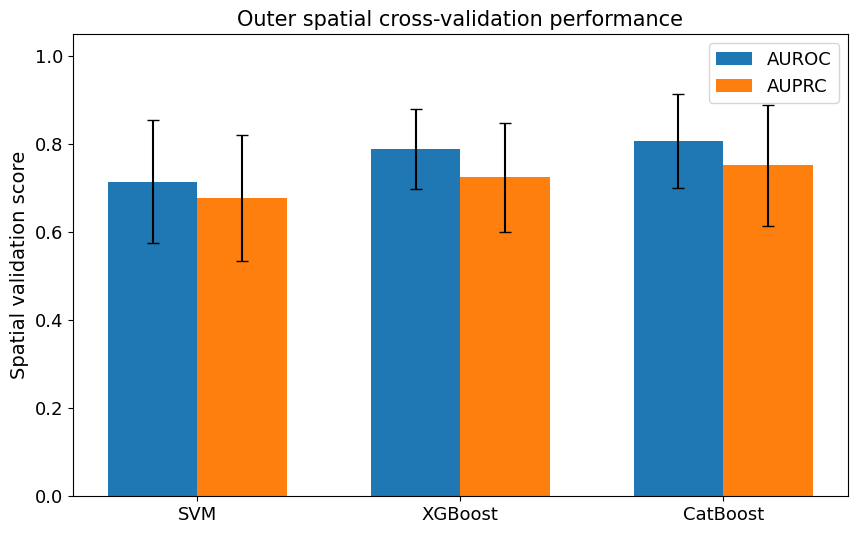

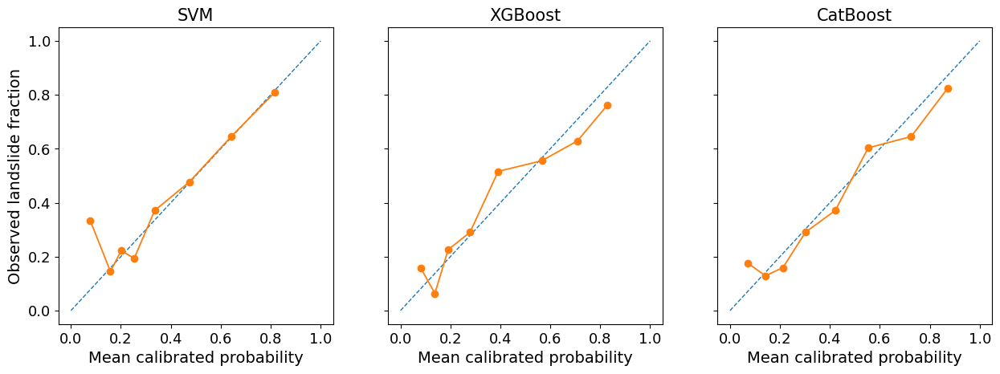

Residual Moran's I:


,Model,Moran_I,Expected_I,Permutation_p_value,Permutations
0,SVM,0.400273,-0.002004,0.001,999
1,XGBoost,0.370882,-0.002004,0.001,999
2,CatBoost,0.394499,-0.002004,0.001,999


In [17]:
# =============================================================================
# CELL 14 - RESIDUAL MORAN'S I, CALIBRATION, AND MODEL-COMPARISON FIGURES
# =============================================================================

MORAN_CSV = (
    NB2_DIRS["validation"]
    / "OOF_Residual_Morans_I.csv"
)

moran_rows = []

coords_by_id = (
    final_model_df
    .set_index(
        "Sample_ID"
    )[
        [
            "Easting",
            "Northing",
        ]
    ]
)

for model_name in MODEL_FAMILIES:
    model_oof = (
        oof_all[
            oof_all[
                "Model"
            ]
            ==
            model_name
        ]
        .set_index(
            "Sample_ID"
        )
        .loc[
            final_model_df[
                "Sample_ID"
            ]
        ]
        .reset_index()
    )

    coordinates = (
        coords_by_id
        .loc[
            model_oof[
                "Sample_ID"
            ]
        ]
        .to_numpy(dtype="float64")
    )

    residual = (
        model_oof[
            "Class"
        ].to_numpy(dtype="float64")
        -
        model_oof[
            "Calibrated_Probability"
        ].to_numpy(dtype="float64")
    )

    weights = KNN.from_array(
        coordinates,
        k=min(
            8,
            len(coordinates) - 1,
        ),
    )

    weights.transform = "R"

    moran = Moran(
        residual,
        weights,
        permutations=999,
    )

    moran_rows.append(
        {
            "Model":
                model_name,
            "Moran_I":
                float(
                    moran.I
                ),
            "Expected_I":
                float(
                    moran.EI
                ),
            "Permutation_p_value":
                float(
                    moran.p_sim
                ),
            "Permutations":
                999,
        }
    )

moran_df = pd.DataFrame(
    moran_rows
)

atomic_csv(
    moran_df,
    MORAN_CSV,
)

# Spatial validation performance.
plot_table = (
    summary_metrics
    .set_index(
        "Model"
    )
)

fig, ax = plt.subplots(
    figsize=(
        10,
        6,
    )
)

x = np.arange(
    len(
        MODEL_FAMILIES
    )
)

width = 0.34

ax.bar(
    x
    -
    width / 2,
    plot_table.loc[
        MODEL_FAMILIES,
        "AUROC_Mean",
    ],
    width,
    yerr=
        plot_table.loc[
            MODEL_FAMILIES,
            "AUROC_SD",
        ],
    capsize=4,
    label="AUROC",
)

ax.bar(
    x
    +
    width / 2,
    plot_table.loc[
        MODEL_FAMILIES,
        "AUPRC_Mean",
    ],
    width,
    yerr=
        plot_table.loc[
            MODEL_FAMILIES,
            "AUPRC_SD",
        ],
    capsize=4,
    label="AUPRC",
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    MODEL_FAMILIES,
    fontsize=FONT_BASE,
)

ax.set_ylim(
    0,
    1.05,
)

ax.set_ylabel(
    "Spatial validation score",
    fontsize=FONT_LABEL,
)

ax.tick_params(
    labelsize=FONT_BASE
)

ax.legend(
    fontsize=FONT_LEGEND
)

ax.set_title(
    "Outer spatial cross-validation performance",
    fontsize=FONT_TITLE,
)

save_figure(
    fig,
    NB2_DIRS["figures"]
    / "Outer_Spatial_Model_Performance.png",
)

# Reliability curves.
fig, axes = plt.subplots(
    1,
    3,
    figsize=(
        15,
        4.8,
    ),
    sharex=True,
    sharey=True,
)

for ax, model_name in zip(
    axes,
    MODEL_FAMILIES,
):
    subset = oof_all[
        oof_all[
            "Model"
        ]
        ==
        model_name
    ]

    fraction_positive, mean_prediction = calibration_curve(
        subset[
            "Class"
        ],
        subset[
            "Calibrated_Probability"
        ],
        n_bins=8,
        strategy="quantile",
    )

    ax.plot(
        [
            0,
            1,
        ],
        [
            0,
            1,
        ],
        linestyle="--",
        linewidth=1.0,
    )

    ax.plot(
        mean_prediction,
        fraction_positive,
        marker="o",
        linewidth=1.3,
    )

    ax.set_title(
        model_name,
        fontsize=FONT_TITLE,
    )

    ax.set_xlabel(
        "Mean calibrated probability",
        fontsize=FONT_LABEL,
    )

    ax.tick_params(
        labelsize=FONT_BASE
    )

axes[
    0
].set_ylabel(
    "Observed landslide fraction",
    fontsize=FONT_LABEL,
)

save_figure(
    fig,
    NB2_DIRS["figures"]
    / "Spatial_OOF_Reliability_Curves.png",
)

print(
    "Residual Moran's I:"
)

display(
    moran_df
)

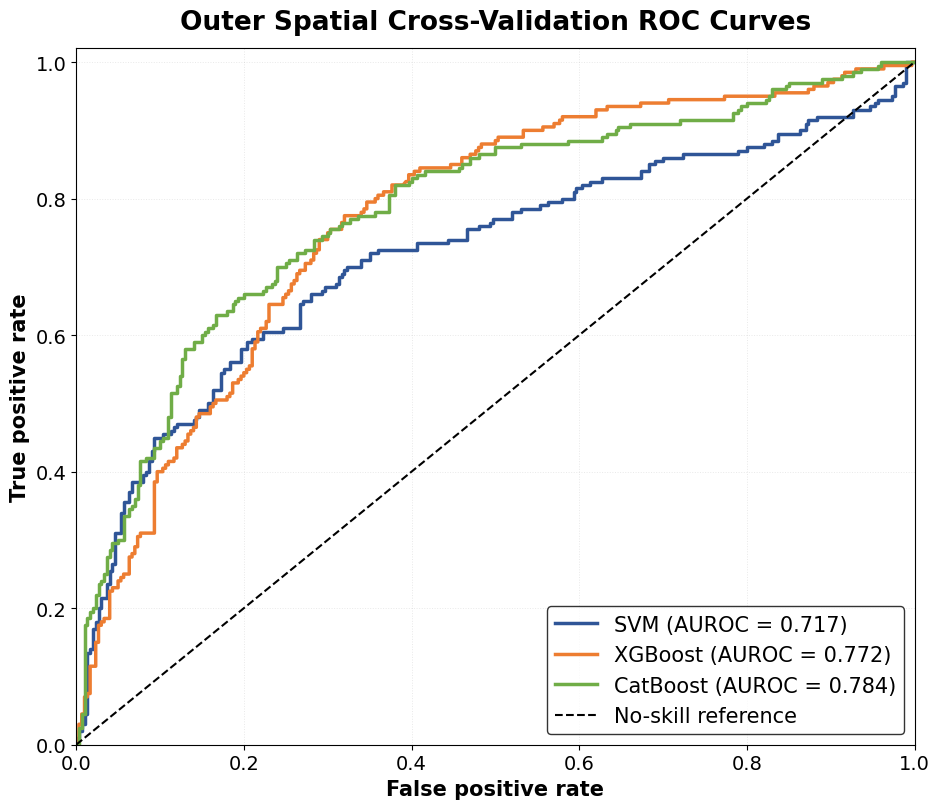

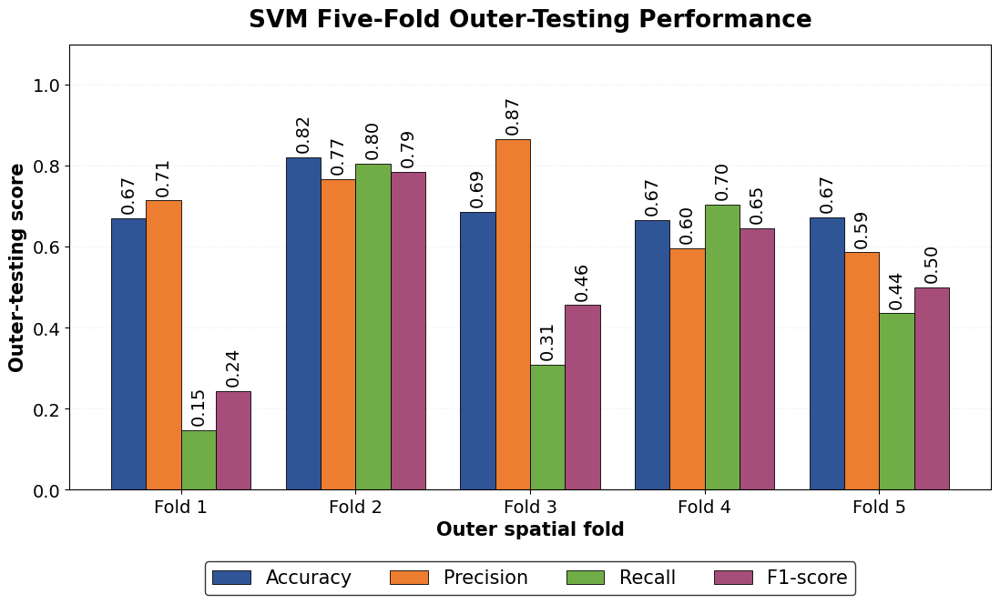

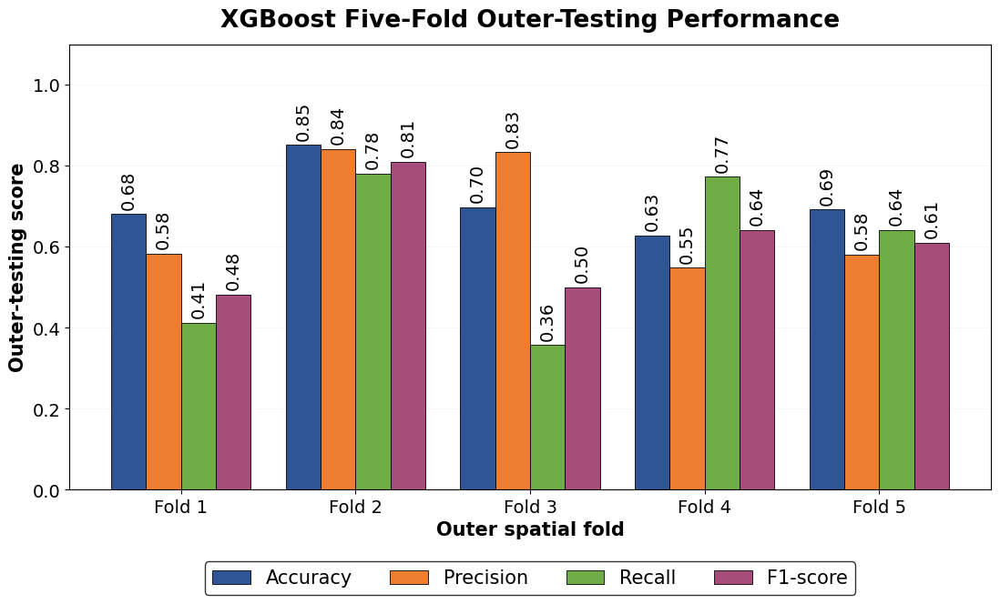

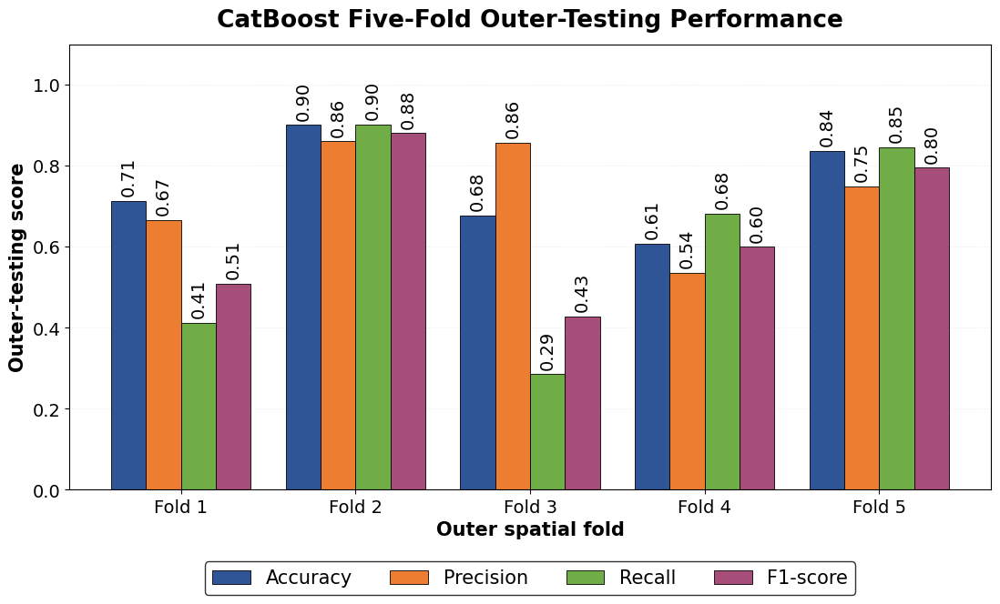

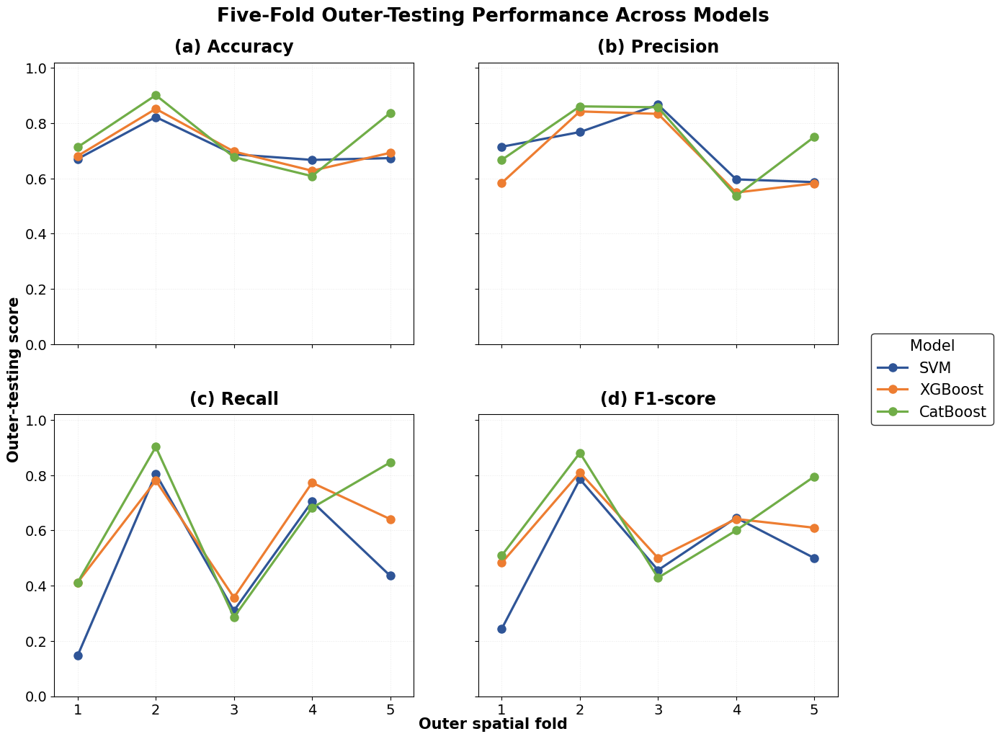


CELL 14A COMPLETE - INDIVIDUAL MODEL PERFORMANCE

OUTER-TEST CORE PERFORMANCE


,Model,Accuracy,Precision,Recall,F1_Score,AUROC
0,SVM,0.704,0.678,0.495,0.572,0.717
1,XGBoost,0.710,0.649,0.600,0.623,0.772
2,CatBoost,0.748,0.708,0.630,0.667,0.784



TRAINING VS OUTER-TESTING PERFORMANCE
Values are mean ± SD across the five outer spatial folds.


,Model,Evaluation_Set,Accuracy,Precision,Recall,F1_Score,AUROC
0,SVM,Outer-training fit,0.862 ± 0.091,0.847 ± 0.093,0.795 ± 0.152,0.819 ± 0.124,0.930 ± 0.057
1,SVM,Outer-test,0.704 ± 0.066,0.706 ± 0.118,0.480 ± 0.273,0.526 ± 0.204,0.715 ± 0.141
2,XGBoost,Outer-training fit,0.875 ± 0.050,0.842 ± 0.057,0.847 ± 0.067,0.844 ± 0.061,0.941 ± 0.043
3,XGBoost,Outer-test,0.710 ± 0.084,0.678 ± 0.147,0.593 ± 0.199,0.609 ± 0.132,0.789 ± 0.090
4,CatBoost,Outer-training fit,0.991 ± 0.006,0.990 ± 0.012,0.989 ± 0.009,0.989 ± 0.008,1.000 ± 0.000
5,CatBoost,Outer-test,0.747 ± 0.120,0.734 ± 0.137,0.626 ± 0.269,0.643 ± 0.191,0.807 ± 0.107



Saved ROC figure:
/content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/15_Figures/Model_Performance/Combined_Outer_Spatial_ROC_SVM_XGBoost_CatBoost.png

Saved five-fold figures:
  SVM      : /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/15_Figures/Model_Performance/SVM_Fold1to5_OuterTesting_Performance.png
  XGBoost  : /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/15_Figures/Model_Performance/XGBoost_Fold1to5_OuterTesting_Performance.png
  CatBoost : /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/15_Figures/Model_Performance/CatBoost_Fold1to5_OuterTesting_Performance.png
  Combined : /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/15_Figures/Model_Performance/Combined_FiveFold_OuterTesting_Performance.png

Saved tables:
  Outer-test core metrics           : /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/16_Tables/Outer_Test_Core_Performance.csv
  Five-fold outer-test metrics      : /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/16_Tables/Outer_Test_FiveFold_Core

In [18]:
# =============================================================================
# CELL 14A - INDIVIDUAL MODEL TRAINING AND OUTER-TEST PERFORMANCE
#            + ROC CURVES + FIVE-FOLD PERFORMANCE FIGURES
# =============================================================================
#
# PURPOSE
# -----------------------------------------------------------------------------
# Produce the performance outputs required for manuscript reporting:
#
#   1. Combined ROC curve for SVM, XGBoost, and CatBoost.
#
#   2. Core outer-testing performance table:
#        - Accuracy
#        - Precision
#        - Recall
#        - F1-score
#        - AUROC
#
#   3. SVM Fold 1-5 outer-testing performance figure.
#
#   4. XGBoost Fold 1-5 outer-testing performance figure.
#
#   5. CatBoost Fold 1-5 outer-testing performance figure.
#
#   6. Combined five-fold comparison figure for all three models.
#
#   7. Training versus outer-testing performance table.
#
# SCIENTIFIC DESIGN
# -----------------------------------------------------------------------------
# OUTER-TEST PERFORMANCE
#
# Uses the spatial OOF predictions already produced in Cell 13.
# Each observation was predicted only when it belonged to the held-out
# outer spatial fold.
#
# Therefore:
#
#     Outer-test results = spatially held-out evaluation.
#
#
# TRAINING PERFORMANCE
#
# Training-side metrics are calculated from the exact saved model fitted to
# each full outer-training partition in Cell 13.
#
# For each model and outer fold:
#
#     saved outer-fold raw model
#         -> outer-training LCF values
#         -> raw model score
#         -> saved training-only Platt calibrator
#         -> calibrated training probability
#         -> metrics at threshold 0.50
#
# IMPORTANT:
#
# These training metrics are fitted-sample, or resubstitution, performance.
# They are useful for comparing training and testing behavior and diagnosing
# overfitting, but they are NOT an independent estimate of generalization.
#
# Generalization performance is represented by the held-out outer-test
# spatial OOF metrics.
#
# NO MODEL IS REFITTED IN THIS CELL.
# NO OPTUNA STUDY IS RERUN.
#
# =============================================================================


# =============================================================================
# 14A.0 IMPORTS
# =============================================================================

import gc
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)


# =============================================================================
# 14A.1 SCIENTIFIC LOCKS
# =============================================================================

PERFORMANCE_MODELS = [
    "SVM",
    "XGBoost",
    "CatBoost",
]


CORE_METRICS = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
]


EXPECTED_OUTER_FOLDS = 5


if int(
    OUTER_FOLDS
) != EXPECTED_OUTER_FOLDS:

    raise RuntimeError(
        "This reporting cell expects the locked five-fold "
        "outer spatial cross-validation framework."
    )


if list(
    MODEL_FAMILIES
) != PERFORMANCE_MODELS:

    if set(
        MODEL_FAMILIES
    ) != set(
        PERFORMANCE_MODELS
    ):

        raise RuntimeError(
            "MODEL_FAMILIES does not contain exactly "
            "SVM, XGBoost, and CatBoost."
        )


# =============================================================================
# 14A.2 PUBLICATION FONT LOCKS
# =============================================================================
#
# All visible text >= 14 pt.
# =============================================================================

PERF_FONT_TICK = 14

PERF_FONT_LABEL = 15

PERF_FONT_TITLE = 17

PERF_FONT_MAIN_TITLE = 19

PERF_FONT_LEGEND = 15

PERF_FONT_ANNOT = 14


# =============================================================================
# 14A.3 MODEL COLORS
# =============================================================================

MODEL_COLORS = {
    "SVM":
        "#2F5597",

    "XGBoost":
        "#ED7D31",

    "CatBoost":
        "#70AD47",
}


METRIC_COLORS = {
    "Accuracy":
        "#2F5597",

    "Precision":
        "#ED7D31",

    "Recall":
        "#70AD47",

    "F1":
        "#A64D79",
}


# =============================================================================
# 14A.4 OUTPUT DIRECTORIES
# =============================================================================

PERFORMANCE_FIG_DIR = (
    NB2_DIRS[
        "figures"
    ]
    /
    "Model_Performance"
)


PERFORMANCE_FIG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


PERFORMANCE_TABLE_DIR = (
    NB2_DIRS[
        "tables"
    ]
)


PERFORMANCE_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# =============================================================================
# 14A.5 OUTPUT PATHS
# =============================================================================

OUTER_TEST_CORE_CSV = (
    PERFORMANCE_TABLE_DIR
    /
    "Outer_Test_Core_Performance.csv"
)


OUTER_TEST_FOLD_CORE_CSV = (
    PERFORMANCE_TABLE_DIR
    /
    "Outer_Test_FiveFold_Core_Metrics.csv"
)


TRAIN_FOLD_METRICS_CSV = (
    PERFORMANCE_TABLE_DIR
    /
    "Outer_Training_FiveFold_Metrics.csv"
)


TRAIN_TEST_FOLD_METRICS_CSV = (
    PERFORMANCE_TABLE_DIR
    /
    "Training_vs_OuterTesting_Fold_Metrics.csv"
)


TRAIN_TEST_SUMMARY_CSV = (
    PERFORMANCE_TABLE_DIR
    /
    "Training_vs_OuterTesting_Performance.csv"
)


ROC_FIGURE = (
    PERFORMANCE_FIG_DIR
    /
    "Combined_Outer_Spatial_ROC_SVM_XGBoost_CatBoost.png"
)


SVM_FOLD_FIGURE = (
    PERFORMANCE_FIG_DIR
    /
    "SVM_Fold1to5_OuterTesting_Performance.png"
)


XGB_FOLD_FIGURE = (
    PERFORMANCE_FIG_DIR
    /
    "XGBoost_Fold1to5_OuterTesting_Performance.png"
)


CAT_FOLD_FIGURE = (
    PERFORMANCE_FIG_DIR
    /
    "CatBoost_Fold1to5_OuterTesting_Performance.png"
)


COMBINED_FOLD_FIGURE = (
    PERFORMANCE_FIG_DIR
    /
    "Combined_FiveFold_OuterTesting_Performance.png"
)


# =============================================================================
# 14A.6 RESTORE REQUIRED VALIDATION OBJECTS IF NECESSARY
# =============================================================================

if "oof_all" not in globals():

    if "OOF_ALL_CSV" not in globals():

        OOF_ALL_CSV = (
            NB2_DIRS[
                "validation"
            ]
            /
            "Outer_Spatial_OOF_All_Models.csv"
        )


    if not Path(
        OOF_ALL_CSV
    ).exists():

        raise FileNotFoundError(
            "Outer OOF predictions are missing.\n"
            "Run Cell 13 before Cell 14A."
        )


    oof_all = pd.read_csv(
        OOF_ALL_CSV
    )


if "fold_metrics_df" not in globals():

    if "FOLD_METRICS_CSV" not in globals():

        FOLD_METRICS_CSV = (
            NB2_DIRS[
                "validation"
            ]
            /
            "Outer_Spatial_Fold_Metrics.csv"
        )


    if not Path(
        FOLD_METRICS_CSV
    ).exists():

        raise FileNotFoundError(
            "Outer spatial fold metrics are missing.\n"
            "Run Cell 13 before Cell 14A."
        )


    fold_metrics_df = pd.read_csv(
        FOLD_METRICS_CSV
    )


if "BUNDLE_OUTER_DIR" not in globals():

    BUNDLE_OUTER_DIR = (
        NB2_DIRS[
            "models"
        ]
        /
        "outer_fold_bundles"
    )


if "final_model_df" not in globals():

    if "FINAL_MODEL_TABLE" not in globals():

        raise RuntimeError(
            "FINAL_MODEL_TABLE is unavailable. "
            "Run the final LCF-table cell before Cell 14A."
        )


    final_model_df = pd.read_parquet(
        FINAL_MODEL_TABLE
    )


if "spatial_df" not in globals():

    spatial_df = pd.read_parquet(
        SPATIAL_FOLD_TABLE
    )


# =============================================================================
# 14A.7 ALIGN SAMPLE ORDER
# =============================================================================

if not final_model_df[
    "Sample_ID"
].equals(
    spatial_df[
        "Sample_ID"
    ]
):

    spatial_df = (
        spatial_df
        .set_index(
            "Sample_ID"
        )
        .loc[
            final_model_df[
                "Sample_ID"
            ]
        ]
        .reset_index()
    )


if not final_model_df[
    "Sample_ID"
].equals(
    spatial_df[
        "Sample_ID"
    ]
):

    raise RuntimeError(
        "Final model table and spatial-fold table could not be aligned."
    )


# =============================================================================
# 14A.8 HARD OOF VALIDATION
# =============================================================================

required_oof_columns = {
    "Sample_ID",
    "Class",
    "Model",
    "Outer_Fold",
    "Calibrated_Probability",
}


missing_oof_columns = (
    required_oof_columns
    -
    set(
        oof_all.columns
    )
)


if missing_oof_columns:

    raise RuntimeError(
        "Required columns are missing from oof_all:\n"
        f"{sorted(missing_oof_columns)}"
    )


for model_name in PERFORMANCE_MODELS:

    model_oof = oof_all[
        oof_all[
            "Model"
        ]
        ==
        model_name
    ].copy()


    if len(
        model_oof
    ) != len(
        final_model_df
    ):

        raise RuntimeError(
            f"{model_name}: expected one held-out prediction "
            "for every model-table observation."
        )


    if model_oof[
        "Sample_ID"
    ].duplicated().any():

        raise RuntimeError(
            f"{model_name}: duplicate outer OOF Sample_ID values detected."
        )


    observed_folds = sorted(
        model_oof[
            "Outer_Fold"
        ]
        .astype(int)
        .unique()
        .tolist()
    )


    if observed_folds != [
        0,
        1,
        2,
        3,
        4,
    ]:

        raise RuntimeError(
            f"{model_name}: outer folds are incomplete.\n"
            f"Observed: {observed_folds}"
        )


# =============================================================================
# 14A.9 CORE OUTER-TEST PERFORMANCE TABLE
# =============================================================================
#
# Pooled OOF performance:
#
# Every observation contributes exactly one held-out outer-fold prediction.
# =============================================================================

outer_test_core_rows = []


for model_name in PERFORMANCE_MODELS:

    subset = (
        oof_all[
            oof_all[
                "Model"
            ]
            ==
            model_name
        ]
        .set_index(
            "Sample_ID"
        )
        .loc[
            final_model_df[
                "Sample_ID"
            ]
        ]
        .reset_index()
    )


    y_true = subset[
        "Class"
    ].to_numpy(
        dtype=int
    )


    probability = subset[
        "Calibrated_Probability"
    ].to_numpy(
        dtype="float64"
    )


    metrics = classification_metrics(
        y_true,
        probability,
        threshold=0.5,
    )


    outer_test_core_rows.append(
        {
            "Model":
                model_name,

            "Accuracy":
                metrics[
                    "Accuracy"
                ],

            "Precision":
                metrics[
                    "Precision"
                ],

            "Recall":
                metrics[
                    "Recall"
                ],

            "F1":
                metrics[
                    "F1"
                ],

            "AUROC":
                metrics[
                    "AUROC"
                ],
        }
    )


outer_test_core_df = pd.DataFrame(
    outer_test_core_rows
)


atomic_csv(
    outer_test_core_df,
    OUTER_TEST_CORE_CSV,
)


# =============================================================================
# 14A.10 FIVE-FOLD OUTER-TEST CORE METRICS
# =============================================================================

outer_test_fold_core_df = (
    fold_metrics_df[
        fold_metrics_df[
            "Model"
        ].isin(
            PERFORMANCE_MODELS
        )
    ][
        [
            "Model",
            "Outer_Fold",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "AUROC",
        ]
    ]
    .copy()
)


outer_test_fold_core_df[
    "Fold"
] = (
    outer_test_fold_core_df[
        "Outer_Fold"
    ]
    .astype(int)
    +
    1
)


outer_test_fold_core_df = (
    outer_test_fold_core_df[
        [
            "Model",
            "Fold",
            "Outer_Fold",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "AUROC",
        ]
    ]
    .sort_values(
        [
            "Model",
            "Fold",
        ]
    )
    .reset_index(
        drop=True
    )
)


atomic_csv(
    outer_test_fold_core_df,
    OUTER_TEST_FOLD_CORE_CSV,
)


# =============================================================================
# 14A.11 TRAINING-SIDE PERFORMANCE FROM SAVED OUTER-FOLD FITS
# =============================================================================
#
# IMPORTANT:
#
# No refitting occurs here.
#
# Each saved bundle contains:
#
#     model
#     calibrator
#     params
#     outer_fold
#
# The saved raw model was fitted on the entire corresponding outer-training
# partition in Cell 13.
#
# The saved Platt calibrator was estimated ONLY using inner-spatial OOF scores
# from that same outer-training partition.
#
# We apply those exact saved objects to the outer-training observations.
# =============================================================================

training_rows = []


for model_name in PERFORMANCE_MODELS:

    for outer_fold in range(
        OUTER_FOLDS
    ):

        bundle_path = (
            BUNDLE_OUTER_DIR
            /
            f"{model_name}_Outer{outer_fold}_bundle.joblib"
        )


        if not bundle_path.exists():

            raise FileNotFoundError(
                "Missing saved outer-fold model bundle:\n"
                f"{bundle_path}"
            )


        bundle = joblib.load(
            bundle_path
        )


        if bundle.get(
            "model_name"
        ) != model_name:

            raise RuntimeError(
                f"{bundle_path.name}: model identity mismatch."
            )


        if int(
            bundle.get(
                "outer_fold"
            )
        ) != int(
            outer_fold
        ):

            raise RuntimeError(
                f"{bundle_path.name}: outer-fold identity mismatch."
            )


        if bundle.get(
            "rainfall"
        ) != SELECTED_RAINFALL:

            raise RuntimeError(
                f"{model_name} outer fold {outer_fold}: "
                "saved bundle rainfall differs from the current "
                "study-wide selected rainfall LCF."
            )


        outer_test_mask = (
            spatial_df[
                "Outer_Fold"
            ].to_numpy(
                dtype=int
            )
            ==
            outer_fold
        )


        outer_train_mask = (
            ~outer_test_mask
        )


        X_outer_train = build_conceptual_frame(
            final_model_df.loc[
                outer_train_mask
            ],
            "Rainfall",
        )


        y_outer_train = (
            final_model_df.loc[
                outer_train_mask,
                "Class",
            ]
            .to_numpy(
                dtype=int
            )
        )


        saved_model = bundle[
            "model"
        ]


        saved_calibrator = bundle[
            "calibrator"
        ]


        raw_training_score = raw_model_score(
            model_name,
            saved_model,
            X_outer_train,
        )


        training_probability = apply_platt(
            saved_calibrator,
            raw_training_score,
        )


        training_metrics = classification_metrics(
            y_outer_train,
            training_probability,
            threshold=0.5,
        )


        training_rows.append(
            {
                "Model":
                    model_name,

                "Outer_Fold":
                    outer_fold,

                "Fold":
                    outer_fold
                    +
                    1,

                "N":
                    int(
                        len(
                            y_outer_train
                        )
                    ),

                "Accuracy":
                    training_metrics[
                        "Accuracy"
                    ],

                "Precision":
                    training_metrics[
                        "Precision"
                    ],

                "Recall":
                    training_metrics[
                        "Recall"
                    ],

                "F1":
                    training_metrics[
                        "F1"
                    ],

                "AUROC":
                    training_metrics[
                        "AUROC"
                    ],
            }
        )


        del bundle
        del saved_model
        del saved_calibrator

        gc.collect()


training_fold_df = pd.DataFrame(
    training_rows
)


atomic_csv(
    training_fold_df,
    TRAIN_FOLD_METRICS_CSV,
)


# =============================================================================
# 14A.12 BUILD TRAINING + OUTER-TEST FOLD TABLE
# =============================================================================

training_for_comparison = training_fold_df[
    [
        "Model",
        "Outer_Fold",
        "Fold",
        "N",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "AUROC",
    ]
].copy()


training_for_comparison[
    "Evaluation_Set"
] = (
    "Outer-training fit"
)


testing_for_comparison = (
    outer_test_fold_core_df.copy()
)


test_n_rows = []


for model_name in PERFORMANCE_MODELS:

    for outer_fold in range(
        OUTER_FOLDS
    ):

        subset = oof_all[
            (
                oof_all[
                    "Model"
                ]
                ==
                model_name
            )
            &
            (
                oof_all[
                    "Outer_Fold"
                ]
                ==
                outer_fold
            )
        ]


        test_n_rows.append(
            {
                "Model":
                    model_name,

                "Outer_Fold":
                    outer_fold,

                "N":
                    int(
                        len(
                            subset
                        )
                    ),
            }
        )


test_n_df = pd.DataFrame(
    test_n_rows
)


testing_for_comparison = (
    testing_for_comparison
    .merge(
        test_n_df,
        on=[
            "Model",
            "Outer_Fold",
        ],
        how="left",
        validate="one_to_one",
    )
)


testing_for_comparison[
    "Evaluation_Set"
] = (
    "Outer-test"
)


training_testing_fold_df = pd.concat(
    [
        training_for_comparison,
        testing_for_comparison[
            training_for_comparison.columns
        ],
    ],
    ignore_index=True,
)


training_testing_fold_df = (
    training_testing_fold_df
    .sort_values(
        [
            "Model",
            "Evaluation_Set",
            "Fold",
        ]
    )
    .reset_index(
        drop=True
    )
)


atomic_csv(
    training_testing_fold_df,
    TRAIN_TEST_FOLD_METRICS_CSV,
)


# =============================================================================
# 14A.13 TRAINING VS OUTER-TESTING SUMMARY TABLE
# =============================================================================
#
# Mean and standard deviation across the five outer folds.
# =============================================================================

summary_rows = []


for model_name in PERFORMANCE_MODELS:

    for evaluation_set in [
        "Outer-training fit",
        "Outer-test",
    ]:

        subset = training_testing_fold_df[
            (
                training_testing_fold_df[
                    "Model"
                ]
                ==
                model_name
            )
            &
            (
                training_testing_fold_df[
                    "Evaluation_Set"
                ]
                ==
                evaluation_set
            )
        ]


        if len(
            subset
        ) != OUTER_FOLDS:

            raise RuntimeError(
                f"{model_name}, {evaluation_set}: expected "
                f"{OUTER_FOLDS} folds but found {len(subset)}."
            )


        row = {
            "Model":
                model_name,

            "Evaluation_Set":
                evaluation_set,
        }


        for metric in [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "AUROC",
        ]:

            mean_value = float(
                subset[
                    metric
                ].mean()
            )


            sd_value = float(
                subset[
                    metric
                ].std(
                    ddof=1
                )
            )


            row[
                f"{metric}_Mean"
            ] = mean_value


            row[
                f"{metric}_SD"
            ] = sd_value


            row[
                f"{metric}_Mean_SD"
            ] = (
                f"{mean_value:.3f} ± "
                f"{sd_value:.3f}"
            )


        summary_rows.append(
            row
        )


training_testing_summary_df = pd.DataFrame(
    summary_rows
)


atomic_csv(
    training_testing_summary_df,
    TRAIN_TEST_SUMMARY_CSV,
)


# =============================================================================
# 14A.14 FIGURE 1 - COMBINED OUTER-SPATIAL ROC CURVES
# =============================================================================
#
# Curves use pooled outer OOF predictions.
#
# Every sample contributes exactly one held-out prediction for each model.
# =============================================================================

fig, ax = plt.subplots(
    figsize=(
        9.5,
        8.2,
    )
)


for model_name in PERFORMANCE_MODELS:

    subset = (
        oof_all[
            oof_all[
                "Model"
            ]
            ==
            model_name
        ]
        .set_index(
            "Sample_ID"
        )
        .loc[
            final_model_df[
                "Sample_ID"
            ]
        ]
        .reset_index()
    )


    y_true = subset[
        "Class"
    ].to_numpy(
        dtype=int
    )


    probability = subset[
        "Calibrated_Probability"
    ].to_numpy(
        dtype="float64"
    )


    fpr, tpr, _ = roc_curve(
        y_true,
        probability,
    )


    auc_value = roc_auc_score(
        y_true,
        probability,
    )


    ax.plot(
        fpr,
        tpr,
        linewidth=2.5,
        color=MODEL_COLORS[
            model_name
        ],
        label=(
            f"{model_name} "
            f"(AUROC = {auc_value:.3f})"
        ),
    )


# No-skill line.
ax.plot(
    [
        0,
        1,
    ],
    [
        0,
        1,
    ],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="No-skill reference",
)


ax.set_xlim(
    0.0,
    1.0,
)


ax.set_ylim(
    0.0,
    1.02,
)


ax.set_xlabel(
    "False positive rate",
    fontsize=PERF_FONT_LABEL,
    fontweight="bold",
)


ax.set_ylabel(
    "True positive rate",
    fontsize=PERF_FONT_LABEL,
    fontweight="bold",
)


ax.set_title(
    "Outer Spatial Cross-Validation ROC Curves",
    fontsize=PERF_FONT_MAIN_TITLE,
    fontweight="bold",
    pad=14,
)


ax.tick_params(
    axis="both",
    labelsize=PERF_FONT_TICK,
)


ax.legend(
    fontsize=PERF_FONT_LEGEND,
    loc="lower right",
    frameon=True,
    edgecolor="black",
)


ax.grid(
    linestyle=":",
    linewidth=0.7,
    alpha=0.28,
)


ax.set_axisbelow(
    True
)


fig.tight_layout()


save_figure(
    fig,
    ROC_FIGURE,
)


# =============================================================================
# 14A.15 HELPER - INDIVIDUAL MODEL FIVE-FOLD TESTING FIGURE
# =============================================================================

def plot_model_fold_performance(
    model_name,
    output_path,
):

    subset = (
        outer_test_fold_core_df[
            outer_test_fold_core_df[
                "Model"
            ]
            ==
            model_name
        ]
        .sort_values(
            "Fold"
        )
        .reset_index(
            drop=True
        )
    )


    if len(
        subset
    ) != OUTER_FOLDS:

        raise RuntimeError(
            f"{model_name}: expected {OUTER_FOLDS} outer folds."
        )


    folds = subset[
        "Fold"
    ].to_numpy(
        dtype=int
    )


    x = np.arange(
        len(
            folds
        )
    )


    n_metrics = len(
        CORE_METRICS
    )


    total_width = 0.80


    bar_width = (
        total_width
        /
        n_metrics
    )


    offsets = (
        np.arange(
            n_metrics
        )
        -
        (
            n_metrics
            -
            1
        )
        /
        2
    ) * bar_width


    fig, ax = plt.subplots(
        figsize=(
            11.5,
            7.2,
        )
    )


    for metric_index, metric in enumerate(
        CORE_METRICS
    ):

        values = subset[
            metric
        ].to_numpy(
            dtype="float64"
        )


        bars = ax.bar(
            x
            +
            offsets[
                metric_index
            ],
            values,
            width=bar_width,
            label=(
                "F1-score"
                if metric == "F1"
                else metric
            ),
            color=METRIC_COLORS[
                metric
            ],
            edgecolor="black",
            linewidth=0.6,
        )


        for bar, value in zip(
            bars,
            values,
        ):

            ax.text(
                bar.get_x()
                +
                bar.get_width()
                /
                2,
                value
                +
                0.012,
                f"{value:.2f}",
                ha="center",
                va="bottom",
                rotation=90,
                fontsize=PERF_FONT_ANNOT,
            )


    ax.set_xticks(
        x
    )


    ax.set_xticklabels(
        [
            f"Fold {fold}"
            for fold in folds
        ],
        fontsize=PERF_FONT_TICK,
    )


    ax.set_ylim(
        0.0,
        1.10,
    )


    ax.set_ylabel(
        "Outer-testing score",
        fontsize=PERF_FONT_LABEL,
        fontweight="bold",
    )


    ax.set_xlabel(
        "Outer spatial fold",
        fontsize=PERF_FONT_LABEL,
        fontweight="bold",
    )


    ax.set_title(
        f"{model_name} Five-Fold Outer-Testing Performance",
        fontsize=PERF_FONT_MAIN_TITLE,
        fontweight="bold",
        pad=14,
    )


    ax.tick_params(
        axis="y",
        labelsize=PERF_FONT_TICK,
    )


    ax.legend(
        fontsize=PERF_FONT_LEGEND,
        ncol=4,
        loc="upper center",
        bbox_to_anchor=(
            0.5,
            -0.14,
        ),
        frameon=True,
        edgecolor="black",
    )


    ax.grid(
        axis="y",
        linestyle=":",
        linewidth=0.7,
        alpha=0.28,
    )


    ax.set_axisbelow(
        True
    )


    fig.subplots_adjust(
        left=0.10,
        right=0.98,
        bottom=0.22,
        top=0.90,
    )


    save_figure(
        fig,
        output_path,
    )


# =============================================================================
# 14A.16 FIGURE 2 - SVM FIVE-FOLD TESTING PERFORMANCE
# =============================================================================

plot_model_fold_performance(
    "SVM",
    SVM_FOLD_FIGURE,
)


# =============================================================================
# 14A.17 FIGURE 3 - XGBOOST FIVE-FOLD TESTING PERFORMANCE
# =============================================================================

plot_model_fold_performance(
    "XGBoost",
    XGB_FOLD_FIGURE,
)


# =============================================================================
# 14A.18 FIGURE 4 - CATBOOST FIVE-FOLD TESTING PERFORMANCE
# =============================================================================

plot_model_fold_performance(
    "CatBoost",
    CAT_FOLD_FIGURE,
)


# =============================================================================
# 14A.19 FIGURE 5 - COMBINED FIVE-FOLD MODEL COMPARISON
# =============================================================================
#
# Four panels:
#
#   A. Accuracy
#   B. Precision
#   C. Recall
#   D. F1-score
#
# Each panel compares SVM, XGBoost, and CatBoost across Fold 1-5.
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        14.5,
        11.0,
    ),
    sharex=True,
    sharey=True,
)


axes = axes.ravel()


panel_letters = [
    "(a)",
    "(b)",
    "(c)",
    "(d)",
]


for ax, metric, panel_letter in zip(
    axes,
    CORE_METRICS,
    panel_letters,
):

    for model_name in PERFORMANCE_MODELS:

        subset = (
            outer_test_fold_core_df[
                outer_test_fold_core_df[
                    "Model"
                ]
                ==
                model_name
            ]
            .sort_values(
                "Fold"
            )
        )


        ax.plot(
            subset[
                "Fold"
            ],
            subset[
                metric
            ],
            marker="o",
            markersize=8,
            linewidth=2.3,
            color=MODEL_COLORS[
                model_name
            ],
            label=model_name,
        )


    ax.set_xlim(
        0.7,
        5.3,
    )


    ax.set_ylim(
        0.0,
        1.02,
    )


    ax.set_xticks(
        [
            1,
            2,
            3,
            4,
            5,
        ]
    )


    ax.set_xticklabels(
        [
            "1",
            "2",
            "3",
            "4",
            "5",
        ],
        fontsize=PERF_FONT_TICK,
    )


    metric_title = (
        "F1-score"
        if metric == "F1"
        else metric
    )


    ax.set_title(
        f"{panel_letter} {metric_title}",
        fontsize=PERF_FONT_TITLE,
        fontweight="bold",
        pad=10,
    )


    ax.tick_params(
        axis="both",
        labelsize=PERF_FONT_TICK,
    )


    ax.grid(
        linestyle=":",
        linewidth=0.7,
        alpha=0.28,
    )


    ax.set_axisbelow(
        True
    )


# Shared labels.
fig.supxlabel(
    "Outer spatial fold",
    fontsize=PERF_FONT_LABEL,
    fontweight="bold",
    y=0.055,
)


fig.supylabel(
    "Outer-testing score",
    fontsize=PERF_FONT_LABEL,
    fontweight="bold",
    x=0.035,
)


fig.suptitle(
    "Five-Fold Outer-Testing Performance Across Models",
    fontsize=PERF_FONT_MAIN_TITLE,
    fontweight="bold",
    y=0.97,
)


# One common legend outside on the right.
handles, labels = axes[
    0
].get_legend_handles_labels()


fig.legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(
        0.855,
        0.50,
    ),
    fontsize=PERF_FONT_LEGEND,
    title="Model",
    title_fontsize=PERF_FONT_LEGEND,
    frameon=True,
    edgecolor="black",
)


fig.subplots_adjust(
    left=0.08,
    right=0.83,
    bottom=0.10,
    top=0.90,
    wspace=0.18,
    hspace=0.25,
)


save_figure(
    fig,
    COMBINED_FOLD_FIGURE,
)


# =============================================================================
# 14A.20 CLEAN MANUSCRIPT CORE PERFORMANCE TABLE
# =============================================================================
#
# Pooled held-out OOF metrics.
# =============================================================================

manuscript_core_table = (
    outer_test_core_df[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "AUROC",
        ]
    ]
    .copy()
)


manuscript_core_table.rename(
    columns={
        "F1":
            "F1_Score",
    },
    inplace=True,
)


for column in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "AUROC",
]:

    manuscript_core_table[
        column
    ] = manuscript_core_table[
        column
    ].round(
        3
    )


# =============================================================================
# 14A.21 CLEAN TRAINING VS TESTING TABLE
# =============================================================================
#
# The Mean ± SD fields are intended for direct manuscript use.
# =============================================================================

training_testing_manuscript_table = (
    training_testing_summary_df[
        [
            "Model",
            "Evaluation_Set",
            "Accuracy_Mean_SD",
            "Precision_Mean_SD",
            "Recall_Mean_SD",
            "F1_Mean_SD",
            "AUROC_Mean_SD",
        ]
    ]
    .copy()
)


training_testing_manuscript_table.rename(
    columns={
        "Accuracy_Mean_SD":
            "Accuracy",

        "Precision_Mean_SD":
            "Precision",

        "Recall_Mean_SD":
            "Recall",

        "F1_Mean_SD":
            "F1_Score",

        "AUROC_Mean_SD":
            "AUROC",
    },
    inplace=True,
)


# =============================================================================
# 14A.22 FINAL HARD CHECKS
# =============================================================================

required_outputs = [
    OUTER_TEST_CORE_CSV,
    OUTER_TEST_FOLD_CORE_CSV,
    TRAIN_FOLD_METRICS_CSV,
    TRAIN_TEST_FOLD_METRICS_CSV,
    TRAIN_TEST_SUMMARY_CSV,
    ROC_FIGURE,
    SVM_FOLD_FIGURE,
    XGB_FOLD_FIGURE,
    CAT_FOLD_FIGURE,
    COMBINED_FOLD_FIGURE,
]


for output_path in required_outputs:

    if not Path(
        output_path
    ).exists():

        raise RuntimeError(
            "Expected performance output is missing:\n"
            f"{output_path}"
        )


# =============================================================================
# 14A.23 REPORT
# =============================================================================

print()
print(
    "=" * 110
)

print(
    "CELL 14A COMPLETE - INDIVIDUAL MODEL PERFORMANCE"
)

print(
    "=" * 110
)


print(
    "\nOUTER-TEST CORE PERFORMANCE"
)


display(
    manuscript_core_table
)


print(
    "\nTRAINING VS OUTER-TESTING PERFORMANCE"
)

print(
    "Values are mean ± SD across the five outer spatial folds."
)


display(
    training_testing_manuscript_table
)


print()
print(
    "Saved ROC figure:"
)

print(
    ROC_FIGURE
)


print()
print(
    "Saved five-fold figures:"
)

print(
    "  SVM      :",
    SVM_FOLD_FIGURE
)

print(
    "  XGBoost  :",
    XGB_FOLD_FIGURE
)

print(
    "  CatBoost :",
    CAT_FOLD_FIGURE
)

print(
    "  Combined :",
    COMBINED_FOLD_FIGURE
)


print()
print(
    "Saved tables:"
)

print(
    "  Outer-test core metrics           :",
    OUTER_TEST_CORE_CSV
)

print(
    "  Five-fold outer-test metrics      :",
    OUTER_TEST_FOLD_CORE_CSV
)

print(
    "  Five-fold training metrics        :",
    TRAIN_FOLD_METRICS_CSV
)

print(
    "  Training/testing fold table       :",
    TRAIN_TEST_FOLD_METRICS_CSV
)

print(
    "  Training/testing summary          :",
    TRAIN_TEST_SUMMARY_CSV
)


print()
print(
    "Training performance = fitted outer-training performance."
)

print(
    "Outer-test performance = held-out spatial OOF performance."
)

print(
    "=" * 110
)

In [19]:
# =============================================================================
# CELL 15 - FINAL FULL-DATA SPATIAL OPTUNA FOR DEPLOYABLE CONFIGURATIONS
# HEAVY / RESUME-SAFE
# =============================================================================

FINAL_OPTUNA_RESULTS = {}

for model_name in MODEL_FAMILIES:
    signature_value = stable_signature(
        {
            "version":
                NOTEBOOK2_VERSION,
            "stage":
                "final_full_spatial_optuna",
            "sample_hash":
                FINAL_SAMPLE_HASH,
            "spatial_signature":
                SPATIAL_SIGNATURE,
            "selected_rainfall":
                SELECTED_RAINFALL,
            "model":
                model_name,
            "objective":
                "mean_outer_spatial_AUPRC",
            "trials":
                OPTUNA_TRIALS_FINAL,
        }
    )

    result = run_journal_study(
        study_name=
            f"TNMA_{model_name}_Final",
        objective=
            full_objective_factory(
                model_name
            ),
        target_trials=
            OPTUNA_TRIALS_FINAL,
        drive_journal=
            NB2_DIRS["optuna"]
            /
            f"{model_name}_Final.journal",
        best_json=
            OPTUNA_BEST_DIR
            /
            f"{model_name}_Final_best.json",
        scientific_signature=
            signature_value,
    )

    FINAL_OPTUNA_RESULTS[
        model_name
    ] = result

display(
    pd.DataFrame(
        [
            {
                "Model":
                    model_name,
                "Best_AUPRC":
                    result[
                        "Best_Value_AUPRC"
                    ],
                **result[
                    "Best_Params"
                ],
            }
            for model_name, result
            in FINAL_OPTUNA_RESULTS.items()
        ]
    )
)

✓ RESTORE: TNMA_SVM_Final
✓ RESTORE: TNMA_XGBoost_Final
✓ RESTORE: TNMA_CatBoost_Final


,Model,Best_AUPRC,kernel,C,gamma,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_alpha,reg_lambda,iterations,depth,l2_leaf_reg,random_strength,bagging_temperature
0,SVM,0.721650,rbf,267.405219,0.284393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,XGBoost,0.741669,NaN,NaN,3.543997,900.0,6.0,0.074606,0.89149,0.611148,17.1364,2.790105,16.416965,NaN,NaN,NaN,NaN,NaN
2,CatBoost,0.787471,NaN,NaN,NaN,NaN,NaN,0.012421,NaN,NaN,NaN,NaN,NaN,300.0,10.0,0.607622,1.97848,4.592666


In [20]:
# =============================================================================
# CELL 16 - FINAL FULL-DATA RAW MODELS + SPATIAL OOF PLATT CALIBRATORS
# HEAVY / RESUME-SAFE
# =============================================================================

FINAL_BUNDLE_DIR = (
    NB2_DIRS["models"]
    / "final_bundles"
)

FINAL_BUNDLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FINAL_BUNDLE_MANIFEST = (
    NB2_DIRS["models"]
    / "Final_Model_Bundles.json"
)

FINAL_BUNDLES = {}

for model_name in MODEL_FAMILIES:
    params_data = read_json(
        OPTUNA_BEST_DIR
        /
        f"{model_name}_Final_best.json"
    )

    params = params_data[
        "Best_Params"
    ]

    bundle_file = (
        FINAL_BUNDLE_DIR
        /
        f"{model_name}_Final_Calibrated.joblib"
    )

    state_file = (
        FINAL_BUNDLE_DIR
        /
        f"{model_name}_Final_Calibrated.state.json"
    )

    signature_value = stable_signature(
        {
            "stage":
                "final_bundle",
            "sample_hash":
                FINAL_SAMPLE_HASH,
            "spatial_signature":
                SPATIAL_SIGNATURE,
            "selected_rainfall":
                SELECTED_RAINFALL,
            "model":
                model_name,
            "params_signature":
                params_data[
                    "Signature"
                ],
            "calibration":
                "full-sample spatial OOF Platt",
        }
    )

    if state_matches(
        state_file,
        signature_value,
        [
            bundle_file
        ],
    ):
        bundle = joblib.load(
            bundle_file
        )

        FINAL_BUNDLES[
            model_name
        ] = bundle

        print(
            "✓ RESTORE: final calibrated bundle:",
            model_name,
        )

        continue

    y = final_model_df[
        "Class"
    ].to_numpy(dtype=int)

    raw_oof = np.full(
        len(
            final_model_df
        ),
        np.nan,
        dtype="float64",
    )

    for fold in range(
        OUTER_FOLDS
    ):
        train_mask = (
            spatial_df[
                "Outer_Fold"
            ].to_numpy(dtype=int)
            !=
            fold
        )

        valid_mask = (
            ~train_mask
        )

        X_train = build_conceptual_frame(
            final_model_df.loc[
                train_mask
            ],
            "Rainfall",
        )

        y_train = y[
            train_mask
        ]

        X_valid = build_conceptual_frame(
            final_model_df.loc[
                valid_mask
            ],
            "Rainfall",
        )

        model = fit_raw_model(
            model_name,
            params,
            X_train,
            y_train,
        )

        raw_oof[
            valid_mask
        ] = raw_model_score(
            model_name,
            model,
            X_valid,
        )

        del model
        gc.collect()

    if not np.isfinite(
        raw_oof
    ).all():
        raise RuntimeError(
            f"{model_name}: final spatial OOF raw scores incomplete."
        )

    calibrator = fit_platt(
        raw_oof,
        y,
    )

    X_all = build_conceptual_frame(
        final_model_df,
        "Rainfall",
    )

    final_raw_model = fit_raw_model(
        model_name,
        params,
        X_all,
        y,
    )

    bundle = {
        "model_name":
            model_name,
        "params":
            params,
        "model":
            final_raw_model,
        "calibrator":
            calibrator,
        "rainfall":
            SELECTED_RAINFALL,
        "conceptual_features":
            FINAL_CONCEPTUAL_FEATURES,
        "include_geo":
            False,
        "signature":
            signature_value,
        "spatial_oof_raw_scores":
            raw_oof,
    }

    atomic_joblib(
        bundle,
        bundle_file,
    )

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature":
                signature_value,
            "Bundle":
                str(
                    bundle_file
                ),
            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        state_file,
    )

    FINAL_BUNDLES[
        model_name
    ] = bundle

atomic_json(
    {
        "Status": "COMPLETE",
        "Selected_Rainfall":
            SELECTED_RAINFALL,
        "Bundles":
            {
                model_name:
                    str(
                        FINAL_BUNDLE_DIR
                        /
                        f"{model_name}_Final_Calibrated.joblib"
                    )
                for model_name
                in MODEL_FAMILIES
            },
        "Completed_UTC":
            pd.Timestamp.utcnow().isoformat(),
    },
    FINAL_BUNDLE_MANIFEST,
)

print(
    "Final calibrated model bundles ready."
)

✓ RESTORE: final calibrated bundle: SVM
✓ RESTORE: final calibrated bundle: XGBoost
✓ RESTORE: final calibrated bundle: CatBoost
Final calibrated model bundles ready.


✓ RESTORE: learning curves.


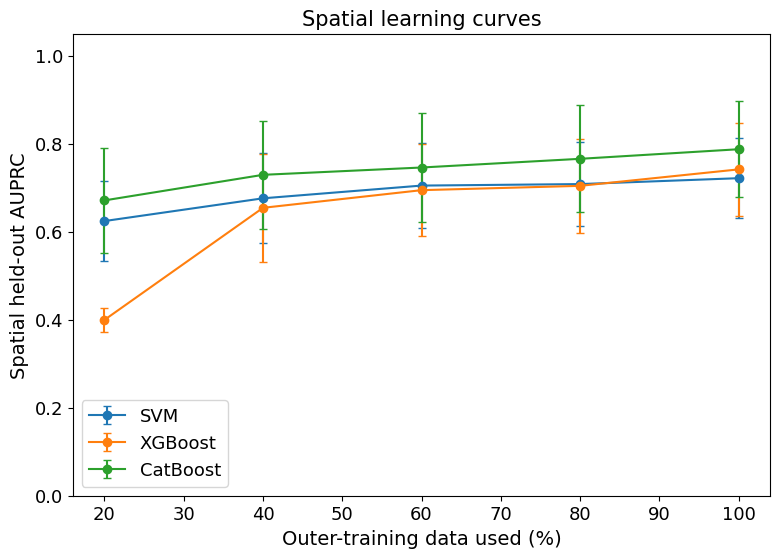

,Model,Fraction,AUPRC_Mean,AUPRC_SD,AUROC_Mean,AUROC_SD
0,CatBoost,0.2,0.671171,0.119383,0.745714,0.088593
1,CatBoost,0.4,0.729315,0.122055,0.784087,0.090578
2,CatBoost,0.6,0.745940,0.123737,0.803905,0.092781
3,CatBoost,0.8,0.765696,0.121673,0.814145,0.091704
4,CatBoost,1.0,0.787471,0.109155,0.829896,0.084351
5,SVM,0.2,0.624241,0.091185,0.697007,0.081829
6,SVM,0.4,0.675944,0.102485,0.735131,0.084991
7,SVM,0.6,0.704868,0.096263,0.764418,0.086678
8,SVM,0.8,0.708279,0.096278,0.769826,0.089200
9,SVM,1.0,0.721650,0.091508,0.777870,0.091171


In [21]:
# =============================================================================
# CELL 17 - SPATIAL LEARNING CURVES
# HEAVY / RESUME-SAFE
# =============================================================================
# AUPRC and AUROC are evaluated on spatially held-out outer folds.
# =============================================================================

LC_UNIT_DIR = (
    NB2_DIRS["validation"]
    / "learning_curve_units"
)

LC_UNIT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

LC_CSV = (
    NB2_DIRS["validation"]
    / "Learning_Curves.csv"
)

LC_STATE = (
    NB2_DIRS["checkpoints"]
    / "Learning_Curves.state.json"
)

LC_SIGNATURE = stable_signature(
    {
        "sample_hash":
            FINAL_SAMPLE_HASH,
        "spatial_signature":
            SPATIAL_SIGNATURE,
        "selected_rainfall":
            SELECTED_RAINFALL,
        "fractions":
            LEARNING_CURVE_FRACTIONS,
        "repeats":
            LEARNING_CURVE_REPEATS,
        "final_param_signatures":
            {
                model_name:
                    read_json(
                        OPTUNA_BEST_DIR
                        /
                        f"{model_name}_Final_best.json"
                    )[
                        "Signature"
                    ]
                for model_name
                in MODEL_FAMILIES
            },
    }
)

def stratified_fraction_indices(
    indices,
    y,
    fraction,
    seed,
):
    indices = np.asarray(
        indices,
        dtype=int,
    )

    y_sub = y[
        indices
    ]

    if fraction >= 0.999999:
        return indices.copy()

    rng = np.random.default_rng(
        seed
    )

    selected = []

    for class_value in [
        0,
        1,
    ]:
        class_indices = indices[
            y_sub
            ==
            class_value
        ]

        n = max(
            2,
            int(
                round(
                    len(
                        class_indices
                    )
                    *
                    fraction
                )
            ),
        )

        n = min(
            n,
            len(
                class_indices
            ),
        )

        selected.extend(
            rng.choice(
                class_indices,
                size=n,
                replace=False,
            ).tolist()
        )

    return np.array(
        sorted(
            selected
        ),
        dtype=int,
    )

if state_matches(
    LC_STATE,
    LC_SIGNATURE,
    [
        LC_CSV
    ],
):
    learning_curve_df = pd.read_csv(
        LC_CSV
    )

    print(
        "✓ RESTORE: learning curves."
    )

else:
    y_all = final_model_df[
        "Class"
    ].to_numpy(dtype=int)

    rows = []

    for model_name in MODEL_FAMILIES:
        params = read_json(
            OPTUNA_BEST_DIR
            /
            f"{model_name}_Final_best.json"
        )[
            "Best_Params"
        ]

        for outer_fold in range(
            OUTER_FOLDS
        ):
            train_indices = np.where(
                spatial_df[
                    "Outer_Fold"
                ].to_numpy(dtype=int)
                !=
                outer_fold
            )[0]

            test_indices = np.where(
                spatial_df[
                    "Outer_Fold"
                ].to_numpy(dtype=int)
                ==
                outer_fold
            )[0]

            X_test = build_conceptual_frame(
                final_model_df.iloc[
                    test_indices
                ],
                "Rainfall",
            )

            y_test = y_all[
                test_indices
            ]

            for fraction in LEARNING_CURVE_FRACTIONS:
                for repeat in range(
                    LEARNING_CURVE_REPEATS
                ):
                    unit_file = (
                        LC_UNIT_DIR
                        /
                        (
                            f"{model_name}_"
                            f"O{outer_fold}_"
                            f"F{int(fraction*100):03d}_"
                            f"R{repeat:02d}.csv"
                        )
                    )

                    unit_signature = stable_signature(
                        {
                            "stage":
                                LC_SIGNATURE,
                            "model":
                                model_name,
                            "outer":
                                outer_fold,
                            "fraction":
                                fraction,
                            "repeat":
                                repeat,
                        }
                    )

                    if unit_file.exists():
                        old = pd.read_csv(
                            unit_file
                        )

                        if (
                            len(old) == 1
                            and
                            old.loc[
                                0,
                                "Signature",
                            ]
                            ==
                            unit_signature
                            and
                            old.loc[
                                0,
                                "Status",
                            ]
                            ==
                            "COMPLETE"
                        ):
                            rows.append(
                                old.iloc[
                                    0
                                ].to_dict()
                            )

                            continue

                    chosen = stratified_fraction_indices(
                        train_indices,
                        y_all,
                        fraction,
                        seed=
                            (
                                RANDOM_SEED
                                +
                                outer_fold * 100
                                +
                                repeat
                            ),
                    )

                    X_train = build_conceptual_frame(
                        final_model_df.iloc[
                            chosen
                        ],
                        "Rainfall",
                    )

                    y_train = y_all[
                        chosen
                    ]

                    model = fit_raw_model(
                        model_name,
                        params,
                        X_train,
                        y_train,
                    )

                    raw = raw_model_score(
                        model_name,
                        model,
                        X_test,
                    )

                    row = {
                        "Model":
                            model_name,
                        "Outer_Fold":
                            outer_fold,
                        "Fraction":
                            fraction,
                        "Repeat":
                            repeat,
                        "Training_N":
                            len(
                                chosen
                            ),
                        "AUROC":
                            roc_auc_score(
                                y_test,
                                raw,
                            ),
                        "AUPRC":
                            average_precision_score(
                                y_test,
                                raw,
                            ),
                        "Signature":
                            unit_signature,
                        "Status":
                            "COMPLETE",
                    }

                    atomic_csv(
                        pd.DataFrame(
                            [
                                row
                            ]
                        ),
                        unit_file,
                    )

                    rows.append(
                        row
                    )

                    del model
                    gc.collect()

    learning_curve_df = pd.DataFrame(
        rows
    )

    atomic_csv(
        learning_curve_df,
        LC_CSV,
    )

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature":
                LC_SIGNATURE,
            "Table":
                str(
                    LC_CSV
                ),
            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        LC_STATE,
    )

learning_curve_summary = (
    learning_curve_df
    .groupby(
        [
            "Model",
            "Fraction",
        ]
    )
    .agg(
        AUPRC_Mean=(
            "AUPRC",
            "mean",
        ),
        AUPRC_SD=(
            "AUPRC",
            "std",
        ),
        AUROC_Mean=(
            "AUROC",
            "mean",
        ),
        AUROC_SD=(
            "AUROC",
            "std",
        ),
    )
    .reset_index()
)

fig, ax = plt.subplots(
    figsize=(
        9,
        6,
    )
)

for model_name in MODEL_FAMILIES:
    subset = learning_curve_summary[
        learning_curve_summary[
            "Model"
        ]
        ==
        model_name
    ]

    ax.errorbar(
        subset[
            "Fraction"
        ]
        *
        100,
        subset[
            "AUPRC_Mean"
        ],
        yerr=
            subset[
                "AUPRC_SD"
            ],
        marker="o",
        capsize=3,
        label=model_name,
    )

ax.set_xlabel(
    "Outer-training data used (%)",
    fontsize=FONT_LABEL,
)

ax.set_ylabel(
    "Spatial held-out AUPRC",
    fontsize=FONT_LABEL,
)

ax.set_ylim(
    0,
    1.05,
)

ax.tick_params(
    labelsize=FONT_BASE
)

ax.legend(
    fontsize=FONT_LEGEND
)

ax.set_title(
    "Spatial learning curves",
    fontsize=FONT_TITLE,
)

save_figure(
    fig,
    NB2_DIRS["figures"]
    / "Spatial_Learning_Curves_AUPRC.png",
)

display(
    learning_curve_summary
)

In [22]:
# =============================================================================
# CELL 18 - CALIBRATED SOFT-VOTING ENSEMBLE + 1 SE PARSIMONY RULE
# =============================================================================

ENSEMBLE_JSON = (
    NB2_DIRS["ensemble"]
    / "Selected_Ensemble.json"
)

ENSEMBLE_CANDIDATE_CSV = (
    NB2_DIRS["ensemble"]
    / "Ensemble_Candidates.csv"
)

ENSEMBLE_OOF_CSV = (
    NB2_DIRS["ensemble"]
    / "Selected_Ensemble_OOF.csv"
)

base_oof = final_model_df[
    [
        "Sample_ID",
        "Class",
        "Easting",
        "Northing",
    ]
].copy()

base_oof[
    "Outer_Fold"
] = spatial_df[
    "Outer_Fold"
].to_numpy(dtype=int)

for model_name in MODEL_FAMILIES:
    model_oof = (
        oof_all[
            oof_all[
                "Model"
            ]
            ==
            model_name
        ]
        .set_index(
            "Sample_ID"
        )
        .loc[
            base_oof[
                "Sample_ID"
            ]
        ]
    )

    base_oof[
        model_name
    ] = model_oof[
        "Calibrated_Probability"
    ].to_numpy(dtype="float64")

y = base_oof[
    "Class"
].to_numpy(dtype=int)

candidate_members = [
    (
        "SVM",
        "XGBoost",
    ),
    (
        "SVM",
        "CatBoost",
    ),
    (
        "XGBoost",
        "CatBoost",
    ),
    (
        "SVM",
        "XGBoost",
        "CatBoost",
    ),
]

ensemble_rows = []
candidate_details = {}

for members in candidate_members:
    probability_matrix = base_oof[
        list(
            members
        )
    ].to_numpy(dtype="float64")

    def objective(
        weights,
    ):
        probability = (
            probability_matrix
            @
            weights
        )

        return brier_score_loss(
            y,
            probability,
        )

    initial = np.repeat(
        1.0
        /
        len(
            members
        ),
        len(
            members
        ),
    )

    optimization = minimize(
        objective,
        x0=initial,
        method="SLSQP",
        bounds=[
            (
                0.0,
                1.0,
            )
        ]
        *
        len(
            members
        ),
        constraints=[
            {
                "type": "eq",
                "fun":
                    lambda weights:
                        np.sum(
                            weights
                        )
                        -
                        1.0,
            }
        ],
        options={
            "maxiter": 500,
            "ftol": 1e-12,
        },
    )

    if not optimization.success:
        raise RuntimeError(
            f"Ensemble optimization failed for {members}: "
            f"{optimization.message}"
        )

    weights = np.clip(
        np.asarray(
            optimization.x,
            dtype="float64",
        ),
        0.0,
        1.0,
    )

    weights = (
        weights
        /
        weights.sum()
    )

    overall_probability = (
        probability_matrix
        @
        weights
    )

    fold_brier = []

    for fold in range(
        OUTER_FOLDS
    ):
        mask = (
            base_oof[
                "Outer_Fold"
            ].to_numpy(dtype=int)
            ==
            fold
        )

        fold_brier.append(
            brier_score_loss(
                y[
                    mask
                ],
                overall_probability[
                    mask
                ],
            )
        )

    mean_brier = float(
        np.mean(
            fold_brier
        )
    )

    sd_brier = float(
        np.std(
            fold_brier,
            ddof=1,
        )
    )

    se_brier = (
        sd_brier
        /
        np.sqrt(
            OUTER_FOLDS
        )
    )

    metrics = classification_metrics(
        y,
        overall_probability,
    )

    key = "+".join(
        members
    )

    row = {
        "Candidate":
            key,
        "Member_Count":
            len(
                members
            ),
        "Mean_Fold_Brier":
            mean_brier,
        "SD_Fold_Brier":
            sd_brier,
        "SE_Fold_Brier":
            se_brier,
        **metrics,
    }

    for member, weight in zip(
        members,
        weights,
    ):
        row[
            f"Weight_{member}"
        ] = float(
            weight
        )

    ensemble_rows.append(
        row
    )

    candidate_details[
        key
    ] = {
        "Members":
            list(
                members
            ),
        "Weights":
            {
                member:
                    float(
                        weight
                    )
                for member, weight
                in zip(
                    members,
                    weights,
                )
            },
        "OOF_Probability":
            overall_probability,
        "Fold_Brier":
            fold_brier,
    }

ensemble_candidates_df = (
    pd.DataFrame(
        ensemble_rows
    )
    .sort_values(
        [
            "Mean_Fold_Brier",
            "Member_Count",
        ]
    )
    .reset_index(drop=True)
)

best_row = (
    ensemble_candidates_df
    .iloc[
        0
    ]
)

one_se_threshold = float(
    best_row[
        "Mean_Fold_Brier"
    ]
    +
    best_row[
        "SE_Fold_Brier"
    ]
)

eligible = ensemble_candidates_df[
    ensemble_candidates_df[
        "Mean_Fold_Brier"
    ]
    <=
    one_se_threshold
    +
    1e-12
].copy()

selected_row = (
    eligible
    .sort_values(
        [
            "Member_Count",
            "Mean_Fold_Brier",
        ]
    )
    .iloc[
        0
    ]
)

SELECTED_ENSEMBLE_KEY = str(
    selected_row[
        "Candidate"
    ]
)

SELECTED_ENSEMBLE = candidate_details[
    SELECTED_ENSEMBLE_KEY
]

SELECTED_MEMBERS = (
    SELECTED_ENSEMBLE[
        "Members"
    ]
)

SELECTED_WEIGHTS = (
    SELECTED_ENSEMBLE[
        "Weights"
    ]
)

ensemble_oof = base_oof.copy()

ensemble_oof[
    "Ensemble_Probability"
] = (
    SELECTED_ENSEMBLE[
        "OOF_Probability"
    ]
)

atomic_csv(
    ensemble_candidates_df,
    ENSEMBLE_CANDIDATE_CSV,
)

atomic_csv(
    ensemble_oof,
    ENSEMBLE_OOF_CSV,
)

individual_summary = (
    fold_metrics_df
    .groupby(
        "Model"
    )
    .agg(
        Mean_AUPRC=(
            "AUPRC",
            "mean",
        ),
        SD_AUPRC=(
            "AUPRC",
            "std",
        ),
        Mean_Brier=(
            "Brier",
            "mean",
        ),
        Mean_AUROC=(
            "AUROC",
            "mean",
        ),
    )
    .reset_index()
    .sort_values(
        [
            "Mean_AUPRC",
            "Mean_Brier",
            "Mean_AUROC",
        ],
        ascending=[
            False,
            True,
            False,
        ],
    )
    .reset_index(drop=True)
)

BEST_XAI_MODEL = str(
    individual_summary.loc[
        0,
        "Model",
    ]
)

atomic_json(
    {
        "Status": "COMPLETE",
        "Selection_Rule":
            (
                "Optimize non-negative calibrated OOF soft-voting "
                "weights for Brier score; compare relevant 2-model "
                "and 3-model ensembles; retain the simplest candidate "
                "within one standard error of the best mean fold Brier."
            ),
        "Selected_Candidate":
            SELECTED_ENSEMBLE_KEY,
        "Members":
            SELECTED_MEMBERS,
        "Weights":
            SELECTED_WEIGHTS,
        "Best_Mean_Brier":
            float(
                best_row[
                    "Mean_Fold_Brier"
                ]
            ),
        "One_SE_Threshold":
            one_se_threshold,
        "Best_Individual_XAI_Model":
            BEST_XAI_MODEL,
        "Completed_UTC":
            pd.Timestamp.utcnow().isoformat(),
    },
    ENSEMBLE_JSON,
)

print("=" * 110)
print("SELECTED CALIBRATED SOFT-VOTING ENSEMBLE")
print("=" * 110)
print(
    "Members :",
    SELECTED_MEMBERS,
)
print(
    "Weights :",
    SELECTED_WEIGHTS,
)
print(
    "Best individual model for XAI:",
    BEST_XAI_MODEL,
)

display(
    ensemble_candidates_df
)

display(
    individual_summary
)

SELECTED CALIBRATED SOFT-VOTING ENSEMBLE
Members : ['XGBoost', 'CatBoost']
Weights : {'XGBoost': 0.25232044810382653, 'CatBoost': 0.7476795518961734}
Best individual model for XAI: CatBoost


,Candidate,Member_Count,Mean_Fold_Brier,SD_Fold_Brier,SE_Fold_Brier,AUROC,AUPRC,Accuracy,Precision,Recall,Specificity,F1,Balanced_Accuracy,Kappa,MCC,Brier,Weight_SVM,Weight_XGBoost,Weight_CatBoost
0,SVM+XGBoost+CatBoost,3,0.180544,0.052152,0.023323,0.787983,0.706739,0.746,0.701657,0.635,0.820000,0.666667,0.727500,0.462320,0.463823,0.180426,8.673617e-18,0.252320,0.747680
1,XGBoost+CatBoost,2,0.180544,0.052152,0.023323,0.787983,0.706739,0.746,0.701657,0.635,0.820000,0.666667,0.727500,0.462320,0.463823,0.180426,NaN,0.252320,0.747680
2,SVM+CatBoost,2,0.181766,0.056260,0.025160,0.783050,0.709178,0.750,0.714286,0.625,0.833333,0.666667,0.729167,0.468085,0.470757,0.181585,3.952252e-02,NaN,0.960477
3,SVM+XGBoost,2,0.190096,0.043772,0.019575,0.769017,0.677909,0.708,0.650000,0.585,0.790000,0.615789,0.687500,0.381356,0.382733,0.190106,1.960410e-01,0.803959,NaN


,Model,Mean_AUPRC,SD_AUPRC,Mean_Brier,Mean_AUROC
0,CatBoost,0.752031,0.137048,0.181791,0.807454
1,XGBoost,0.725342,0.123925,0.190821,0.788781
2,SVM,0.677174,0.143419,0.204569,0.715279


In [23]:
# =============================================================================
# CELL 19 - PSEUDO-ABSENCE SENSITIVITY WITH FROZEN FINAL CONFIGURATIONS
# HEAVY / RESUME-SAFE
# =============================================================================
#
# Optuna is not repeated for the five alternative pseudo-absence realizations.
# Final tuned model configurations are evaluated under the same empirical
# block-size definition. This quantifies sampling sensitivity without creating
# a third final uncertainty raster.
# =============================================================================

SENS_DIR = (
    NB2_DIRS["sampling"]
    / "sensitivity_results"
)

SENS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SENS_METRICS_CSV = (
    NB2_DIRS["validation"]
    / "Pseudoabsence_Sensitivity_Metrics.csv"
)

SENS_STATE = (
    NB2_DIRS["checkpoints"]
    / "Pseudoabsence_Sensitivity.state.json"
)

SENS_SIGNATURE = stable_signature(
    {
        "stage":
            "pseudoabsence_sensitivity",
        "pa_signature":
            PA_SIGNATURE,
        "selected_rainfall":
            SELECTED_RAINFALL,
        "block_size_m":
            BLOCK_SIZE_M,
        "model_param_signatures":
            {
                model_name:
                    read_json(
                        OPTUNA_BEST_DIR
                        /
                        f"{model_name}_Final_best.json"
                    )[
                        "Signature"
                    ]
                for model_name
                in MODEL_FAMILIES
            },
        "realizations":
            PA_SENSITIVITY_REALIZATIONS,
    }
)

def build_alternative_model_table(
    pa_path,
):
    pa = pd.read_parquet(
        pa_path
    ).copy()

    for name, path in PREDICTOR_PATHS_17.items():
        if name in pa.columns:
            continue

        with rasterio.open(path) as src:
            arr = src.read(1)

        pa[name] = arr[
            pa["Row"].to_numpy(dtype=int),
            pa["Col"].to_numpy(dtype=int),
        ]

    presence_part = presence_df[
        [
            "Sample_ID",
            "Class",
            "Easting",
            "Northing",
            "Row",
            "Col",
            *PREDICTOR_PATHS_17.keys(),
        ]
    ].copy()

    pseudoabsence_part = pa[
        [
            "Sample_ID",
            "Class",
            "Easting",
            "Northing",
            "Row",
            "Col",
            *PREDICTOR_PATHS_17.keys(),
        ]
    ].copy()

    combined = pd.concat(
        [
            presence_part,
            pseudoabsence_part,
        ],
        ignore_index=True,
    )

    final = combined[
        [
            "Sample_ID",
            "Class",
            "Easting",
            "Northing",
            "Row",
            "Col",
        ]
    ].copy()

    for feature in FINAL_CONCEPTUAL_FEATURES:
        if feature == "Rainfall":
            final[
                "Rainfall"
            ] = combined[
                SELECTED_RAINFALL
            ]

        else:
            final[
                feature
            ] = combined[
                feature
            ]

    block_definition = read_json(
        SPATIAL_BLOCK_JSON
    )

    xmin = float(
        block_definition[
            "Grid_Origin_Easting"
        ]
    )

    ymin = float(
        block_definition[
            "Grid_Origin_Northing"
        ]
    )

    block_x = np.floor(
        (
            final["Easting"]
            -
            xmin
        )
        /
        BLOCK_SIZE_M
    ).astype(int)

    block_y = np.floor(
        (
            final["Northing"]
            -
            ymin
        )
        /
        BLOCK_SIZE_M
    ).astype(int)

    groups = (
        block_x.astype(str)
        +
        "_"
        +
        block_y.astype(str)
    )

    folds, _ = assign_groups_to_folds(
        groups.to_numpy(),
        final[
            "Class"
        ].to_numpy(dtype=int),
        OUTER_FOLDS,
    )

    final[
        "Outer_Fold"
    ] = folds

    final[
        "Spatial_Block"
    ] = groups

    return final

def calibrated_oof_fixed_params(
    df,
    model_name,
    params,
):
    y = df[
        "Class"
    ].to_numpy(dtype=int)

    probability = np.full(
        len(df),
        np.nan,
        dtype="float64",
    )

    for outer_fold in range(
        OUTER_FOLDS
    ):
        outer_test = (
            df[
                "Outer_Fold"
            ].to_numpy(dtype=int)
            ==
            outer_fold
        )

        outer_train = (
            ~outer_test
        )

        train_groups = (
            df.loc[
                outer_train,
                "Spatial_Block",
            ]
            .to_numpy()
        )

        train_y = y[
            outer_train
        ]

        try:
            inner_folds, _ = assign_groups_to_folds(
                train_groups,
                train_y,
                INNER_FOLDS_TARGET,
            )

            inner_n = (
                INNER_FOLDS_TARGET
            )

        except Exception:
            inner_folds, _ = assign_groups_to_folds(
                train_groups,
                train_y,
                INNER_FOLDS_FALLBACK,
            )

            inner_n = (
                INNER_FOLDS_FALLBACK
            )

        train_indices = np.where(
            outer_train
        )[0]

        raw_train_oof = np.full(
            len(
                train_indices
            ),
            np.nan,
            dtype="float64",
        )

        for inner_fold in range(
            inner_n
        ):
            train_local = (
                inner_folds
                !=
                inner_fold
            )

            valid_local = (
                inner_folds
                ==
                inner_fold
            )

            train_idx = train_indices[
                train_local
            ]

            valid_idx = train_indices[
                valid_local
            ]

            X_train = df.loc[
                train_idx,
                FINAL_CONCEPTUAL_FEATURES,
            ]

            y_train = y[
                train_idx
            ]

            X_valid = df.loc[
                valid_idx,
                FINAL_CONCEPTUAL_FEATURES,
            ]

            model = fit_raw_model(
                model_name,
                params,
                X_train,
                y_train,
            )

            raw_train_oof[
                valid_local
            ] = raw_model_score(
                model_name,
                model,
                X_valid,
            )

            del model
            gc.collect()

        calibrator = fit_platt(
            raw_train_oof,
            y[
                train_indices
            ],
        )

        X_train_full = df.loc[
            train_indices,
            FINAL_CONCEPTUAL_FEATURES,
        ]

        model = fit_raw_model(
            model_name,
            params,
            X_train_full,
            y[
                train_indices
            ],
        )

        test_indices = np.where(
            outer_test
        )[0]

        raw_test = raw_model_score(
            model_name,
            model,
            df.loc[
                test_indices,
                FINAL_CONCEPTUAL_FEATURES,
            ],
        )

        probability[
            test_indices
        ] = apply_platt(
            calibrator,
            raw_test,
        )

        del model
        gc.collect()

    if not np.isfinite(
        probability
    ).all():
        raise RuntimeError(
            f"{model_name}: incomplete sensitivity OOF probabilities."
        )

    return probability

if state_matches(
    SENS_STATE,
    SENS_SIGNATURE,
    [
        SENS_METRICS_CSV
    ],
):
    sensitivity_metrics_df = pd.read_csv(
        SENS_METRICS_CSV
    )

    print(
        "✓ RESTORE: pseudo-absence sensitivity results."
    )

else:
    rows = []

    for realization, pa_path in enumerate(
        PA_ALT_FILES,
        start=1,
    ):
        oof_file = (
            SENS_DIR
            /
            f"Sensitivity_{realization:02d}_OOF.parquet"
        )

        state_file = (
            SENS_DIR
            /
            f"Sensitivity_{realization:02d}.state.json"
        )

        unit_signature = stable_signature(
            {
                "stage":
                    SENS_SIGNATURE,
                "realization":
                    realization,
                "pa_file_hash":
                    sha256_file(
                        pa_path
                    ),
            }
        )

        if state_matches(
            state_file,
            unit_signature,
            [
                oof_file
            ],
        ):
            sensitivity_oof = pd.read_parquet(
                oof_file
            )

        else:
            alternative_df = build_alternative_model_table(
                pa_path
            )

            sensitivity_oof = alternative_df[
                [
                    "Sample_ID",
                    "Class",
                    "Easting",
                    "Northing",
                    "Outer_Fold",
                ]
            ].copy()

            for model_name in MODEL_FAMILIES:
                params = read_json(
                    OPTUNA_BEST_DIR
                    /
                    f"{model_name}_Final_best.json"
                )[
                    "Best_Params"
                ]

                sensitivity_oof[
                    model_name
                ] = calibrated_oof_fixed_params(
                    alternative_df,
                    model_name,
                    params,
                )

            sensitivity_oof[
                "Ensemble"
            ] = sum(
                SELECTED_WEIGHTS[
                    model_name
                ]
                *
                sensitivity_oof[
                    model_name
                ].to_numpy(dtype="float64")
                for model_name
                in SELECTED_MEMBERS
            )

            atomic_parquet(
                sensitivity_oof,
                oof_file,
            )

            atomic_json(
                {
                    "Status": "COMPLETE",
                    "Signature":
                        unit_signature,
                    "OOF":
                        str(
                            oof_file
                        ),
                    "Completed_UTC":
                        pd.Timestamp.utcnow().isoformat(),
                },
                state_file,
            )

        for model_name in [
            *MODEL_FAMILIES,
            "Ensemble",
        ]:
            metrics = classification_metrics(
                sensitivity_oof[
                    "Class"
                ].to_numpy(dtype=int),
                sensitivity_oof[
                    model_name
                ].to_numpy(dtype="float64"),
            )

            rows.append(
                {
                    "Realization":
                        realization,
                    "Model":
                        model_name,
                    **metrics,
                }
            )

    sensitivity_metrics_df = pd.DataFrame(
        rows
    )

    atomic_csv(
        sensitivity_metrics_df,
        SENS_METRICS_CSV,
    )

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature":
                SENS_SIGNATURE,
            "Table":
                str(
                    SENS_METRICS_CSV
                ),
            "Creates_Final_Uncertainty_Raster":
                False,
            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        SENS_STATE,
    )

display(
    sensitivity_metrics_df
    .groupby(
        "Model"
    )
    .agg(
        AUPRC_Mean=(
            "AUPRC",
            "mean",
        ),
        AUPRC_SD=(
            "AUPRC",
            "std",
        ),
        AUROC_Mean=(
            "AUROC",
            "mean",
        ),
        AUROC_SD=(
            "AUROC",
            "std",
        ),
        Brier_Mean=(
            "Brier",
            "mean",
        ),
        Brier_SD=(
            "Brier",
            "std",
        ),
    )
)

✓ RESTORE: pseudo-absence sensitivity results.


,AUPRC_Mean,AUPRC_SD,AUROC_Mean,AUROC_SD,Brier_Mean,Brier_SD
Model,,,,,,
CatBoost,0.775763,0.021781,0.823060,0.013471,0.162574,0.007165
Ensemble,0.776605,0.021993,0.829480,0.010867,0.160311,0.006381
SVM,0.754092,0.036999,0.813515,0.027835,0.171017,0.011316
XGBoost,0.727104,0.028018,0.811057,0.011975,0.170955,0.006611


In [24]:
# =============================================================================
# CELL 20 - RESUME-SAFE RASTER PREDICTION UTILITIES
# =============================================================================

FINAL_RASTER_PATHS = {
    feature:
        (
            PREDICTOR_PATHS_17[
                SELECTED_RAINFALL
            ]
            if feature
            ==
            "Rainfall"
            else
            PREDICTOR_PATHS_17[
                feature
            ]
        )
    for feature
    in FINAL_CONCEPTUAL_FEATURES
}

def iter_master_windows(
    block=RASTER_WINDOW,
):
    for row_off in range(
        0,
        MASTER_HEIGHT,
        block,
    ):
        height = min(
            block,
            MASTER_HEIGHT
            -
            row_off,
        )

        for col_off in range(
            0,
            MASTER_WIDTH,
            block,
        ):
            width = min(
                block,
                MASTER_WIDTH
                -
                col_off,
            )

            yield Window(
                col_off=col_off,
                row_off=row_off,
                width=width,
                height=height,
            )

def window_conceptual_frame(
    window,
):
    row_start = int(
        window.row_off
    )

    row_stop = int(
        window.row_off
        +
        window.height
    )

    col_start = int(
        window.col_off
    )

    col_stop = int(
        window.col_off
        +
        window.width
    )

    local_mask = MASTER_MASK[
        row_start:row_stop,
        col_start:col_stop,
    ]

    valid_flat = (
        local_mask
        .ravel()
    )

    local_rows, local_cols = np.meshgrid(
        np.arange(
            row_start,
            row_stop,
        ),
        np.arange(
            col_start,
            col_stop,
        ),
        indexing="ij",
    )

    frame = pd.DataFrame(
        index=np.arange(
            int(
                valid_flat.sum()
            )
        )
    )

    for feature, path in FINAL_RASTER_PATHS.items():
        with rasterio.open(path) as src:
            arr = src.read(
                1,
                window=window,
            )

        frame[
            feature
        ] = arr.ravel()[
            valid_flat
        ]

    rows = (
        local_rows
        .ravel()[
            valid_flat
        ]
    )

    cols = (
        local_cols
        .ravel()[
            valid_flat
        ]
    )

    return (
        frame,
        rows,
        cols,
    )

def write_float_raster_atomic(
    path,
    array,
    nodata=-9999.0,
):
    path = Path(
        path
    )

    path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    tmp = (
        path.parent
        /
        f".{path.name}.tmp"
    )

    tmp.unlink(
        missing_ok=True
    )

    profile = {
        "driver":
            "GTiff",
        "height":
            MASTER_HEIGHT,
        "width":
            MASTER_WIDTH,
        "count":
            1,
        "dtype":
            "float32",
        "crs":
            MASTER_CRS,
        "transform":
            MASTER_TRANSFORM,
        "nodata":
            nodata,
        "compress":
            "deflate",
        "predictor":
            3,
        "tiled":
            True,
        "BIGTIFF":
            "IF_SAFER",
    }

    with rasterio.open(
        tmp,
        "w",
        **profile,
    ) as dst:
        dst.write(
            np.asarray(
                array,
                dtype="float32",
            ),
            1,
        )

    os.replace(
        tmp,
        path,
    )

def write_uint8_raster_atomic(
    path,
    array,
    nodata=0,
):
    path = Path(
        path
    )

    path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    tmp = (
        path.parent
        /
        f".{path.name}.tmp"
    )

    tmp.unlink(
        missing_ok=True
    )

    profile = {
        "driver":
            "GTiff",
        "height":
            MASTER_HEIGHT,
        "width":
            MASTER_WIDTH,
        "count":
            1,
        "dtype":
            "uint8",
        "crs":
            MASTER_CRS,
        "transform":
            MASTER_TRANSFORM,
        "nodata":
            nodata,
        "compress":
            "deflate",
        "predictor":
            2,
        "tiled":
            True,
        "BIGTIFF":
            "IF_SAFER",
    }

    with rasterio.open(
        tmp,
        "w",
        **profile,
    ) as dst:
        dst.write(
            np.asarray(
                array,
                dtype="uint8",
            ),
            1,
        )

    os.replace(
        tmp,
        path,
    )

def validate_probability_raster(
    path,
):
    path = Path(
        path
    )

    if not path.exists():
        return False

    try:
        with rasterio.open(path) as src:
            if src.crs != MASTER_CRS:
                return False

            if (
                src.width != MASTER_WIDTH
                or
                src.height != MASTER_HEIGHT
            ):
                return False

            if not np.allclose(
                tuple(
                    src.transform
                ),
                tuple(
                    MASTER_TRANSFORM
                ),
                atol=1e-8,
            ):
                return False

            arr = src.read(
                1
            ).astype("float64")

            nodata = src.nodata

        valid = (
            MASTER_MASK
            &
            np.isfinite(
                arr
            )
        )

        if nodata is not None:
            valid &= (
                ~np.isclose(
                    arr,
                    nodata,
                    atol=1e-6,
                )
            )

        if int(
            valid.sum()
        ) != TNMA_PIXEL_COUNT:
            return False

        values = arr[
            valid
        ]

        return (
            values.min()
            >=
            -1e-6
            and
            values.max()
            <=
            1.0
            +
            1e-6
        )

    except Exception:
        return False

def predict_bundle_raster_resume(
    bundle,
    output_path,
    checkpoint_dir,
    scientific_signature,
):
    output_path = Path(
        output_path
    )

    checkpoint_dir = Path(
        checkpoint_dir
    )

    checkpoint_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    state_path = (
        checkpoint_dir
        /
        "state.json"
    )

    if (
        state_matches(
            state_path,
            scientific_signature,
            [
                output_path
            ],
        )
        and
        validate_probability_raster(
            output_path
        )
    ):
        print(
            "✓ RESTORE:",
            output_path.name,
        )

        return output_path

    windows = list(
        iter_master_windows()
    )

    for index, window in enumerate(
        tqdm(
            windows,
            desc=output_path.stem,
        )
    ):
        unit = (
            checkpoint_dir
            /
            f"window_{index:05d}.npz"
        )

        if unit.exists():
            try:
                old = np.load(
                    unit
                )

                if old[
                    "signature"
                ].item() == scientific_signature:
                    continue

            except Exception:
                unit.unlink(
                    missing_ok=True
                )

        frame, rows, cols = window_conceptual_frame(
            window
        )

        probability = np.array(
            [],
            dtype="float32",
        )

        if len(frame) > 0:
            probability = (
                predict_bundle_probability(
                    bundle,
                    frame,
                )
                .astype(
                    "float32"
                )
            )

        tmp = (
            unit.parent
            /
            f".{unit.name}.tmp.npz"
        )

        np.savez_compressed(
            tmp,
            signature=
                np.array(
                    scientific_signature
                ),
            row=
                rows.astype(
                    "int32"
                ),
            col=
                cols.astype(
                    "int32"
                ),
            probability=
                probability,
        )

        os.replace(
            tmp,
            unit,
        )

    output_array = np.full(
        (
            MASTER_HEIGHT,
            MASTER_WIDTH,
        ),
        -9999.0,
        dtype="float32",
    )

    for index in range(
        len(
            windows
        )
    ):
        unit = (
            checkpoint_dir
            /
            f"window_{index:05d}.npz"
        )

        saved = np.load(
            unit
        )

        if saved[
            "signature"
        ].item() != scientific_signature:
            raise RuntimeError(
                f"Stale prediction checkpoint: {unit}"
            )

        output_array[
            saved["row"],
            saved["col"],
        ] = saved[
            "probability"
        ]

    write_float_raster_atomic(
        output_path,
        output_array,
    )

    if not validate_probability_raster(
        output_path
    ):
        raise RuntimeError(
            f"Probability raster failed validation:\n{output_path}"
        )

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature":
                scientific_signature,
            "Output":
                str(
                    output_path
                ),
            "Windows":
                len(
                    windows
                ),
            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        state_path,
    )

    return output_path

print(
    "Raster prediction utilities ready."
)

Raster prediction utilities ready.


In [25]:
# =============================================================================
# CELL 21 - FINAL INDIVIDUAL AND SELECTED-ENSEMBLE PROBABILITY MAPS
# HEAVY / WINDOW-RESUME-SAFE
# =============================================================================

FINAL_PROBABILITY_PATHS = {}

FINAL_PREDICTOR_HASHES = {
    feature:
        sha256_file(
            path
        )
    for feature, path
    in FINAL_RASTER_PATHS.items()
}

for model_name in MODEL_FAMILIES:
    bundle = FINAL_BUNDLES[
        model_name
    ]

    output_path = (
        NB2_DIRS["maps"]
        /
        f"{model_name}_Calibrated_Susceptibility_Probability.tif"
    )

    signature_value = stable_signature(
        {
            "stage":
                "final_probability_map",
            "model_bundle_signature":
                bundle[
                    "signature"
                ],
            "predictor_hashes":
                FINAL_PREDICTOR_HASHES,
            "grid_signature":
                GRID_SIGNATURE,
        }
    )

    predict_bundle_raster_resume(
        bundle,
        output_path,
        NB2_DIRS["checkpoints"]
        /
        "map_windows"
        /
        model_name,
        signature_value,
    )

    FINAL_PROBABILITY_PATHS[
        model_name
    ] = output_path

ensemble_path = (
    NB2_DIRS["maps"]
    /
    "Selected_Ensemble_Calibrated_Susceptibility_Probability.tif"
)

ensemble_array = np.full(
    (
        MASTER_HEIGHT,
        MASTER_WIDTH,
    ),
    -9999.0,
    dtype="float32",
)

ensemble_values = np.zeros(
    TNMA_PIXEL_COUNT,
    dtype="float64",
)

for model_name in SELECTED_MEMBERS:
    with rasterio.open(
        FINAL_PROBABILITY_PATHS[
            model_name
        ]
    ) as src:
        arr = src.read(
            1
        ).astype("float64")

    ensemble_values += (
        SELECTED_WEIGHTS[
            model_name
        ]
        *
        arr[
            MASTER_MASK
        ]
    )

ensemble_array[
    MASTER_MASK
] = np.clip(
    ensemble_values,
    0.0,
    1.0,
).astype("float32")

write_float_raster_atomic(
    ensemble_path,
    ensemble_array,
)

if not validate_probability_raster(
    ensemble_path
):
    raise RuntimeError(
        "Selected ensemble probability raster failed validation."
    )

FINAL_PROBABILITY_PATHS[
    "Ensemble"
] = ensemble_path

print(
    "Final probability maps:"
)

for name, path in FINAL_PROBABILITY_PATHS.items():
    print(
        " ",
        name,
        "->",
        path,
    )

✓ RESTORE: SVM_Calibrated_Susceptibility_Probability.tif
✓ RESTORE: XGBoost_Calibrated_Susceptibility_Probability.tif
✓ RESTORE: CatBoost_Calibrated_Susceptibility_Probability.tif
Final probability maps:
  SVM -> /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/08_Probability_Maps/SVM_Calibrated_Susceptibility_Probability.tif
  XGBoost -> /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/08_Probability_Maps/XGBoost_Calibrated_Susceptibility_Probability.tif
  CatBoost -> /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/08_Probability_Maps/CatBoost_Calibrated_Susceptibility_Probability.tif
  Ensemble -> /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/08_Probability_Maps/Selected_Ensemble_Calibrated_Susceptibility_Probability.tif


In [26]:
# =============================================================================
# CELL 22 - EXACTLY TWO FINAL UNCERTAINTY MAPS
# HEAVY / WINDOW-RESUME-SAFE
# =============================================================================
#
# 1. Outer-CV prediction dispersion:
#    SD across five outer-fold selected-ensemble probability surfaces.
#
# 2. Ensemble-member disagreement:
#    SD across final selected member probability surfaces.
#
# These are separate from susceptibility probability and are not claimed to
# represent every possible source of uncertainty.
# =============================================================================

OUTER_ENSEMBLE_DIR = (
    NB2_DIRS["uncertainty"]
    / "outer_fold_ensemble_maps"
)

OUTER_ENSEMBLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTER_ENSEMBLE_MAPS = []

for outer_fold in range(
    OUTER_FOLDS
):
    fold_member_paths = []

    for model_name in SELECTED_MEMBERS:
        bundle_path = (
            BUNDLE_OUTER_DIR
            /
            f"{model_name}_Outer{outer_fold}_bundle.joblib"
        )

        bundle = joblib.load(
            bundle_path
        )

        member_path = (
            NB2_DIRS["uncertainty"]
            /
            "outer_member_maps"
            /
            f"{model_name}_Outer{outer_fold}.tif"
        )

        member_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        signature_value = stable_signature(
            {
                "stage":
                    "outer_uncertainty_member_map",
                "outer_fold":
                    outer_fold,
                "model":
                    model_name,
                "bundle_signature":
                    bundle[
                        "signature"
                    ],
                "selected_ensemble":
                    SELECTED_ENSEMBLE_KEY,
                "grid_signature":
                    GRID_SIGNATURE,
            }
        )

        predict_bundle_raster_resume(
            bundle,
            member_path,
            NB2_DIRS["checkpoints"]
            /
            "uncertainty_map_windows"
            /
            f"{model_name}_Outer{outer_fold}",
            signature_value,
        )

        fold_member_paths.append(
            (
                model_name,
                member_path,
            )
        )

    fold_output = (
        OUTER_ENSEMBLE_DIR
        /
        f"Outer_Fold_{outer_fold}_Ensemble.tif"
    )

    fold_array = np.full(
        (
            MASTER_HEIGHT,
            MASTER_WIDTH,
        ),
        -9999.0,
        dtype="float32",
    )

    fold_values = np.zeros(
        TNMA_PIXEL_COUNT,
        dtype="float64",
    )

    for model_name, path in fold_member_paths:
        with rasterio.open(path) as src:
            arr = src.read(
                1
            ).astype("float64")

        fold_values += (
            SELECTED_WEIGHTS[
                model_name
            ]
            *
            arr[
                MASTER_MASK
            ]
        )

    fold_array[
        MASTER_MASK
    ] = np.clip(
        fold_values,
        0.0,
        1.0,
    ).astype("float32")

    write_float_raster_atomic(
        fold_output,
        fold_array,
    )

    OUTER_ENSEMBLE_MAPS.append(
        fold_output
    )

outer_stack = []

for path in OUTER_ENSEMBLE_MAPS:
    with rasterio.open(path) as src:
        arr = src.read(
            1
        ).astype("float64")

    outer_stack.append(
        arr[
            MASTER_MASK
        ]
    )

outer_stack = np.vstack(
    outer_stack
)

prediction_dispersion_values = np.std(
    outer_stack,
    axis=0,
    ddof=1,
)

PREDICTION_DISPERSION_TIF = (
    NB2_DIRS["uncertainty"]
    /
    "Uncertainty_01_OuterCV_Prediction_Dispersion.tif"
)

prediction_dispersion_raster = np.full(
    (
        MASTER_HEIGHT,
        MASTER_WIDTH,
    ),
    -9999.0,
    dtype="float32",
)

prediction_dispersion_raster[
    MASTER_MASK
] = prediction_dispersion_values.astype(
    "float32"
)

write_float_raster_atomic(
    PREDICTION_DISPERSION_TIF,
    prediction_dispersion_raster,
)

member_stack = []

for model_name in SELECTED_MEMBERS:
    with rasterio.open(
        FINAL_PROBABILITY_PATHS[
            model_name
        ]
    ) as src:
        arr = src.read(
            1
        ).astype("float64")

    member_stack.append(
        arr[
            MASTER_MASK
        ]
    )

member_stack = np.vstack(
    member_stack
)

member_disagreement_values = np.std(
    member_stack,
    axis=0,
    ddof=0,
)

MEMBER_DISAGREEMENT_TIF = (
    NB2_DIRS["uncertainty"]
    /
    "Uncertainty_02_Ensemble_Member_Disagreement.tif"
)

member_disagreement_raster = np.full(
    (
        MASTER_HEIGHT,
        MASTER_WIDTH,
    ),
    -9999.0,
    dtype="float32",
)

member_disagreement_raster[
    MASTER_MASK
] = member_disagreement_values.astype(
    "float32"
)

write_float_raster_atomic(
    MEMBER_DISAGREEMENT_TIF,
    member_disagreement_raster,
)

uncertainty_qc = pd.DataFrame(
    {
        "Uncertainty_Product": [
            "Outer-CV prediction dispersion",
            "Ensemble-member disagreement",
        ],
        "Minimum": [
            float(
                prediction_dispersion_values.min()
            ),
            float(
                member_disagreement_values.min()
            ),
        ],
        "Maximum": [
            float(
                prediction_dispersion_values.max()
            ),
            float(
                member_disagreement_values.max()
            ),
        ],
        "Mean": [
            float(
                prediction_dispersion_values.mean()
            ),
            float(
                member_disagreement_values.mean()
            ),
        ],
        "Output": [
            str(
                PREDICTION_DISPERSION_TIF
            ),
            str(
                MEMBER_DISAGREEMENT_TIF
            ),
        ],
    }
)

atomic_csv(
    uncertainty_qc,
    NB2_DIRS["tables"]
    / "Uncertainty_QC.csv",
)

print(
    "Exactly two final uncertainty rasters created."
)

display(
    uncertainty_qc
)

✓ RESTORE: XGBoost_Outer0.tif
✓ RESTORE: CatBoost_Outer0.tif
✓ RESTORE: XGBoost_Outer1.tif
✓ RESTORE: CatBoost_Outer1.tif
✓ RESTORE: XGBoost_Outer2.tif
✓ RESTORE: CatBoost_Outer2.tif
✓ RESTORE: XGBoost_Outer3.tif
✓ RESTORE: CatBoost_Outer3.tif
✓ RESTORE: XGBoost_Outer4.tif
✓ RESTORE: CatBoost_Outer4.tif
Exactly two final uncertainty rasters created.


,Uncertainty_Product,Minimum,Maximum,Mean,Output
0,Outer-CV prediction dispersion,2.471381e-03,0.325541,0.093712,/content/drive/MyDrive/TNMA LS STUDY/10_Notebo...
1,Ensemble-member disagreement,4.097819e-08,0.312627,0.053370,/content/drive/MyDrive/TNMA LS STUDY/10_Notebo...


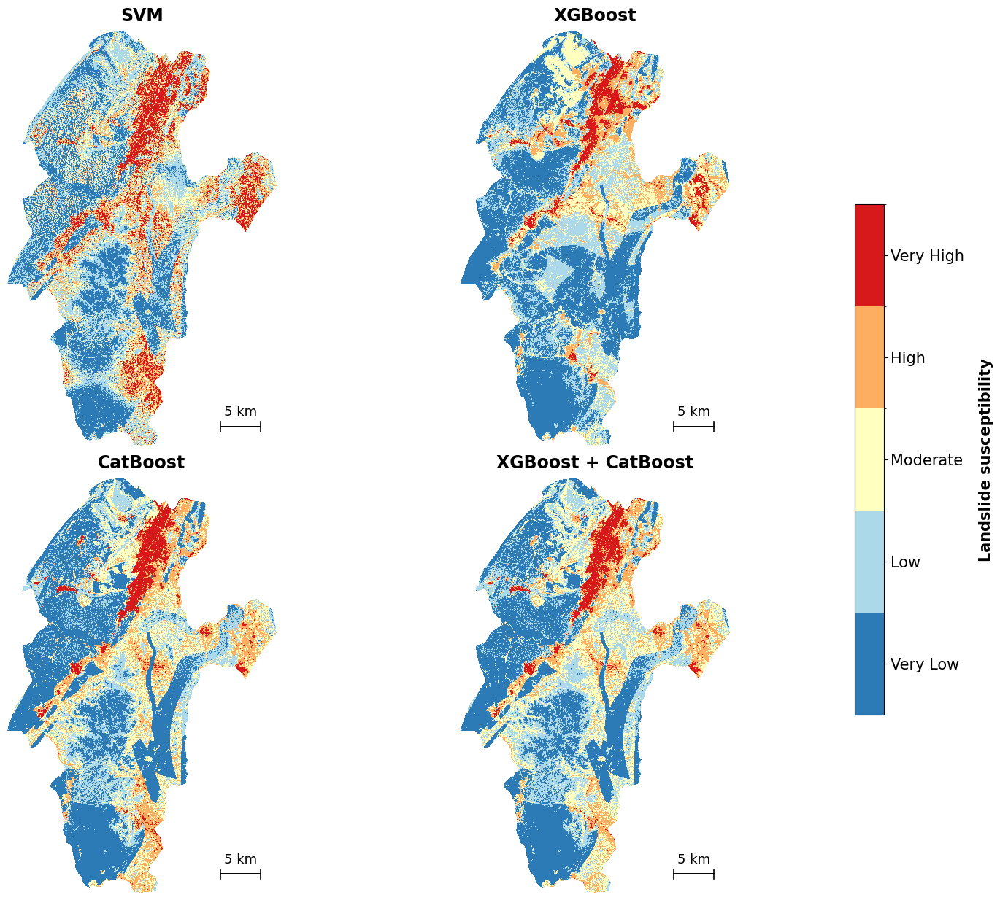

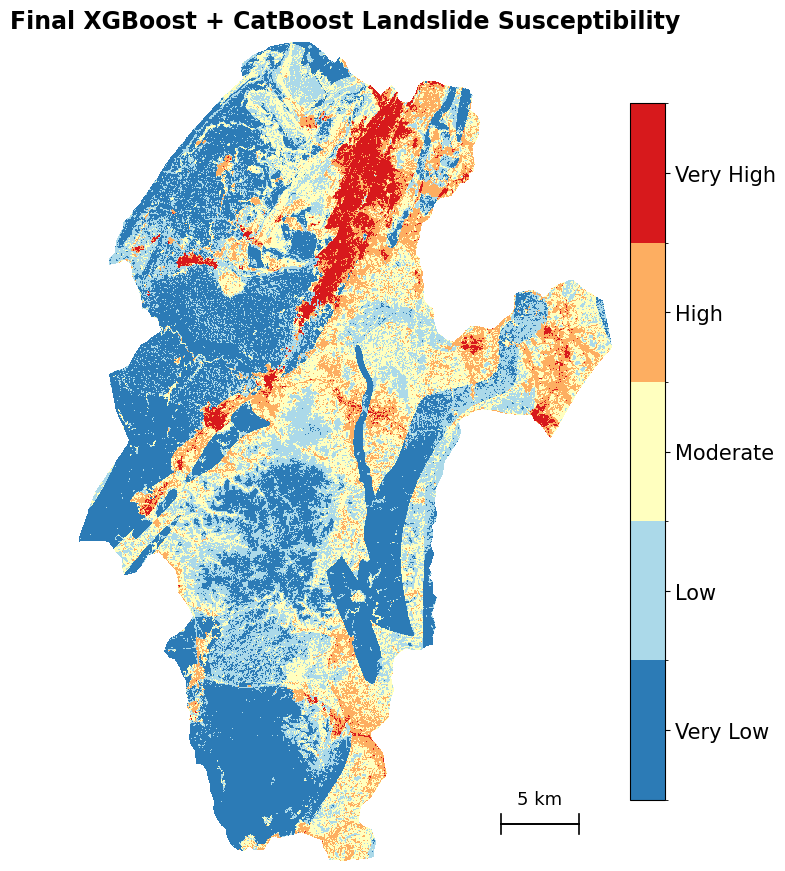

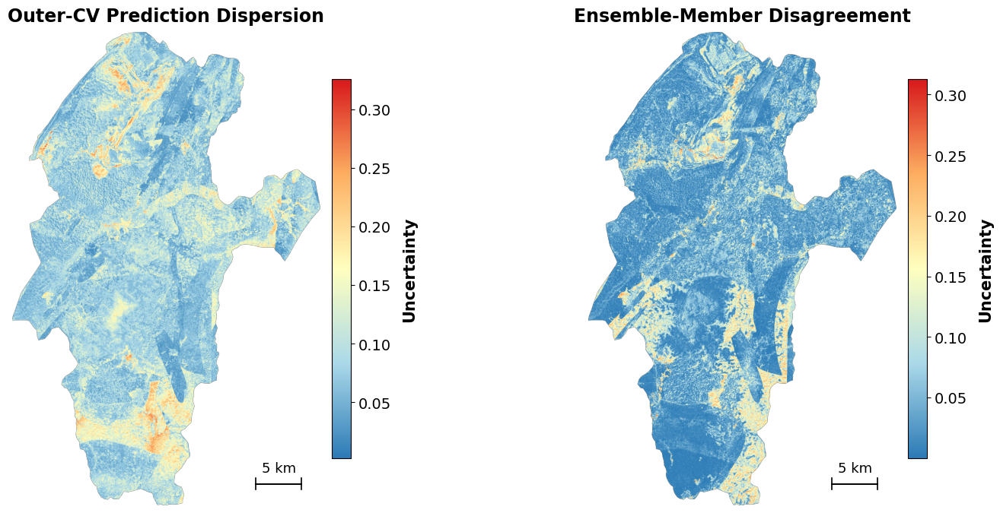

CELL 23 COMPLETE
Selected ensemble:
   XGBoost + CatBoost

Four-map legend dimensions:
  Width  : 0.40 inches
  Height : 7.00 inches

Four-map legend position:
  Dedicated external right-hand space

Susceptibility color ramp:
  Very Low   -> #2c7bb6
  Low        -> #abd9e9
  Moderate   -> #ffffbf
  High       -> #fdae61
  Very High  -> #d7191c

Four-map titles:
  SVM
  XGBoost
  CatBoost
   XGBoost + CatBoost

Saved figures:
   /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/15_Figures/SVM_XGBoost_CatBoost_SelectedEnsemble_Susceptibility_Maps.png
   /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/15_Figures/Final_Ensemble_Fixed_Susceptibility_Classes.png
   /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/15_Figures/Two_Final_Uncertainty_Maps.png


,Map,Class_Code,Class,Pixels,Area_ha,Percent
0,SVM,1,Very Low,268075,24126.75,26.562303
1,SVM,2,Low,303018,27271.62,30.024643
2,SVM,3,Moderate,197403,17766.27,19.559744
3,SVM,4,High,141679,12751.11,14.038312
4,SVM,5,Very High,99056,8915.04,9.814998
5,XGBoost,1,Very Low,394418,35497.62,39.081043
6,XGBoost,2,Low,271892,24470.28,26.940512
7,XGBoost,3,Moderate,183548,16519.32,18.186917
8,XGBoost,4,High,112239,10101.51,11.121240
9,XGBoost,5,Very High,47134,4242.06,4.670289


In [27]:
# =============================================================================
# CELL 23 - FIXED FIVE-CLASS SUSCEPTIBILITY RASTERS AND PUBLICATION MAPS
# =============================================================================
#
# Fixed equal probability intervals:
#
#   0.0 <= p < 0.2   Very Low
#   0.2 <= p < 0.4   Low
#   0.4 <= p < 0.6   Moderate
#   0.6 <= p < 0.8   High
#   0.8 <= p <= 1.0  Very High
#
# The same susceptibility color ramp is used throughout.
#
# IMPORTANT CARTOGRAPHIC LOCK
# -----------------------------------------------------------------------------
# The shared legend for the four-map figure is assigned an explicit physical
# width and height so that it has approximately the same size and form as the
# legend on the final selected-ensemble map.
#
# It is also placed completely outside the four mapping panels.
# =============================================================================


# =============================================================================
# 23.0 IMPORTS
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

from pathlib import Path

from matplotlib.colors import (
    ListedColormap,
    BoundaryNorm,
    LinearSegmentedColormap,
    Normalize,
)


# =============================================================================
# 23.1 PUBLICATION COLOR LOCK
# =============================================================================

SUSCEPTIBILITY_COLORS = [
    "#2c7bb6",   # Very Low
    "#abd9e9",   # Low
    "#ffffbf",   # Moderate
    "#fdae61",   # High
    "#d7191c",   # Very High
]


SUSCEPTIBILITY_LABELS = [
    "Very Low",
    "Low",
    "Moderate",
    "High",
    "Very High",
]


SUSCEPTIBILITY_CMAP = ListedColormap(
    SUSCEPTIBILITY_COLORS,
    name="TNMA_Susceptibility_5Class",
)


PROBABILITY_BOUNDARIES = [
    0.0,
    0.2,
    0.4,
    0.6,
    0.8,
    1.0,
]


PROBABILITY_NORM = BoundaryNorm(
    PROBABILITY_BOUNDARIES,
    SUSCEPTIBILITY_CMAP.N,
    clip=True,
)


PROBABILITY_CLASS_TICKS = [
    0.1,
    0.3,
    0.5,
    0.7,
    0.9,
]


UNCERTAINTY_CMAP = LinearSegmentedColormap.from_list(
    "TNMA_Uncertainty_Ramp",
    SUSCEPTIBILITY_COLORS,
    N=256,
)


# =============================================================================
# 23.2 MAP FONT LOCKS
# =============================================================================

MAP_TITLE_FS = 17
MAP_LABEL_FS = 15
MAP_TICK_FS = 14
MAP_CLASS_FS = 15
MAP_SCALE_FS = 14


# =============================================================================
# 23.3 RESOLVE ACTUAL SELECTED ENSEMBLE MEMBERS
# =============================================================================

if "SELECTED_MEMBERS" not in globals():

    raise RuntimeError(
        "SELECTED_MEMBERS is unavailable. "
        "Run the ensemble-selection cell before Cell 23."
    )


if not isinstance(
    SELECTED_MEMBERS,
    (
        list,
        tuple,
    ),
):

    raise RuntimeError(
        "SELECTED_MEMBERS must be a list or tuple."
    )


if len(
    SELECTED_MEMBERS
) not in {
    2,
    3,
}:

    raise RuntimeError(
        "Selected ensemble must contain two or three models.\n"
        f"Found: {SELECTED_MEMBERS}"
    )


allowed_models = {
    "SVM",
    "XGBoost",
    "CatBoost",
}


if not set(
    SELECTED_MEMBERS
).issubset(
    allowed_models
):

    raise RuntimeError(
        "Unexpected ensemble member detected:\n"
        f"{SELECTED_MEMBERS}"
    )


ENSEMBLE_MEMBER_TITLE = " + ".join(
    SELECTED_MEMBERS
)


MODEL_DISPLAY_NAMES = {

    "SVM":
        "SVM",

    "XGBoost":
        "XGBoost",

    "CatBoost":
        "CatBoost",

    "Ensemble":
        ENSEMBLE_MEMBER_TITLE,
}


# =============================================================================
# 23.4 CREATE FIXED FIVE-CLASS SUSCEPTIBILITY RASTERS
# =============================================================================

CLASS_PATHS = {}


for name, probability_path in FINAL_PROBABILITY_PATHS.items():

    with rasterio.open(
        probability_path
    ) as src:

        probability = src.read(
            1
        ).astype(
            "float64"
        )

        nodata = src.nodata


    valid_mask = MASTER_MASK.copy()


    if nodata is not None:

        valid_mask &= (
            ~np.isclose(
                probability,
                nodata,
                atol=1e-6,
            )
        )


    valid_mask &= np.isfinite(
        probability
    )


    valid_probability = probability[
        valid_mask
    ]


    if len(
        valid_probability
    ) == 0:

        raise RuntimeError(
            f"No valid susceptibility probabilities found for {name}."
        )


    if (
        np.nanmin(
            valid_probability
        )
        <
        -1e-6
        or
        np.nanmax(
            valid_probability
        )
        >
        1.0
        +
        1e-6
    ):

        raise RuntimeError(
            f"{name} probability raster contains values outside [0, 1]."
        )


    valid_probability = np.clip(
        valid_probability,
        0.0,
        1.0,
    )


    classes = np.zeros(
        (
            MASTER_HEIGHT,
            MASTER_WIDTH,
        ),
        dtype="uint8",
    )


    class_values = (
        np.digitize(
            valid_probability,
            SUSCEPTIBILITY_BREAKS[
                1:-1
            ],
            right=False,
        )
        +
        1
    )


    class_values = np.clip(
        class_values,
        1,
        5,
    ).astype(
        "uint8"
    )


    classes[
        valid_mask
    ] = class_values


    output_path = (
        NB2_DIRS[
            "classes"
        ]
        /
        f"{name}_Fixed_EqualInterval_Susceptibility_Class.tif"
    )


    write_uint8_raster_atomic(
        output_path,
        classes,
    )


    CLASS_PATHS[
        name
    ] = output_path


# =============================================================================
# 23.5 SUSCEPTIBILITY CLASS AREA STATISTICS
# =============================================================================

area_rows = []


for name, class_path in CLASS_PATHS.items():

    with rasterio.open(
        class_path
    ) as src:

        arr = src.read(
            1
        )


    for code_value, label in SUSCEPTIBILITY_NAMES.items():

        pixel_count = int(
            (
                arr[
                    MASTER_MASK
                ]
                ==
                code_value
            ).sum()
        )


        area_rows.append(
            {
                "Map":
                    name,

                "Class_Code":
                    code_value,

                "Class":
                    label,

                "Pixels":
                    pixel_count,

                "Area_ha":
                    (
                        pixel_count
                        *
                        TARGET_RES
                        *
                        TARGET_RES
                        /
                        10000.0
                    ),

                "Percent":
                    (
                        100.0
                        *
                        pixel_count
                        /
                        TNMA_PIXEL_COUNT
                    ),
            }
        )


class_area_df = pd.DataFrame(
    area_rows
)


atomic_csv(
    class_area_df,
    NB2_DIRS[
        "tables"
    ]
    /
    "Fixed_Susceptibility_Class_Areas.csv",
)


# =============================================================================
# 23.6 FOUR-MAP SUSCEPTIBILITY FIGURE
# =============================================================================

plot_order = [
    "SVM",
    "XGBoost",
    "CatBoost",
    "Ensemble",
]


for required_name in plot_order:

    if required_name not in FINAL_PROBABILITY_PATHS:

        raise RuntimeError(
            f"Missing final probability raster for {required_name}."
        )


# -----------------------------------------------------------------------------
# IMPORTANT
#
# The figure itself contains ONLY the four map panels.
#
# The colorbar is added later through fig.add_axes() with fixed physical
# dimensions so it cannot stretch across the full height of the two rows.
# -----------------------------------------------------------------------------

FOUR_MAP_FIG_WIDTH_IN = 15.5

FOUR_MAP_FIG_HEIGHT_IN = 12.5


fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        FOUR_MAP_FIG_WIDTH_IN,
        FOUR_MAP_FIG_HEIGHT_IN,
    ),
)


axes = axes.ravel()


last_image = None


for ax, name in zip(
    axes,
    plot_order,
):

    with rasterio.open(
        FINAL_PROBABILITY_PATHS[
            name
        ]
    ) as src:

        arr = src.read(
            1
        ).astype(
            "float64"
        )

        nodata = src.nodata

        bounds = src.bounds


    if nodata is not None:

        arr[
            np.isclose(
                arr,
                nodata,
                atol=1e-6,
            )
        ] = np.nan


    arr[
        ~MASTER_MASK
    ] = np.nan


    arr = np.clip(
        arr,
        0.0,
        1.0,
    )


    last_image = ax.imshow(
        arr,
        extent=[
            bounds.left,
            bounds.right,
            bounds.bottom,
            bounds.top,
        ],
        origin="upper",
        cmap=SUSCEPTIBILITY_CMAP,
        norm=PROBABILITY_NORM,
        interpolation="nearest",
    )


    ax.set_title(
        MODEL_DISPLAY_NAMES[
            name
        ],
        fontsize=MAP_TITLE_FS,
        fontweight="bold",
        pad=10,
    )


    clean_map_axes(
        ax
    )


    draw_scale_bar(
        ax,
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top,
        length_m=5000,
        label="5 km",
    )


# =============================================================================
# 23.7 RESERVE RIGHT-HAND WHITE SPACE FOR LEGEND
# =============================================================================
#
# Maps occupy only the left 80% of the figure.
#
# The remaining space is intentionally reserved for the susceptibility
# colorbar and labels.
# =============================================================================

fig.subplots_adjust(
    left=0.025,
    right=0.80,
    bottom=0.025,
    top=0.97,
    wspace=0.07,
    hspace=0.08,
)


# =============================================================================
# 23.8 FOUR-MAP LEGEND WITH FINAL-MAP SIZE AND FORM
# =============================================================================
#
# This is the important correction.
#
# Instead of:
#
#     colorbar spanning both rows
#
# we define the legend using explicit PHYSICAL dimensions.
#
# Approximate dimensions selected to reproduce the final-map legend:
#
#     width  = 0.40 inches
#     height = 7.00 inches
#
# Because add_axes() requires figure fractions, the inch values are converted
# using the known figure dimensions.
#
# This makes the shared four-map legend visually comparable to the legend of
# the individual final susceptibility map.
# =============================================================================

CBAR_WIDTH_IN = 0.40

CBAR_HEIGHT_IN = 7.00


# Horizontal position in physical inches.
CBAR_LEFT_IN = 13.05


# Center vertically.
CBAR_BOTTOM_IN = (
    FOUR_MAP_FIG_HEIGHT_IN
    -
    CBAR_HEIGHT_IN
) / 2.0


# Convert physical dimensions to normalized figure coordinates.
CBAR_LEFT = (
    CBAR_LEFT_IN
    /
    FOUR_MAP_FIG_WIDTH_IN
)


CBAR_BOTTOM = (
    CBAR_BOTTOM_IN
    /
    FOUR_MAP_FIG_HEIGHT_IN
)


CBAR_WIDTH = (
    CBAR_WIDTH_IN
    /
    FOUR_MAP_FIG_WIDTH_IN
)


CBAR_HEIGHT = (
    CBAR_HEIGHT_IN
    /
    FOUR_MAP_FIG_HEIGHT_IN
)


cbar_ax = fig.add_axes(
    [
        CBAR_LEFT,
        CBAR_BOTTOM,
        CBAR_WIDTH,
        CBAR_HEIGHT,
    ]
)


colorbar = fig.colorbar(
    last_image,
    cax=cbar_ax,
    boundaries=PROBABILITY_BOUNDARIES,
    ticks=PROBABILITY_CLASS_TICKS,
    spacing="proportional",
)


colorbar.ax.set_yticklabels(
    SUSCEPTIBILITY_LABELS,
    fontsize=MAP_CLASS_FS,
)


colorbar.ax.tick_params(
    labelsize=MAP_CLASS_FS,
)


colorbar.set_label(
    "Landslide susceptibility",
    fontsize=MAP_LABEL_FS,
    fontweight="bold",
    labelpad=14,
)


save_figure(
    fig,
    NB2_DIRS[
        "figures"
    ]
    /
    "SVM_XGBoost_CatBoost_SelectedEnsemble_Susceptibility_Maps.png",
)


# =============================================================================
# 23.9 FINAL SELECTED-ENSEMBLE FIXED-CLASS MAP
# =============================================================================

with rasterio.open(
    CLASS_PATHS[
        "Ensemble"
    ]
) as src:

    class_array = src.read(
        1
    )

    bounds = src.bounds


class_norm = BoundaryNorm(
    [
        0.5,
        1.5,
        2.5,
        3.5,
        4.5,
        5.5,
    ],
    SUSCEPTIBILITY_CMAP.N,
)


display_array = class_array.astype(
    "float64"
)


display_array[
    ~MASTER_MASK
] = np.nan


fig, ax = plt.subplots(
    figsize=(
        8.8,
        9.0,
    )
)


image = ax.imshow(
    display_array,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top,
    ],
    origin="upper",
    cmap=SUSCEPTIBILITY_CMAP,
    norm=class_norm,
    interpolation="nearest",
)


clean_map_axes(
    ax
)


draw_scale_bar(
    ax,
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top,
    length_m=5000,
    label="5 km",
)


ax.set_title(
    (
        f"Final {ENSEMBLE_MEMBER_TITLE} "
        "Landslide Susceptibility"
    ),
    fontsize=MAP_TITLE_FS,
    fontweight="bold",
    pad=10,
)


# =============================================================================
# 23.10 FINAL MAP LEGEND
# =============================================================================
#
# Retain the legend design that produced the figure you approved.
# =============================================================================

colorbar = fig.colorbar(
    image,
    ax=ax,
    ticks=[
        1,
        2,
        3,
        4,
        5,
    ],
    boundaries=[
        0.5,
        1.5,
        2.5,
        3.5,
        4.5,
        5.5,
    ],
    fraction=0.046,
    pad=0.025,
)


colorbar.ax.set_yticklabels(
    [
        SUSCEPTIBILITY_NAMES[
            code_value
        ]
        for code_value in range(
            1,
            6,
        )
    ],
    fontsize=MAP_CLASS_FS,
)


colorbar.ax.tick_params(
    labelsize=MAP_CLASS_FS,
)


fig.subplots_adjust(
    left=0.03,
    right=0.89,
    bottom=0.03,
    top=0.94,
)


save_figure(
    fig,
    NB2_DIRS[
        "figures"
    ]
    /
    "Final_Ensemble_Fixed_Susceptibility_Classes.png",
)


# =============================================================================
# 23.11 TWO FINAL UNCERTAINTY MAPS
# =============================================================================

uncertainty_specs = [
    (
        PREDICTION_DISPERSION_TIF,
        "Outer-CV Prediction Dispersion",
    ),
    (
        MEMBER_DISAGREEMENT_TIF,
        "Ensemble-Member Disagreement",
    ),
]


uncertainty_payloads = []


for path, title in uncertainty_specs:

    with rasterio.open(
        path
    ) as src:

        arr = src.read(
            1
        ).astype(
            "float64"
        )

        nodata = src.nodata

        bounds = src.bounds


    if nodata is not None:

        arr[
            np.isclose(
                arr,
                nodata,
                atol=1e-6,
            )
        ] = np.nan


    arr[
        ~MASTER_MASK
    ] = np.nan


    finite_values = arr[
        np.isfinite(
            arr
        )
    ]


    if len(
        finite_values
    ) == 0:

        raise RuntimeError(
            f"No valid uncertainty values found for {title}."
        )


    vmin = float(
        np.nanmin(
            finite_values
        )
    )


    vmax = float(
        np.nanmax(
            finite_values
        )
    )


    if np.isclose(
        vmin,
        vmax,
    ):

        vmax = (
            vmin
            +
            1e-12
        )


    uncertainty_payloads.append(
        {
            "Path":
                path,

            "Title":
                title,

            "Array":
                arr,

            "Bounds":
                bounds,

            "Vmin":
                vmin,

            "Vmax":
                vmax,
        }
    )


# =============================================================================
# 23.12 DRAW UNCERTAINTY FIGURE
# =============================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(
        14.5,
        7.0,
    ),
)


for ax, payload in zip(
    axes,
    uncertainty_payloads,
):

    uncertainty_norm = Normalize(
        vmin=payload[
            "Vmin"
        ],
        vmax=payload[
            "Vmax"
        ],
    )


    image = ax.imshow(
        payload[
            "Array"
        ],
        extent=[
            payload[
                "Bounds"
            ].left,

            payload[
                "Bounds"
            ].right,

            payload[
                "Bounds"
            ].bottom,

            payload[
                "Bounds"
            ].top,
        ],
        origin="upper",
        cmap=UNCERTAINTY_CMAP,
        norm=uncertainty_norm,
    )


    clean_map_axes(
        ax
    )


    draw_scale_bar(
        ax,
        payload[
            "Bounds"
        ].left,

        payload[
            "Bounds"
        ].right,

        payload[
            "Bounds"
        ].bottom,

        payload[
            "Bounds"
        ].top,

        length_m=5000,
        label="5 km",
    )


    ax.set_title(
        payload[
            "Title"
        ],
        fontsize=MAP_TITLE_FS,
        fontweight="bold",
        pad=10,
    )


    colorbar = fig.colorbar(
        image,
        ax=ax,
        shrink=0.80,
        pad=0.025,
    )


    colorbar.ax.tick_params(
        labelsize=MAP_TICK_FS,
    )


    colorbar.set_label(
        "Uncertainty",
        fontsize=MAP_LABEL_FS,
        fontweight="bold",
        labelpad=10,
    )


fig.subplots_adjust(
    left=0.035,
    right=0.985,
    bottom=0.04,
    top=0.93,
    wspace=0.22,
)


save_figure(
    fig,
    NB2_DIRS[
        "figures"
    ]
    /
    "Two_Final_Uncertainty_Maps.png",
)


# =============================================================================
# 23.13 FINAL QC
# =============================================================================

expected_models = {
    "SVM",
    "XGBoost",
    "CatBoost",
    "Ensemble",
}


if not expected_models.issubset(
    set(
        CLASS_PATHS.keys()
    )
):

    raise RuntimeError(
        "One or more required susceptibility class rasters "
        "were not created."
    )


for name in expected_models:

    if not Path(
        CLASS_PATHS[
            name
        ]
    ).exists():

        raise RuntimeError(
            f"Missing susceptibility class raster for {name}."
        )


# =============================================================================
# 23.14 REPORT
# =============================================================================

print(
    "=" * 110
)

print(
    "CELL 23 COMPLETE"
)

print(
    "=" * 110
)


print(
    "Selected ensemble:"
)

print(
    "  ",
    ENSEMBLE_MEMBER_TITLE
)


print()

print(
    "Four-map legend dimensions:"
)

print(
    f"  Width  : {CBAR_WIDTH_IN:.2f} inches"
)

print(
    f"  Height : {CBAR_HEIGHT_IN:.2f} inches"
)


print()

print(
    "Four-map legend position:"
)

print(
    "  Dedicated external right-hand space"
)


print()

print(
    "Susceptibility color ramp:"
)


for label, color in zip(
    SUSCEPTIBILITY_LABELS,
    SUSCEPTIBILITY_COLORS,
):

    print(
        f"  {label:<10} -> {color}"
    )


print()

print(
    "Four-map titles:"
)

print(
    "  SVM"
)

print(
    "  XGBoost"
)

print(
    "  CatBoost"
)

print(
    "  ",
    ENSEMBLE_MEMBER_TITLE
)


print()

print(
    "Saved figures:"
)

print(
    "  ",
    NB2_DIRS[
        "figures"
    ]
    /
    "SVM_XGBoost_CatBoost_SelectedEnsemble_Susceptibility_Maps.png"
)

print(
    "  ",
    NB2_DIRS[
        "figures"
    ]
    /
    "Final_Ensemble_Fixed_Susceptibility_Classes.png"
)

print(
    "  ",
    NB2_DIRS[
        "figures"
    ]
    /
    "Two_Final_Uncertainty_Maps.png"
)


print(
    "=" * 110
)


display(
    class_area_df
)

CELL 23A - PUBLICATION FIGURES FOR 10 CONTINUOUS LCFs AND 4 CATEGORICAL LCFs

In [28]:
# =============================================================================
# NEW CELL - PUBLICATION MAPS OF THE 14 RETAINED LCFs
# DRIVE-RESTORE / SELF-CONTAINED
# =============================================================================
#
# OUTPUT 1
# -----------------------------------------------------------------------------
# Ten continuous LCFs arranged as:
#
#       5 columns × 2 rows
#
#       Elevation     Slope       PC          TPI         TWI
#       SPI           Rainfall    NDVI        RD          FD
#
# Each map contains:
#
#   - LCF name only
#   - individual continuous colorbar
#   - 5 km scale bar
#
#
# OUTPUT 2
# -----------------------------------------------------------------------------
# Four non-standard-continuous LCFs arranged in exact reading order:
#
#       Aspect        Lithology
#       Soil Type     LULC
#
# Each map has its categorical legend directly beneath it.
#
# Aspect legend contains NAMES ONLY:
#
#       Flat
#       North
#       Northeast
#       East
#       Southeast
#       South
#       Southwest
#       West
#       Northwest
#
# No aspect degree ranges are displayed in the legend.
#
#
# IMPORTANT
# -----------------------------------------------------------------------------
# - No overall figure title is added.
# - All visible text is >= 16 pt.
# - No Notebook 1 plotting variables are required in RAM.
# - Required palettes are reproduced explicitly from the locked Notebook 1
#   categorical definitions.
# - Rasters are restored directly from Google Drive.
# - TNMA mask is derived from the valid Elevation raster footprint.
# - Every map receives a 5 km scale bar.
# =============================================================================


# =============================================================================
# 0. IMPORTS
# =============================================================================

from pathlib import Path
from collections import OrderedDict
import json

import numpy as np
import rasterio
import matplotlib.pyplot as plt

from matplotlib.colors import (
    ListedColormap,
    BoundaryNorm,
)

from matplotlib.patches import Patch
from mpl_toolkits.axes_grid1 import make_axes_locatable
from IPython.display import display, Image as IPyImage


# =============================================================================
# 1. GOOGLE DRIVE / PROJECT ROOT
# =============================================================================

DRIVE_MYDRIVE = Path(
    "/content/drive/MyDrive"
)


if not DRIVE_MYDRIVE.exists():

    try:
        from google.colab import drive

        drive.mount(
            "/content/drive"
        )

    except Exception as exc:

        raise RuntimeError(
            "Google Drive is not mounted and could not be mounted."
        ) from exc


PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TNMA LS STUDY"
)


if not PROJECT_ROOT.exists():

    raise FileNotFoundError(
        "TNMA project root was not found:\n"
        f"{PROJECT_ROOT}"
    )


CANDIDATE_DIR = (
    PROJECT_ROOT
    /
    "05_Predictor_Candidates_30m"
)


if not CANDIDATE_DIR.exists():

    raise FileNotFoundError(
        "Notebook 1 predictor directory was not found:\n"
        f"{CANDIDATE_DIR}"
    )


# =============================================================================
# 2. OUTPUT DIRECTORY
# =============================================================================
#
# If the current Notebook 2 figure folder can be found, use it.
# Otherwise create a dedicated publication-map folder safely under the project.
# =============================================================================

possible_figure_dirs = [
    PROJECT_ROOT / "07_Figures_Notebook02",
    PROJECT_ROOT / "07_Figures",
    PROJECT_ROOT / "Figures",
]


FIGURE_DIR = None


for candidate in possible_figure_dirs:

    if candidate.exists():

        FIGURE_DIR = candidate

        break


if FIGURE_DIR is None:

    FIGURE_DIR = (
        PROJECT_ROOT
        /
        "07_Figures_Notebook02"
    )

    FIGURE_DIR.mkdir(
        parents=True,
        exist_ok=True,
    )


CONTINUOUS_OUTPUT = (
    FIGURE_DIR
    /
    "TNMA_10_Continuous_LCFs.png"
)


CATEGORICAL_OUTPUT = (
    FIGURE_DIR
    /
    "TNMA_Aspect_Lithology_SoilType_LULC.png"
)


# =============================================================================
# 3. PUBLICATION FONT AND DPI LOCKS
# =============================================================================

FIG_DPI = 700

FONT_MAP_NAME = 18

FONT_COLORBAR_LABEL = 16

FONT_COLORBAR_TICK = 16

FONT_SCALE = 16

FONT_LEGEND = 16


# =============================================================================
# 4. LOCKED LCF ORDER
# =============================================================================

CONTINUOUS_LCFS = OrderedDict(
    [
        (
            "Elevation",
            "Elevation.tif",
        ),
        (
            "Slope",
            "Slope.tif",
        ),
        (
            "PC",
            "Curvature.tif",
        ),
        (
            "TPI",
            "TPI.tif",
        ),
        (
            "TWI",
            "TWI.tif",
        ),
        (
            "SPI",
            "SPI.tif",
        ),
        (
            "Rainfall",
            None,
        ),
        (
            "NDVI",
            "NDVI.tif",
        ),
        (
            "RD",
            "Road_Distance.tif",
        ),
        (
            "FD",
            "Fault_Distance.tif",
        ),
    ]
)


CATEGORICAL_LCFS = OrderedDict(
    [
        (
            "Aspect",
            "Aspect.tif",
        ),
        (
            "Lithology",
            "Lithology.tif",
        ),
        (
            "Soil Type",
            "Soil_Type.tif",
        ),
        (
            "LULC",
            "LULC.tif",
        ),
    ]
)


# =============================================================================
# 5. RESOLVE RAINFALL WINNER
# =============================================================================
#
# Current study-wide winner is Rx5day.
#
# The resolver nevertheless checks for available rainfall-selection metadata
# before falling back to the known current winner.
# =============================================================================

RAINFALL_CANDIDATES = {
    "MAP":
        CANDIDATE_DIR
        /
        "Rainfall_MAP_2016_2025.tif",

    "Rx1day":
        CANDIDATE_DIR
        /
        "Rainfall_Rx1day_2016_2025.tif",

    "Rx5day":
        CANDIDATE_DIR
        /
        "Rainfall_Rx5day_2016_2025.tif",
}


def search_selected_rainfall_from_json():

    json_candidates = list(
        PROJECT_ROOT.glob(
            "**/*Rainfall*.json"
        )
    )


    keys_of_interest = {
        "selected_rainfall",
        "selected rainfall",
        "selected",
        "winner",
        "rainfall_winner",
        "selectedrainfall",
    }


    for json_path in sorted(
        json_candidates,
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    ):

        try:

            payload = json.loads(
                json_path.read_text(
                    encoding="utf-8"
                )
            )

        except Exception:

            continue


        def search_object(obj):

            if isinstance(
                obj,
                dict,
            ):

                for key, value in obj.items():

                    normalized_key = str(
                        key
                    ).lower().strip()


                    if normalized_key in keys_of_interest:

                        text = str(
                            value
                        )


                        for rainfall_name in [
                            "Rx5day",
                            "Rx1day",
                            "MAP",
                        ]:

                            if rainfall_name.lower() in text.lower():

                                return rainfall_name


                    result = search_object(
                        value
                    )


                    if result is not None:

                        return result


            elif isinstance(
                obj,
                list,
            ):

                for item in obj:

                    result = search_object(
                        item
                    )


                    if result is not None:

                        return result


            return None


        result = search_object(
            payload
        )


        if result is not None:

            return result


    return None


SELECTED_RAINFALL_LOCAL = (
    search_selected_rainfall_from_json()
)


if SELECTED_RAINFALL_LOCAL is None:

    # Current locked study-wide winner.
    SELECTED_RAINFALL_LOCAL = (
        "Rx5day"
    )


RAINFALL_PATH = RAINFALL_CANDIDATES[
    SELECTED_RAINFALL_LOCAL
]


if not RAINFALL_PATH.exists():

    raise FileNotFoundError(
        "Selected rainfall raster was not found:\n"
        f"{RAINFALL_PATH}"
    )


print(
    "Rainfall displayed:",
    SELECTED_RAINFALL_LOCAL,
)

print(
    "Rainfall raster:",
    RAINFALL_PATH,
)


# =============================================================================
# 6. RESOLVE ALL RASTER PATHS
# =============================================================================

continuous_paths = OrderedDict()


for display_name, filename in CONTINUOUS_LCFS.items():

    if display_name == "Rainfall":

        path = RAINFALL_PATH

    else:

        path = (
            CANDIDATE_DIR
            /
            filename
        )


    if not path.exists():

        raise FileNotFoundError(
            f"Missing raster for {display_name}:\n"
            f"{path}"
        )


    continuous_paths[
        display_name
    ] = path


categorical_paths = OrderedDict()


for display_name, filename in CATEGORICAL_LCFS.items():

    path = (
        CANDIDATE_DIR
        /
        filename
    )


    if not path.exists():

        raise FileNotFoundError(
            f"Missing raster for {display_name}:\n"
            f"{path}"
        )


    categorical_paths[
        display_name
    ] = path


# =============================================================================
# 7. RASTER READER
# =============================================================================

def read_raster(
    raster_path,
):

    with rasterio.open(
        raster_path
    ) as src:

        array = src.read(
            1
        ).astype(
            "float64"
        )

        bounds = src.bounds

        transform = src.transform

        crs = src.crs

        nodata = src.nodata


    if nodata is not None:

        array[
            np.isclose(
                array,
                nodata,
                atol=1e-9,
            )
        ] = np.nan


    array[
        ~np.isfinite(
            array
        )
    ] = np.nan


    return {
        "array":
            array,

        "bounds":
            bounds,

        "transform":
            transform,

        "crs":
            crs,

        "path":
            Path(
                raster_path
            ),
    }


# =============================================================================
# 8. MASTER TNMA MASK FROM ELEVATION
# =============================================================================

elevation_info = read_raster(
    continuous_paths[
        "Elevation"
    ]
)


MASTER_MASK_LOCAL = np.isfinite(
    elevation_info[
        "array"
    ]
)


MASTER_SHAPE_LOCAL = elevation_info[
    "array"
].shape


MASTER_BOUNDS_LOCAL = elevation_info[
    "bounds"
]


MASTER_CRS_LOCAL = elevation_info[
    "crs"
]


if MASTER_CRS_LOCAL is None:

    raise RuntimeError(
        "Elevation raster has no CRS."
    )


if not MASTER_CRS_LOCAL.is_projected:

    raise RuntimeError(
        "The map CRS is not projected. "
        "A 5 km metric scale bar would therefore be invalid."
    )


# =============================================================================
# 9. APPLY MASTER TNMA MASK
# =============================================================================

def mask_to_tnma(
    raster_info,
):

    array = raster_info[
        "array"
    ].copy()


    if array.shape != MASTER_SHAPE_LOCAL:

        raise RuntimeError(
            "Raster grid shape differs from Elevation master grid:\n"
            f"{raster_info['path']}\n"
            f"Expected: {MASTER_SHAPE_LOCAL}\n"
            f"Found   : {array.shape}"
        )


    array[
        ~MASTER_MASK_LOCAL
    ] = np.nan


    raster_info = dict(
        raster_info
    )


    raster_info[
        "array"
    ] = array


    return raster_info


# =============================================================================
# 10. MAP AXIS CLEANING
# =============================================================================

def clean_map_axis(
    ax,
):

    ax.set_xticks(
        []
    )

    ax.set_yticks(
        []
    )


    for spine in ax.spines.values():

        spine.set_visible(
            False
        )


# =============================================================================
# 11. 5 km SCALE BAR
# =============================================================================
#
# Single horizontal line with vertical end ticks and a center tick.
# =============================================================================

def add_5km_scale_bar(
    ax,
    bounds,
):

    xmin = float(
        bounds.left
    )

    xmax = float(
        bounds.right
    )

    ymin = float(
        bounds.bottom
    )

    ymax = float(
        bounds.top
    )


    width = (
        xmax
        -
        xmin
    )


    height = (
        ymax
        -
        ymin
    )


    bar_length = 5000.0


    x1 = (
        xmax
        -
        0.075
        *
        width
    )


    x0 = (
        x1
        -
        bar_length
    )


    y = (
        ymin
        +
        0.065
        *
        height
    )


    tick_height = (
        0.018
        *
        height
    )


    midpoint = (
        x0
        +
        x1
    ) / 2.0


    ax.plot(
        [
            x0,
            x1,
        ],
        [
            y,
            y,
        ],
        color="black",
        linewidth=1.6,
        zorder=20,
    )


    for x_tick in [
        x0,
        x1,
    ]:

        ax.plot(
            [
                x_tick,
                x_tick,
            ],
            [
                y
                -
                tick_height,

                y
                +
                tick_height,
            ],
            color="black",
            linewidth=1.6,
            zorder=20,
        )


    ax.text(
        midpoint,
        y
        +
        1.7
        *
        tick_height,
        "5 km",
        fontsize=FONT_SCALE,
        ha="center",
        va="bottom",
        color="black",
        zorder=21,
    )


# =============================================================================
# 12. NOTEBOOK 1 LITHOLOGY CLASS NAMES
# =============================================================================

LITH_BY_CODE = {
    1:
        "Argillite, siltstone, tuff (Phyllite Fm)",

    2:
        "Argillitic sediment",

    3:
        "Manganese Fm",

    4:
        "Basaltic subvolcanic rock",

    5:
        "Conglomerate (Kawere Fm)",

    6:
        "Conglomerate, quartzose sandstone (Banket Fm)",

    7:
        "Dacitic to rhyolitic subvolcanic rock",

    8:
        "Detrital sediment",

    9:
        "Dolerite, gabbro, diorite",

    10:
        "Hornblende-biotite granitoid",

    11:
        "Hornblende-biotite granitic",

    12:
        "Hornblende-biotite granitoid",

    13:
        "Hornblende-biotite granodiorite",

    14:
        "Hornblende-biotite tonalite",

    15:
        "Mafic dyke, dolerite",

    16:
        "Peridotite, pyroxenite, dunite",

    17:
        "Sandstone (Huni Fm)",
}


# =============================================================================
# 13. NOTEBOOK 1 LITHOLOGY COLORS
# =============================================================================

LITH_COL = {
    "Peridotite, pyroxenite, dunite":
        "#6501DF",

    "Argillite, siltstone, tuff (Phyllite Fm)":
        "#76E4FA",

    "Conglomerate, quartzose sandstone (Banket Fm)":
        "#A5FEFE",

    "Sandstone (Huni Fm)":
        "#CCFFFF",

    "Hornblende-biotite granodiorite":
        "#F0678A",

    "Conglomerate (Kawere Fm)":
        "#59CBFB",

    "Hornblende-biotite tonalite":
        "#F27FBD",

    "Argillitic sediment":
        "#F4E5C3",

    "Hornblende-biotite granitoid":
        "#FB4D4D",

    "Dacitic to rhyolitic subvolcanic rock":
        "#8DFC67",

    "Hornblende-biotite granitic":
        "#FC9898",

    "Dolerite, gabbro, diorite":
        "#6698D7",

    "Basaltic subvolcanic rock":
        "#41FD43",

    "Manganese Fm":
        "#0265F9",

    "Detrital sediment":
        "#81FEFC",

    "Mafic dyke, dolerite":
        "#50FBB2",
}


# =============================================================================
# 14. NOTEBOOK 1 SOIL TYPE CLASSES AND COLORS
# =============================================================================

SOIL_BY_CODE = {
    1:
        "Acrisols",

    2:
        "Ferralsols",

    3:
        "Fluvisols",
}


SOIL_COL = {
    "Acrisols":
        "#D8B45A",

    "Ferralsols":
        "#B85C3F",

    "Fluvisols":
        "#9B8A6E",
}


# =============================================================================
# 15. NOTEBOOK 1 ESRI LULC CLASSES AND COLORS
# =============================================================================

LULC_BY_CODE = {
    1:
        "Water",

    2:
        "Trees",

    4:
        "Flooded Vegetation",

    5:
        "Crops",

    7:
        "Built Area",

    8:
        "Bare Ground",

    9:
        "Snow/Ice",

    10:
        "Clouds",

    11:
        "Rangeland",
}


LULC_COL = {
    "Water":
        "#419BDF",

    "Trees":
        "#397D49",

    "Flooded Vegetation":
        "#7A87C6",

    "Crops":
        "#E49635",

    "Built Area":
        "#C4281B",

    "Bare Ground":
        "#A59B8F",

    "Snow/Ice":
        "#A8EBFF",

    "Clouds":
        "#616161",

    "Rangeland":
        "#E3E2C3",
}


# =============================================================================
# 16. APPROVED ASPECT CLASSES AND COLORS
# =============================================================================

ASPECT_CLASSES = OrderedDict(
    [
        (
            0,
            {
                "name":
                    "Flat",

                "color":
                    "#B0B0B0",
            },
        ),

        (
            1,
            {
                "name":
                    "North",

                "color":
                    "#FE0000",
            },
        ),

        (
            2,
            {
                "name":
                    "Northeast",

                "color":
                    "#FFA600",
            },
        ),

        (
            3,
            {
                "name":
                    "East",

                "color":
                    "#FFFF01",
            },
        ),

        (
            4,
            {
                "name":
                    "Southeast",

                "color":
                    "#00FF01",
            },
        ),

        (
            5,
            {
                "name":
                    "South",

                "color":
                    "#01FFFF",
            },
        ),

        (
            6,
            {
                "name":
                    "Southwest",

                "color":
                    "#01A6FF",
            },
        ),

        (
            7,
            {
                "name":
                    "West",

                "color":
                    "#0000FE",
            },
        ),

        (
            8,
            {
                "name":
                    "Northwest",

                "color":
                    "#FF00FE",
            },
        ),
    ]
)


# =============================================================================
# 17. CLASSIFY RAW ASPECT
# =============================================================================
#
# Raw aspect:
#
#   -1         Flat
#   0-22.5     North
#   22.5-67.5  Northeast
#   67.5-112.5 East
#   ...
#   337.5-360  North
#
# North appears ONCE in the legend.
# =============================================================================

def classify_aspect(
    aspect,
):

    output = np.full(
        aspect.shape,
        np.nan,
        dtype="float64",
    )


    finite = np.isfinite(
        aspect
    )


    flat = (
        finite
        &
        np.isclose(
            aspect,
            -1.0,
            atol=1e-9,
        )
    )


    output[
        flat
    ] = 0


    directional = (
        finite
        &
        ~flat
    )


    north = (
        directional
        &
        (
            (
                aspect
                >=
                0.0
            )
            &
            (
                aspect
                <
                22.5
            )
            |
            (
                aspect
                >=
                337.5
            )
            &
            (
                aspect
                <=
                360.0
            )
        )
    )


    output[
        north
    ] = 1


    output[
        directional
        &
        (
            aspect
            >=
            22.5
        )
        &
        (
            aspect
            <
            67.5
        )
    ] = 2


    output[
        directional
        &
        (
            aspect
            >=
            67.5
        )
        &
        (
            aspect
            <
            112.5
        )
    ] = 3


    output[
        directional
        &
        (
            aspect
            >=
            112.5
        )
        &
        (
            aspect
            <
            157.5
        )
    ] = 4


    output[
        directional
        &
        (
            aspect
            >=
            157.5
        )
        &
        (
            aspect
            <
            202.5
        )
    ] = 5


    output[
        directional
        &
        (
            aspect
            >=
            202.5
        )
        &
        (
            aspect
            <
            247.5
        )
    ] = 6


    output[
        directional
        &
        (
            aspect
            >=
            247.5
        )
        &
        (
            aspect
            <
            292.5
        )
    ] = 7


    output[
        directional
        &
        (
            aspect
            >=
            292.5
        )
        &
        (
            aspect
            <
            337.5
        )
    ] = 8


    return output


# =============================================================================
# 18. DISCRETE RASTER PREPARATION
# =============================================================================

def prepare_discrete_layer(
    raw_array,
    code_to_name,
    name_to_color,
):

    finite_values = raw_array[
        np.isfinite(
            raw_array
        )
    ]


    observed_codes = sorted(
        {
            int(
                round(
                    value
                )
            )
            for value
            in finite_values
        }
    )


    valid_codes = [
        code
        for code
        in observed_codes
        if code in code_to_name
    ]


    if len(
        valid_codes
    ) == 0:

        raise RuntimeError(
            "No recognized categorical classes were found."
        )


    display_array = np.full(
        raw_array.shape,
        np.nan,
        dtype="float64",
    )


    colors = []

    legend_entries = OrderedDict()


    for display_index, code in enumerate(
        valid_codes
    ):

        class_name = code_to_name[
            code
        ]


        color = name_to_color[
            class_name
        ]


        display_array[
            np.isclose(
                raw_array,
                code,
                atol=1e-6,
            )
        ] = display_index


        colors.append(
            color
        )


        # -------------------------------------------------------------
        # Deduplicate repeated lithology class names.
        # -------------------------------------------------------------

        if class_name not in legend_entries:

            legend_entries[
                class_name
            ] = color


    cmap = ListedColormap(
        colors
    )


    norm = BoundaryNorm(
        np.arange(
            len(
                valid_codes
            )
            +
            1
        )
        -
        0.5,
        cmap.N,
    )


    return (
        display_array,
        cmap,
        norm,
        legend_entries,
    )


# =============================================================================
# 19. ASPECT DISPLAY PREPARATION
# =============================================================================

def prepare_aspect_layer(
    raw_aspect,
):

    classified = classify_aspect(
        raw_aspect
    )


    display_array = classified.copy()


    colors = [
        ASPECT_CLASSES[
            code
        ][
            "color"
        ]
        for code
        in ASPECT_CLASSES
    ]


    cmap = ListedColormap(
        colors
    )


    norm = BoundaryNorm(
        np.arange(
            len(
                colors
            )
            +
            1
        )
        -
        0.5,
        len(
            colors
        ),
    )


    legend_entries = OrderedDict(
        (
            ASPECT_CLASSES[
                code
            ][
                "name"
            ],

            ASPECT_CLASSES[
                code
            ][
                "color"
            ],
        )
        for code
        in ASPECT_CLASSES
    )


    return (
        display_array,
        cmap,
        norm,
        legend_entries,
    )


# =============================================================================
# 20. LEGEND DRAWER
# =============================================================================

def draw_category_legend(
    ax,
    legend_entries,
    ncol=1,
):

    ax.axis(
        "off"
    )


    handles = [
        Patch(
            facecolor=color,
            edgecolor="black",
            linewidth=0.6,
            label=label,
        )
        for label, color
        in legend_entries.items()
    ]


    ax.legend(
        handles=handles,
        loc="upper center",
        bbox_to_anchor=(
            0.5,
            1.0,
        ),
        ncol=ncol,
        frameon=False,
        fontsize=FONT_LEGEND,
        handlelength=1.25,
        handleheight=1.0,
        columnspacing=1.0,
        labelspacing=0.50,
        borderaxespad=0.0,
    )


# =============================================================================
# 21. CONTINUOUS MAP DATA
# =============================================================================

continuous_data = OrderedDict()


for display_name, raster_path in continuous_paths.items():

    raster_info = mask_to_tnma(
        read_raster(
            raster_path
        )
    )


    finite = raster_info[
        "array"
    ][
        np.isfinite(
            raster_info[
                "array"
            ]
        )
    ]


    if len(
        finite
    ) == 0:

        raise RuntimeError(
            f"No finite TNMA pixels found for {display_name}."
        )


    continuous_data[
        display_name
    ] = raster_info


# =============================================================================
# 22. FIGURE 1 - TEN CONTINUOUS LCFs
# =============================================================================
#
# 5 columns × 2 rows exactly as requested.
#
# Each subplot has its own colorbar to avoid ambiguous value scales.
# =============================================================================

fig1, axes1 = plt.subplots(
    2,
    5,
    figsize=(
        22.0,
        10.8,
    ),
)


axes1 = axes1.ravel()


for ax, (
    display_name,
    raster_info,
) in zip(
    axes1,
    continuous_data.items(),
):

    array = raster_info[
        "array"
    ]


    bounds = raster_info[
        "bounds"
    ]


    finite = array[
        np.isfinite(
            array
        )
    ]


    vmin = float(
        np.min(
            finite
        )
    )


    vmax = float(
        np.max(
            finite
        )
    )


    image = ax.imshow(
        array,
        extent=[
            bounds.left,
            bounds.right,
            bounds.bottom,
            bounds.top,
        ],
        origin="upper",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest",
    )


    clean_map_axis(
        ax
    )


    ax.set_title(
        display_name,
        fontsize=FONT_MAP_NAME,
        fontweight="bold",
        pad=8,
    )


    add_5km_scale_bar(
        ax,
        bounds,
    )


    # -------------------------------------------------------------------------
    # Dedicated colorbar appended to this exact map.
    # -------------------------------------------------------------------------

    divider = make_axes_locatable(
        ax
    )


    cax = divider.append_axes(
        "right",
        size="4.2%",
        pad=0.045,
    )


    colorbar = fig1.colorbar(
        image,
        cax=cax,
    )


    colorbar.ax.tick_params(
        labelsize=FONT_COLORBAR_TICK,
    )


# =============================================================================
# 23. CONTINUOUS FIGURE SPACING
# =============================================================================

fig1.subplots_adjust(
    left=0.018,
    right=0.985,
    bottom=0.045,
    top=0.955,
    wspace=0.31,
    hspace=0.17,
)


# =============================================================================
# 24. SAVE CONTINUOUS FIGURE
# =============================================================================

fig1.savefig(
    CONTINUOUS_OUTPUT,
    dpi=FIG_DPI,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.08,
)


plt.close(
    fig1
)


# =============================================================================
# 25. LOAD CATEGORICAL RASTERS
# =============================================================================

aspect_info = mask_to_tnma(
    read_raster(
        categorical_paths[
            "Aspect"
        ]
    )
)


lith_info = mask_to_tnma(
    read_raster(
        categorical_paths[
            "Lithology"
        ]
    )
)


soil_info = mask_to_tnma(
    read_raster(
        categorical_paths[
            "Soil Type"
        ]
    )
)


lulc_info = mask_to_tnma(
    read_raster(
        categorical_paths[
            "LULC"
        ]
    )
)


# =============================================================================
# 26. PREPARE ASPECT
# =============================================================================

(
    aspect_display,
    aspect_cmap,
    aspect_norm,
    aspect_legend,
) = prepare_aspect_layer(
    aspect_info[
        "array"
    ]
)


# =============================================================================
# 27. PREPARE LITHOLOGY
# =============================================================================

(
    lith_display,
    lith_cmap,
    lith_norm,
    lith_legend,
) = prepare_discrete_layer(
    lith_info[
        "array"
    ],
    LITH_BY_CODE,
    LITH_COL,
)


# =============================================================================
# 28. PREPARE SOIL TYPE
# =============================================================================

(
    soil_display,
    soil_cmap,
    soil_norm,
    soil_legend,
) = prepare_discrete_layer(
    soil_info[
        "array"
    ],
    SOIL_BY_CODE,
    SOIL_COL,
)


# =============================================================================
# 29. PREPARE LULC
# =============================================================================

(
    lulc_display,
    lulc_cmap,
    lulc_norm,
    lulc_legend,
) = prepare_discrete_layer(
    lulc_info[
        "array"
    ],
    LULC_BY_CODE,
    LULC_COL,
)


# =============================================================================
# 30. CATEGORICAL FIGURE DATA IN EXACT REQUESTED ORDER
# =============================================================================

categorical_specs = [
    (
        "Aspect",
        aspect_display,
        aspect_cmap,
        aspect_norm,
        aspect_legend,
        aspect_info[
            "bounds"
        ],
    ),

    (
        "Lithology",
        lith_display,
        lith_cmap,
        lith_norm,
        lith_legend,
        lith_info[
            "bounds"
        ],
    ),

    (
        "Soil Type",
        soil_display,
        soil_cmap,
        soil_norm,
        soil_legend,
        soil_info[
            "bounds"
        ],
    ),

    (
        "LULC",
        lulc_display,
        lulc_cmap,
        lulc_norm,
        lulc_legend,
        lulc_info[
            "bounds"
        ],
    ),
]


# =============================================================================
# 31. FIGURE 2 - FOUR CATEGORICAL LCFs
# =============================================================================
#
# A 2 × 2 arrangement is deliberately used.
#
# This gives the long Lithology legend enough horizontal space at >=16 pt
# and prevents the legend compression/overlap produced by a 1 × 4 layout.
#
# Reading order remains EXACTLY:
#
#       Aspect -> Lithology -> Soil Type -> LULC
# =============================================================================

fig2 = plt.figure(
    figsize=(
        18.5,
        17.5,
    )
)


outer_grid = fig2.add_gridspec(
    2,
    2,
    left=0.035,
    right=0.975,
    bottom=0.025,
    top=0.975,
    wspace=0.12,
    hspace=0.12,
)


for panel_index, (
    name,
    display_array,
    cmap,
    norm,
    legend_entries,
    bounds,
) in enumerate(
    categorical_specs
):

    outer_row = (
        panel_index
        //
        2
    )


    outer_col = (
        panel_index
        %
        2
    )


    # -------------------------------------------------------------------------
    # Separate sub-grid for map + its own legend.
    # -------------------------------------------------------------------------

    inner_grid = outer_grid[
        outer_row,
        outer_col,
    ].subgridspec(
        2,
        1,
        height_ratios=[
            3.45,
            1.55,
        ],
        hspace=0.015,
    )


    map_ax = fig2.add_subplot(
        inner_grid[
            0,
            0
        ]
    )


    legend_ax = fig2.add_subplot(
        inner_grid[
            1,
            0
        ]
    )


    map_ax.imshow(
        display_array,
        extent=[
            bounds.left,
            bounds.right,
            bounds.bottom,
            bounds.top,
        ],
        origin="upper",
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
    )


    clean_map_axis(
        map_ax
    )


    map_ax.set_title(
        name,
        fontsize=FONT_MAP_NAME,
        fontweight="bold",
        pad=8,
    )


    add_5km_scale_bar(
        map_ax,
        bounds,
    )


    # -------------------------------------------------------------------------
    # Legend layouts tailored to class count.
    # -------------------------------------------------------------------------

    if name == "Aspect":

        legend_columns = 3


    elif name == "Lithology":

        legend_columns = 2


    elif name == "Soil Type":

        legend_columns = 3


    elif name == "LULC":

        legend_columns = 3


    else:

        legend_columns = 1


    draw_category_legend(
        legend_ax,
        legend_entries,
        ncol=legend_columns,
    )


# =============================================================================
# 32. SAVE CATEGORICAL FIGURE
# =============================================================================

fig2.savefig(
    CATEGORICAL_OUTPUT,
    dpi=FIG_DPI,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.08,
)


plt.close(
    fig2
)


# =============================================================================
# 33. FINAL REPORT
# =============================================================================

print()

print(
    "=" * 110
)

print(
    "14-LCF PUBLICATION FIGURES COMPLETE"
)

print(
    "=" * 110
)

print(
    "Continuous LCF layout:"
)

print(
    "  5 columns × 2 rows"
)

print(
    "  Elevation, Slope, PC, TPI, TWI"
)

print(
    "  SPI, Rainfall, NDVI, RD, FD"
)

print()

print(
    "Categorical LCF layout:"
)

print(
    "  2 × 2, reading order:"
)

print(
    "  Aspect, Lithology, Soil Type, LULC"
)

print()

print(
    "Aspect legend:"
)

print(
    "  names only, no degree ranges"
)

print()

print(
    f"Rainfall used: {SELECTED_RAINFALL_LOCAL}"
)

print()

print(
    "Continuous figure:"
)

print(
    "  ",
    CONTINUOUS_OUTPUT
)

print()

print(
    "Categorical figure:"
)

print(
    "  ",
    CATEGORICAL_OUTPUT
)

print()

print(
    f"Export resolution: {FIG_DPI} dpi"
)

print(
    f"Minimum visible font: {min(FONT_COLORBAR_TICK, FONT_SCALE, FONT_LEGEND)} pt"
)

print(
    "=" * 110
)


# =============================================================================
# 34. DISPLAY BOTH SAVED FIGURES
# =============================================================================

display(
    IPyImage(
        filename=str(
            CONTINUOUS_OUTPUT
        )
    )
)


display(
    IPyImage(
        filename=str(
            CATEGORICAL_OUTPUT
        )
    )
)

Output hidden; open in https://colab.research.google.com to view.

In [29]:
# =============================================================================
# NEW CELL - LOCATION-BASED SUSCEPTIBILITY CLASSIFICATION ACROSS ALL MODELS
#            EXACT-PIXEL PRIMARY TABLE + 3 × 3 NEIGHBORHOOD SENSITIVITY TABLE
#            DRIVE-RESTORE / SELF-CONTAINED
# =============================================================================
#
# PURPOSE
# -----------------------------------------------------------------------------
# Evaluate the susceptibility classification of selected TNMA locations using:
#
#   1. SVM
#   2. XGBoost
#   3. CatBoost
#   4. The final selected calibrated soft-voting ensemble
#
# TWO TABLES ARE PRODUCED
# -----------------------------------------------------------------------------
#
# TABLE 1 - PRIMARY MANUSCRIPT TABLE
#
# Exact raster-cell classification at each supplied coordinate:
#
#   Location
#   SVM
#   XGBoost
#   CatBoost
#   <Selected Ensemble Members> Ensemble
#
#
# TABLE 2 - LOCAL SENSITIVITY / QC TABLE
#
# For each Location × Model:
#
#   - exact calibrated probability
#   - exact susceptibility class
#   - 3 × 3 neighborhood modal class
#   - percentage of valid local cells belonging to the modal class
#   - percentage of valid local cells matching the exact-pixel class
#   - mean/min/max neighborhood probability
#   - number of susceptibility classes in the local neighborhood
#   - local class-transition flag
#
#
# SCIENTIFIC DESIGN
# -----------------------------------------------------------------------------
# PRIMARY RESULT:
#
#   The exact 30 m raster cell containing the supplied coordinate is used.
#
# This answers:
#
#   "What susceptibility class is mapped at this location?"
#
#
# SENSITIVITY RESULT:
#
#   A 3 × 3 neighborhood of 30 m cells is also examined.
#
# This is a 90 m × 90 m square raster footprint around the center cell.
# It is NOT treated as a circular 90 m buffer.
#
# The neighborhood analysis is used only to evaluate local classification
# stability and potential proximity to susceptibility-class boundaries.
#
#
# COORDINATE HANDLING
# -----------------------------------------------------------------------------
# The supplied location table is expected to contain:
#
#   Places
#   X
#   Y
#
# If X/Y are geographic longitude/latitude, they are transformed from
# EPSG:4326 to the raster CRS.
#
# If X/Y are projected coordinates, they are interpreted as EPSG:32630
# unless LOCATION_PROJECTED_CRS is changed below.
#
# The current supplied values around 610000 E / 588000 N are consistent with
# WGS 84 / UTM Zone 30N and therefore should NOT be transformed unnecessarily.
#
#
# SUSCEPTIBILITY CLASSES
# -----------------------------------------------------------------------------
#
#   Very Low : 0.0 <= p < 0.2
#   Low      : 0.2 <= p < 0.4
#   Moderate : 0.4 <= p < 0.6
#   High     : 0.6 <= p < 0.8
#   Very High: 0.8 <= p <= 1.0
#
# =============================================================================


# =============================================================================
# 0. IMPORTS
# =============================================================================

from pathlib import Path
from collections import Counter
import json
import warnings

import numpy as np
import pandas as pd
import rasterio

from pyproj import CRS, Transformer
from rasterio.transform import rowcol
from IPython.display import display


# =============================================================================
# 1. PROJECT PATHS
# =============================================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TNMA LS STUDY"
)


NB2_ROOT = (
    PROJECT_ROOT
    /
    "10_Notebook02"
)


SAMPLING_DIR = (
    NB2_ROOT
    /
    "01_Sampling"
)


ENSEMBLE_DIR = (
    NB2_ROOT
    /
    "07_Ensemble"
)


PROBABILITY_DIR = (
    NB2_ROOT
    /
    "08_Probability_Maps"
)


CLASS_DIR = (
    NB2_ROOT
    /
    "09_Susceptibility_Classes"
)


TABLE_DIR = (
    NB2_ROOT
    /
    "16_Tables"
)


TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


if not PROJECT_ROOT.exists():

    raise FileNotFoundError(
        "TNMA project root was not found:\n"
        f"{PROJECT_ROOT}"
    )


if not NB2_ROOT.exists():

    raise FileNotFoundError(
        "Notebook 02 output directory was not found:\n"
        f"{NB2_ROOT}"
    )


# =============================================================================
# 2. OUTPUT TABLE PATHS
# =============================================================================

PRIMARY_TABLE_CSV = (
    TABLE_DIR
    /
    "Location_Susceptibility_ExactPixel_AllModels.csv"
)


SENSITIVITY_TABLE_CSV = (
    TABLE_DIR
    /
    "Location_Susceptibility_3x3_Neighborhood_Sensitivity.csv"
)


# =============================================================================
# 3. COORDINATE SOURCE CRS LOCK
# =============================================================================
#
# Projected coordinates in the supplied file are interpreted as:
#
#       WGS 84 / UTM Zone 30N
#       EPSG:32630
#
# Change this ONLY if the source coordinate system is later proven different.
# =============================================================================

LOCATION_PROJECTED_CRS = CRS.from_epsg(
    32630
)


# =============================================================================
# 4. FIXED SUSCEPTIBILITY CLASSIFICATION
# =============================================================================

CLASS_BREAKS = np.array(
    [
        0.20,
        0.40,
        0.60,
        0.80,
    ],
    dtype="float64",
)


CLASS_NAMES = {
    1:
        "Very Low",

    2:
        "Low",

    3:
        "Moderate",

    4:
        "High",

    5:
        "Very High",
}


CLASS_ORDER = {
    "Very Low":
        1,

    "Low":
        2,

    "Moderate":
        3,

    "High":
        4,

    "Very High":
        5,
}


def probability_to_class_code(
    probability,
):

    probability = float(
        probability
    )


    if not np.isfinite(
        probability
    ):

        return None


    if (
        probability
        <
        -1e-6
        or
        probability
        >
        1.0
        +
        1e-6
    ):

        raise ValueError(
            "Susceptibility probability falls outside [0, 1]: "
            f"{probability}"
        )


    probability = float(
        np.clip(
            probability,
            0.0,
            1.0,
        )
    )


    code = int(
        np.digitize(
            probability,
            CLASS_BREAKS,
            right=False,
        )
        +
        1
    )


    return int(
        np.clip(
            code,
            1,
            5,
        )
    )


def probability_to_class_name(
    probability,
):

    code = probability_to_class_code(
        probability
    )


    if code is None:

        return None


    return CLASS_NAMES[
        code
    ]


# =============================================================================
# 5. RESTORE SELECTED ENSEMBLE DEFINITION
# =============================================================================

ENSEMBLE_JSON = (
    ENSEMBLE_DIR
    /
    "Selected_Ensemble.json"
)


if not ENSEMBLE_JSON.exists():

    raise FileNotFoundError(
        "Selected ensemble definition was not found:\n"
        f"{ENSEMBLE_JSON}\n\n"
        "Run the ensemble-selection stage first."
    )


with ENSEMBLE_JSON.open(
    "r",
    encoding="utf-8",
) as file:

    ensemble_info = json.load(
        file
    )


if ensemble_info.get(
    "Status"
) != "COMPLETE":

    raise RuntimeError(
        "Selected_Ensemble.json is not marked COMPLETE."
    )


SELECTED_MEMBERS_LOCAL = ensemble_info.get(
    "Members"
)


SELECTED_WEIGHTS_LOCAL = ensemble_info.get(
    "Weights"
)


if not isinstance(
    SELECTED_MEMBERS_LOCAL,
    list,
):

    raise RuntimeError(
        "Selected ensemble member list is missing or invalid."
    )


if len(
    SELECTED_MEMBERS_LOCAL
) not in {
    2,
    3,
}:

    raise RuntimeError(
        "Expected a two- or three-model final ensemble, found:\n"
        f"{SELECTED_MEMBERS_LOCAL}"
    )


if not isinstance(
    SELECTED_WEIGHTS_LOCAL,
    dict,
):

    raise RuntimeError(
        "Selected ensemble weights are missing."
    )


weight_sum = sum(
    float(
        SELECTED_WEIGHTS_LOCAL[
            model
        ]
    )
    for model
    in SELECTED_MEMBERS_LOCAL
)


if not np.isclose(
    weight_sum,
    1.0,
    atol=1e-8,
):

    raise RuntimeError(
        "Selected ensemble weights do not sum to one.\n"
        f"Sum = {weight_sum}"
    )


ENSEMBLE_DISPLAY_NAME = (
    " + ".join(
        SELECTED_MEMBERS_LOCAL
    )
    +
    " Ensemble"
)


print(
    "=" * 105
)

print(
    "FINAL ENSEMBLE RESTORED"
)

print(
    "=" * 105
)

print(
    "Members :",
    SELECTED_MEMBERS_LOCAL,
)

print(
    "Weights :",
    SELECTED_WEIGHTS_LOCAL,
)

print(
    "Table label:",
    ENSEMBLE_DISPLAY_NAME,
)

print(
    "=" * 105
)


# =============================================================================
# 6. FINAL PROBABILITY RASTERS
# =============================================================================

PROBABILITY_PATHS = {
    "SVM":
        PROBABILITY_DIR
        /
        "SVM_Calibrated_Susceptibility_Probability.tif",

    "XGBoost":
        PROBABILITY_DIR
        /
        "XGBoost_Calibrated_Susceptibility_Probability.tif",

    "CatBoost":
        PROBABILITY_DIR
        /
        "CatBoost_Calibrated_Susceptibility_Probability.tif",

    "Ensemble":
        PROBABILITY_DIR
        /
        "Selected_Ensemble_Calibrated_Susceptibility_Probability.tif",
}


for model_name, raster_path in PROBABILITY_PATHS.items():

    if not raster_path.exists():

        raise FileNotFoundError(
            "Missing final probability raster:\n"
            f"{model_name}: {raster_path}"
        )


# =============================================================================
# 7. OPTIONAL CLASS RASTERS FOR CROSS-CHECKING
# =============================================================================
#
# These are not required for classification because class is derived directly
# from the probability raster using the locked thresholds.
#
# When present, however, each exact-pixel classification is checked against
# the existing Cell 23 class raster.
# =============================================================================

CLASS_PATHS_OPTIONAL = {
    "SVM":
        CLASS_DIR
        /
        "SVM_Fixed_EqualInterval_Susceptibility_Class.tif",

    "XGBoost":
        CLASS_DIR
        /
        "XGBoost_Fixed_EqualInterval_Susceptibility_Class.tif",

    "CatBoost":
        CLASS_DIR
        /
        "CatBoost_Fixed_EqualInterval_Susceptibility_Class.tif",

    "Ensemble":
        CLASS_DIR
        /
        "Ensemble_Fixed_EqualInterval_Susceptibility_Class.tif",
}


# =============================================================================
# 8. RESOLVE LOCATION CSV FROM DRIVE
# =============================================================================
#
# Search priority:
#
#   1. Notebook 02 sampling directory
#   2. Entire TNMA project
#
# Accepted location table must contain:
#
#       Places
#       X
#       Y
#
# and must NOT be the 200-point landslide inventory.
# =============================================================================

def normalized_column_lookup(
    dataframe,
):

    return {
        str(
            column
        ).strip().lower():
            column

        for column
        in dataframe.columns
    }


def evaluate_location_csv(
    csv_path,
):

    try:

        dataframe = pd.read_csv(
            csv_path
        )


    except Exception:

        return None


    lookup = normalized_column_lookup(
        dataframe
    )


    place_candidates = [
        "places",
        "place",
        "location",
        "locations",
        "name",
        "site",
    ]


    x_candidates = [
        "x",
        "easting",
        "x_coord",
        "x_coordinate",
    ]


    y_candidates = [
        "y",
        "northing",
        "y_coord",
        "y_coordinate",
    ]


    place_col = next(
        (
            lookup[
                candidate
            ]
            for candidate
            in place_candidates
            if candidate in lookup
        ),
        None,
    )


    x_col = next(
        (
            lookup[
                candidate
            ]
            for candidate
            in x_candidates
            if candidate in lookup
        ),
        None,
    )


    y_col = next(
        (
            lookup[
                candidate
            ]
            for candidate
            in y_candidates
            if candidate in lookup
        ),
        None,
    )


    if (
        place_col is None
        or
        x_col is None
        or
        y_col is None
    ):

        return None


    # -------------------------------------------------------------------------
    # Explicitly reject the 200-point landslide inventory.
    # -------------------------------------------------------------------------

    if len(
        dataframe
    ) == 200:

        return None


    if len(
        dataframe
    ) < 2:

        return None


    x = pd.to_numeric(
        dataframe[
            x_col
        ],
        errors="coerce",
    )


    y = pd.to_numeric(
        dataframe[
            y_col
        ],
        errors="coerce",
    )


    if (
        x.isna().any()
        or
        y.isna().any()
    ):

        return None


    score = 0


    path_text = str(
        csv_path
    ).lower()


    filename_text = csv_path.name.lower()


    if "location" in filename_text:

        score += 100


    if "places" in filename_text:

        score += 100


    if "coordinate" in filename_text:

        score += 80


    if "suscept" in filename_text:

        score += 60


    if SAMPLING_DIR in csv_path.parents:

        score += 50


    # The supplied table contains 18 locations.
    if len(
        dataframe
    ) == 18:

        score += 100


    return {
        "Path":
            csv_path,

        "DataFrame":
            dataframe,

        "Place_Column":
            place_col,

        "X_Column":
            x_col,

        "Y_Column":
            y_col,

        "Score":
            score,
    }


location_candidates = []


search_roots = [
    SAMPLING_DIR,
    PROJECT_ROOT,
]


seen_paths = set()


for search_root in search_roots:

    if not search_root.exists():

        continue


    for csv_path in search_root.rglob(
        "*.csv"
    ):

        resolved = csv_path.resolve()


        if resolved in seen_paths:

            continue


        seen_paths.add(
            resolved
        )


        candidate = evaluate_location_csv(
            csv_path
        )


        if candidate is not None:

            location_candidates.append(
                candidate
            )


if len(
    location_candidates
) == 0:

    raise FileNotFoundError(
        "No location CSV containing Places/X/Y was found.\n\n"
        "Place the coordinate CSV in:\n"
        f"{SAMPLING_DIR}\n\n"
        "Expected columns: Places, X, Y"
    )


location_candidates = sorted(
    location_candidates,
    key=lambda item: (
        -item[
            "Score"
        ],
        -item[
            "Path"
        ].stat().st_mtime,
    ),
)


LOCATION_SOURCE = location_candidates[
    0
]


LOCATION_CSV = LOCATION_SOURCE[
    "Path"
]


locations_raw = LOCATION_SOURCE[
    "DataFrame"
].copy()


PLACE_COLUMN = LOCATION_SOURCE[
    "Place_Column"
]


X_COLUMN = LOCATION_SOURCE[
    "X_Column"
]


Y_COLUMN = LOCATION_SOURCE[
    "Y_Column"
]


print()

print(
    "Location coordinate table selected:"
)

print(
    " ",
    LOCATION_CSV,
)

print(
    f"Locations found: {len(locations_raw)}"
)


# =============================================================================
# 9. STANDARDIZE LOCATION TABLE
# =============================================================================

locations = pd.DataFrame(
    {
        "Location":
            locations_raw[
                PLACE_COLUMN
            ]
            .astype(
                str
            )
            .str.strip(),

        "X_Source":
            pd.to_numeric(
                locations_raw[
                    X_COLUMN
                ],
                errors="raise",
            ).astype(
                "float64"
            ),

        "Y_Source":
            pd.to_numeric(
                locations_raw[
                    Y_COLUMN
                ],
                errors="raise",
            ).astype(
                "float64"
            ),
    }
)


if locations[
    "Location"
].eq(
    ""
).any():

    raise RuntimeError(
        "One or more location names are blank."
    )


if not np.isfinite(
    locations[
        [
            "X_Source",
            "Y_Source",
        ]
    ].to_numpy()
).all():

    raise RuntimeError(
        "Location coordinates contain non-finite values."
    )


# =============================================================================
# 10. READ AUTHORITATIVE RASTER CRS / GRID
# =============================================================================

REFERENCE_RASTER = PROBABILITY_PATHS[
    "SVM"
]


with rasterio.open(
    REFERENCE_RASTER
) as reference_src:

    RASTER_CRS = reference_src.crs

    REFERENCE_TRANSFORM = reference_src.transform

    REFERENCE_WIDTH = reference_src.width

    REFERENCE_HEIGHT = reference_src.height

    REFERENCE_BOUNDS = reference_src.bounds


if RASTER_CRS is None:

    raise RuntimeError(
        "Final probability rasters do not contain a CRS."
    )


print()

print(
    "Probability raster CRS:",
    RASTER_CRS,
)


# =============================================================================
# 11. VERIFY ALL FOUR RASTERS SHARE THE SAME GRID
# =============================================================================

for model_name, raster_path in PROBABILITY_PATHS.items():

    with rasterio.open(
        raster_path
    ) as src:

        if src.crs != RASTER_CRS:

            raise RuntimeError(
                f"{model_name}: CRS differs from the reference raster."
            )


        if src.transform != REFERENCE_TRANSFORM:

            raise RuntimeError(
                f"{model_name}: raster transform differs from the "
                "reference grid."
            )


        if (
            src.width
            !=
            REFERENCE_WIDTH
            or
            src.height
            !=
            REFERENCE_HEIGHT
        ):

            raise RuntimeError(
                f"{model_name}: raster dimensions differ from "
                "the reference grid."
            )


# =============================================================================
# 12. COORDINATE CRS DETECTION AND TRANSFORMATION
# =============================================================================

source_x = locations[
    "X_Source"
].to_numpy(
    dtype="float64"
)


source_y = locations[
    "Y_Source"
].to_numpy(
    dtype="float64"
)


coordinates_are_geographic = (
    np.max(
        np.abs(
            source_x
        )
    )
    <=
    180.0
    and
    np.max(
        np.abs(
            source_y
        )
    )
    <=
    90.0
)


if coordinates_are_geographic:

    SOURCE_CRS = CRS.from_epsg(
        4326
    )


    transformer = Transformer.from_crs(
        SOURCE_CRS,
        RASTER_CRS,
        always_xy=True,
    )


    target_x, target_y = transformer.transform(
        source_x,
        source_y,
    )


    coordinate_action = (
        f"Transformed EPSG:4326 -> {RASTER_CRS}"
    )


else:

    SOURCE_CRS = LOCATION_PROJECTED_CRS


    if SOURCE_CRS == RASTER_CRS:

        target_x = source_x.copy()

        target_y = source_y.copy()


        coordinate_action = (
            "Projected coordinates already match raster CRS; "
            "no transformation applied."
        )


    else:

        transformer = Transformer.from_crs(
            SOURCE_CRS,
            RASTER_CRS,
            always_xy=True,
        )


        target_x, target_y = transformer.transform(
            source_x,
            source_y,
        )


        coordinate_action = (
            f"Transformed {SOURCE_CRS} -> {RASTER_CRS}"
        )


locations[
    "Easting"
] = np.asarray(
    target_x,
    dtype="float64",
)


locations[
    "Northing"
] = np.asarray(
    target_y,
    dtype="float64",
)


print(
    "Coordinate handling:",
    coordinate_action,
)


# =============================================================================
# 13. CONVERT COORDINATES TO EXACT RASTER CELLS
# =============================================================================

rows, cols = rowcol(
    REFERENCE_TRANSFORM,
    locations[
        "Easting"
    ].to_numpy(),
    locations[
        "Northing"
    ].to_numpy(),
)


locations[
    "Row"
] = np.asarray(
    rows,
    dtype=int,
)


locations[
    "Col"
] = np.asarray(
    cols,
    dtype=int,
)


locations[
    "Inside_Raster_Extent"
] = (
    (
        locations[
            "Row"
        ]
        >=
        0
    )
    &
    (
        locations[
            "Row"
        ]
        <
        REFERENCE_HEIGHT
    )
    &
    (
        locations[
            "Col"
        ]
        >=
        0
    )
    &
    (
        locations[
            "Col"
        ]
        <
        REFERENCE_WIDTH
    )
)


outside_locations = locations.loc[
    ~locations[
        "Inside_Raster_Extent"
    ],
    "Location",
].tolist()


if len(
    outside_locations
) > 0:

    warnings.warn(
        "The following locations fall outside the raster extent:\n"
        +
        ", ".join(
            outside_locations
        )
    )


# =============================================================================
# 14. LOAD ALL FOUR PROBABILITY RASTERS
# =============================================================================

probability_arrays = {}

nodata_values = {}


for model_name, raster_path in PROBABILITY_PATHS.items():

    with rasterio.open(
        raster_path
    ) as src:

        array = src.read(
            1
        ).astype(
            "float64"
        )


        nodata = src.nodata


    if nodata is not None:

        array[
            np.isclose(
                array,
                nodata,
                atol=1e-6,
            )
        ] = np.nan


    array[
        ~np.isfinite(
            array
        )
    ] = np.nan


    valid_probability = array[
        np.isfinite(
            array
        )
    ]


    if len(
        valid_probability
    ) == 0:

        raise RuntimeError(
            f"{model_name}: probability raster has no valid pixels."
        )


    if (
        np.nanmin(
            valid_probability
        )
        <
        -1e-6
        or
        np.nanmax(
            valid_probability
        )
        >
        1.0
        +
        1e-6
    ):

        raise RuntimeError(
            f"{model_name}: probability values fall outside [0, 1]."
        )


    probability_arrays[
        model_name
    ] = array


    nodata_values[
        model_name
    ] = nodata


# =============================================================================
# 15. HELPER - GET EXACT PIXEL
# =============================================================================

def extract_exact_probability(
    model_name,
    row,
    col,
):

    if (
        row
        <
        0
        or
        row
        >=
        REFERENCE_HEIGHT
        or
        col
        <
        0
        or
        col
        >=
        REFERENCE_WIDTH
    ):

        return np.nan


    return float(
        probability_arrays[
            model_name
        ][
            row,
            col
        ]
    )


# =============================================================================
# 16. HELPER - GET 3 × 3 NEIGHBORHOOD
# =============================================================================

def extract_3x3_probability_window(
    model_name,
    row,
    col,
):

    row0 = max(
        0,
        row
        -
        1,
    )


    row1 = min(
        REFERENCE_HEIGHT,
        row
        +
        2,
    )


    col0 = max(
        0,
        col
        -
        1,
    )


    col1 = min(
        REFERENCE_WIDTH,
        col
        +
        2,
    )


    window = probability_arrays[
        model_name
    ][
        row0:row1,
        col0:col1,
    ]


    return window


# =============================================================================
# 17. OPTIONAL EXACT CLASS-RASTER CROSS-CHECK
# =============================================================================

class_arrays_optional = {}


for model_name, class_path in CLASS_PATHS_OPTIONAL.items():

    if not class_path.exists():

        continue


    with rasterio.open(
        class_path
    ) as src:

        class_array = src.read(
            1
        )


        if src.crs != RASTER_CRS:

            raise RuntimeError(
                f"{model_name}: optional class raster CRS mismatch."
            )


        if src.transform != REFERENCE_TRANSFORM:

            raise RuntimeError(
                f"{model_name}: optional class raster grid mismatch."
            )


    class_arrays_optional[
        model_name
    ] = class_array


# =============================================================================
# 18. PRIMARY EXACT-PIXEL EXTRACTION
# =============================================================================

exact_records = []


MODEL_ORDER = [
    "SVM",
    "XGBoost",
    "CatBoost",
    "Ensemble",
]


for _, location_row in locations.iterrows():

    location_name = location_row[
        "Location"
    ]


    row = int(
        location_row[
            "Row"
        ]
    )


    col = int(
        location_row[
            "Col"
        ]
    )


    for model_name in MODEL_ORDER:

        probability = extract_exact_probability(
            model_name,
            row,
            col,
        )


        if np.isfinite(
            probability
        ):

            class_code = probability_to_class_code(
                probability
            )


            class_name = CLASS_NAMES[
                class_code
            ]


            status = (
                "Valid"
            )


        else:

            class_code = np.nan

            class_name = (
                "NoData / Outside"
            )


            status = (
                "NoData / Outside"
            )


        # ---------------------------------------------------------------------
        # Cross-check against saved fixed-class raster when available.
        # ---------------------------------------------------------------------

        class_raster_match = np.nan


        if (
            model_name
            in
            class_arrays_optional
            and
            0
            <=
            row
            <
            REFERENCE_HEIGHT
            and
            0
            <=
            col
            <
            REFERENCE_WIDTH
            and
            np.isfinite(
                probability
            )
        ):

            saved_code = int(
                class_arrays_optional[
                    model_name
                ][
                    row,
                    col
                ]
            )


            class_raster_match = bool(
                saved_code
                ==
                class_code
            )


            if not class_raster_match:

                raise RuntimeError(
                    "Probability-derived class does not match the "
                    "saved fixed-class raster:\n"
                    f"Location: {location_name}\n"
                    f"Model: {model_name}\n"
                    f"Derived: {class_code} ({class_name})\n"
                    f"Saved raster code: {saved_code}"
                )


        exact_records.append(
            {
                "Location":
                    location_name,

                "X_Source":
                    float(
                        location_row[
                            "X_Source"
                        ]
                    ),

                "Y_Source":
                    float(
                        location_row[
                            "Y_Source"
                        ]
                    ),

                "Easting":
                    float(
                        location_row[
                            "Easting"
                        ]
                    ),

                "Northing":
                    float(
                        location_row[
                            "Northing"
                        ]
                    ),

                "Row":
                    row,

                "Col":
                    col,

                "Model":
                    model_name,

                "Exact_Probability":
                    (
                        float(
                            probability
                        )
                        if np.isfinite(
                            probability
                        )
                        else np.nan
                    ),

                "Exact_Class_Code":
                    class_code,

                "Exact_Class":
                    class_name,

                "Status":
                    status,

                "Saved_Class_Raster_Match":
                    class_raster_match,
            }
        )


exact_long_df = pd.DataFrame(
    exact_records
)


# =============================================================================
# 19. BUILD TABLE 1 - PRIMARY MANUSCRIPT TABLE
# =============================================================================

primary_table = pd.DataFrame(
    {
        "Location":
            locations[
                "Location"
            ].tolist()
    }
)


for model_name in [
    "SVM",
    "XGBoost",
    "CatBoost",
]:

    model_classes = (
        exact_long_df[
            exact_long_df[
                "Model"
            ]
            ==
            model_name
        ]
        .set_index(
            "Location"
        )[
            "Exact_Class"
        ]
    )


    primary_table[
        model_name
    ] = primary_table[
        "Location"
    ].map(
        model_classes
    )


ensemble_classes = (
    exact_long_df[
        exact_long_df[
            "Model"
        ]
        ==
        "Ensemble"
    ]
    .set_index(
        "Location"
    )[
        "Exact_Class"
    ]
)


primary_table[
    ENSEMBLE_DISPLAY_NAME
] = primary_table[
    "Location"
].map(
    ensemble_classes
)


# =============================================================================
# 20. 3 × 3 NEIGHBORHOOD SENSITIVITY ANALYSIS
# =============================================================================

sensitivity_records = []


for _, location_row in locations.iterrows():

    location_name = location_row[
        "Location"
    ]


    row = int(
        location_row[
            "Row"
        ]
    )


    col = int(
        location_row[
            "Col"
        ]
    )


    for model_name in MODEL_ORDER:

        exact_probability = extract_exact_probability(
            model_name,
            row,
            col,
        )


        if np.isfinite(
            exact_probability
        ):

            exact_class_code = probability_to_class_code(
                exact_probability
            )


            exact_class_name = CLASS_NAMES[
                exact_class_code
            ]


        else:

            exact_class_code = None

            exact_class_name = (
                "NoData / Outside"
            )


        neighborhood = extract_3x3_probability_window(
            model_name,
            row,
            col,
        )


        valid_probabilities = neighborhood[
            np.isfinite(
                neighborhood
            )
        ]


        if len(
            valid_probabilities
        ) == 0:

            sensitivity_records.append(
                {
                    "Location":
                        location_name,

                    "Model":
                        (
                            ENSEMBLE_DISPLAY_NAME
                            if model_name
                            ==
                            "Ensemble"
                            else model_name
                        ),

                    "Easting":
                        float(
                            location_row[
                                "Easting"
                            ]
                        ),

                    "Northing":
                        float(
                            location_row[
                                "Northing"
                            ]
                        ),

                    "Row":
                        row,

                    "Col":
                        col,

                    "Exact_Probability":
                        np.nan,

                    "Exact_Class":
                        "NoData / Outside",

                    "Neighborhood_Valid_Cells":
                        0,

                    "Neighborhood_Modal_Class":
                        "NoData",

                    "Modal_Class_Share_Percent":
                        np.nan,

                    "Exact_Class_Local_Agreement_Percent":
                        np.nan,

                    "Neighborhood_Mean_Probability":
                        np.nan,

                    "Neighborhood_Min_Probability":
                        np.nan,

                    "Neighborhood_Max_Probability":
                        np.nan,

                    "Neighborhood_Class_Count":
                        0,

                    "Local_Class_Transition":
                        True,
                }
            )


            continue


        neighborhood_codes = np.array(
            [
                probability_to_class_code(
                    value
                )
                for value
                in valid_probabilities
            ],
            dtype=int,
        )


        code_counts = Counter(
            neighborhood_codes.tolist()
        )


        # ---------------------------------------------------------------------
        # Deterministic modal-class rule.
        #
        # If a tie occurs, select the class containing the center pixel when
        # possible; otherwise use the lower class code.
        # ---------------------------------------------------------------------

        maximum_count = max(
            code_counts.values()
        )


        tied_modes = sorted(
            [
                code
                for code, count
                in code_counts.items()
                if count
                ==
                maximum_count
            ]
        )


        if (
            exact_class_code
            is not None
            and
            exact_class_code
            in
            tied_modes
        ):

            modal_code = int(
                exact_class_code
            )


        else:

            modal_code = int(
                tied_modes[
                    0
                ]
            )


        modal_class = CLASS_NAMES[
            modal_code
        ]


        modal_share = (
            100.0
            *
            maximum_count
            /
            len(
                neighborhood_codes
            )
        )


        if exact_class_code is not None:

            exact_agreement = (
                100.0
                *
                np.mean(
                    neighborhood_codes
                    ==
                    exact_class_code
                )
            )


        else:

            exact_agreement = np.nan


        unique_class_count = int(
            len(
                np.unique(
                    neighborhood_codes
                )
            )
        )


        # ---------------------------------------------------------------------
        # A local transition is flagged whenever more than one susceptibility
        # class occurs in the 3 × 3 neighborhood.
        # ---------------------------------------------------------------------

        local_transition = bool(
            unique_class_count
            >
            1
        )


        sensitivity_records.append(
            {
                "Location":
                    location_name,

                "Model":
                    (
                        ENSEMBLE_DISPLAY_NAME
                        if model_name
                        ==
                        "Ensemble"
                        else model_name
                    ),

                "Easting":
                    float(
                        location_row[
                            "Easting"
                        ]
                    ),

                "Northing":
                    float(
                        location_row[
                            "Northing"
                        ]
                    ),

                "Row":
                    row,

                "Col":
                    col,

                "Exact_Probability":
                    (
                        float(
                            exact_probability
                        )
                        if np.isfinite(
                            exact_probability
                        )
                        else np.nan
                    ),

                "Exact_Class":
                    exact_class_name,

                "Neighborhood_Valid_Cells":
                    int(
                        len(
                            valid_probabilities
                        )
                    ),

                "Neighborhood_Modal_Class":
                    modal_class,

                "Modal_Class_Share_Percent":
                    float(
                        modal_share
                    ),

                "Exact_Class_Local_Agreement_Percent":
                    (
                        float(
                            exact_agreement
                        )
                        if np.isfinite(
                            exact_agreement
                        )
                        else np.nan
                    ),

                "Neighborhood_Mean_Probability":
                    float(
                        np.mean(
                            valid_probabilities
                        )
                    ),

                "Neighborhood_Min_Probability":
                    float(
                        np.min(
                            valid_probabilities
                        )
                    ),

                "Neighborhood_Max_Probability":
                    float(
                        np.max(
                            valid_probabilities
                        )
                    ),

                "Neighborhood_Class_Count":
                    unique_class_count,

                "Local_Class_Transition":
                    local_transition,
            }
        )


sensitivity_table = pd.DataFrame(
    sensitivity_records
)


# =============================================================================
# 21. ROUND NUMERIC FIELDS FOR OUTPUT
# =============================================================================

for column in [
    "Exact_Probability",
    "Neighborhood_Mean_Probability",
    "Neighborhood_Min_Probability",
    "Neighborhood_Max_Probability",
]:

    sensitivity_table[
        column
    ] = sensitivity_table[
        column
    ].round(
        4
    )


for column in [
    "Modal_Class_Share_Percent",
    "Exact_Class_Local_Agreement_Percent",
]:

    sensitivity_table[
        column
    ] = sensitivity_table[
        column
    ].round(
        1
    )


# =============================================================================
# 22. SAVE EXACTLY TWO TABLES
# =============================================================================

primary_table.to_csv(
    PRIMARY_TABLE_CSV,
    index=False,
)


sensitivity_table.to_csv(
    SENSITIVITY_TABLE_CSV,
    index=False,
)


# =============================================================================
# 23. FINAL QC
# =============================================================================

if len(
    primary_table
) != len(
    locations
):

    raise RuntimeError(
        "Primary table row count does not match the location table."
    )


expected_sensitivity_rows = (
    len(
        locations
    )
    *
    4
)


if len(
    sensitivity_table
) != expected_sensitivity_rows:

    raise RuntimeError(
        "Sensitivity table row count is incorrect.\n"
        f"Expected: {expected_sensitivity_rows}\n"
        f"Found: {len(sensitivity_table)}"
    )


missing_primary_values = primary_table.drop(
    columns=[
        "Location"
    ]
).isna().sum().sum()


if missing_primary_values > 0:

    warnings.warn(
        f"Primary table contains {missing_primary_values} missing "
        "classification value(s). Check raster coverage."
    )


# =============================================================================
# 24. SUMMARY OF LOCAL CLASS STABILITY
# =============================================================================

stable_count = int(
    (
        sensitivity_table[
            "Exact_Class_Local_Agreement_Percent"
        ]
        ==
        100.0
    ).sum()
)


transition_count = int(
    sensitivity_table[
        "Local_Class_Transition"
    ].sum()
)


# =============================================================================
# 25. REPORT
# =============================================================================

print()

print(
    "=" * 110
)

print(
    "LOCATION-BASED SUSCEPTIBILITY CLASSIFICATION COMPLETE"
)

print(
    "=" * 110
)

print(
    f"Coordinate source       : {LOCATION_CSV}"
)

print(
    f"Locations evaluated     : {len(locations)}"
)

print(
    f"Coordinate source CRS   : {SOURCE_CRS}"
)

print(
    f"Raster CRS              : {RASTER_CRS}"
)

print(
    f"Coordinate action       : {coordinate_action}"
)

print()

print(
    "Primary extraction      : exact 30 m raster cell"
)

print(
    "Sensitivity footprint  : 3 × 3 cells = 90 m × 90 m"
)

print()

print(
    "Selected ensemble:"
)

print(
    " ",
    ENSEMBLE_DISPLAY_NAME,
)

print(
    " ",
    SELECTED_WEIGHTS_LOCAL,
)

print()

print(
    f"100% locally stable Location×Model cases : {stable_count}"
)

print(
    f"Local class-transition cases             : {transition_count}"
)

print()

print(
    "TABLE 1 - Exact-pixel manuscript table:"
)

print(
    " ",
    PRIMARY_TABLE_CSV,
)

print()

print(
    "TABLE 2 - 3×3 neighborhood sensitivity/QC:"
)

print(
    " ",
    SENSITIVITY_TABLE_CSV,
)

print(
    "=" * 110
)


# =============================================================================
# 26. DISPLAY TABLE 1
# =============================================================================

print()

print(
    "TABLE 1 - EXACT-PIXEL SUSCEPTIBILITY CLASSIFICATION"
)

display(
    primary_table
)


# =============================================================================
# 27. DISPLAY TABLE 2
# =============================================================================

print()

print(
    "TABLE 2 - 3 × 3 NEIGHBORHOOD SENSITIVITY / QC"
)

display(
    sensitivity_table
)

FINAL ENSEMBLE RESTORED
Members : ['XGBoost', 'CatBoost']
Weights : {'XGBoost': 0.25232044810382653, 'CatBoost': 0.7476795518961734}
Table label: XGBoost + CatBoost Ensemble

Location coordinate table selected:
  /content/drive/MyDrive/TNMA LS STUDY/Places.csv
Locations found: 18

Probability raster CRS: EPSG:32630
Coordinate handling: Projected coordinates already match raster CRS; no transformation applied.

LOCATION-BASED SUSCEPTIBILITY CLASSIFICATION COMPLETE
Coordinate source       : /content/drive/MyDrive/TNMA LS STUDY/Places.csv
Locations evaluated     : 18
Coordinate source CRS   : EPSG:32630
Raster CRS              : EPSG:32630
Coordinate action       : Projected coordinates already match raster CRS; no transformation applied.

Primary extraction      : exact 30 m raster cell
Sensitivity footprint  : 3 × 3 cells = 90 m × 90 m

Selected ensemble:
  XGBoost + CatBoost Ensemble
  {'XGBoost': 0.25232044810382653, 'CatBoost': 0.7476795518961734}

100% locally stable Location×Model 

,Location,SVM,XGBoost,CatBoost,XGBoost + CatBoost Ensemble
0,New Atoabo,Low,Very High,Moderate,Moderate
1,Tarkwa,Very High,Very High,Very High,Very High
2,Domeabra,Very High,Very High,High,High
3,Nsuta,Very High,High,Very High,Very High
4,Tamso,High,Very High,Very High,Very High
5,Tebrebe,Very High,Very High,Moderate,High
6,Akyempim,Very High,Very High,Very High,Very High
7,Bonsa,Low,High,Very High,Very High
8,Pataho,High,High,High,High
9,Asuogya,Moderate,High,High,High



TABLE 2 - 3 × 3 NEIGHBORHOOD SENSITIVITY / QC


,Location,Model,Easting,Northing,Row,Col,Exact_Probability,Exact_Class,Neighborhood_Valid_Cells,Neighborhood_Modal_Class,Modal_Class_Share_Percent,Exact_Class_Local_Agreement_Percent,Neighborhood_Mean_Probability,Neighborhood_Min_Probability,Neighborhood_Max_Probability,Neighborhood_Class_Count,Local_Class_Transition
0,New Atoabo,SVM,610252.0,588192.0,190,548,0.2818,Low,9,Very Low,44.4,33.3,0.3079,0.1806,0.5609,3,True
1,New Atoabo,XGBoost,610252.0,588192.0,190,548,0.8215,Very High,9,Very High,100.0,100.0,0.8169,0.8076,0.8215,1,False
2,New Atoabo,CatBoost,610252.0,588192.0,190,548,0.5100,Moderate,9,Moderate,77.8,77.8,0.4824,0.3895,0.5385,2,True
3,New Atoabo,XGBoost + CatBoost Ensemble,610252.0,588192.0,190,548,0.5886,Moderate,9,Moderate,88.9,88.9,0.5668,0.4950,0.6099,2,True
4,Tarkwa,SVM,611398.0,586583.0,244,586,0.9370,Very High,9,Very High,100.0,100.0,0.9267,0.8898,0.9567,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,UMaT,XGBoost + CatBoost Ensemble,610648.0,585724.0,272,561,0.8066,Very High,9,Very High,55.6,55.6,0.7755,0.6725,0.8286,2,True
68,GMC,SVM,614197.0,583764.0,338,680,0.6942,High,9,Moderate,55.6,44.4,0.6087,0.4331,0.7173,2,True
69,GMC,XGBoost,614197.0,583764.0,338,680,0.7827,High,9,High,100.0,100.0,0.7858,0.7812,0.7980,1,False
70,GMC,CatBoost,614197.0,583764.0,338,680,0.5610,Moderate,9,Moderate,100.0,100.0,0.5346,0.4987,0.5694,1,False


In [30]:
# =============================================================================
# CELL 24 - FREEZE BEST INDIVIDUAL MODEL AND XAI EVALUATION SAMPLES
# =============================================================================

XAI_SAMPLE_FILE = (
    NB2_DIRS["shap"]
    / "XAI_Evaluation_150.parquet"
)

XAI_BACKGROUND_FILE = (
    NB2_DIRS["shap"]
    / "XAI_Background_100.parquet"
)

XAI_SELECTION_JSON = (
    NB2_DIRS["shap"]
    / "XAI_Model_Selection.json"
)

BEST_XAI_BUNDLE = FINAL_BUNDLES[
    BEST_XAI_MODEL
]

def stratified_sample_indices(
    y,
    n,
    seed,
):
    rng = np.random.default_rng(
        seed
    )

    y = np.asarray(
        y,
        dtype=int,
    )

    selected = []

    for class_value in [
        0,
        1,
    ]:
        class_indices = np.where(
            y
            ==
            class_value
        )[0]

        target = int(
            round(
                n
                *
                len(
                    class_indices
                )
                /
                len(
                    y
                )
            )
        )

        target = min(
            target,
            len(
                class_indices
            ),
        )

        selected.extend(
            rng.choice(
                class_indices,
                size=target,
                replace=False,
            ).tolist()
        )

    selected = sorted(
        set(
            selected
        )
    )

    if len(
        selected
    ) < n:
        remaining = np.setdiff1d(
            np.arange(
                len(
                    y
                )
            ),
            np.asarray(
                selected,
                dtype=int,
            ),
        )

        extra = rng.choice(
            remaining,
            size=
                n
                -
                len(
                    selected
                ),
            replace=False,
        )

        selected.extend(
            extra.tolist()
        )

    return np.asarray(
        selected[
            :n
        ],
        dtype=int,
    )

y_primary = final_model_df[
    "Class"
].to_numpy(dtype=int)

xai_indices = stratified_sample_indices(
    y_primary,
    SHAP_EXPLAIN_N,
    RANDOM_SEED
    +
    10,
)

background_indices = stratified_sample_indices(
    y_primary,
    SHAP_BACKGROUND_N,
    RANDOM_SEED
    +
    20,
)

XAI_EVAL_DF = (
    final_model_df
    .iloc[
        xai_indices
    ]
    .copy()
    .reset_index(drop=True)
)

XAI_BACKGROUND_DF = (
    final_model_df
    .iloc[
        background_indices
    ]
    .copy()
    .reset_index(drop=True)
)

atomic_parquet(
    XAI_EVAL_DF,
    XAI_SAMPLE_FILE,
)

atomic_parquet(
    XAI_BACKGROUND_DF,
    XAI_BACKGROUND_FILE,
)

XAI_SAMPLE_HASH = dataframe_hash(
    XAI_EVAL_DF,
    [
        "Sample_ID",
        *FINAL_CONCEPTUAL_FEATURES,
    ],
)

atomic_json(
    {
        "Status": "COMPLETE",
        "Best_Individual_Model":
            BEST_XAI_MODEL,
        "Selection_Basis":
            (
                "Highest mean outer spatial AUPRC, with lower "
                "Brier and higher AUROC used as deterministic tie-breakers."
            ),
        "Final_Susceptibility_Source":
            "Selected calibrated soft-voting ensemble",
        "XAI_Evaluation_N":
            len(
                XAI_EVAL_DF
            ),
        "XAI_Background_N":
            len(
                XAI_BACKGROUND_DF
            ),
        "XAI_Sample_Hash":
            XAI_SAMPLE_HASH,
        "Completed_UTC":
            pd.Timestamp.utcnow().isoformat(),
    },
    XAI_SELECTION_JSON,
)

print(
    "Best individual model for detailed XAI:",
    BEST_XAI_MODEL,
)

print(
    "Final susceptibility source:",
    SELECTED_ENSEMBLE_KEY,
)

Best individual model for detailed XAI: CatBoost
Final susceptibility source: XGBoost+CatBoost


In [31]:
# =============================================================================
# CELL 25 - STANDARD SHAP ON CALIBRATED PROBABILITY
# HEAVY / CHUNK-RESUME-SAFE
# =============================================================================

SHAP_CHUNK_DIR = (
    NB2_DIRS["shap"]
    / "chunks"
)

SHAP_CHUNK_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SHAP_VALUES_NPZ = (
    NB2_DIRS["shap"]
    / "Standard_SHAP_Aggregated.npz"
)

SHAP_STATE = (
    NB2_DIRS["checkpoints"]
    / "Standard_SHAP.state.json"
)

SHAP_SIGNATURE = stable_signature(
    {
        "stage":
            "standard_shap",
        "best_model":
            BEST_XAI_MODEL,
        "bundle_signature":
            BEST_XAI_BUNDLE[
                "signature"
            ],
        "xai_sample_hash":
            XAI_SAMPLE_HASH,
        "background_hash":
            dataframe_hash(
                XAI_BACKGROUND_DF,
                [
                    "Sample_ID",
                    *FINAL_CONCEPTUAL_FEATURES,
                ],
            ),
        "explainer":
            "shap.PermutationExplainer",
        "output":
            "calibrated_probability",
        "max_evals":
            SHAP_MAX_EVALS,
    }
)

X_background_numeric = conceptual_numeric_matrix(
    XAI_BACKGROUND_DF
)

X_evaluation_numeric = conceptual_numeric_matrix(
    XAI_EVAL_DF
)

def calibrated_conceptual_probability(
    array_like,
):
    array = np.asarray(
        array_like
    )

    if array.ndim == 1:
        array = array.reshape(
            1,
            -1,
        )

    frame = pd.DataFrame(
        array,
        columns=
            FINAL_CONCEPTUAL_FEATURES,
    )

    return predict_bundle_probability(
        BEST_XAI_BUNDLE,
        frame,
    )

if state_matches(
    SHAP_STATE,
    SHAP_SIGNATURE,
    [
        SHAP_VALUES_NPZ
    ],
):
    saved = np.load(
        SHAP_VALUES_NPZ,
        allow_pickle=True,
    )

    SHAP_VALUES = saved[
        "values"
    ]

    SHAP_BASE_VALUES = saved[
        "base_values"
    ]

    SHAP_DATA = saved[
        "data"
    ]

    print(
        "✓ RESTORE: Standard SHAP."
    )

else:
    masker = shap.maskers.Independent(
        X_background_numeric.to_numpy(
            dtype="float64"
        ),
        max_samples=min(
            SHAP_BACKGROUND_N,
            len(
                X_background_numeric
            ),
        ),
    )

    explainer = shap.PermutationExplainer(
        calibrated_conceptual_probability,
        masker,
        feature_names=
            FINAL_CONCEPTUAL_FEATURES,
        seed=
            RANDOM_SEED,
    )

    chunk_files = []

    for start in range(
        0,
        len(
            X_evaluation_numeric
        ),
        SHAP_CHUNK_N,
    ):
        stop = min(
            start
            +
            SHAP_CHUNK_N,
            len(
                X_evaluation_numeric
            ),
        )

        chunk_file = (
            SHAP_CHUNK_DIR
            /
            f"shap_{start:04d}_{stop:04d}.npz"
        )

        chunk_files.append(
            chunk_file
        )

        if chunk_file.exists():
            try:
                old = np.load(
                    chunk_file,
                    allow_pickle=True,
                )

                if old[
                    "signature"
                ].item() == SHAP_SIGNATURE:
                    continue

            except Exception:
                chunk_file.unlink(
                    missing_ok=True
                )

        explanation = explainer(
            X_evaluation_numeric.iloc[
                start:stop
            ].to_numpy(dtype="float64"),
            max_evals=
                SHAP_MAX_EVALS,
            batch_size=
                "auto",
        )

        tmp = (
            chunk_file.parent
            /
            f".{chunk_file.name}.tmp.npz"
        )

        np.savez_compressed(
            tmp,
            signature=
                np.array(
                    SHAP_SIGNATURE
                ),
            values=
                np.asarray(
                    explanation.values,
                    dtype="float64",
                ),
            base_values=
                np.asarray(
                    explanation.base_values,
                    dtype="float64",
                ),
            data=
                np.asarray(
                    explanation.data,
                    dtype="float64",
                ),
        )

        os.replace(
            tmp,
            chunk_file,
        )

    values = []
    bases = []
    data = []

    for chunk_file in chunk_files:
        saved = np.load(
            chunk_file,
            allow_pickle=True,
        )

        if saved[
            "signature"
        ].item() != SHAP_SIGNATURE:
            raise RuntimeError(
                f"Stale SHAP chunk:\n{chunk_file}"
            )

        values.append(
            saved[
                "values"
            ]
        )

        bases.append(
            np.atleast_1d(
                saved[
                    "base_values"
                ]
            )
        )

        data.append(
            saved[
                "data"
            ]
        )

    SHAP_VALUES = np.vstack(
        values
    )

    SHAP_BASE_VALUES = np.concatenate(
        bases
    )

    SHAP_DATA = np.vstack(
        data
    )

    tmp = (
        SHAP_VALUES_NPZ.parent
        /
        f".{SHAP_VALUES_NPZ.name}.tmp.npz"
    )

    np.savez_compressed(
        tmp,
        values=
            SHAP_VALUES,
        base_values=
            SHAP_BASE_VALUES,
        data=
            SHAP_DATA,
        feature_names=
            np.array(
                FINAL_CONCEPTUAL_FEATURES,
                dtype=object,
            ),
        signature=
            np.array(
                SHAP_SIGNATURE
            ),
    )

    os.replace(
        tmp,
        SHAP_VALUES_NPZ,
    )

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature":
                SHAP_SIGNATURE,
            "Model":
                BEST_XAI_MODEL,
            "Rows":
                len(
                    X_evaluation_numeric
                ),
            "Features":
                FINAL_CONCEPTUAL_FEATURES,
            "Output":
                str(
                    SHAP_VALUES_NPZ
                ),
            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        SHAP_STATE,
    )

print(
    "Standard SHAP matrix:",
    SHAP_VALUES.shape,
)

✓ RESTORE: Standard SHAP.
Standard SHAP matrix: (150, 14)


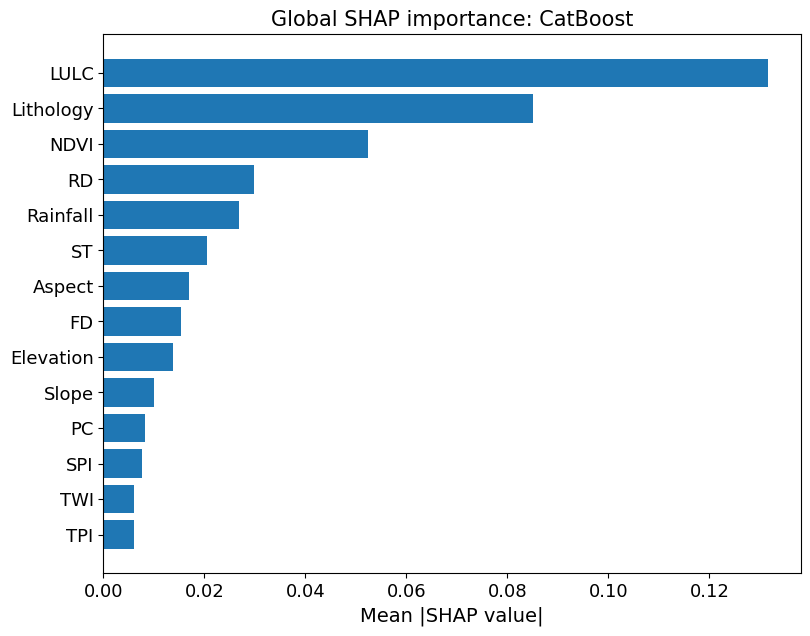

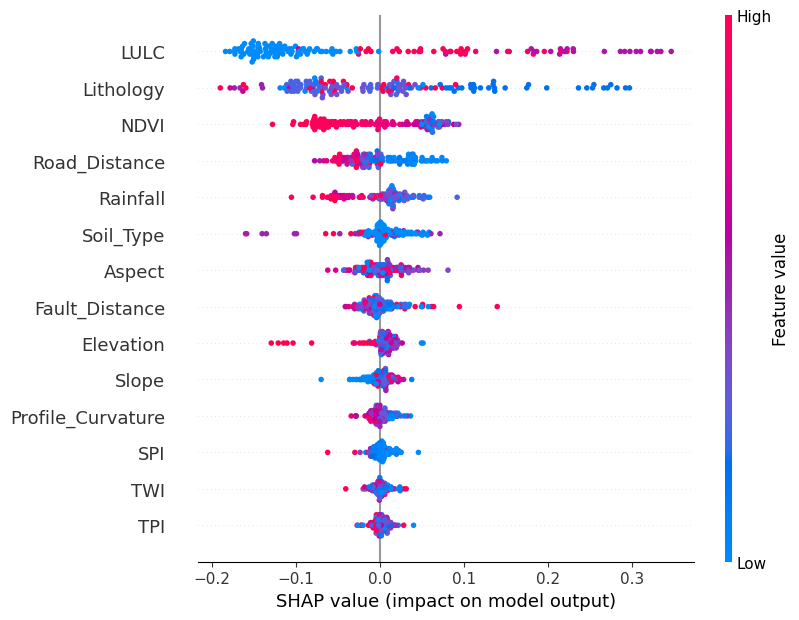

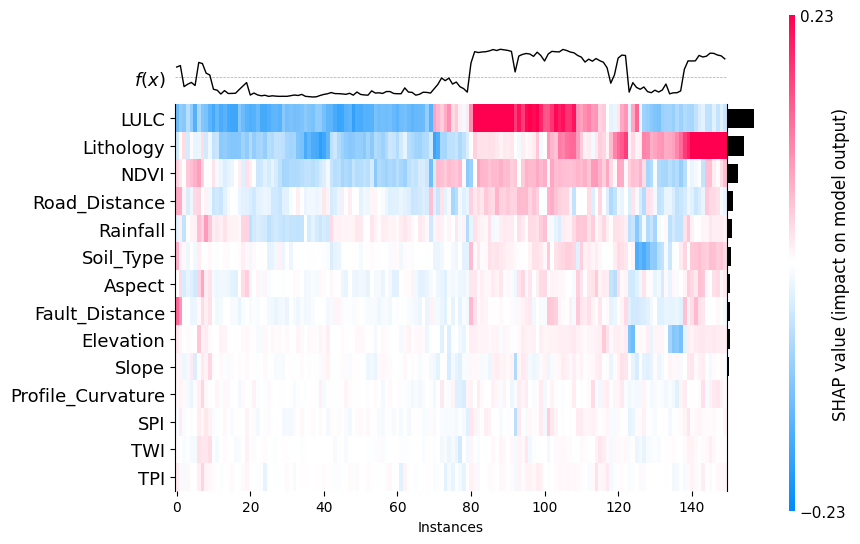

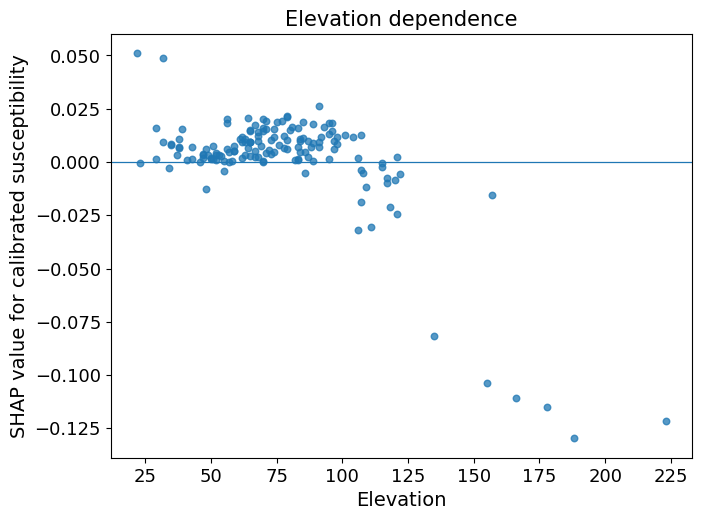

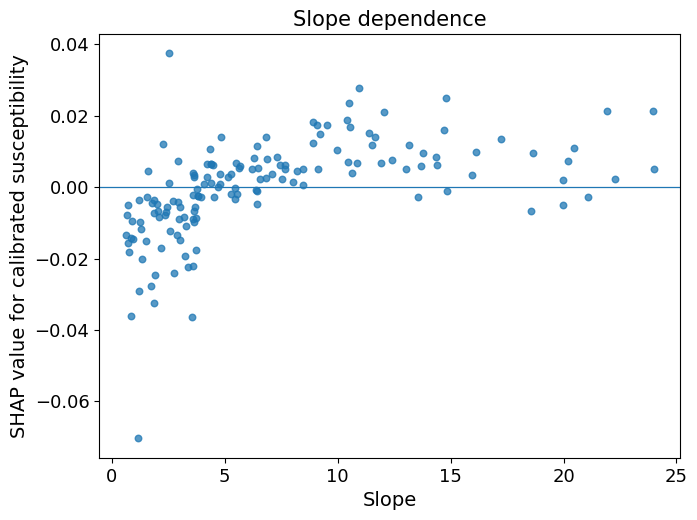

...

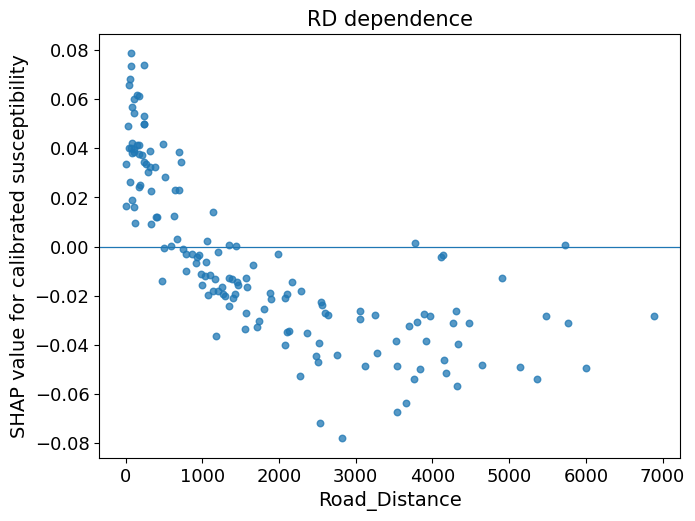

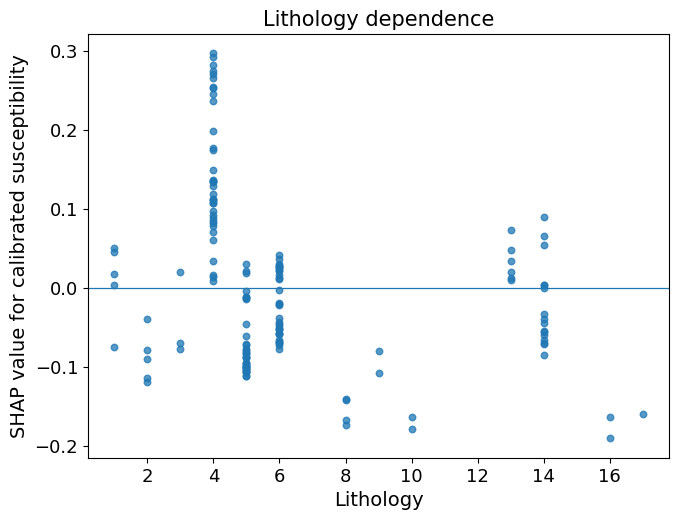

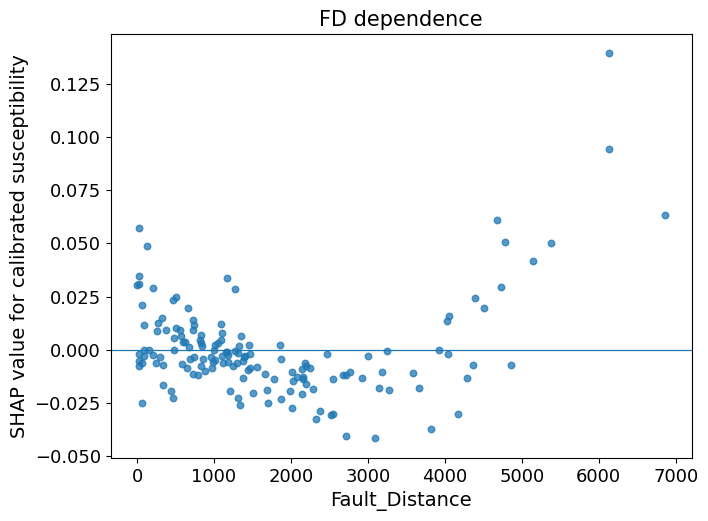

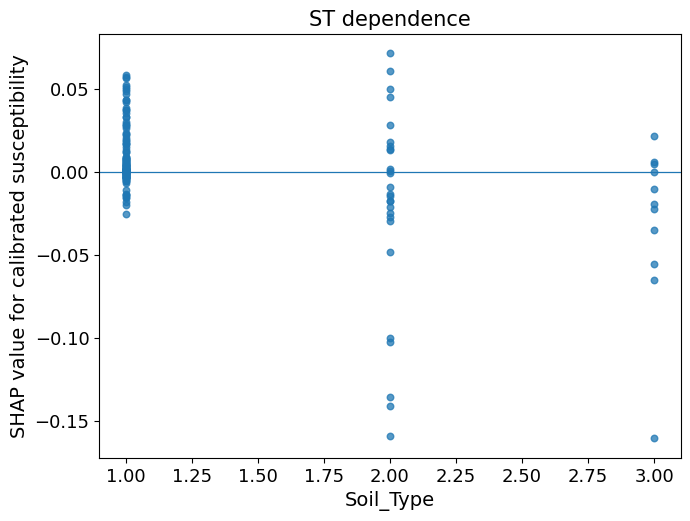

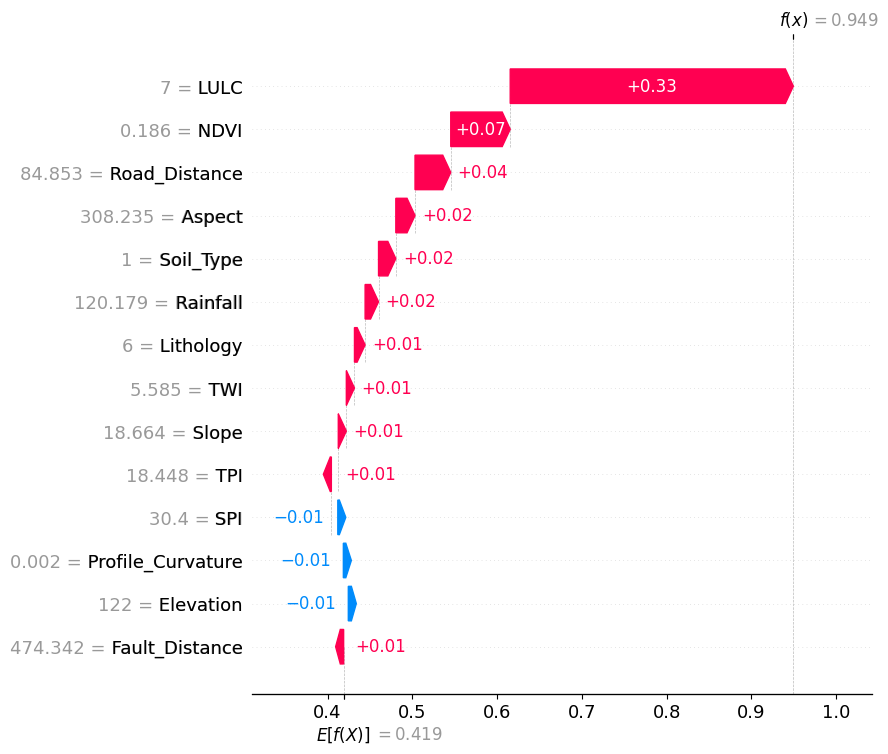

,LCF,Mean_Abs_SHAP
8,LULC,0.131558
11,Lithology,0.085063
9,NDVI,0.052297
10,RD,0.029776
7,Rainfall,0.026805
13,ST,0.020471
2,Aspect,0.016951
12,FD,0.015426
0,Elevation,0.013717
1,Slope,0.009949


In [32]:
# =============================================================================
# CELL 26 - STANDARD SHAP PUBLICATION FIGURES
# =============================================================================

shap_explanation = shap.Explanation(
    values=
        SHAP_VALUES,
    base_values=
        SHAP_BASE_VALUES,
    data=
        SHAP_DATA,
    feature_names=
        FINAL_CONCEPTUAL_FEATURES,
)

mean_abs_shap = np.mean(
    np.abs(
        SHAP_VALUES
    ),
    axis=0,
)

importance_df = (
    pd.DataFrame(
        {
            "LCF":
                [PREDICTOR_ABBR.get(x, x) for x in FINAL_CONCEPTUAL_FEATURES],
            "Mean_Abs_SHAP":
                mean_abs_shap,
        }
    )
    .sort_values(
        "Mean_Abs_SHAP",
        ascending=False,
    )
)

atomic_csv(
    importance_df,
    NB2_DIRS["tables"]
    / "Standard_SHAP_Global_Importance.csv",
)

fig, ax = plt.subplots(
    figsize=(
        9,
        7,
    )
)

plot_df = (
    importance_df
    .sort_values(
        "Mean_Abs_SHAP",
        ascending=True,
    )
)

ax.barh(
    plot_df[
        "LCF"
    ],
    plot_df[
        "Mean_Abs_SHAP"
    ],
)

ax.set_xlabel(
    "Mean |SHAP value|",
    fontsize=FONT_LABEL,
)

ax.tick_params(
    labelsize=FONT_BASE
)

ax.set_title(
    f"Global SHAP importance: {BEST_XAI_MODEL}",
    fontsize=FONT_TITLE,
)

save_figure(
    fig,
    NB2_DIRS["figures"]
    / "SHAP_Global_Importance.png",
)

plt.figure(
    figsize=(
        10,
        8,
    )
)

shap.plots.beeswarm(
    shap_explanation,
    max_display=15,
    show=False,
)

fig = plt.gcf()

save_figure(
    fig,
    NB2_DIRS["figures"]
    / "SHAP_Beeswarm.png",
)

plt.figure(
    figsize=(
        12,
        8,
    )
)

shap.plots.heatmap(
    shap_explanation,
    max_display=15,
    show=False,
)

fig = plt.gcf()

save_figure(
    fig,
    NB2_DIRS["figures"]
    / "SHAP_Heatmap.png",
)

DEPENDENCE_DIR = (
    NB2_DIRS["figures"]
    / "SHAP_Dependence"
)

DEPENDENCE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

for feature_index, feature in enumerate(
    FINAL_CONCEPTUAL_FEATURES
):
    fig, ax = plt.subplots(
        figsize=(
            7.5,
            5.5,
        )
    )

    ax.scatter(
        SHAP_DATA[
            :,
            feature_index,
        ],
        SHAP_VALUES[
            :,
            feature_index,
        ],
        s=22,
        alpha=0.75,
    )

    ax.axhline(
        0,
        linewidth=0.9,
    )

    ax.set_xlabel(
        feature,
        fontsize=FONT_LABEL,
    )

    ax.set_ylabel(
        "SHAP value for calibrated susceptibility",
        fontsize=FONT_LABEL,
    )

    ax.tick_params(
        labelsize=FONT_BASE
    )

    ax.set_title(
        f"{PREDICTOR_ABBR[feature]} dependence",
        fontsize=FONT_TITLE,
    )

    save_figure(
        fig,
        DEPENDENCE_DIR
        /
        f"{feature_index+1:02d}_{PREDICTOR_ABBR[feature]}_Dependence.png",
    )

xai_probability = calibrated_conceptual_probability(
    X_evaluation_numeric.to_numpy(
        dtype="float64"
    )
)

local_index = int(
    np.argmax(
        xai_probability
    )
)

plt.figure(
    figsize=(
        9,
        7,
    )
)

shap.plots.waterfall(
    shap_explanation[
        local_index
    ],
    max_display=15,
    show=False,
)

fig = plt.gcf()

save_figure(
    fig,
    NB2_DIRS["figures"]
    / "SHAP_Local_Waterfall_Highest_Susceptibility.png",
)

display(
    importance_df
)

In [33]:
# =============================================================================
# CELL 27 - SHAP-IQ FSII, ORDERS 1 TO 3
# HEAVY / PER-OBSERVATION RESUME-SAFE
# =============================================================================

SHAPIQ_OBS_DIR = (
    NB2_DIRS["shapiq"]
    / "observations"
)

SHAPIQ_OBS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SHAPIQ_STATE = (
    NB2_DIRS["checkpoints"]
    / "SHAPIQ_FSII.state.json"
)

SHAPIQ_SIGNATURE = stable_signature(
    {
        "stage":
            "shapiq_fsii",
        "model":
            BEST_XAI_MODEL,
        "bundle_signature":
            BEST_XAI_BUNDLE[
                "signature"
            ],
        "xai_sample_hash":
            XAI_SAMPLE_HASH,
        "index":
            SHAPIQ_INDEX,
        "max_order":
            SHAPIQ_MAX_ORDER,
        "budget":
            SHAPIQ_BUDGET,
        "top_order_only":
            False,
        "background_n":
            len(
                X_background_numeric
            ),
    }
)

def shapiq_probability_model(
    array_like,
):
    array = np.asarray(
        array_like
    )

    if array.ndim == 1:
        array = array.reshape(
            1,
            -1,
        )

    return calibrated_conceptual_probability(
        array
    )

try:
    fsii_explainer = shapiq.TabularExplainer(
        model=
            shapiq_probability_model,
        data=
            X_background_numeric.to_numpy(
                dtype="float64"
            ),
        imputer=
            "marginal",
        index=
            SHAPIQ_INDEX,
        max_order=
            SHAPIQ_MAX_ORDER,
        random_state=
            RANDOM_SEED,
        verbose=
            False,
    )

except Exception:
    fsii_explainer = shapiq.Explainer(
        model=
            shapiq_probability_model,
        data=
            X_background_numeric.to_numpy(
                dtype="float64"
            ),
        index=
            SHAPIQ_INDEX,
        max_order=
            SHAPIQ_MAX_ORDER,
        random_state=
            RANDOM_SEED,
    )

for observation_index in tqdm(
    range(
        len(
            X_evaluation_numeric
        )
    ),
    desc="FSII observations",
):
    output_file = (
        SHAPIQ_OBS_DIR
        /
        f"obs_{observation_index:04d}.pkl"
    )

    if output_file.exists():
        try:
            with output_file.open(
                "rb"
            ) as file:
                payload = pickle.load(
                    file
                )

            if payload.get(
                "Signature"
            ) == SHAPIQ_SIGNATURE:
                continue

        except Exception:
            output_file.unlink(
                missing_ok=True
            )

    x = (
        X_evaluation_numeric
        .iloc[
            observation_index
        ]
        .to_numpy(
            dtype="float64"
        )
        .reshape(
            1,
            -1,
        )
    )

    try:
        interaction_values = fsii_explainer.explain(
            x,
            budget=
                SHAPIQ_BUDGET,
            random_state=
                RANDOM_SEED
                +
                observation_index,
        )

    except TypeError:
        interaction_values = fsii_explainer.explain(
            x,
            budget=
                SHAPIQ_BUDGET,
        )

    payload = {
        "Signature":
            SHAPIQ_SIGNATURE,
        "Observation_Index":
            observation_index,
        "Sample_ID":
            XAI_EVAL_DF.loc[
                observation_index,
                "Sample_ID",
            ],
        "InteractionValues":
            interaction_values,
    }

    tmp = (
        output_file.parent
        /
        f".{output_file.name}.tmp"
    )

    with tmp.open(
        "wb"
    ) as file:
        pickle.dump(
            payload,
            file,
            protocol=
                pickle.HIGHEST_PROTOCOL,
        )

        file.flush()

        os.fsync(
            file.fileno()
        )

    os.replace(
        tmp,
        output_file,
    )

required_fsii = [
    SHAPIQ_OBS_DIR
    /
    f"obs_{i:04d}.pkl"
    for i in range(
        len(
            X_evaluation_numeric
        )
    )
]

if not all(
    path.exists()
    for path in required_fsii
):
    raise RuntimeError(
        "SHAP-IQ observation set is incomplete."
    )

atomic_json(
    {
        "Status": "COMPLETE",
        "Signature":
            SHAPIQ_SIGNATURE,
        "Index":
            SHAPIQ_INDEX,
        "Max_Order":
            SHAPIQ_MAX_ORDER,
        "Budget":
            SHAPIQ_BUDGET,
        "Top_Order_Only":
            False,
        "Observations":
            len(
                X_evaluation_numeric
            ),
        "Completed_UTC":
            pd.Timestamp.utcnow().isoformat(),
    },
    SHAPIQ_STATE,
)

print(
    "SHAP-IQ FSII stage complete."
)

FSII observations:   0%|          | 0/150 [00:00<?, ?it/s]

SHAP-IQ FSII stage complete.


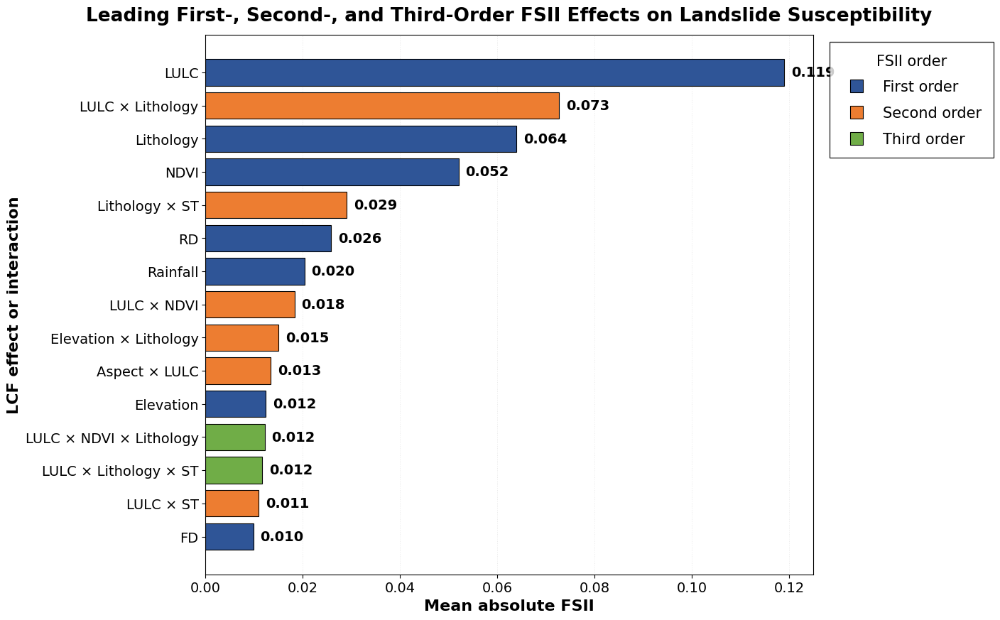

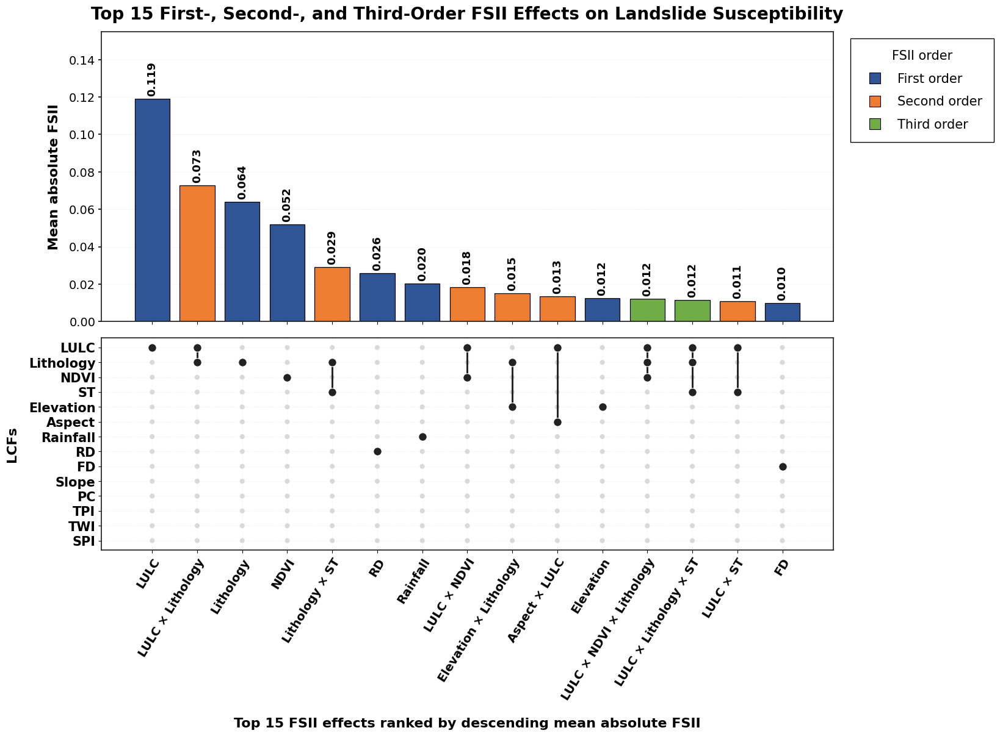


CELL 28 - UNIFIED ORDER 1 TO 3 FSII TOP 15 COMPLETE

Final 14 LCF abbreviations:
['Elevation', 'Slope', 'Aspect', 'PC', 'TPI', 'TWI', 'SPI', 'Rainfall', 'LULC', 'NDVI', 'RD', 'Lithology', 'FD', 'ST']

Top-15 effect counts by FSII order:


,Order,Top15_Count,Effect_Type
0,1,7,First order
1,2,6,Second order
2,3,2,Third order



Overall Top 15 FSII effects:


,Rank,Order,Effect_Type,Interaction_Abbr,Mean_Abs_FSII,Mean_Signed_FSII,Median_Signed_FSII,SD_Signed_FSII,Positive_Fraction,Negative_Fraction
0,1,1,First order,LULC,0.119017,-0.012760,-0.106701,0.130821,0.373333,0.626667
1,2,2,Second order,LULC × Lithology,0.072668,-0.027949,-0.054137,0.074496,0.333333,0.666667
2,3,1,First order,Lithology,0.063956,0.019128,-0.012616,0.084096,0.326667,0.673333
3,4,1,First order,NDVI,0.052042,-0.018528,-0.013845,0.055941,0.440000,0.560000
4,5,2,Second order,Lithology × ST,0.029052,-0.010622,-0.019562,0.035190,0.353333,0.646667
5,6,1,First order,RD,0.025855,-0.008040,-0.018735,0.027070,0.380000,0.620000
6,7,1,First order,Rainfall,0.020367,-0.005542,0.005358,0.024816,0.633333,0.366667
7,8,2,Second order,LULC × NDVI,0.018286,0.017350,0.014974,0.014544,0.953333,0.046667
8,9,2,Second order,Elevation × Lithology,0.014997,-0.011341,-0.011477,0.020779,0.206667,0.793333
9,10,2,Second order,Aspect × LULC,0.013425,-0.005172,-0.006009,0.014939,0.366667,0.633333



Saved figures:
   /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/15_Figures/SHAPIQ_FSII_Overall_Top15.png
   /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/15_Figures/SHAPIQ_FSII_Top15_UpSet.png


In [34]:
# =============================================================================
# CELL 28 - UNIFIED FSII TOP 15 ACROSS ORDERS 1 TO 3
#           + GW-STYLE UPSET FIGURE
# =============================================================================
#
# SCIENTIFIC PURPOSE
# -----------------------------------------------------------------------------
# 1. Restore all completed observation-level FSII explanations.
# 2. Retain genuine first-, second-, and third-order FSII effects.
# 3. Aggregate each effect globally using mean absolute FSII.
# 4. Rank ALL orders together.
# 5. Retain the overall Top 15 effects regardless of interaction order.
# 6. Preserve signed FSII summaries for interpretation.
# 7. Produce:
#
#    A. Order-colored horizontal Top-15 FSII figure.
#
#    B. Publication-quality UpSet-style figure using the reference design:
#       - upper panel = Top-15 mean absolute FSII bars;
#       - blue = first order;
#       - orange = second order;
#       - green = third order;
#       - numerical FSII magnitude above each bar;
#       - lower panel = LCF membership matrix;
#       - active membership dots = black;
#       - pair/triple connectors = black;
#       - all 14 final LCFs displayed using locked abbreviations;
#       - legend outside the plotting region on the right.
#
# IMPORTANT
# -----------------------------------------------------------------------------
# The analytical FSII results are NOT changed in this cell.
# This cell only improves aggregation labels and publication graphics.
#
# TRI is absent because the final susceptibility framework contains 14 LCFs.
# =============================================================================


# =============================================================================
# 28.1 REQUIRED IMPORT
# =============================================================================

from matplotlib.lines import Line2D


# =============================================================================
# 28.2 LOCKED 14-LCF ABBREVIATIONS
# =============================================================================
#
# These are the exact abbreviations required for all SHAP-IQ figures.
# =============================================================================

LCF_ABBR = {

    "Elevation":
        "Elevation",

    "Slope":
        "Slope",

    "Aspect":
        "Aspect",

    "Profile_Curvature":
        "PC",

    "TPI":
        "TPI",

    "TWI":
        "TWI",

    "SPI":
        "SPI",

    "Rainfall":
        "Rainfall",

    "LULC":
        "LULC",

    "NDVI":
        "NDVI",

    "Road_Distance":
        "RD",

    "Lithology":
        "Lithology",

    "Fault_Distance":
        "FD",

    "Soil_Type":
        "ST",
}


# Keep later XAI cells consistent with the same abbreviations.
PREDICTOR_ABBR = LCF_ABBR.copy()


EXPECTED_FINAL_LCFS = [

    "Elevation",
    "Slope",
    "Aspect",
    "Profile_Curvature",
    "TPI",
    "TWI",
    "SPI",
    "Rainfall",
    "LULC",
    "NDVI",
    "Road_Distance",
    "Lithology",
    "Fault_Distance",
    "Soil_Type",
]


if list(
    FINAL_CONCEPTUAL_FEATURES
) != EXPECTED_FINAL_LCFS:

    raise RuntimeError(
        "FINAL_CONCEPTUAL_FEATURES does not match the locked "
        "14-LCF susceptibility framework.\n\n"
        f"Expected:\n{EXPECTED_FINAL_LCFS}\n\n"
        f"Found:\n{list(FINAL_CONCEPTUAL_FEATURES)}"
    )


if len(
    FINAL_CONCEPTUAL_FEATURES
) != 14:

    raise RuntimeError(
        "Cell 28 requires exactly 14 final conceptual LCFs."
    )


if set(
    LCF_ABBR.keys()
) != set(
    FINAL_CONCEPTUAL_FEATURES
):

    raise RuntimeError(
        "LCF_ABBR does not contain exactly the 14 final LCFs."
    )


# =============================================================================
# 28.3 LOCKED FSII ORDER COLORS
# =============================================================================
#
# These reproduce the reference first-, second-, and third-order color scheme.
# =============================================================================

FSII_ORDER_COLORS = {

    1:
        "#2F5597",   # blue

    2:
        "#ED7D31",   # orange

    3:
        "#70AD47",   # green
}


FSII_ORDER_LABELS = {

    1:
        "First order",

    2:
        "Second order",

    3:
        "Third order",
}


# =============================================================================
# 28.4 OUTPUT PATHS
# =============================================================================

FSII_LONG_CSV = (

    NB2_DIRS[
        "shapiq"
    ]

    /

    "FSII_All_Observations_Long.csv"
)


FSII_RANK_CSV = (

    NB2_DIRS[
        "shapiq"
    ]

    /

    "FSII_Global_Ranking_Orders1to3.csv"
)


FSII_TOP15_CSV = (

    NB2_DIRS[
        "shapiq"
    ]

    /

    "FSII_Overall_Top15.csv"
)


FSII_TOP15_BAR_FIGURE = (

    NB2_DIRS[
        "figures"
    ]

    /

    "SHAPIQ_FSII_Overall_Top15.png"
)


FSII_TOP15_UPSET_FIGURE = (

    NB2_DIRS[
        "figures"
    ]

    /

    "SHAPIQ_FSII_Top15_UpSet.png"
)


# =============================================================================
# 28.5 HELPER - ABBREVIATED INTERACTION LABEL
# =============================================================================

def abbreviated_interaction_label(
    interaction_string,
):

    features = [

        feature.strip()

        for feature
        in str(
            interaction_string
        ).split(
            " × "
        )

    ]


    unknown = [

        feature

        for feature
        in features

        if feature not in LCF_ABBR

    ]


    if unknown:

        raise RuntimeError(
            "Unknown LCF name encountered while creating "
            f"an abbreviated FSII label: {unknown}"
        )


    return " × ".join(

        LCF_ABBR[
            feature
        ]

        for feature
        in features
    )


# =============================================================================
# 28.6 RESTORE ALL OBSERVATION-LEVEL FSII EFFECTS
# =============================================================================

rows = []


for observation_index in range(

    len(
        X_evaluation_numeric
    )

):

    observation_path = (

        SHAPIQ_OBS_DIR

        /

        f"obs_{observation_index:04d}.pkl"
    )


    if not observation_path.exists():

        raise FileNotFoundError(
            "Missing completed SHAP-IQ observation file:\n"
            f"{observation_path}"
        )


    with observation_path.open(
        "rb"
    ) as file:

        payload = pickle.load(
            file
        )


    if payload.get(
        "Signature"
    ) != SHAPIQ_SIGNATURE:

        raise RuntimeError(
            "Stale FSII observation detected: "
            f"{observation_index}."
        )


    interaction_values = payload[
        "InteractionValues"
    ]


    interaction_dict = (
        interaction_values.dict_values
    )


    for interaction, value in interaction_dict.items():

        interaction = tuple(
            interaction
        )


        order = len(
            interaction
        )


        if order not in {
            1,
            2,
            3,
        }:

            continue


        if any(

            feature_index < 0

            or

            feature_index >= len(
                FINAL_CONCEPTUAL_FEATURES
            )

            for feature_index
            in interaction

        ):

            raise RuntimeError(
                "Invalid FSII LCF index encountered:\n"
                f"{interaction}"
            )


        names = [

            FINAL_CONCEPTUAL_FEATURES[
                feature_index
            ]

            for feature_index
            in interaction

        ]


        interaction_name = " × ".join(
            names
        )


        value = float(
            value
        )


        if not np.isfinite(
            value
        ):

            raise RuntimeError(
                "Non-finite FSII value encountered for "
                f"observation {observation_index}, "
                f"interaction {interaction_name}."
            )


        rows.append(

            {

                "Observation_Index":
                    observation_index,

                "Sample_ID":
                    payload[
                        "Sample_ID"
                    ],

                "Order":
                    order,

                "Interaction_Index":
                    "|".join(
                        map(
                            str,
                            interaction,
                        )
                    ),

                "Interaction":
                    interaction_name,

                "Interaction_Abbr":
                    abbreviated_interaction_label(
                        interaction_name
                    ),

                "Value":
                    value,

                "Abs_Value":
                    abs(
                        value
                    ),
            }
        )


# =============================================================================
# 28.7 BUILD LONG FSII TABLE
# =============================================================================

fsii_long_df = pd.DataFrame(
    rows
)


if fsii_long_df.empty:

    raise RuntimeError(
        "No first-, second-, or third-order FSII values "
        "were extracted."
    )


observed_orders = set(

    fsii_long_df[
        "Order"
    ]
    .astype(
        int
    )
    .unique()
    .tolist()

)


if not observed_orders.issubset(
    {
        1,
        2,
        3,
    }
):

    raise RuntimeError(
        "Unexpected FSII order detected:\n"
        f"{sorted(observed_orders)}"
    )


atomic_csv(
    fsii_long_df,
    FSII_LONG_CSV,
)


# =============================================================================
# 28.8 GLOBAL FSII AGGREGATION
# =============================================================================

fsii_rank_df = (

    fsii_long_df

    .groupby(
        [
            "Order",
            "Interaction",
            "Interaction_Abbr",
        ],
        as_index=False,
    )

    .agg(

        Mean_Abs_FSII=(
            "Abs_Value",
            "mean",
        ),

        Mean_Signed_FSII=(
            "Value",
            "mean",
        ),

        Median_Signed_FSII=(
            "Value",
            "median",
        ),

        SD_Signed_FSII=(
            "Value",
            "std",
        ),

        Positive_Fraction=(
            "Value",
            lambda values:
                float(
                    np.mean(
                        np.asarray(
                            values
                        )
                        >
                        0
                    )
                ),
        ),

        Negative_Fraction=(
            "Value",
            lambda values:
                float(
                    np.mean(
                        np.asarray(
                            values
                        )
                        <
                        0
                    )
                ),
        ),

        N_Explained=(
            "Value",
            "size",
        ),
    )

    .sort_values(
        "Mean_Abs_FSII",
        ascending=False,
    )

    .reset_index(
        drop=True
    )
)


fsii_rank_df.insert(

    0,

    "Global_Rank",

    np.arange(
        1,
        len(
            fsii_rank_df
        )
        +
        1,
    )
)


# =============================================================================
# 28.9 OVERALL TOP 15 ACROSS ORDERS 1 TO 3
# =============================================================================

fsii_top15_df = (

    fsii_rank_df

    .head(
        15
    )

    .copy()

    .reset_index(
        drop=True
    )
)


fsii_top15_df.rename(
    columns={
        "Global_Rank":
            "Rank"
    },
    inplace=True,
)


if len(
    fsii_top15_df
) != min(
    15,
    len(
        fsii_rank_df
    )
):

    raise RuntimeError(
        "Top-15 FSII extraction failed."
    )


# Add readable effect type.
fsii_top15_df[
    "Effect_Type"
] = (

    fsii_top15_df[
        "Order"
    ]

    .map(
        FSII_ORDER_LABELS
    )
)


atomic_csv(
    fsii_rank_df,
    FSII_RANK_CSV,
)


atomic_csv(
    fsii_top15_df,
    FSII_TOP15_CSV,
)


# =============================================================================
# 28.10 ORDER COUNTS IN THE OVERALL TOP 15
# =============================================================================

top15_order_counts = (

    fsii_top15_df[
        "Order"
    ]

    .value_counts()

    .reindex(
        [
            1,
            2,
            3,
        ],
        fill_value=0,
    )

    .rename_axis(
        "Order"
    )

    .reset_index(
        name="Top15_Count"
    )
)


top15_order_counts[
    "Effect_Type"
] = (

    top15_order_counts[
        "Order"
    ]

    .map(
        FSII_ORDER_LABELS
    )
)


# =============================================================================
# 28.11 COMMON LEGEND
# =============================================================================
#
# 15 pt as requested.
# =============================================================================

legend_handles = [

    Line2D(
        [
            0
        ],
        [
            0
        ],
        marker="s",
        linestyle="none",
        markersize=13,
        markerfacecolor=
            FSII_ORDER_COLORS[
                1
            ],
        markeredgecolor="black",
        markeredgewidth=0.8,
        label="First order",
    ),

    Line2D(
        [
            0
        ],
        [
            0
        ],
        marker="s",
        linestyle="none",
        markersize=13,
        markerfacecolor=
            FSII_ORDER_COLORS[
                2
            ],
        markeredgecolor="black",
        markeredgewidth=0.8,
        label="Second order",
    ),

    Line2D(
        [
            0
        ],
        [
            0
        ],
        marker="s",
        linestyle="none",
        markersize=13,
        markerfacecolor=
            FSII_ORDER_COLORS[
                3
            ],
        markeredgecolor="black",
        markeredgewidth=0.8,
        label="Third order",
    ),
]


# =============================================================================
# 28.12 FIGURE A - OVERALL TOP 15 HORIZONTAL FSII RANKING
# =============================================================================
#
# Retained because the original Cell 28 produced this separate figure.
# Unlike the old version, bars are now explicitly colored by FSII order.
# =============================================================================

horizontal_plot_df = (

    fsii_top15_df

    .sort_values(
        "Mean_Abs_FSII",
        ascending=True,
    )

    .reset_index(
        drop=True
    )
)


horizontal_colors = [

    FSII_ORDER_COLORS[
        int(
            order
        )
    ]

    for order
    in horizontal_plot_df[
        "Order"
    ]
]


fig, ax = plt.subplots(
    figsize=(
        14.5,
        9.5,
    )
)


bars = ax.barh(

    horizontal_plot_df[
        "Interaction_Abbr"
    ],

    horizontal_plot_df[
        "Mean_Abs_FSII"
    ],

    color=
        horizontal_colors,

    edgecolor=
        "black",

    linewidth=
        0.8,
)


# -------------------------------------------------------------------------
# Numerical value annotation
# -------------------------------------------------------------------------

maximum_horizontal_value = float(

    horizontal_plot_df[
        "Mean_Abs_FSII"
    ]
    .max()

)


horizontal_text_offset = max(

    maximum_horizontal_value
    *
    0.012,

    1e-6,
)


for bar, value in zip(

    bars,

    horizontal_plot_df[
        "Mean_Abs_FSII"
    ].to_numpy(
        dtype=float
    ),

):

    ax.text(

        value
        +
        horizontal_text_offset,

        bar.get_y()
        +
        bar.get_height()
        /
        2,

        f"{value:.3f}",

        va="center",

        ha="left",

        fontsize=14,

        fontweight="bold",
    )


ax.set_xlabel(
    "Mean absolute FSII",
    fontsize=16,
    fontweight="bold",
)


ax.set_ylabel(
    "LCF effect or interaction",
    fontsize=16,
    fontweight="bold",
)


ax.set_title(
    (
        "Leading First-, Second-, and Third-Order "
        "FSII Effects on Landslide Susceptibility"
    ),
    fontsize=19,
    fontweight="bold",
    pad=14,
)


ax.tick_params(
    axis="x",
    labelsize=14,
)


ax.tick_params(
    axis="y",
    labelsize=14,
)


ax.grid(
    axis="x",
    linestyle=":",
    linewidth=0.7,
    alpha=0.28,
)


ax.set_axisbelow(
    True
)


# -------------------------------------------------------------------------
# External legend
# -------------------------------------------------------------------------

ax.legend(

    handles=
        legend_handles,

    title=
        "FSII order",

    loc=
        "upper left",

    bbox_to_anchor=(
        1.015,
        1.0,
    ),

    fontsize=
        15,

    title_fontsize=
        15,

    frameon=
        True,

    edgecolor=
        "black",

    fancybox=
        False,

    borderpad=
        0.8,

    labelspacing=
        0.8,
)


# Reserve real canvas space for external legend.
fig.subplots_adjust(
    left=0.18,
    right=0.77,
    bottom=0.11,
    top=0.91,
)


save_figure(
    fig,
    FSII_TOP15_BAR_FIGURE,
)


# =============================================================================
# 28.13 DETERMINE THE 14-LCF ROW ORDER FOR THE UPSET MATRIX
# =============================================================================
#
# The reference design prioritizes LCFs that participate most frequently
# in the Top 15. All 14 retained LCFs remain displayed.
#
# Ties preserve the locked final LCF order.
# =============================================================================

lcf_involvement_count = {

    feature:
        0

    for feature
    in FINAL_CONCEPTUAL_FEATURES
}


for interaction in fsii_top15_df[
    "Interaction"
]:

    members = [

        member.strip()

        for member
        in str(
            interaction
        ).split(
            " × "
        )

    ]


    for member in members:

        if member not in lcf_involvement_count:

            raise RuntimeError(
                "Top-15 FSII interaction contains an unknown LCF:\n"
                f"{member}"
            )


        lcf_involvement_count[
            member
        ] += 1


original_lcf_position = {

    feature:
        index

    for index, feature
    in enumerate(
        FINAL_CONCEPTUAL_FEATURES
    )
}


upset_lcf_order = sorted(

    FINAL_CONCEPTUAL_FEATURES,

    key=lambda feature: (

        -lcf_involvement_count[
            feature
        ],

        original_lcf_position[
            feature
        ],
    )
)


feature_to_y = {

    feature:
        index

    for index, feature
    in enumerate(
        upset_lcf_order
    )
}


# =============================================================================
# 28.14 FIGURE B - GW-STYLE TOP-15 FSII UPSET FIGURE
# =============================================================================

top_df = (

    fsii_top15_df

    .sort_values(
        "Rank",
        ascending=True,
    )

    .reset_index(
        drop=True
    )
)


x_positions = np.arange(
    len(
        top_df
    )
)


bar_values = (

    top_df[
        "Mean_Abs_FSII"
    ]

    .to_numpy(
        dtype=float
    )
)


bar_colors = [

    FSII_ORDER_COLORS[
        int(
            order
        )
    ]

    for order
    in top_df[
        "Order"
    ]
]


# -------------------------------------------------------------------------
# Main figure
# -------------------------------------------------------------------------

fig, (
    ax_bar,
    ax_matrix,
) = plt.subplots(

    2,
    1,

    figsize=(
        17.5,
        12.5,
    ),

    sharex=True,

    gridspec_kw={
        "height_ratios":
            [
                3.0,
                2.20,
            ]
    },
)


# =============================================================================
# 28.15 UPPER PANEL - ORDER-COLORED FSII BARS
# =============================================================================

bars = ax_bar.bar(

    x_positions,

    bar_values,

    color=
        bar_colors,

    edgecolor=
        "black",

    linewidth=
        0.9,

    width=
        0.78,
)


maximum_strength = (

    float(
        np.max(
            bar_values
        )
    )

    if len(
        bar_values
    )

    else
        0.0
)


if maximum_strength > 0:

    ax_bar.set_ylim(

        0,

        maximum_strength
        *
        1.30,
    )


ax_bar.set_title(

    (
        "Top 15 First-, Second-, and Third-Order "
        "FSII Effects on Landslide Susceptibility"
    ),

    fontsize=20,

    fontweight="bold",

    pad=15,
)


ax_bar.set_ylabel(

    "Mean absolute FSII",

    fontsize=16,

    fontweight="bold",

    labelpad=10,
)


ax_bar.tick_params(

    axis="y",

    labelsize=14,

    width=1.2,
)


ax_bar.tick_params(

    axis="x",

    labelbottom=False,
)


ax_bar.grid(

    True,

    axis="y",

    linestyle=":",

    linewidth=0.7,

    alpha=0.30,
)


ax_bar.set_axisbelow(
    True
)


# =============================================================================
# 28.16 FSII VALUES ABOVE EACH BAR
# =============================================================================

bar_label_offset = max(

    maximum_strength
    *
    0.012,

    1e-6,
)


for bar, value in zip(

    bars,

    bar_values,

):

    ax_bar.text(

        bar.get_x()
        +
        bar.get_width()
        /
        2,

        value
        +
        bar_label_offset,

        f"{value:.3f}",

        ha="center",

        va="bottom",

        rotation=90,

        fontsize=13,

        fontweight="bold",
    )


# =============================================================================
# 28.17 LEGEND AT RIGHT - NO PLOT OVERLAP
# =============================================================================

ax_bar.legend(

    handles=
        legend_handles,

    title=
        "FSII order",

    loc=
        "upper left",

    bbox_to_anchor=(
        1.015,
        1.0,
    ),

    fontsize=
        15,

    title_fontsize=
        15,

    frameon=
        True,

    facecolor=
        "white",

    edgecolor=
        "black",

    fancybox=
        False,

    framealpha=
        1.0,

    borderpad=
        0.9,

    labelspacing=
        0.85,

    handletextpad=
        0.8,
)


# =============================================================================
# 28.18 LOWER PANEL - FULL 14-LCF MEMBERSHIP MATRIX
# =============================================================================
#
# Subtle inactive dots create the UpSet matrix structure.
# Active dots and pair/triple connectors are black, matching the clean
# reference design. FSII order is communicated by the bar colors above.
# =============================================================================

inactive_color = "#D9D9D9"

active_color = "#222222"


# -------------------------------------------------------------------------
# Draw inactive membership grid
# -------------------------------------------------------------------------

for x_position in x_positions:

    ax_matrix.scatter(

        np.repeat(
            x_position,
            len(
                upset_lcf_order
            ),
        ),

        np.arange(
            len(
                upset_lcf_order
            )
        ),

        s=34,

        color=
            inactive_color,

        edgecolor=
            "none",

        zorder=1,
    )


# -------------------------------------------------------------------------
# Draw active memberships and connectors
# -------------------------------------------------------------------------

for x_position, (
    _,
    effect_row,
) in zip(

    x_positions,

    top_df.iterrows(),

):

    involved_features = [

        feature.strip()

        for feature
        in str(
            effect_row[
                "Interaction"
            ]
        ).split(
            " × "
        )

    ]


    order = int(
        effect_row[
            "Order"
        ]
    )


    if len(
        involved_features
    ) != order:

        raise RuntimeError(
            "FSII order does not match the number of LCFs "
            "in the interaction:\n"
            f"{effect_row['Interaction']}"
        )


    y_positions = [

        feature_to_y[
            feature
        ]

        for feature
        in involved_features
    ]


    # ---------------------------------------------------------------------
    # Vertical connector for second- and third-order effects
    # ---------------------------------------------------------------------

    if len(
        y_positions
    ) > 1:

        ax_matrix.plot(

            [
                x_position,
                x_position,
            ],

            [
                min(
                    y_positions
                ),
                max(
                    y_positions
                ),
            ],

            color=
                active_color,

            linewidth=
                2.1,

            solid_capstyle=
                "round",

            zorder=
                2,
        )


    # ---------------------------------------------------------------------
    # Active membership dots
    # ---------------------------------------------------------------------

    ax_matrix.scatter(

        np.repeat(
            x_position,
            len(
                y_positions
            ),
        ),

        y_positions,

        s=
            95,

        color=
            active_color,

        edgecolor=
            "white",

        linewidth=
            0.8,

        zorder=
            3,
    )


# =============================================================================
# 28.19 14 LCF LABELS
# =============================================================================

ax_matrix.set_yticks(

    np.arange(
        len(
            upset_lcf_order
        )
    )
)


ax_matrix.set_yticklabels(

    [

        LCF_ABBR[
            feature
        ]

        for feature
        in upset_lcf_order

    ],

    fontsize=15,

    fontweight="bold",
)


# Most involved LCFs appear at the top.
ax_matrix.invert_yaxis()


ax_matrix.set_ylabel(

    "LCFs",

    fontsize=16,

    fontweight="bold",

    labelpad=12,
)


# =============================================================================
# 28.20 ABBREVIATED TOP-15 INTERACTION LABELS
# =============================================================================

ax_matrix.set_xticks(
    x_positions
)


ax_matrix.set_xticklabels(

    top_df[
        "Interaction_Abbr"
    ].tolist(),

    rotation=58,

    ha="right",

    rotation_mode="anchor",

    fontsize=14,

    fontweight="bold",
)


ax_matrix.set_xlabel(

    (
        "Top 15 FSII effects ranked by descending "
        "mean absolute FSII"
    ),

    fontsize=16,

    fontweight="bold",

    labelpad=18,
)


# =============================================================================
# 28.21 MATRIX GRID
# =============================================================================

ax_matrix.grid(

    True,

    axis="both",

    linestyle=":",

    linewidth=0.60,

    alpha=0.28,
)


ax_matrix.set_axisbelow(
    True
)


# =============================================================================
# 28.22 AXIS FRAME STYLE
# =============================================================================

for axis in (
    ax_bar,
    ax_matrix,
):

    for spine in axis.spines.values():

        spine.set_visible(
            True
        )

        spine.set_color(
            "#222222"
        )

        spine.set_linewidth(
            1.25
        )


# =============================================================================
# 28.23 FINAL LAYOUT
# =============================================================================
#
# right=0.79 deliberately reserves approximately 21% of the figure width
# for the 15-pt legend, ensuring the legend cannot overlap either plot.
#
# bottom is enlarged for the abbreviated interaction labels.
# =============================================================================

fig.subplots_adjust(

    left=0.105,

    right=0.79,

    bottom=0.245,

    top=0.925,

    hspace=0.065,
)


# =============================================================================
# 28.24 SAVE PUBLICATION UPSET FIGURE
# =============================================================================

save_figure(
    fig,
    FSII_TOP15_UPSET_FIGURE,
)


# =============================================================================
# 28.25 FINAL QC TABLES
# =============================================================================

print(
    "\n"
    +
    "=" * 92
)

print(
    "CELL 28 - UNIFIED ORDER 1 TO 3 FSII TOP 15 COMPLETE"
)

print(
    "=" * 92
)


print(
    "\nFinal 14 LCF abbreviations:"
)

print(
    [
        LCF_ABBR[
            feature
        ]
        for feature
        in FINAL_CONCEPTUAL_FEATURES
    ]
)


print(
    "\nTop-15 effect counts by FSII order:"
)

display(
    top15_order_counts
)


print(
    "\nOverall Top 15 FSII effects:"
)

display(

    fsii_top15_df[
        [
            "Rank",
            "Order",
            "Effect_Type",
            "Interaction_Abbr",
            "Mean_Abs_FSII",
            "Mean_Signed_FSII",
            "Median_Signed_FSII",
            "SD_Signed_FSII",
            "Positive_Fraction",
            "Negative_Fraction",
        ]
    ]
)


print(
    "\nSaved figures:"
)

print(
    "  ",
    FSII_TOP15_BAR_FIGURE
)

print(
    "  ",
    FSII_TOP15_UPSET_FIGURE
)

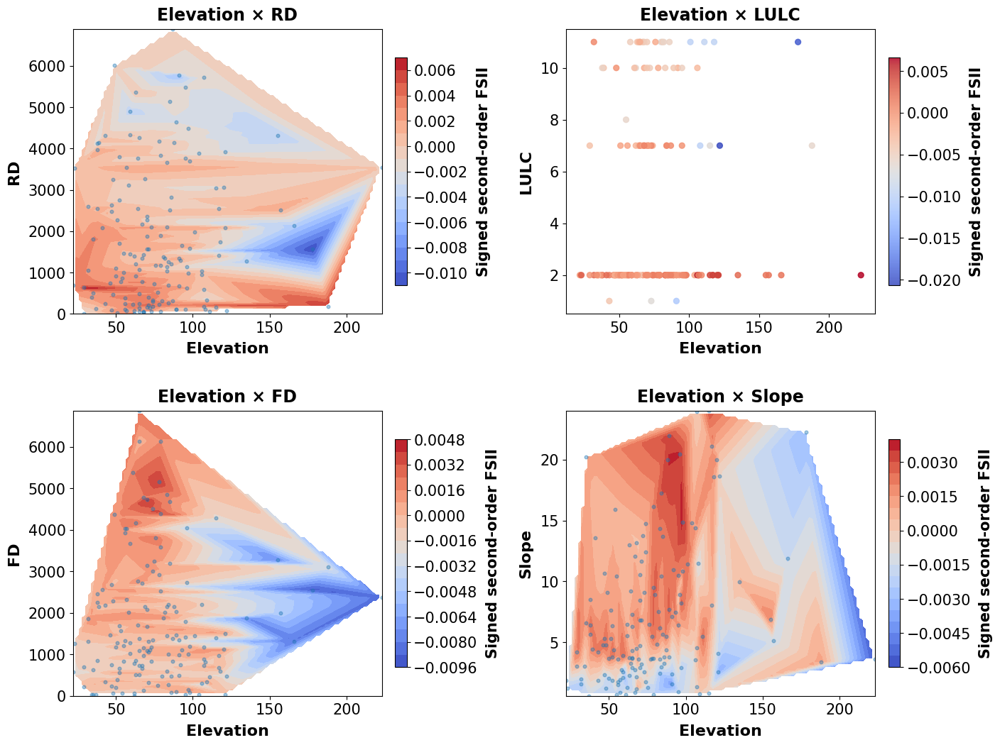

In [35]:
# =============================================================================
# CELL 29 - ELEVATION-CENTERED SECOND-ORDER FSII DIAGNOSTIC, 2 × 2
# =============================================================================
#
# PURPOSE
# -----------------------------------------------------------------------------
# Visualize signed second-order FSII interactions between Elevation and:
#
#   1. RD
#   2. LULC
#   3. FD
#   4. Slope
#
# Continuous interactions are represented using linearly interpolated
# interaction surfaces with the original evaluation observations overlaid.
#
# The categorical Elevation × LULC interaction is represented directly
# using an observation-level scatter plot because interpolation across
# nominal LULC classes would be scientifically inappropriate.
#
# Positive FSII values indicate synergistic interaction contributions to
# predicted landslide susceptibility, whereas negative values indicate
# antagonistic interaction contributions.
#
# FIGURE DESIGN
# -----------------------------------------------------------------------------
# - Minimum visible font size = 15 pt
# - Bold panel titles and axis labels
# - Compact but sufficient subplot spacing
# - No overlap between upper-row x-axis labels and lower-row titles
# - No unnecessarily wide vertical or horizontal gaps
# =============================================================================


# =============================================================================
# 29.1 PUBLICATION FONT LOCKS
# =============================================================================

FSII_PANEL_TITLE_FS = 17
FSII_AXIS_LABEL_FS = 16
FSII_TICK_FS = 15
FSII_COLORBAR_LABEL_FS = 15
FSII_COLORBAR_TICK_FS = 15


# =============================================================================
# 29.2 INTERACTION PAIRS
# =============================================================================

PAIR_SPECS = [
    (
        "Elevation",
        "Road_Distance",
    ),
    (
        "Elevation",
        "LULC",
    ),
    (
        "Elevation",
        "Fault_Distance",
    ),
    (
        "Elevation",
        "Slope",
    ),
]


# =============================================================================
# 29.3 EVALUATION LCF VALUES
# =============================================================================

evaluation_features = (
    XAI_EVAL_DF[
        FINAL_CONCEPTUAL_FEATURES
    ]
    .reset_index(
        drop=True
    )
)


# =============================================================================
# 29.4 HELPER - RETRIEVE SECOND-ORDER FSII VALUES
# =============================================================================

def pair_fsii_values(
    feature_a,
    feature_b,
):

    wanted = {
        feature_a,
        feature_b,
    }


    subset = fsii_long_df[
        fsii_long_df[
            "Order"
        ]
        ==
        2
    ].copy()


    subset = subset[
        subset[
            "Interaction"
        ].map(
            lambda label:
                set(
                    label.split(
                        " × "
                    )
                )
                ==
                wanted
        )
    ].sort_values(
        "Observation_Index"
    )


    if len(
        subset
    ) != len(
        evaluation_features
    ):

        raise RuntimeError(
            "Missing second-order FSII values for "
            f"{feature_a} × {feature_b}.\n"
            f"Expected {len(evaluation_features)} observations, "
            f"found {len(subset)}."
        )


    return subset[
        "Value"
    ].to_numpy(
        dtype="float64"
    )


# =============================================================================
# 29.5 CREATE 2 × 2 FIGURE
# =============================================================================
#
# The figure remains landscape-balanced without excessive vertical whitespace.
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        13.8,
        10.8,
    ),
    constrained_layout=False,
)


axes = axes.ravel()


# =============================================================================
# 29.6 DRAW INTERACTION PANELS
# =============================================================================

for ax, (
    feature_a,
    feature_b,
) in zip(
    axes,
    PAIR_SPECS,
):

    # -------------------------------------------------------------------------
    # LCF values
    # -------------------------------------------------------------------------

    x = evaluation_features[
        feature_a
    ].to_numpy(
        dtype="float64"
    )


    y = evaluation_features[
        feature_b
    ].to_numpy(
        dtype="float64"
    )


    # -------------------------------------------------------------------------
    # Signed second-order FSII values
    # -------------------------------------------------------------------------

    values = pair_fsii_values(
        feature_a,
        feature_b,
    )


    # -------------------------------------------------------------------------
    # CATEGORICAL SECOND LCF
    # -------------------------------------------------------------------------
    #
    # No interpolation is applied to categorical LCFs.
    # -------------------------------------------------------------------------

    if feature_b in CATEGORICAL_CONCEPTUAL:

        artist = ax.scatter(
            x,
            y,
            c=values,
            cmap="coolwarm",
            s=32,
            alpha=0.85,
        )


    # -------------------------------------------------------------------------
    # CONTINUOUS SECOND LCF
    # -------------------------------------------------------------------------

    else:

        try:

            grid_x = np.linspace(
                np.min(
                    x
                ),
                np.max(
                    x
                ),
                100,
            )


            grid_y = np.linspace(
                np.min(
                    y
                ),
                np.max(
                    y
                ),
                100,
            )


            xx, yy = np.meshgrid(
                grid_x,
                grid_y,
            )


            zz = griddata(
                np.column_stack(
                    [
                        x,
                        y,
                    ]
                ),
                values,
                (
                    xx,
                    yy,
                ),
                method="linear",
            )


            # -----------------------------------------------------------------
            # Interpolated surface
            # -----------------------------------------------------------------

            if np.isfinite(
                zz
            ).sum() > 0:

                artist = ax.contourf(
                    xx,
                    yy,
                    zz,
                    levels=18,
                    cmap="coolwarm",
                )


            # -----------------------------------------------------------------
            # Fallback if interpolation produces no valid surface
            # -----------------------------------------------------------------

            else:

                artist = ax.scatter(
                    x,
                    y,
                    c=values,
                    cmap="coolwarm",
                    s=32,
                    alpha=0.85,
                )


            # -----------------------------------------------------------------
            # Overlay actual evaluation observations
            # -----------------------------------------------------------------

            ax.scatter(
                x,
                y,
                s=11,
                alpha=0.40,
            )


        except Exception:

            artist = ax.scatter(
                x,
                y,
                c=values,
                cmap="coolwarm",
                s=32,
                alpha=0.85,
            )


    # =========================================================================
    # 29.7 AXIS LABELS
    # =========================================================================

    ax.set_xlabel(
        PREDICTOR_ABBR[
            feature_a
        ],
        fontsize=FSII_AXIS_LABEL_FS,
        fontweight="bold",
        labelpad=7,
    )


    ax.set_ylabel(
        PREDICTOR_ABBR[
            feature_b
        ],
        fontsize=FSII_AXIS_LABEL_FS,
        fontweight="bold",
        labelpad=7,
    )


    # =========================================================================
    # 29.8 PANEL TITLE
    # =========================================================================

    ax.set_title(
        (
            f"{PREDICTOR_ABBR[feature_a]} × "
            f"{PREDICTOR_ABBR[feature_b]}"
        ),
        fontsize=FSII_PANEL_TITLE_FS,
        fontweight="bold",
        pad=9,
    )


    # =========================================================================
    # 29.9 TICK LABELS
    # =========================================================================

    ax.tick_params(
        axis="both",
        labelsize=FSII_TICK_FS,
    )


    # =========================================================================
    # 29.10 COLORBAR
    # =========================================================================
    #
    # Slightly narrower padding keeps the figure compact while preserving
    # adequate separation from the plotting panel.
    # =========================================================================

    colorbar = fig.colorbar(
        artist,
        ax=ax,
        shrink=0.80,
        pad=0.035,
    )


    colorbar.set_label(
        "Signed second-order FSII",
        fontsize=FSII_COLORBAR_LABEL_FS,
        fontweight="bold",
        labelpad=8,
    )


    colorbar.ax.tick_params(
        labelsize=FSII_COLORBAR_TICK_FS,
    )


# =============================================================================
# 29.11 EXPLICIT SUBPLOT SPACING
# =============================================================================
#
# hspace = 0.34
#   Provides sufficient separation between the upper-row x-axis labels and
#   lower-row titles without the excessive gap produced by hspace = 0.52.
#
# wspace = 0.30
#   Provides enough room for the individual colorbars without creating
#   unnecessary horizontal whitespace.
# =============================================================================

fig.subplots_adjust(
    left=0.075,
    right=0.965,
    bottom=0.075,
    top=0.945,
    wspace=0.30,
    hspace=0.34,
)


# =============================================================================
# 29.12 SAVE PUBLICATION FIGURE
# =============================================================================

save_figure(
    fig,
    NB2_DIRS[
        "figures"
    ]
    /
    "Elevation_SecondOrder_FSII_2x2.png",
)

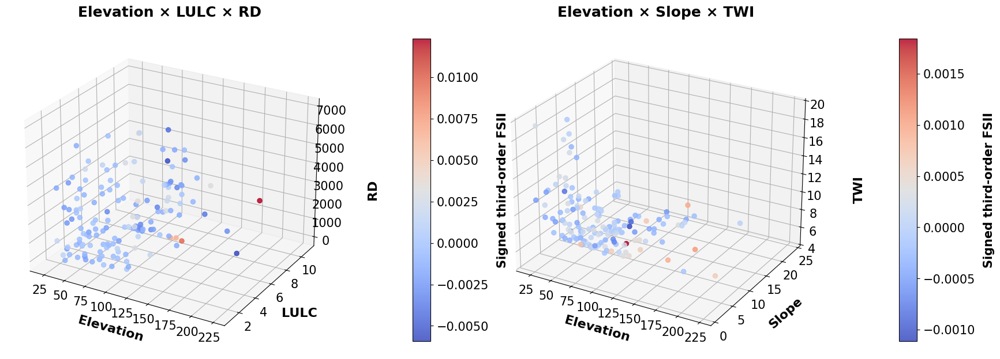

In [36]:
# =============================================================================
# CELL 30 - ELEVATION-CENTERED THIRD-ORDER FSII 3D DIAGNOSTICS
# =============================================================================
#
# PURPOSE
# -----------------------------------------------------------------------------
# Visualize signed third-order FSII interactions for:
#
#   1. Elevation × LULC × RD
#   2. Elevation × Slope × TWI
#
# Point coordinates represent the actual values of the three participating
# LCFs. Point color represents the signed third-order FSII contribution.
#
# FIGURE DESIGN
# -----------------------------------------------------------------------------
# - Minimum visible font size = 15 pt
# - Bold panel titles and axis labels
# - Native x-axis and y-axis labels retained
# - RD and TWI positioned OUTSIDE the projected 3D axes
# - Dedicated space between z-axis ticks and z-axis labels
# - Dedicated space between z-axis labels and colorbars
# - No label/tick/colorbar overlap
# - Compact landscape layout
#
# No FSII calculations are changed.
# =============================================================================


# =============================================================================
# 30.1 PUBLICATION FONT LOCKS
# =============================================================================

FSII3D_PANEL_TITLE_FS = 18
FSII3D_AXIS_LABEL_FS = 16
FSII3D_TICK_FS = 15
FSII3D_COLORBAR_LABEL_FS = 15
FSII3D_COLORBAR_TICK_FS = 15


# =============================================================================
# 30.2 THIRD-ORDER INTERACTION SPECS
# =============================================================================

TRIPLE_SPECS = [
    (
        "Elevation",
        "LULC",
        "Road_Distance",
    ),
    (
        "Elevation",
        "Slope",
        "TWI",
    ),
]


# =============================================================================
# 30.3 EVALUATION LCF VALUES
# =============================================================================

evaluation_features = (
    XAI_EVAL_DF[
        FINAL_CONCEPTUAL_FEATURES
    ]
    .reset_index(
        drop=True
    )
)


# =============================================================================
# 30.4 HELPER - RETRIEVE THIRD-ORDER FSII VALUES
# =============================================================================

def triple_fsii_values(
    feature_a,
    feature_b,
    feature_c,
):

    wanted = {
        feature_a,
        feature_b,
        feature_c,
    }

    subset = fsii_long_df[
        fsii_long_df[
            "Order"
        ]
        ==
        3
    ].copy()

    subset = subset[
        subset[
            "Interaction"
        ].map(
            lambda label:
                set(
                    label.split(
                        " × "
                    )
                )
                ==
                wanted
        )
    ].sort_values(
        "Observation_Index"
    )

    if len(
        subset
    ) != len(
        evaluation_features
    ):

        raise RuntimeError(
            "Missing third-order FSII values for "
            f"{feature_a} × {feature_b} × {feature_c}.\n"
            f"Expected {len(evaluation_features)} observations, "
            f"found {len(subset)}."
        )

    return subset[
        "Value"
    ].to_numpy(
        dtype="float64"
    )


# =============================================================================
# 30.5 CREATE FIGURE
# =============================================================================
#
# Manual axes positions are used because automatic 3D layout is unreliable
# when large axis labels and individual colorbars are combined.
#
# LEFT SIDE
#
#   3D plot        : x = 0.025 to 0.355
#   z-axis label   : around x = 0.395
#   colorbar       : around x = 0.435
#
# RIGHT SIDE
#
#   3D plot        : x = 0.515 to 0.845
#   z-axis label   : around x = 0.885
#   colorbar       : around x = 0.925
#
# Therefore the z labels cannot sit on the z tick numbers or colorbars.
# =============================================================================

fig = plt.figure(
    figsize=(
        17.2,
        7.5,
    )
)


# =============================================================================
# 30.6 FIXED 3D AXES
# =============================================================================

ax_left = fig.add_axes(
    [
        0.025,   # left
        0.105,   # bottom
        0.330,   # width
        0.800,   # height
    ],
    projection="3d",
)


ax_right = fig.add_axes(
    [
        0.515,
        0.105,
        0.330,
        0.800,
    ],
    projection="3d",
)


axes_3d = [
    ax_left,
    ax_right,
]


# =============================================================================
# 30.7 FIXED COLORBAR AXES
# =============================================================================

cax_left = fig.add_axes(
    [
        0.435,
        0.155,
        0.018,
        0.700,
    ]
)


cax_right = fig.add_axes(
    [
        0.925,
        0.155,
        0.018,
        0.700,
    ]
)


colorbar_axes = [
    cax_left,
    cax_right,
]


# =============================================================================
# 30.8 FIXED Z-AXIS LABEL POSITIONS
# =============================================================================
#
# These labels are figure-level text, not projected 3D-axis labels.
#
# This completely removes Matplotlib's 3D z-label positioning problem.
# =============================================================================

Z_LABEL_POSITIONS = [
    (
        0.395,
        0.505,
    ),
    (
        0.885,
        0.505,
    ),
]


# =============================================================================
# 30.9 DRAW THIRD-ORDER FSII PANELS
# =============================================================================

for panel_index, (
    ax,
    cax,
    (
        feature_a,
        feature_b,
        feature_c,
    ),
) in enumerate(
    zip(
        axes_3d,
        colorbar_axes,
        TRIPLE_SPECS,
    )
):

    # -------------------------------------------------------------------------
    # Actual LCF values
    # -------------------------------------------------------------------------

    x = evaluation_features[
        feature_a
    ].to_numpy(
        dtype="float64"
    )

    y = evaluation_features[
        feature_b
    ].to_numpy(
        dtype="float64"
    )

    z = evaluation_features[
        feature_c
    ].to_numpy(
        dtype="float64"
    )


    # -------------------------------------------------------------------------
    # Third-order FSII
    # -------------------------------------------------------------------------

    values = triple_fsii_values(
        feature_a,
        feature_b,
        feature_c,
    )


    # =========================================================================
    # 30.10 3D SCATTER
    # =========================================================================

    artist = ax.scatter(
        x,
        y,
        z,
        c=values,
        cmap="coolwarm",
        s=34,
        alpha=0.85,
        depthshade=True,
    )


    # =========================================================================
    # 30.11 X-AXIS LABEL
    # =========================================================================

    ax.set_xlabel(
        PREDICTOR_ABBR[
            feature_a
        ],
        fontsize=FSII3D_AXIS_LABEL_FS,
        fontweight="bold",
        labelpad=8,
    )


    # =========================================================================
    # 30.12 Y-AXIS LABEL
    # =========================================================================
    #
    # Keep native placement because LULC/Slope follow the projected y-axis
    # correctly and do not need manual relocation.
    # =========================================================================

    ax.set_ylabel(
        PREDICTOR_ABBR[
            feature_b
        ],
        fontsize=FSII3D_AXIS_LABEL_FS,
        fontweight="bold",
        labelpad=10,
    )


    # =========================================================================
    # 30.13 REMOVE NATIVE Z-AXIS LABEL
    # =========================================================================
    #
    # The native Matplotlib 3D z label is deliberately suppressed.
    # =========================================================================

    ax.set_zlabel(
        ""
    )


    # =========================================================================
    # 30.14 EXTERNAL Z-AXIS LABEL
    # =========================================================================

    z_label_x, z_label_y = Z_LABEL_POSITIONS[
        panel_index
    ]


    fig.text(
        z_label_x,
        z_label_y,
        PREDICTOR_ABBR[
            feature_c
        ],
        fontsize=FSII3D_AXIS_LABEL_FS,
        fontweight="bold",
        rotation=90,
        ha="center",
        va="center",
    )


    # =========================================================================
    # 30.15 PANEL TITLE
    # =========================================================================

    ax.set_title(
        (
            f"{PREDICTOR_ABBR[feature_a]} × "
            f"{PREDICTOR_ABBR[feature_b]} × "
            f"{PREDICTOR_ABBR[feature_c]}"
        ),
        fontsize=FSII3D_PANEL_TITLE_FS,
        fontweight="bold",
        pad=12,
    )


    # =========================================================================
    # 30.16 TICKS
    # =========================================================================

    ax.tick_params(
        axis="x",
        labelsize=FSII3D_TICK_FS,
        pad=1,
    )

    ax.tick_params(
        axis="y",
        labelsize=FSII3D_TICK_FS,
        pad=1,
    )

    ax.tick_params(
        axis="z",
        labelsize=FSII3D_TICK_FS,
        pad=1,
    )


    # =========================================================================
    # 30.17 VIEW
    # =========================================================================

    ax.view_init(
        elev=25,
        azim=-60,
    )


    # =========================================================================
    # 30.18 BOX ASPECT
    # =========================================================================

    ax.set_box_aspect(
        (
            1.15,
            1.00,
            0.85,
        )
    )


    # =========================================================================
    # 30.19 COLORBAR
    # =========================================================================

    colorbar = fig.colorbar(
        artist,
        cax=cax,
    )

    colorbar.set_label(
        "Signed third-order FSII",
        fontsize=FSII3D_COLORBAR_LABEL_FS,
        fontweight="bold",
        labelpad=10,
    )

    colorbar.ax.tick_params(
        labelsize=FSII3D_COLORBAR_TICK_FS,
        pad=4,
    )


# =============================================================================
# 30.20 SAVE PUBLICATION FIGURE
# =============================================================================

save_figure(
    fig,
    NB2_DIRS[
        "figures"
    ]
    /
    "Elevation_ThirdOrder_FSII_3D.png",
)

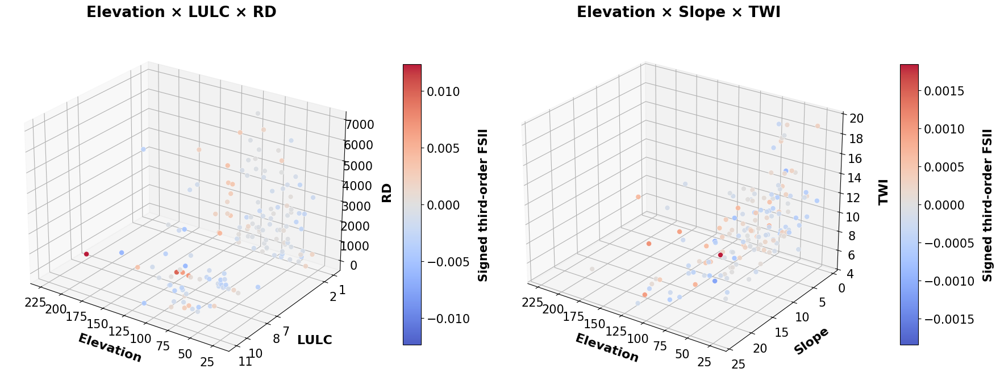

CELL 30A COMPLETE
Original Cell 30 figure retained:
   /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/15_Figures/Elevation_ThirdOrder_FSII_3D.png

New visual saved as:
   /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/15_Figures/Elevation_ThirdOrder_FSII_3D_new_visual.png


In [37]:
# =============================================================================
# CELL 30A - ELEVATION-CENTERED THIRD-ORDER FSII 3D DIAGNOSTICS
#            ALTERNATIVE PUBLICATION VISUAL
# =============================================================================
#
# PURPOSE
# -----------------------------------------------------------------------------
# Produce an alternative publication-quality visualization of the two retained
# third-order FSII interactions without modifying or overwriting Cell 30:
#
#   1. Elevation × LULC × RD
#   2. Elevation × Slope × TWI
#
# The three participating LCFs occupy the X, Y, and Z axes.
# Signed third-order FSII is represented by point color.
#
# IMPORTANT
# -----------------------------------------------------------------------------
# This is an alternative VISUALIZATION ONLY.
#
# No FSII values are recomputed.
# No interaction rankings are changed.
# No existing Cell 30 output is overwritten.
#
# NEW OUTPUT FILE
# -----------------------------------------------------------------------------
# Original:
#
#     Elevation_ThirdOrder_FSII_3D.png
#
# New Cell 30A:
#
#     Elevation_ThirdOrder_FSII_3D_new_visual.png
#
# FIGURE DESIGN
# -----------------------------------------------------------------------------
# - One landscape figure
# - Two large 3D panels
# - Minimum visible font size = 15 pt
# - Bold titles and axis labels
# - Diverging FSII color scale centered exactly at zero
# - Dedicated colorbar for each panel
# - Viewing angle selected to improve axis-label separation
# - LULC retained as a discrete categorical axis
# - Continuous Elevation × Slope × TWI represented as true 3D predictor space
# =============================================================================


# =============================================================================
# 30A.1 IMPORTS
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import TwoSlopeNorm


# =============================================================================
# 30A.2 PUBLICATION FONT LOCKS
# =============================================================================

FSII3D_TITLE_FS = 19
FSII3D_AXIS_FS = 16
FSII3D_TICK_FS = 15
FSII3D_CBAR_LABEL_FS = 15
FSII3D_CBAR_TICK_FS = 15


# =============================================================================
# 30A.3 THIRD-ORDER INTERACTION SPECS
# =============================================================================

TRIPLE_SPECS_NEW_VISUAL = [
    (
        "Elevation",
        "LULC",
        "Road_Distance",
    ),
    (
        "Elevation",
        "Slope",
        "TWI",
    ),
]


# =============================================================================
# 30A.4 EVALUATION LCF VALUES
# =============================================================================
#
# Restore here if the variable is not already available from Cell 29/30.
# =============================================================================

evaluation_features_new_visual = (
    XAI_EVAL_DF[
        FINAL_CONCEPTUAL_FEATURES
    ]
    .reset_index(
        drop=True
    )
)


# =============================================================================
# 30A.5 HELPER - RETRIEVE THIRD-ORDER FSII VALUES
# =============================================================================

def triple_fsii_values_new_visual(
    feature_a,
    feature_b,
    feature_c,
):

    wanted = {
        feature_a,
        feature_b,
        feature_c,
    }


    subset = fsii_long_df[
        fsii_long_df[
            "Order"
        ]
        ==
        3
    ].copy()


    subset = subset[
        subset[
            "Interaction"
        ].map(
            lambda label:
                set(
                    str(
                        label
                    ).split(
                        " × "
                    )
                )
                ==
                wanted
        )
    ].sort_values(
        "Observation_Index"
    )


    if len(
        subset
    ) != len(
        evaluation_features_new_visual
    ):

        raise RuntimeError(
            "Missing third-order FSII values for "
            f"{feature_a} × {feature_b} × {feature_c}.\n"
            f"Expected {len(evaluation_features_new_visual)} observations, "
            f"found {len(subset)}."
        )


    values = subset[
        "Value"
    ].to_numpy(
        dtype="float64"
    )


    if not np.isfinite(
        values
    ).all():

        raise RuntimeError(
            "Non-finite third-order FSII values detected for "
            f"{feature_a} × {feature_b} × {feature_c}."
        )


    return values


# =============================================================================
# 30A.6 CREATE LANDSCAPE FIGURE
# =============================================================================
#
# Manual figure regions are used so the 3D panels and colorbars remain
# independent and do not compete for space.
# =============================================================================

fig = plt.figure(
    figsize=(
        17.5,
        7.6,
    )
)


# =============================================================================
# 30A.7 LEFT 3D PANEL
# =============================================================================

ax_left = fig.add_axes(
    [
        0.025,
        0.095,
        0.365,
        0.815,
    ],
    projection="3d",
)


# =============================================================================
# 30A.8 LEFT COLORBAR
# =============================================================================

cax_left = fig.add_axes(
    [
        0.430,
        0.175,
        0.018,
        0.650,
    ]
)


# =============================================================================
# 30A.9 RIGHT 3D PANEL
# =============================================================================

ax_right = fig.add_axes(
    [
        0.525,
        0.095,
        0.365,
        0.815,
    ],
    projection="3d",
)


# =============================================================================
# 30A.10 RIGHT COLORBAR
# =============================================================================

cax_right = fig.add_axes(
    [
        0.930,
        0.175,
        0.018,
        0.650,
    ]
)


axes_3d_new_visual = [
    ax_left,
    ax_right,
]


colorbar_axes_new_visual = [
    cax_left,
    cax_right,
]


# =============================================================================
# 30A.11 DRAW BOTH THIRD-ORDER FSII INTERACTIONS
# =============================================================================

for panel_index, (
    ax,
    cax,
    (
        feature_a,
        feature_b,
        feature_c,
    ),
) in enumerate(
    zip(
        axes_3d_new_visual,
        colorbar_axes_new_visual,
        TRIPLE_SPECS_NEW_VISUAL,
    )
):

    # -------------------------------------------------------------------------
    # Actual LCF values
    # -------------------------------------------------------------------------

    x = evaluation_features_new_visual[
        feature_a
    ].to_numpy(
        dtype="float64"
    )


    y = evaluation_features_new_visual[
        feature_b
    ].to_numpy(
        dtype="float64"
    )


    z = evaluation_features_new_visual[
        feature_c
    ].to_numpy(
        dtype="float64"
    )


    # -------------------------------------------------------------------------
    # Signed third-order FSII
    # -------------------------------------------------------------------------

    values = triple_fsii_values_new_visual(
        feature_a,
        feature_b,
        feature_c,
    )


    # =========================================================================
    # 30A.12 VALID OBSERVATIONS
    # =========================================================================

    valid = (
        np.isfinite(
            x
        )
        &
        np.isfinite(
            y
        )
        &
        np.isfinite(
            z
        )
        &
        np.isfinite(
            values
        )
    )


    x_plot = x[
        valid
    ]


    y_plot = y[
        valid
    ]


    z_plot = z[
        valid
    ]


    fsii_plot = values[
        valid
    ]


    if len(
        x_plot
    ) == 0:

        raise RuntimeError(
            "No valid observations available for "
            f"{feature_a} × {feature_b} × {feature_c}."
        )


    # =========================================================================
    # 30A.13 SIGNED FSII NORMALIZATION
    # =========================================================================
    #
    # Symmetric limits preserve the meaning of the diverging color scale:
    #
    #   blue  = negative third-order interaction contribution
    #   white = approximately zero
    #   red   = positive third-order interaction contribution
    # =========================================================================

    max_abs_fsii = float(
        np.max(
            np.abs(
                fsii_plot
            )
        )
    )


    if max_abs_fsii <= 0:

        max_abs_fsii = 1e-12


    fsii_norm = TwoSlopeNorm(
        vmin=-max_abs_fsii,
        vcenter=0.0,
        vmax=max_abs_fsii,
    )


    # =========================================================================
    # 30A.14 3D SCATTER
    # =========================================================================

    artist = ax.scatter(
        x_plot,
        y_plot,
        z_plot,
        c=fsii_plot,
        cmap="coolwarm",
        norm=fsii_norm,
        s=42,
        alpha=0.90,
        edgecolors="white",
        linewidths=0.35,
        depthshade=True,
    )


    # =========================================================================
    # 30A.15 X-AXIS LABEL
    # =========================================================================

    ax.set_xlabel(
        PREDICTOR_ABBR[
            feature_a
        ],
        fontsize=FSII3D_AXIS_FS,
        fontweight="bold",
        labelpad=10,
    )


    # =========================================================================
    # 30A.16 Y-AXIS LABEL
    # =========================================================================

    ax.set_ylabel(
        PREDICTOR_ABBR[
            feature_b
        ],
        fontsize=FSII3D_AXIS_FS,
        fontweight="bold",
        labelpad=11,
    )


    # =========================================================================
    # 30A.17 Z-AXIS LABEL
    # =========================================================================

    ax.zaxis.set_rotate_label(
        False
    )


    ax.set_zlabel(
        PREDICTOR_ABBR[
            feature_c
        ],
        fontsize=FSII3D_AXIS_FS,
        fontweight="bold",
        rotation=90,
        labelpad=12,
    )


    ax.zaxis.label.set_rotation(
        90
    )


    # =========================================================================
    # 30A.18 PANEL TITLE
    # =========================================================================

    ax.set_title(
        (
            f"{PREDICTOR_ABBR[feature_a]} × "
            f"{PREDICTOR_ABBR[feature_b]} × "
            f"{PREDICTOR_ABBR[feature_c]}"
        ),
        fontsize=FSII3D_TITLE_FS,
        fontweight="bold",
        pad=14,
    )


    # =========================================================================
    # 30A.19 TICK LABELS
    # =========================================================================

    ax.tick_params(
        axis="x",
        labelsize=FSII3D_TICK_FS,
        pad=2,
    )


    ax.tick_params(
        axis="y",
        labelsize=FSII3D_TICK_FS,
        pad=2,
    )


    ax.tick_params(
        axis="z",
        labelsize=FSII3D_TICK_FS,
        pad=2,
    )


    # =========================================================================
    # 30A.20 LULC CATEGORICAL AXIS
    # =========================================================================
    #
    # LULC is nominal and remains discrete.
    # Only observed category codes are shown.
    # =========================================================================

    if feature_b == "LULC":

        lulc_codes = np.unique(
            y_plot
        )


        if len(
            lulc_codes
        ) <= 15:

            ax.set_yticks(
                lulc_codes
            )


            ax.set_yticklabels(
                [
                    f"{code:g}"
                    for code in lulc_codes
                ],
                fontsize=FSII3D_TICK_FS,
            )


    # =========================================================================
    # 30A.21 VIEW ANGLE
    # =========================================================================
    #
    # The revised view places the projected z-axis away from the right-hand
    # colorbar, improving visibility of RD and TWI.
    # =========================================================================

    ax.view_init(
        elev=25,
        azim=125,
    )


    # =========================================================================
    # 30A.22 3D BOX PROPORTIONS
    # =========================================================================

    ax.set_box_aspect(
        (
            1.18,
            1.00,
            0.86,
        )
    )


    # =========================================================================
    # 30A.23 COLORBAR
    # =========================================================================

    colorbar = fig.colorbar(
        artist,
        cax=cax,
    )


    colorbar.set_label(
        "Signed third-order FSII",
        fontsize=FSII3D_CBAR_LABEL_FS,
        fontweight="bold",
        labelpad=10,
    )


    colorbar.ax.tick_params(
        labelsize=FSII3D_CBAR_TICK_FS,
        pad=4,
    )


# =============================================================================
# 30A.24 NEW OUTPUT PATH
# =============================================================================
#
# Original Cell 30 output:
#
#     Elevation_ThirdOrder_FSII_3D.png
#
# Cell 30A output:
#
#     Elevation_ThirdOrder_FSII_3D_new_visual.png
# =============================================================================

CELL30A_OUTPUT = (
    NB2_DIRS[
        "figures"
    ]
    /
    "Elevation_ThirdOrder_FSII_3D_new_visual.png"
)


# =============================================================================
# 30A.25 SAVE WITHOUT OVERWRITING CELL 30
# =============================================================================

save_figure(
    fig,
    CELL30A_OUTPUT,
)


# =============================================================================
# 30A.26 REPORT
# =============================================================================

print(
    "=" * 100
)

print(
    "CELL 30A COMPLETE"
)

print(
    "=" * 100
)

print(
    "Original Cell 30 figure retained:"
)

print(
    "  ",
    NB2_DIRS[
        "figures"
    ]
    /
    "Elevation_ThirdOrder_FSII_3D.png"
)

print()

print(
    "New visual saved as:"
)

print(
    "  ",
    CELL30A_OUTPUT
)

print(
    "=" * 100
)

Coalition/Owen:   0%|          | 0/150 [00:00<?, ?it/s]

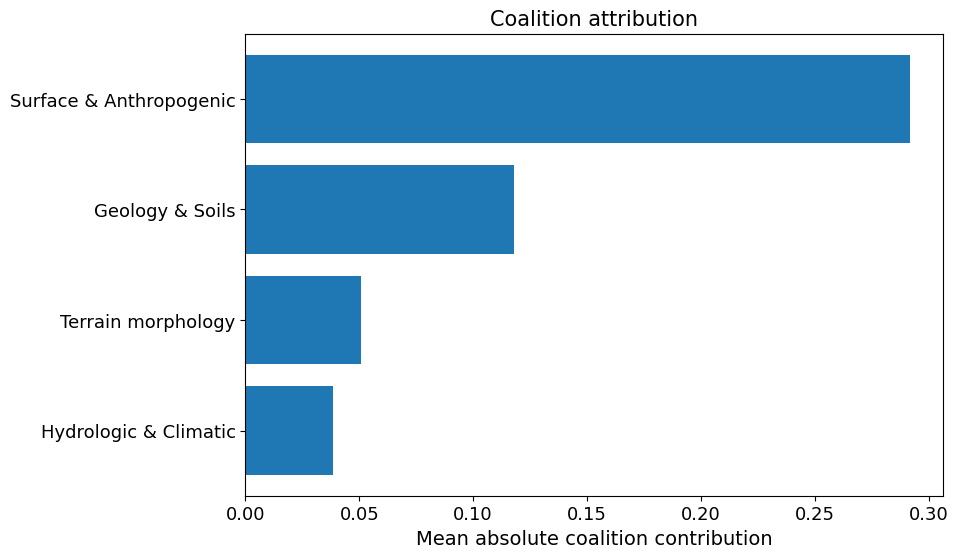

,Coalition,Mean_Abs_Contribution,Mean_Signed_Contribution
2,Surface & Anthropogenic,0.291765,-0.244632
0,Geology & Soils,0.117990,-0.085482
3,Terrain morphology,0.050762,-0.034299
1,Hydrologic & Climatic,0.038474,-0.032292


In [38]:
# =============================================================================
# CELL 31 - EXACT FOUR-COALITION OWEN-STYLE GROUPED ATTRIBUTION
# HEAVY / PER-OBSERVATION RESUME-SAFE
# =============================================================================
#
# With exactly four locked scientific groups, all 4! group orderings are
# enumerated. Contributions are averaged over a fixed interventional
# background. This is reported as Owen-style scientific coalition attribution.
# =============================================================================

OWEN_OBS_DIR = (
    NB2_DIRS["owen"]
    / "observations"
)

OWEN_OBS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OWEN_LONG_CSV = (
    NB2_DIRS["owen"]
    / "Coalition_Attributions_Long.csv"
)

OWEN_STATE = (
    NB2_DIRS["checkpoints"]
    / "Coalition_Owen.state.json"
)

coalition_names = list(
    COALITIONS.keys()
)

coalition_indices = {
    group: [
        FINAL_CONCEPTUAL_FEATURES.index(
            feature
        )
        for feature
        in features
    ]
    for group, features
    in COALITIONS.items()
}

owen_background = (
    X_background_numeric
    .iloc[
        :min(
            OWEN_BACKGROUND_N,
            len(
                X_background_numeric
            ),
        )
    ]
    .to_numpy(dtype="float64")
)

owen_evaluation = (
    X_evaluation_numeric
    .to_numpy(dtype="float64")
)

OWEN_SIGNATURE = stable_signature(
    {
        "stage":
            "coalition_owen",
        "model":
            BEST_XAI_MODEL,
        "bundle_signature":
            BEST_XAI_BUNDLE[
                "signature"
            ],
        "xai_sample_hash":
            XAI_SAMPLE_HASH,
        "coalitions":
            COALITIONS,
        "background_n":
            len(
                owen_background
            ),
        "permutations":
            math.factorial(
                len(
                    coalition_names
                )
            ),
    }
)

def exact_group_shapley_one(
    x,
    background,
):
    permutations = list(
        itertools.permutations(
            range(
                len(
                    coalition_names
                )
            )
        )
    )

    contribution = np.zeros(
        len(
            coalition_names
        ),
        dtype="float64",
    )

    all_states = []
    metadata = []

    for background_row in background:
        for permutation in permutations:
            current = background_row.copy()

            states = [
                current.copy()
            ]

            for group_index in permutation:
                group_name = coalition_names[
                    group_index
                ]

                feature_indices = coalition_indices[
                    group_name
                ]

                current = current.copy()

                current[
                    feature_indices
                ] = x[
                    feature_indices
                ]

                states.append(
                    current.copy()
                )

            start_index = len(
                all_states
            )

            all_states.extend(
                states
            )

            metadata.append(
                (
                    permutation,
                    start_index,
                )
            )

    predictions = calibrated_conceptual_probability(
        np.asarray(
            all_states,
            dtype="float64",
        )
    )

    for permutation, start_index in metadata:
        state_predictions = predictions[
            start_index:
            start_index
            +
            len(
                coalition_names
            )
            +
            1
        ]

        for step, group_index in enumerate(
            permutation
        ):
            contribution[
                group_index
            ] += (
                state_predictions[
                    step
                    +
                    1
                ]
                -
                state_predictions[
                    step
                ]
            )

    denominator = (
        len(
            background
        )
        *
        len(
            permutations
        )
    )

    return (
        contribution
        /
        float(
            denominator
        )
    )

for observation_index in tqdm(
    range(
        len(
            owen_evaluation
        )
    ),
    desc="Coalition/Owen",
):
    output_file = (
        OWEN_OBS_DIR
        /
        f"obs_{observation_index:04d}.npz"
    )

    if output_file.exists():
        try:
            old = np.load(
                output_file
            )

            if old[
                "signature"
            ].item() == OWEN_SIGNATURE:
                continue

        except Exception:
            output_file.unlink(
                missing_ok=True
            )

    values = exact_group_shapley_one(
        owen_evaluation[
            observation_index
        ],
        owen_background,
    )

    tmp = (
        output_file.parent
        /
        f".{output_file.name}.tmp.npz"
    )

    np.savez_compressed(
        tmp,
        signature=
            np.array(
                OWEN_SIGNATURE
            ),
        values=
            values,
    )

    os.replace(
        tmp,
        output_file,
    )

atomic_json(
    {
        "Status": "COMPLETE",
        "Signature":
            OWEN_SIGNATURE,
        "Method":
            (
                "Exact four-group permutation Shapley averaged "
                "over interventional background"
            ),
        "Coalitions":
            COALITIONS,
        "Observations":
            len(
                owen_evaluation
            ),
        "Completed_UTC":
            pd.Timestamp.utcnow().isoformat(),
    },
    OWEN_STATE,
)

owen_rows = []

for observation_index in range(
    len(
        owen_evaluation
    )
):
    saved = np.load(
        OWEN_OBS_DIR
        /
        f"obs_{observation_index:04d}.npz"
    )

    values = saved[
        "values"
    ]

    for group_index, group_name in enumerate(
        coalition_names
    ):
        value = float(
            values[
                group_index
            ]
        )

        owen_rows.append(
            {
                "Observation_Index":
                    observation_index,
                "Sample_ID":
                    XAI_EVAL_DF.loc[
                        observation_index,
                        "Sample_ID",
                    ],
                "Coalition":
                    group_name,
                "Value":
                    value,
                "Abs_Value":
                    abs(
                        value
                    ),
            }
        )

owen_long_df = pd.DataFrame(
    owen_rows
)

atomic_csv(
    owen_long_df,
    OWEN_LONG_CSV,
)

owen_summary = (
    owen_long_df
    .groupby(
        "Coalition",
        as_index=False,
    )
    .agg(
        Mean_Abs_Contribution=(
            "Abs_Value",
            "mean",
        ),
        Mean_Signed_Contribution=(
            "Value",
            "mean",
        ),
    )
    .sort_values(
        "Mean_Abs_Contribution",
        ascending=False,
    )
)

atomic_csv(
    owen_summary,
    NB2_DIRS["tables"]
    / "Coalition_Owen_Global_Summary.csv",
)

fig, ax = plt.subplots(
    figsize=(
        9,
        6,
    )
)

plot_df = (
    owen_summary
    .sort_values(
        "Mean_Abs_Contribution",
        ascending=True,
    )
)

ax.barh(
    plot_df[
        "Coalition"
    ],
    plot_df[
        "Mean_Abs_Contribution"
    ],
)

ax.set_xlabel(
    "Mean absolute coalition contribution",
    fontsize=FONT_LABEL,
)

ax.tick_params(
    labelsize=FONT_BASE
)

ax.set_title(
    "Coalition attribution",
    fontsize=FONT_TITLE,
)

save_figure(
    fig,
    NB2_DIRS["figures"]
    / "Coalition_Owen_Global_Importance.png",
)

display(
    owen_summary
)

In [39]:
# =============================================================================
# CELL 32 - GEOSHAPLEY XAI-ONLY SPATIALLY AUGMENTED MODEL
# HEAVY / RESUME-SAFE
# =============================================================================
#
# Easting and Northing are added only for GeoShapley.
# This spatially augmented model is not used for the final susceptibility map.
# The same best individual model family and final tuned hyperparameters are used.
# =============================================================================

GEO_BUNDLE_FILE = (
    NB2_DIRS["geoshapley"]
    / "GeoShapley_XAI_Only_Calibrated_Bundle.joblib"
)

GEO_BUNDLE_STATE = (
    NB2_DIRS["checkpoints"]
    / "GeoShapley_XAI_Model.state.json"
)

best_xai_params = read_json(
    OPTUNA_BEST_DIR
    /
    f"{BEST_XAI_MODEL}_Final_best.json"
)[
    "Best_Params"
]

GEO_BUNDLE_SIGNATURE = stable_signature(
    {
        "stage":
            "geoshapley_xai_only_spatial_model",
        "best_model_family":
            BEST_XAI_MODEL,
        "base_bundle_signature":
            BEST_XAI_BUNDLE[
                "signature"
            ],
        "same_hyperparameters":
            best_xai_params,
        "sample_hash":
            FINAL_SAMPLE_HASH,
        "spatial_auxiliary_players":
            [
                "Easting",
                "Northing",
            ],
        "not_used_for_susceptibility_mapping":
            True,
    }
)

if state_matches(
    GEO_BUNDLE_STATE,
    GEO_BUNDLE_SIGNATURE,
    [
        GEO_BUNDLE_FILE
    ],
):
    GEO_BUNDLE = joblib.load(
        GEO_BUNDLE_FILE
    )

    print(
        "✓ RESTORE: GeoShapley XAI-only model bundle."
    )

else:
    y = final_model_df[
        "Class"
    ].to_numpy(dtype=int)

    X_geo_all = build_conceptual_frame(
        final_model_df,
        rainfall_column=
            "Rainfall",
        include_geo=
            True,
    )

    raw_oof = np.full(
        len(
            final_model_df
        ),
        np.nan,
        dtype="float64",
    )

    for fold in range(
        OUTER_FOLDS
    ):
        train_mask = (
            spatial_df[
                "Outer_Fold"
            ].to_numpy(dtype=int)
            !=
            fold
        )

        valid_mask = (
            ~train_mask
        )

        model = fit_raw_model(
            BEST_XAI_MODEL,
            best_xai_params,
            X_geo_all.loc[
                train_mask
            ],
            y[
                train_mask
            ],
            include_geo=
                True,
        )

        raw_oof[
            valid_mask
        ] = raw_model_score(
            BEST_XAI_MODEL,
            model,
            X_geo_all.loc[
                valid_mask
            ],
            include_geo=
                True,
        )

        del model
        gc.collect()

    calibrator = fit_platt(
        raw_oof,
        y,
    )

    geo_model = fit_raw_model(
        BEST_XAI_MODEL,
        best_xai_params,
        X_geo_all,
        y,
        include_geo=
            True,
    )

    GEO_BUNDLE = {
        "model_name":
            BEST_XAI_MODEL,
        "params":
            best_xai_params,
        "model":
            geo_model,
        "calibrator":
            calibrator,
        "rainfall":
            SELECTED_RAINFALL,
        "conceptual_features":
            (
                FINAL_CONCEPTUAL_FEATURES
                +
                [
                    "Easting",
                    "Northing",
                ]
            ),
        "include_geo":
            True,
        "signature":
            GEO_BUNDLE_SIGNATURE,
        "role":
            "XAI-only spatially augmented GeoShapley model",
    }

    atomic_joblib(
        GEO_BUNDLE,
        GEO_BUNDLE_FILE,
    )

    atomic_json(
        {
            "Status": "COMPLETE",
            "Signature":
                GEO_BUNDLE_SIGNATURE,
            "Model_Family":
                BEST_XAI_MODEL,
            "Auxiliary_GEO_Players":
                [
                    "Easting",
                    "Northing",
                ],
            "Used_For_Final_Susceptibility":
                False,
            "Bundle":
                str(
                    GEO_BUNDLE_FILE
                ),
            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        GEO_BUNDLE_STATE,
    )

print(
    "GeoShapley XAI-only model ready."
)

✓ RESTORE: GeoShapley XAI-only model bundle.
GeoShapley XAI-only model ready.


In [40]:
# =============================================================================
# CELL 33 - 300 m GEOSHAPLEY LATTICE AND RESUME-SAFE EXPLANATION BATCHES
# HEAVY / BATCH-RESUME-SAFE / ISOLATED FROM PREVIOUS 90 m RUN
# =============================================================================
#
# PURPOSE
# -----------------------------------------------------------------------------
# Compute GeoShapley explanations across a regular 300 m TNMA spatial-XAI
# lattice using the calibrated probability wrapper of the selected individual
# model.
#
# IMPORTANT CHANGE FROM PREVIOUS CELL 33
# -----------------------------------------------------------------------------
# SCIENTIFIC MODEL
# -----------------------------------------------------------------------------
# The final susceptibility model remains unchanged:
#
#       14 retained LCFs
#
#       Elevation
#       Slope
#       Aspect
#       PC
#       TPI
#       TWI
#       SPI
#       Rainfall
#       LULC
#       NDVI
#       RD
#       Lithology
#       FD
#       ST
#
# Easting and Northing are auxiliary geographic players used ONLY for
# GeoShapley spatial explanation.
#
#
# OUTPUTS FOR EACH 300 m LATTICE LOCATION
# -----------------------------------------------------------------------------
#
#   1. Primary GeoShapley contribution for each retained LCF.
#
#   2. Intrinsic geographic contribution:
#
#          Intrinsic_GEO
#
#   3. Geographic interaction contribution for every retained LCF:
#
#          GeoInteraction__Elevation
#          GeoInteraction__Slope
#          ...
#          GeoInteraction__ST
#
#
# DIRECT GEOSHAPLEY OUTPUT
# -----------------------------------------------------------------------------
#
#     result.primary
#     result.geo
#     result.geo_intera
#
# get_svc() is NOT used.
#
# =============================================================================


# =============================================================================
# 33.1 IMPORTS
# =============================================================================

from geoshapley import GeoShapleyExplainer

import gc
import hashlib
import math
import os
import pickle

import numpy as np
import pandas as pd
import rasterio

from pathlib import Path
from rasterio.transform import xy
from tqdm.auto import tqdm


# =============================================================================
# 33.2 LOCK 300 m GEOSHAPLEY DESIGN
# =============================================================================

GEOSHAPLEY_LATTICE_M_300 = 300.0


if not np.isclose(
    TARGET_RES,
    30.0,
    atol=1e-9,
):

    raise RuntimeError(
        "The revised 300 m GeoShapley lattice assumes the locked "
        f"30 m computational grid. TARGET_RES = {TARGET_RES}"
    )


GEO300_LATTICE_STEP = int(
    round(
        GEOSHAPLEY_LATTICE_M_300
        /
        TARGET_RES
    )
)


if GEO300_LATTICE_STEP != 10:

    raise RuntimeError(
        "Unexpected 300 m lattice step.\n"
        f"300 m / {TARGET_RES} m = {GEO300_LATTICE_STEP}"
    )


# =============================================================================
# 33.3 300 m OUTPUT ROOT
# =============================================================================
#
# COMPLETELY SEPARATE FROM THE OLD 90 m OUTPUTS.
# =============================================================================

GEO300_ROOT = (
    NB2_DIRS[
        "geoshapley"
    ]
    /
    "GeoShapley_300m"
)


GEO300_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


GEO300_LATTICE_FILE = (
    GEO300_ROOT
    /
    "GeoShapley_300m_Lattice.parquet"
)


GEO300_BATCH_DIR = (
    GEO300_ROOT
    /
    "batches_300m"
)


GEO300_BATCH_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


GEO300_STATE = (
    GEO300_ROOT
    /
    "GeoShapley_300m_Explanation.state.json"
)


GEO300_MANIFEST = (
    GEO300_ROOT
    /
    "GeoShapley_300m_Manifest.json"
)


# =============================================================================
# 33.4 LOCKED 14-LCF ABBREVIATIONS
# =============================================================================

GEO300_LCF_ABBR = {

    "Elevation":
        "Elevation",

    "Slope":
        "Slope",

    "Aspect":
        "Aspect",

    "Profile_Curvature":
        "PC",

    "TPI":
        "TPI",

    "TWI":
        "TWI",

    "SPI":
        "SPI",

    "Rainfall":
        "Rainfall",

    "LULC":
        "LULC",

    "NDVI":
        "NDVI",

    "Road_Distance":
        "RD",

    "Lithology":
        "Lithology",

    "Fault_Distance":
        "FD",

    "Soil_Type":
        "ST",
}


EXPECTED_FINAL_LCFS_300 = [

    "Elevation",
    "Slope",
    "Aspect",
    "Profile_Curvature",
    "TPI",
    "TWI",
    "SPI",
    "Rainfall",
    "LULC",
    "NDVI",
    "Road_Distance",
    "Lithology",
    "Fault_Distance",
    "Soil_Type",
]


if list(
    FINAL_CONCEPTUAL_FEATURES
) != EXPECTED_FINAL_LCFS_300:

    raise RuntimeError(
        "FINAL_CONCEPTUAL_FEATURES does not match the locked "
        "14-LCF framework.\n\n"
        f"Expected:\n{EXPECTED_FINAL_LCFS_300}\n\n"
        f"Found:\n{list(FINAL_CONCEPTUAL_FEATURES)}"
    )


if len(
    FINAL_CONCEPTUAL_FEATURES
) != 14:

    raise RuntimeError(
        "GeoShapley requires exactly 14 retained conceptual LCFs."
    )


# =============================================================================
# 33.5 300 m LATTICE OFFSET
# =============================================================================
#
# A 300 m spacing corresponds to every 10th 30 m computational cell.
#
# Because 10 is even, no 30 m cell center lies exactly at the geometric center
# of a 300 m block.
#
# We therefore use a consistent regular lattice:
#
#       row % 10 == 5
#       col % 10 == 5
#
# Consecutive selected cells remain exactly:
#
#       10 × 30 m = 300 m apart.
#
# The row/column remainder is recorded explicitly so the later 300 m
# GeoShapley rasterization stage can reproduce the correct spatial alignment.
# =============================================================================

GEO300_ROW_REMAINDER = (
    GEO300_LATTICE_STEP
    //
    2
)


GEO300_COL_REMAINDER = (
    GEO300_LATTICE_STEP
    //
    2
)


# =============================================================================
# 33.6 CREATE OR RESTORE 300 m LATTICE
# =============================================================================

if not GEO300_LATTICE_FILE.exists():

    all_rows, all_cols = np.where(
        MASTER_MASK
    )


    keep = (
        (
            all_rows
            %
            GEO300_LATTICE_STEP
        )
        ==
        GEO300_ROW_REMAINDER
    ) & (
        (
            all_cols
            %
            GEO300_LATTICE_STEP
        )
        ==
        GEO300_COL_REMAINDER
    )


    rows_300 = all_rows[
        keep
    ]


    cols_300 = all_cols[
        keep
    ]


    if len(
        rows_300
    ) == 0:

        raise RuntimeError(
            "The 300 m GeoShapley lattice contains no TNMA cells."
        )


    # -------------------------------------------------------------------------
    # Coordinates of the actual selected 30 m cell centers.
    # -------------------------------------------------------------------------

    eastings_300, northings_300 = xy(
        MASTER_TRANSFORM,
        rows_300,
        cols_300,
        offset="center",
    )


    geo300_lattice = pd.DataFrame(
        {
            "Lattice_ID":
                [
                    f"GEO300_{i+1:06d}"
                    for i in range(
                        len(
                            rows_300
                        )
                    )
                ],

            "Row":
                rows_300.astype(
                    int
                ),

            "Col":
                cols_300.astype(
                    int
                ),

            "Easting":
                np.asarray(
                    eastings_300,
                    dtype="float64",
                ),

            "Northing":
                np.asarray(
                    northings_300,
                    dtype="float64",
                ),
        }
    )


    # -------------------------------------------------------------------------
    # Sample all 14 retained LCF rasters at the 300 m lattice locations.
    # -------------------------------------------------------------------------

    for feature in FINAL_CONCEPTUAL_FEATURES:

        if feature not in FINAL_RASTER_PATHS:

            raise RuntimeError(
                "Missing final raster path for retained LCF:\n"
                f"{feature}"
            )


        raster_path = FINAL_RASTER_PATHS[
            feature
        ]


        with rasterio.open(
            raster_path
        ) as src:

            arr = src.read(
                1
            )


        geo300_lattice[
            feature
        ] = arr[
            rows_300,
            cols_300,
        ]


    atomic_parquet(
        geo300_lattice,
        GEO300_LATTICE_FILE,
    )


    print(
        "✓ CREATED: new 300 m GeoShapley lattice"
    )


else:

    geo300_lattice = pd.read_parquet(
        GEO300_LATTICE_FILE
    )


    print(
        "✓ RESTORE: existing 300 m GeoShapley lattice"
    )


# =============================================================================
# 33.7 HARD 300 m LATTICE VALIDATION
# =============================================================================

required_lattice_columns_300 = [

    "Lattice_ID",
    "Row",
    "Col",
    "Easting",
    "Northing",

    *FINAL_CONCEPTUAL_FEATURES,
]


missing_lattice_columns_300 = [

    column

    for column
    in required_lattice_columns_300

    if column not in geo300_lattice.columns
]


if missing_lattice_columns_300:

    raise RuntimeError(
        "300 m GeoShapley lattice is missing required columns:\n"
        f"{missing_lattice_columns_300}"
    )


if len(
    geo300_lattice
) == 0:

    raise RuntimeError(
        "300 m GeoShapley lattice is empty."
    )


if geo300_lattice[
    "Lattice_ID"
].duplicated().any():

    raise RuntimeError(
        "Duplicate 300 m GeoShapley Lattice_ID values detected."
    )


# =============================================================================
# 33.8 VALIDATE REGULAR 300 m SUBSAMPLING
# =============================================================================

if not np.all(
    (
        geo300_lattice[
            "Row"
        ].to_numpy(
            dtype=int
        )
        %
        GEO300_LATTICE_STEP
    )
    ==
    GEO300_ROW_REMAINDER
):

    raise RuntimeError(
        "300 m lattice row alignment is inconsistent."
    )


if not np.all(
    (
        geo300_lattice[
            "Col"
        ].to_numpy(
            dtype=int
        )
        %
        GEO300_LATTICE_STEP
    )
    ==
    GEO300_COL_REMAINDER
):

    raise RuntimeError(
        "300 m lattice column alignment is inconsistent."
    )


# =============================================================================
# 33.9 FINITE INPUT AUDIT
# =============================================================================

for feature in FINAL_CONCEPTUAL_FEATURES:

    values = pd.to_numeric(
        geo300_lattice[
            feature
        ],
        errors="raise",
    ).to_numpy(
        dtype="float64"
    )


    if not np.isfinite(
        values
    ).all():

        raise RuntimeError(
            "Non-finite 300 m GeoShapley lattice values detected for:\n"
            f"{feature}"
        )


for coordinate in [
    "Easting",
    "Northing",
]:

    values = geo300_lattice[
        coordinate
    ].to_numpy(
        dtype="float64"
    )


    if not np.isfinite(
        values
    ).all():

        raise RuntimeError(
            "Non-finite 300 m GeoShapley coordinates detected."
        )


# =============================================================================
# 33.10 300 m LATTICE HASH
# =============================================================================

GEO300_LATTICE_HASH = dataframe_hash(
    geo300_lattice,
    [
        "Lattice_ID",
        "Row",
        "Col",
        "Easting",
        "Northing",
        *FINAL_CONCEPTUAL_FEATURES,
    ],
)


# =============================================================================
# 33.11 GEOSHAPLEY BACKGROUND
# =============================================================================
#
# The background design is intentionally retained from the existing notebook.
# Only the spatial evaluation lattice is changed in this revision.
# =============================================================================

geo300_background_df = final_model_df.sample(
    n=min(
        SHAP_BACKGROUND_N,
        len(
            final_model_df
        ),
    ),
    random_state=RANDOM_SEED,
).copy()


geo300_background_conceptual = build_conceptual_frame(
    geo300_background_df,
    rainfall_column="Rainfall",
    include_geo=True,
)


# =============================================================================
# 33.12 GEOSHAPLEY FEATURE ORDER
# =============================================================================

GEO300_FEATURE_ORDER = (
    list(
        FINAL_CONCEPTUAL_FEATURES
    )
    +
    [
        "Easting",
        "Northing",
    ]
)


if GEO300_FEATURE_ORDER[
    -2:
] != [
    "Easting",
    "Northing",
]:

    raise RuntimeError(
        "GeoShapley spatial columns are not the final two columns."
    )


if len(
    GEO300_FEATURE_ORDER
) != 16:

    raise RuntimeError(
        "GeoShapley input should contain 14 LCFs plus "
        "Easting and Northing."
    )


# =============================================================================
# 33.13 CALIBRATED PROBABILITY WRAPPER
# =============================================================================

def geo300_probability_wrapper(
    array_like,
):

    # -------------------------------------------------------------------------
    # Accept either DataFrame or NumPy-like input because GeoShapley may call
    # the prediction function internally using arrays.
    # -------------------------------------------------------------------------

    if isinstance(
        array_like,
        pd.DataFrame,
    ):

        if set(
            GEO300_FEATURE_ORDER
        ).issubset(
            array_like.columns
        ):

            frame = array_like[
                GEO300_FEATURE_ORDER
            ].copy()


        else:

            array = array_like.to_numpy()


            if array.ndim == 1:

                array = array.reshape(
                    1,
                    -1,
                )


            if array.shape[
                1
            ] != len(
                GEO300_FEATURE_ORDER
            ):

                raise RuntimeError(
                    "GeoShapley probability wrapper received "
                    "an unexpected number of columns."
                )


            frame = pd.DataFrame(
                array,
                columns=GEO300_FEATURE_ORDER,
            )


    else:

        array = np.asarray(
            array_like
        )


        if array.ndim == 1:

            array = array.reshape(
                1,
                -1,
            )


        if array.ndim != 2:

            raise RuntimeError(
                "GeoShapley probability wrapper expects a "
                "one- or two-dimensional input."
            )


        if array.shape[
            1
        ] != len(
            GEO300_FEATURE_ORDER
        ):

            raise RuntimeError(
                "GeoShapley probability wrapper received "
                f"{array.shape[1]} columns but expected "
                f"{len(GEO300_FEATURE_ORDER)}."
            )


        frame = pd.DataFrame(
            array,
            columns=GEO300_FEATURE_ORDER,
        )


    probability = predict_bundle_probability(
        GEO_BUNDLE,
        frame,
    )


    probability = np.asarray(
        probability,
        dtype="float64",
    ).reshape(
        -1
    )


    if len(
        probability
    ) != len(
        frame
    ):

        raise RuntimeError(
            "GeoShapley probability wrapper returned an "
            "unexpected prediction length."
        )


    if not np.isfinite(
        probability
    ).all():

        raise RuntimeError(
            "GeoShapley probability wrapper produced "
            "non-finite probabilities."
        )


    return probability


# =============================================================================
# 33.14 BACKGROUND NUMPY ARRAY
# =============================================================================

geo300_background_np = (
    geo300_background_conceptual[
        GEO300_FEATURE_ORDER
    ]
    .to_numpy(
        dtype="float64"
    )
)


if geo300_background_np.ndim != 2:

    raise RuntimeError(
        "GeoShapley background must be two-dimensional."
    )


if geo300_background_np.shape[
    1
] != len(
    GEO300_FEATURE_ORDER
):

    raise RuntimeError(
        "GeoShapley background feature-count mismatch."
    )


if not np.isfinite(
    geo300_background_np
).all():

    raise RuntimeError(
        "GeoShapley background contains non-finite values."
    )


# =============================================================================
# 33.15 INITIALIZE 300 m GEOSHAPLEY EXPLAINER
# =============================================================================

geo300_explainer = GeoShapleyExplainer(
    geo300_probability_wrapper,
    geo300_background_np,
)


# =============================================================================
# 33.16 BACKGROUND HASH
# =============================================================================

GEO300_BACKGROUND_HASH = dataframe_hash(
    geo300_background_df,
    [
        "Sample_ID",
        *FINAL_CONCEPTUAL_FEATURES,
        "Easting",
        "Northing",
    ],
)


# =============================================================================
# 33.17 300 m SCIENTIFIC SIGNATURE
# =============================================================================
#
# This signature is intentionally incompatible with every 90 m result.
# =============================================================================

GEO300_SIGNATURE = stable_signature(
    {
        "stage":
            "geoshapley_300m_decomposition_v1",

        "bundle_signature":
            GEO_BUNDLE_SIGNATURE,

        "lattice_hash":
            GEO300_LATTICE_HASH,

        "lattice_spacing_m":
            GEOSHAPLEY_LATTICE_M_300,

        "master_resolution_m":
            TARGET_RES,

        "lattice_step_cells":
            GEO300_LATTICE_STEP,

        "row_remainder":
            GEO300_ROW_REMAINDER,

        "col_remainder":
            GEO300_COL_REMAINDER,

        "feature_order":
            GEO300_FEATURE_ORDER,

        "conceptual_lcf_count":
            len(
                FINAL_CONCEPTUAL_FEATURES
            ),

        "spatial_columns_last":
            [
                "Easting",
                "Northing",
            ],

        "background_hash":
            GEO300_BACKGROUND_HASH,

        "background_n":
            len(
                geo300_background_df
            ),

        "background_container":
            "numpy.ndarray",

        "explain_container":
            "pandas.DataFrame",

        "geographic_output":
            "direct_geo_and_geo_intera",

        "svc_used":
            False,

        "package_version":
            PACKAGE_VERSIONS.get(
                "geoshapley"
            ),
    }
)


# =============================================================================
# 33.18 NUMERIC BATCH HASH
# =============================================================================

def geo300_input_hash(
    frame,
):

    if not isinstance(
        frame,
        pd.DataFrame,
    ):

        raise TypeError(
            "geo300_input_hash requires a pandas DataFrame."
        )


    if list(
        frame.columns
    ) != GEO300_FEATURE_ORDER:

        raise RuntimeError(
            "300 m GeoShapley frame column-order mismatch."
        )


    array = np.ascontiguousarray(
        frame[
            GEO300_FEATURE_ORDER
        ].to_numpy(
            dtype="float64"
        )
    )


    digest = hashlib.sha256()


    digest.update(
        "|".join(
            GEO300_FEATURE_ORDER
        ).encode(
            "utf-8"
        )
    )


    digest.update(
        str(
            array.shape
        ).encode(
            "utf-8"
        )
    )


    digest.update(
        array.tobytes()
    )


    return digest.hexdigest()


# =============================================================================
# 33.19 VALIDATE RAW 300 m GEOSHAPLEY RESULT
# =============================================================================

def validate_geo300_raw_result(
    result,
    X_batch,
):

    required_attributes = [
        "primary",
        "geo",
        "geo_intera",
        "X_geo",
    ]


    for attribute in required_attributes:

        if not hasattr(
            result,
            attribute
        ):

            return (
                False,
                f"missing attribute: {attribute}",
            )


    result_X = result.X_geo


    if not isinstance(
        result_X,
        pd.DataFrame,
    ):

        return (
            False,
            "result.X_geo is not a DataFrame",
        )


    if list(
        result_X.columns
    ) != GEO300_FEATURE_ORDER:

        return (
            False,
            "result feature order differs",
        )


    if result_X.shape != X_batch.shape:

        return (
            False,
            "result input shape differs",
        )


    try:

        current_hash = geo300_input_hash(
            X_batch
        )


        result_hash = geo300_input_hash(
            result_X
        )


    except Exception as exc:

        return (
            False,
            f"input hash validation failed: {exc}",
        )


    if current_hash != result_hash:

        return (
            False,
            "result input values differ",
        )


    primary = np.asarray(
        result.primary,
        dtype="float64",
    )


    intrinsic_geo = np.asarray(
        result.geo,
        dtype="float64",
    ).reshape(
        -1
    )


    geo_interactions = np.asarray(
        result.geo_intera,
        dtype="float64",
    )


    expected_shape = (
        len(
            X_batch
        ),
        len(
            FINAL_CONCEPTUAL_FEATURES
        ),
    )


    if primary.shape != expected_shape:

        return (
            False,
            f"primary shape {primary.shape} != {expected_shape}",
        )


    if geo_interactions.shape != expected_shape:

        return (
            False,
            (
                f"geo_intera shape {geo_interactions.shape} "
                f"!= {expected_shape}"
            ),
        )


    if intrinsic_geo.shape != (
        len(
            X_batch
        ),
    ):

        return (
            False,
            "intrinsic GEO vector length differs",
        )


    if not np.isfinite(
        primary
    ).all():

        return (
            False,
            "non-finite primary effects",
        )


    if not np.isfinite(
        intrinsic_geo
    ).all():

        return (
            False,
            "non-finite intrinsic GEO effects",
        )


    if not np.isfinite(
        geo_interactions
    ).all():

        return (
            False,
            "non-finite geographic interactions",
        )


    return (
        True,
        "valid",
    )


# =============================================================================
# 33.20 BUILD 300 m COMPONENT TABLE
# =============================================================================

def build_geo300_component_table(
    result,
    batch,
):

    primary = np.asarray(
        result.primary,
        dtype="float64",
    )


    intrinsic_geo = np.asarray(
        result.geo,
        dtype="float64",
    ).reshape(
        -1
    )


    geo_interactions = np.asarray(
        result.geo_intera,
        dtype="float64",
    )


    number_of_rows = len(
        batch
    )


    expected_shape = (
        number_of_rows,
        len(
            FINAL_CONCEPTUAL_FEATURES
        ),
    )


    if primary.shape != expected_shape:

        raise RuntimeError(
            "Unexpected 300 m GeoShapley primary-effect shape:\n"
            f"{primary.shape}"
        )


    if geo_interactions.shape != expected_shape:

        raise RuntimeError(
            "Unexpected 300 m GeoShapley geographic-interaction shape:\n"
            f"{geo_interactions.shape}"
        )


    if intrinsic_geo.shape != (
        number_of_rows,
    ):

        raise RuntimeError(
            "Unexpected 300 m intrinsic GEO-effect shape."
        )


    components = pd.DataFrame(
        {
            "Lattice_ID":
                batch[
                    "Lattice_ID"
                ].to_numpy(),

            "Row":
                batch[
                    "Row"
                ].to_numpy(
                    dtype=int
                ),

            "Col":
                batch[
                    "Col"
                ].to_numpy(
                    dtype=int
                ),

            "Easting":
                batch[
                    "Easting"
                ].to_numpy(
                    dtype="float64"
                ),

            "Northing":
                batch[
                    "Northing"
                ].to_numpy(
                    dtype="float64"
                ),

            "Intrinsic_GEO":
                intrinsic_geo,
        }
    )


    for feature_index, feature in enumerate(
        FINAL_CONCEPTUAL_FEATURES
    ):

        abbreviation = GEO300_LCF_ABBR[
            feature
        ]


        components[
            f"Primary__{abbreviation}"
        ] = primary[
            :,
            feature_index
        ]


        components[
            f"GeoInteraction__{abbreviation}"
        ] = geo_interactions[
            :,
            feature_index
        ]


    return components


# =============================================================================
# 33.21 NUMBER OF 300 m BATCHES
# =============================================================================
#
# Retain the established 200-location batch size unless the notebook-wide
# setting has explicitly been changed.
# =============================================================================

GEO300_BATCH_SIZE = int(
    GEOSHAPLEY_BATCH_N
)


if GEO300_BATCH_SIZE < 1:

    raise RuntimeError(
        "Invalid GeoShapley batch size."
    )


GEO300_NUMBER_OF_BATCHES = math.ceil(
    len(
        geo300_lattice
    )
    /
    GEO300_BATCH_SIZE
)


if GEO300_NUMBER_OF_BATCHES < 1:

    raise RuntimeError(
        "300 m GeoShapley produced zero batches."
    )


# =============================================================================
# 33.22 REPORT BEFORE COMPUTATION
# =============================================================================

print()

print(
    "=" * 110
)

print(
    "300 m GEOSHAPLEY EXPLANATION"
)

print(
    "=" * 110
)

print(
    f"Lattice observations     : {len(geo300_lattice):,}"
)

print(
    f"Lattice spacing          : {GEOSHAPLEY_LATTICE_M_300:.0f} m"
)

print(
    f"Master resolution        : {TARGET_RES:.0f} m"
)

print(
    f"Lattice step             : every {GEO300_LATTICE_STEP} cells"
)

print(
    f"Row/column remainder     : {GEO300_ROW_REMAINDER}"
)

print(
    f"Batch size               : {GEO300_BATCH_SIZE:,}"
)

print(
    f"Number of batches        : {GEO300_NUMBER_OF_BATCHES:,}"
)

print(
    f"Conceptual LCFs          : {len(FINAL_CONCEPTUAL_FEATURES)}"
)

print(
    "Spatial columns          : Easting, Northing"
)

print(
    "explain() input          : pandas.DataFrame"
)

print(
    "Geographic interaction   : result.geo_intera"
)

print(
    "Intrinsic geography      : result.geo"
)

print(
    "get_svc()                : NOT USED"
)

print()

print(
    "300 m output root:"
)

print(
    " ",
    GEO300_ROOT
)

print()

print(
    "Old 90 m outputs         : IGNORED"
)

print(
    "=" * 110
)


# =============================================================================
# 33.23 OPTIONAL FINAL-STATE STATUS CHECK
# =============================================================================
#
# This is informational only.
# Even if the final state says COMPLETE, the batch-level loop below still
# validates every 300 m checkpoint before skipping it.
# =============================================================================

if GEO300_STATE.exists():

    try:

        existing_state = read_json(
            GEO300_STATE
        )


        if (
            existing_state.get(
                "Status"
            )
            ==
            "COMPLETE"
            and
            existing_state.get(
                "Signature"
            )
            ==
            GEO300_SIGNATURE
        ):

            print(
                "✓ RESTORE: matching COMPLETE 300 m state found."
            )

            print(
                "  Batch files will be validated and skipped."
            )


        else:

            print(
                "Existing 300 m state is stale or incomplete."
            )


    except Exception:

        print(
            "Existing 300 m state could not be validated; "
            "batch checkpoints will determine resume position."
        )


# =============================================================================
# 33.24 RESUME-SAFE 300 m BATCH LOOP
# =============================================================================

restored_complete_batches_300 = 0

restored_raw_results_300 = 0

newly_computed_results_300 = 0


for batch_index in tqdm(
    range(
        GEO300_NUMBER_OF_BATCHES
    ),
    desc="GeoShapley 300 m batches",
):

    start = (
        batch_index
        *
        GEO300_BATCH_SIZE
    )


    stop = min(
        (
            batch_index
            +
            1
        )
        *
        GEO300_BATCH_SIZE,
        len(
            geo300_lattice
        ),
    )


    # =========================================================================
    # 33.25 300 m BATCH PATHS
    # =========================================================================

    result_file = (
        GEO300_BATCH_DIR
        /
        f"batch_{batch_index:05d}_result.pkl"
    )


    components_file = (
        GEO300_BATCH_DIR
        /
        f"batch_{batch_index:05d}_components.parquet"
    )


    metadata_file = (
        GEO300_BATCH_DIR
        /
        f"batch_{batch_index:05d}.json"
    )


    # =========================================================================
    # 33.26 RESTORE FULLY COMPLETE 300 m BATCH
    # =========================================================================

    if (
        metadata_file.exists()
        and
        result_file.exists()
        and
        components_file.exists()
    ):

        try:

            metadata = read_json(
                metadata_file
            )


            if (
                metadata.get(
                    "Status"
                )
                ==
                "COMPLETE"
                and
                metadata.get(
                    "Signature"
                )
                ==
                GEO300_SIGNATURE
                and
                int(
                    metadata.get(
                        "Start",
                        -1,
                    )
                )
                ==
                start
                and
                int(
                    metadata.get(
                        "Stop",
                        -1,
                    )
                )
                ==
                stop
                and
                int(
                    metadata.get(
                        "Rows",
                        -1,
                    )
                )
                ==
                (
                    stop
                    -
                    start
                )
            ):

                # -------------------------------------------------------------
                # Lightweight component-table validation.
                # -------------------------------------------------------------

                component_check = pd.read_parquet(
                    components_file
                )


                if len(
                    component_check
                ) != (
                    stop
                    -
                    start
                ):

                    raise RuntimeError(
                        "Saved component row count mismatch."
                    )


                expected_columns = [

                    "Lattice_ID",
                    "Row",
                    "Col",
                    "Easting",
                    "Northing",
                    "Intrinsic_GEO",

                    *[
                        f"Primary__{GEO300_LCF_ABBR[feature]}"
                        for feature
                        in FINAL_CONCEPTUAL_FEATURES
                    ],

                    *[
                        f"GeoInteraction__{GEO300_LCF_ABBR[feature]}"
                        for feature
                        in FINAL_CONCEPTUAL_FEATURES
                    ],
                ]


                missing_columns = [

                    column
                    for column
                    in expected_columns
                    if column not in component_check.columns
                ]


                if missing_columns:

                    raise RuntimeError(
                        "Saved component table is missing columns:\n"
                        f"{missing_columns}"
                    )


                del component_check


                restored_complete_batches_300 += 1

                continue


        except Exception as exc:

            print(
                f"\nBatch {batch_index}: COMPLETE checkpoint "
                f"failed validation ({exc})."
            )

            print(
                "The batch will be recovered or recomputed."
            )


    # =========================================================================
    # 33.27 BUILD CURRENT 300 m BATCH
    # =========================================================================

    batch = geo300_lattice.iloc[
        start:stop
    ].copy()


    if len(
        batch
    ) == 0:

        raise RuntimeError(
            f"300 m GeoShapley batch {batch_index} is empty."
        )


    X_batch = batch[
        GEO300_FEATURE_ORDER
    ].copy()


    if not isinstance(
        X_batch,
        pd.DataFrame,
    ):

        raise RuntimeError(
            "GeoShapley explanation input must remain a pandas DataFrame."
        )


    if list(
        X_batch.columns
    ) != GEO300_FEATURE_ORDER:

        raise RuntimeError(
            "300 m GeoShapley batch feature-order mismatch."
        )


    if list(
        X_batch.columns[
            -2:
        ]
    ) != [
        "Easting",
        "Northing",
    ]:

        raise RuntimeError(
            "GeoShapley spatial variables are not the final two columns."
        )


    for column in GEO300_FEATURE_ORDER:

        X_batch[
            column
        ] = pd.to_numeric(
            X_batch[
                column
            ],
            errors="raise",
        )


    if not np.isfinite(
        X_batch.to_numpy(
            dtype="float64"
        )
    ).all():

        raise RuntimeError(
            f"300 m GeoShapley batch {batch_index} contains "
            "non-finite input values."
        )


    # =========================================================================
    # 33.28 RECOVER PARTIAL RAW RESULT IF AVAILABLE
    # =========================================================================
    #
    # If Colab stopped after explain() but before component extraction, the raw
    # result is validated against the EXACT current 300 m batch and reused.
    # =========================================================================

    result = None

    restored_raw = False


    if result_file.exists():

        try:

            with result_file.open(
                "rb"
            ) as file:

                candidate_result = pickle.load(
                    file
                )


            valid_result, validation_message = (
                validate_geo300_raw_result(
                    candidate_result,
                    X_batch,
                )
            )


            if valid_result:

                result = candidate_result

                restored_raw = True

                restored_raw_results_300 += 1


                print(
                    f"\n✓ RESTORE RAW: 300 m batch {batch_index}"
                )


            else:

                del candidate_result


                print(
                    f"\n300 m batch {batch_index}: existing raw "
                    f"result not reusable ({validation_message})."
                )


        except Exception as exc:

            print(
                f"\n300 m batch {batch_index}: raw-result restore "
                f"failed ({exc})."
            )


    # =========================================================================
    # 33.29 COMPUTE ONLY WHEN REQUIRED
    # =========================================================================

    if result is None:

        result = geo300_explainer.explain(
            X_batch
        )


        valid_result, validation_message = (
            validate_geo300_raw_result(
                result,
                X_batch,
            )
        )


        if not valid_result:

            raise RuntimeError(
                f"300 m GeoShapley batch {batch_index} result "
                f"failed validation:\n{validation_message}"
            )


        # ---------------------------------------------------------------------
        # Save the expensive raw result BEFORE downstream extraction.
        # ---------------------------------------------------------------------

        temporary_result = (
            result_file.parent
            /
            f".{result_file.name}.tmp"
        )


        with temporary_result.open(
            "wb"
        ) as file:

            pickle.dump(
                result,
                file,
                protocol=pickle.HIGHEST_PROTOCOL,
            )


            file.flush()


            os.fsync(
                file.fileno()
            )


        os.replace(
            temporary_result,
            result_file,
        )


        newly_computed_results_300 += 1


    # =========================================================================
    # 33.30 DIRECT GEOSHAPLEY COMPONENT EXTRACTION
    # =========================================================================

    components_df = build_geo300_component_table(
        result,
        batch,
    )


    if len(
        components_df
    ) != len(
        batch
    ):

        raise RuntimeError(
            f"300 m GeoShapley batch {batch_index}: "
            "component-table row count mismatch."
        )


    expected_interaction_columns_300 = [

        f"GeoInteraction__{GEO300_LCF_ABBR[feature]}"

        for feature
        in FINAL_CONCEPTUAL_FEATURES
    ]


    expected_primary_columns_300 = [

        f"Primary__{GEO300_LCF_ABBR[feature]}"

        for feature
        in FINAL_CONCEPTUAL_FEATURES
    ]


    for column in [
        "Intrinsic_GEO",
        *expected_primary_columns_300,
        *expected_interaction_columns_300,
    ]:

        if column not in components_df.columns:

            raise RuntimeError(
                "Missing required 300 m GeoShapley output:\n"
                f"{column}"
            )


        if not np.isfinite(
            pd.to_numeric(
                components_df[
                    column
                ],
                errors="raise",
            ).to_numpy(
                dtype="float64"
            )
        ).all():

            raise RuntimeError(
                "Non-finite values found in 300 m GeoShapley output:\n"
                f"{column}"
            )


    # =========================================================================
    # 33.31 SAVE COMPONENT TABLE ATOMICALLY
    # =========================================================================

    atomic_parquet(
        components_df,
        components_file,
    )


    # =========================================================================
    # 33.32 WRITE COMPLETE BATCH METADATA LAST
    # =========================================================================

    atomic_json(
        {
            "Status":
                "COMPLETE",

            "Signature":
                GEO300_SIGNATURE,

            "Lattice_Spacing_m":
                GEOSHAPLEY_LATTICE_M_300,

            "Batch":
                batch_index,

            "Start":
                start,

            "Stop":
                stop,

            "Rows":
                len(
                    batch
                ),

            "Raw_Result_Restored":
                restored_raw,

            "Explain_Input":
                "pandas.DataFrame",

            "Spatial_Columns_Last":
                [
                    "Easting",
                    "Northing",
                ],

            "Output_Type":
                "direct_geoshapley_decomposition",

            "Intrinsic_GEO_Column":
                "Intrinsic_GEO",

            "Primary_Columns":
                expected_primary_columns_300,

            "Geographic_Interaction_Columns":
                expected_interaction_columns_300,

            "Raw_Result":
                str(
                    result_file
                ),

            "Components":
                str(
                    components_file
                ),

            "Completed_UTC":
                pd.Timestamp.utcnow().isoformat(),
        },
        metadata_file,
    )


    # =========================================================================
    # 33.33 RELEASE MEMORY
    # =========================================================================

    del batch
    del X_batch
    del result
    del components_df

    gc.collect()


# =============================================================================
# 33.34 FINAL 300 m COMPLETENESS AUDIT
# =============================================================================

valid_complete_batches_300 = 0


for batch_index in range(
    GEO300_NUMBER_OF_BATCHES
):

    start = (
        batch_index
        *
        GEO300_BATCH_SIZE
    )


    stop = min(
        (
            batch_index
            +
            1
        )
        *
        GEO300_BATCH_SIZE,
        len(
            geo300_lattice
        ),
    )


    result_file = (
        GEO300_BATCH_DIR
        /
        f"batch_{batch_index:05d}_result.pkl"
    )


    components_file = (
        GEO300_BATCH_DIR
        /
        f"batch_{batch_index:05d}_components.parquet"
    )


    metadata_file = (
        GEO300_BATCH_DIR
        /
        f"batch_{batch_index:05d}.json"
    )


    if not (
        result_file.exists()
        and
        components_file.exists()
        and
        metadata_file.exists()
    ):

        continue


    try:

        metadata = read_json(
            metadata_file
        )


        if not (
            metadata.get(
                "Status"
            )
            ==
            "COMPLETE"
            and
            metadata.get(
                "Signature"
            )
            ==
            GEO300_SIGNATURE
            and
            int(
                metadata.get(
                    "Start",
                    -1,
                )
            )
            ==
            start
            and
            int(
                metadata.get(
                    "Stop",
                    -1,
                )
            )
            ==
            stop
        ):

            continue


        component_check = pd.read_parquet(
            components_file
        )


        if len(
            component_check
        ) != (
            stop
            -
            start
        ):

            continue


        valid_complete_batches_300 += 1


        del component_check


    except Exception:

        continue


if valid_complete_batches_300 != GEO300_NUMBER_OF_BATCHES:

    raise RuntimeError(
        "300 m GeoShapley explanation stage is incomplete.\n"
        f"Valid completed batches: {valid_complete_batches_300}\n"
        f"Expected batches       : {GEO300_NUMBER_OF_BATCHES}"
    )


# =============================================================================
# 33.35 FINAL OUTPUT COLUMN CONTRACT
# =============================================================================

GEO300_FINAL_INTERACTION_COLUMNS = [

    f"GeoInteraction__{GEO300_LCF_ABBR[feature]}"

    for feature
    in FINAL_CONCEPTUAL_FEATURES
]


GEO300_FINAL_PRIMARY_COLUMNS = [

    f"Primary__{GEO300_LCF_ABBR[feature]}"

    for feature
    in FINAL_CONCEPTUAL_FEATURES
]


# =============================================================================
# 33.36 WRITE 300 m COMPLETE STATE LAST
# =============================================================================

atomic_json(
    {
        "Status":
            "COMPLETE",

        "Signature":
            GEO300_SIGNATURE,

        "Analysis":
            "GeoShapley 300 m spatial-XAI lattice",

        "Lattice":
            str(
                GEO300_LATTICE_FILE
            ),

        "Lattice_N":
            len(
                geo300_lattice
            ),

        "Lattice_Spacing_m":
            GEOSHAPLEY_LATTICE_M_300,

        "Master_Resolution_m":
            TARGET_RES,

        "Lattice_Step_Cells":
            GEO300_LATTICE_STEP,

        "Row_Remainder":
            GEO300_ROW_REMAINDER,

        "Col_Remainder":
            GEO300_COL_REMAINDER,

        "Conceptual_LCFs":
            list(
                FINAL_CONCEPTUAL_FEATURES
            ),

        "Conceptual_LCF_N":
            len(
                FINAL_CONCEPTUAL_FEATURES
            ),

        "Feature_Order":
            GEO300_FEATURE_ORDER,

        "Spatial_Columns_Last":
            [
                "Easting",
                "Northing",
            ],

        "Intrinsic_GEO":
            "Intrinsic_GEO",

        "Geographic_Interaction_Columns":
            GEO300_FINAL_INTERACTION_COLUMNS,

        "Primary_Columns":
            GEO300_FINAL_PRIMARY_COLUMNS,

        "Geographic_Interaction_N":
            len(
                GEO300_FINAL_INTERACTION_COLUMNS
            ),

        "Background_N":
            len(
                geo300_background_df
            ),

        "Explain_Input_Type":
            "pandas.DataFrame",

        "Background_Input_Type":
            "numpy.ndarray",

        "get_svc_used":
            False,

        "Batch_Size":
            GEO300_BATCH_SIZE,

        "Batches":
            GEO300_NUMBER_OF_BATCHES,

        "Valid_Completed_Batches":
            valid_complete_batches_300,

        "Restored_Complete_Batches":
            restored_complete_batches_300,

        "Restored_Raw_Results":
            restored_raw_results_300,

        "Newly_Computed_Results":
            newly_computed_results_300,

        "Abandoned_90m_Outputs_Used":
            False,

        "Completed_UTC":
            pd.Timestamp.utcnow().isoformat(),
    },
    GEO300_STATE,
)


# =============================================================================
# 33.37 WRITE 300 m MANIFEST
# =============================================================================

atomic_json(
    {
        "Status":
            "COMPLETE",

        "Signature":
            GEO300_SIGNATURE,

        "Root":
            str(
                GEO300_ROOT
            ),

        "Lattice":
            str(
                GEO300_LATTICE_FILE
            ),

        "Batch_Directory":
            str(
                GEO300_BATCH_DIR
            ),

        "State":
            str(
                GEO300_STATE
            ),

        "Lattice_Spacing_m":
            GEOSHAPLEY_LATTICE_M_300,

        "Lattice_N":
            len(
                geo300_lattice
            ),

        "Number_of_Batches":
            GEO300_NUMBER_OF_BATCHES,

        "Batch_Size":
            GEO300_BATCH_SIZE,

        "LCF_Count":
            len(
                FINAL_CONCEPTUAL_FEATURES
            ),

        "Old_90m_Run":
            "retained separately and not used",

        "Completed_UTC":
            pd.Timestamp.utcnow().isoformat(),
    },
    GEO300_MANIFEST,
)


# =============================================================================
# 33.38 FINAL REPORT
# =============================================================================

print()

print(
    "=" * 110
)

print(
    "300 m GEOSHAPLEY LATTICE EXPLANATION STAGE COMPLETE"
)

print(
    "=" * 110
)

print(
    f"Lattice observations       : {len(geo300_lattice):,}"
)

print(
    f"Lattice spacing            : {GEOSHAPLEY_LATTICE_M_300:.0f} m"
)

print(
    f"Master resolution          : {TARGET_RES:.0f} m"
)

print(
    f"Lattice step               : {GEO300_LATTICE_STEP} cells"
)

print(
    f"Completed batches          : "
    f"{valid_complete_batches_300:,}/{GEO300_NUMBER_OF_BATCHES:,}"
)

print(
    f"Restored complete batches  : {restored_complete_batches_300:,}"
)

print(
    f"Restored raw results       : {restored_raw_results_300:,}"
)

print(
    f"New explanations computed  : {newly_computed_results_300:,}"
)

print(
    f"Conceptual LCFs            : {len(FINAL_CONCEPTUAL_FEATURES)}"
)

print(
    f"GEO × LCF interactions     : {len(GEO300_FINAL_INTERACTION_COLUMNS)}"
)

print(
    "Intrinsic geographic term : Intrinsic_GEO"
)

print(
    "Spatial columns            : Easting, Northing"
)

print(
    "get_svc() used             : NO"
)

print(
    "Old 90 m results used      : NO"
)

print()

print(
    "300 m output root:"
)

print(
    " ",
    GEO300_ROOT
)

print()

print(
    "300 m lattice:"
)

print(
    " ",
    GEO300_LATTICE_FILE
)

print()

print(
    "300 m checkpoint:"
)

print(
    " ",
    GEO300_STATE
)

print()

print(
    "300 m manifest:"
)

print(
    " ",
    GEO300_MANIFEST
)

print(
    "=" * 110
)

✓ RESTORE: existing 300 m GeoShapley lattice

300 m GEOSHAPLEY EXPLANATION
Lattice observations     : 10,099
Lattice spacing          : 300 m
Master resolution        : 30 m
Lattice step             : every 10 cells
Row/column remainder     : 5
Batch size               : 200
Number of batches        : 51
Conceptual LCFs          : 14
Spatial columns          : Easting, Northing
explain() input          : pandas.DataFrame
Geographic interaction   : result.geo_intera
Intrinsic geography      : result.geo
get_svc()                : NOT USED

300 m output root:
  /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/14_GeoShapley/GeoShapley_300m

Old 90 m outputs         : IGNORED


GeoShapley 300 m batches:   0%|          | 0/51 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/99 [00:00<?, ?it/s]


300 m GEOSHAPLEY LATTICE EXPLANATION STAGE COMPLETE
Lattice observations       : 10,099
Lattice spacing            : 300 m
Master resolution          : 30 m
Lattice step               : 10 cells
Completed batches          : 51/51
Restored complete batches  : 48
Restored raw results       : 0
New explanations computed  : 3
Conceptual LCFs            : 14
GEO × LCF interactions     : 14
Intrinsic geographic term : Intrinsic_GEO
Spatial columns            : Easting, Northing
get_svc() used             : NO
Old 90 m results used      : NO

300 m output root:
  /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/14_GeoShapley/GeoShapley_300m

300 m lattice:
  /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/14_GeoShapley/GeoShapley_300m/GeoShapley_300m_Lattice.parquet

300 m checkpoint:
  /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/14_GeoShapley/GeoShapley_300m/GeoShapley_300m_Explanation.state.json

300 m manifest:
  /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/14_GeoShapley

In [41]:
# =============================================================================
# CELL 34 - 300 m GEOSHAPLEY PRODUCTS:
#           DIRECT COMPONENT AUDIT, TRUE 300 m GEO × LCF RASTERS,
#           INTRINSIC GEO, ALL-14 RANKING, AND OBJECTIVE TOP-4 FIGURE
# =============================================================================
#
# PURPOSE
# -----------------------------------------------------------------------------
# Convert the completed Cell 33 300 m GeoShapley decomposition into final
# publication and analysis products.
#
# INPUT
# -----------------------------------------------------------------------------
# Reads ONLY:
#
#   .../GeoShapley/GeoShapley_300m/
#
# The abandoned 90 m GeoShapley files are NOT read, restored, modified,
# overwritten, or incorporated.
#
#
# REQUIRED CELL 33 OUTPUTS
# -----------------------------------------------------------------------------
# For each 300 m lattice observation:
#
#   result.primary
#       -> Primary__<LCF>
#
#   result.geo
#       -> Intrinsic_GEO
#
#   result.geo_intera
#       -> GeoInteraction__<LCF>
#
#
# OUTPUTS
# -----------------------------------------------------------------------------
# 1. Aggregated 300 m component table.
#
# 2. TRUE 300 m raster of intrinsic geographic contribution.
#
# 3. TRUE 300 m GEO × LCF interaction raster for every retained LCF:
#
#       Elevation
#       Slope
#       Aspect
#       PC
#       TPI
#       TWI
#       SPI
#       Rainfall
#       LULC
#       NDVI
#       RD
#       Lithology
#       FD
#       ST
#
# 4. Global ranking of all 14 geographic interactions using:
#
#       mean absolute geographic interaction strength
#
# 5. Objectively selected Top 4 GEO × LCF interaction maps.
#
# RERUN CONTRACT
# -----------------------------------------------------------------------------
# CHECK DRIVE
# -> VALIDATE CELL 33 COMPLETE STATE
# -> VALIDATE ALL 300 m COMPONENT BATCHES
# -> RESTORE FINISHED CELL 34 PRODUCTS WHEN SIGNATURE MATCHES
# -> OTHERWISE REBUILD LIGHTWEIGHT PRODUCTS
# -> WRITE CELL 34 COMPLETE STATE LAST
#
# =============================================================================


# =============================================================================
# 34.1 IMPORTS
# =============================================================================

from pathlib import Path

import hashlib
import json
import math
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

from affine import Affine
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display, Image as IPyImage
from rasterio.transform import xy


# =============================================================================
# 34.2 CELL VERSION
# =============================================================================
#
# Increase this version if the scientific output contract is intentionally
# changed in a future revision.
# =============================================================================

CELL34_VERSION = (
    "TNMA_GEOSHAPLEY_300M_PRODUCTS_v1.0_2026-09-10"
)


# =============================================================================
# 34.3 RESOLVE 300 m GEOSHAPLEY ROOT
# =============================================================================

if (
    "GEO300_ROOT"
    in globals()
):

    GEO300_ROOT_34 = Path(
        GEO300_ROOT
    )


elif (
    "NB2_DIRS"
    in globals()
    and
    "geoshapley"
    in NB2_DIRS
):

    GEO300_ROOT_34 = (
        Path(
            NB2_DIRS[
                "geoshapley"
            ]
        )
        /
        "GeoShapley_300m"
    )


else:

    # -------------------------------------------------------------------------
    # Final fallback searches ONLY within the TNMA project.
    # -------------------------------------------------------------------------

    PROJECT_ROOT_34 = Path(
        "/content/drive/MyDrive/TNMA LS STUDY"
    )


    candidates_34 = list(
        PROJECT_ROOT_34.glob(
            "**/GeoShapley_300m"
        )
    )


    candidates_34 = [
        path
        for path
        in candidates_34
        if path.is_dir()
    ]


    if len(
        candidates_34
    ) != 1:

        raise RuntimeError(
            "Could not uniquely resolve the 300 m GeoShapley directory.\n"
            f"Candidates found: {candidates_34}"
        )


    GEO300_ROOT_34 = candidates_34[
        0
    ]


if not GEO300_ROOT_34.exists():

    raise FileNotFoundError(
        "300 m GeoShapley directory does not exist:\n"
        f"{GEO300_ROOT_34}"
    )


# =============================================================================
# 34.4 CELL 33 INPUT PATHS
# =============================================================================

GEO300_LATTICE_FILE_34 = (
    GEO300_ROOT_34
    /
    "GeoShapley_300m_Lattice.parquet"
)


GEO300_BATCH_DIR_34 = (
    GEO300_ROOT_34
    /
    "batches_300m"
)


GEO300_STATE_34 = (
    GEO300_ROOT_34
    /
    "GeoShapley_300m_Explanation.state.json"
)


for required_path in [
    GEO300_LATTICE_FILE_34,
    GEO300_BATCH_DIR_34,
    GEO300_STATE_34,
]:

    if not required_path.exists():

        raise FileNotFoundError(
            "Required completed 300 m Cell 33 output is missing:\n"
            f"{required_path}"
        )


# =============================================================================
# 34.5 LOCAL ATOMIC HELPERS
# =============================================================================

def read_json_34(
    path,
):

    with Path(
        path
    ).open(
        "r",
        encoding="utf-8",
    ) as file:

        return json.load(
            file
        )


def atomic_json_34(
    payload,
    path,
):

    path = Path(
        path
    )


    path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )


    temporary = (
        path.parent
        /
        f".{path.name}.tmp"
    )


    with temporary.open(
        "w",
        encoding="utf-8",
    ) as file:

        json.dump(
            payload,
            file,
            indent=2,
            sort_keys=True,
            default=str,
        )


        file.flush()

        os.fsync(
            file.fileno()
        )


    os.replace(
        temporary,
        path,
    )


def atomic_csv_34(
    dataframe,
    path,
):

    path = Path(
        path
    )


    path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )


    temporary = (
        path.parent
        /
        f".{path.stem}.tmp{path.suffix}"
    )


    dataframe.to_csv(
        temporary,
        index=False,
    )


    os.replace(
        temporary,
        path,
    )


def atomic_parquet_34(
    dataframe,
    path,
):

    path = Path(
        path
    )


    path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )


    temporary = (
        path.parent
        /
        f".{path.stem}.tmp{path.suffix}"
    )


    dataframe.to_parquet(
        temporary,
        index=False,
    )


    os.replace(
        temporary,
        path,
    )


# =============================================================================
# 34.6 READ AND VALIDATE CELL 33 COMPLETE STATE
# =============================================================================

geo300_state_34 = read_json_34(
    GEO300_STATE_34
)


if geo300_state_34.get(
    "Status"
) != "COMPLETE":

    raise RuntimeError(
        "The 300 m GeoShapley Cell 33 stage is not COMPLETE.\n"
        "Allow Cell 33 to finish before running Cell 34."
    )


GEO300_SIGNATURE_34 = geo300_state_34.get(
    "Signature"
)


if not GEO300_SIGNATURE_34:

    raise RuntimeError(
        "The 300 m GeoShapley state has no scientific signature."
    )


GEO300_LATTICE_M_34 = float(
    geo300_state_34.get(
        "Lattice_Spacing_m",
        300.0,
    )
)


GEO300_STEP_34 = int(
    geo300_state_34.get(
        "Lattice_Step_Cells",
        10,
    )
)


GEO300_ROW_REMAINDER_34 = int(
    geo300_state_34.get(
        "Row_Remainder",
        5,
    )
)


GEO300_COL_REMAINDER_34 = int(
    geo300_state_34.get(
        "Col_Remainder",
        5,
    )
)


GEO300_BATCH_SIZE_34 = int(
    geo300_state_34.get(
        "Batch_Size",
        200,
    )
)


GEO300_NUMBER_OF_BATCHES_34 = int(
    geo300_state_34.get(
        "Batches",
        0,
    )
)


if not np.isclose(
    GEO300_LATTICE_M_34,
    300.0,
    atol=1e-9,
):

    raise RuntimeError(
        "Cell 34 expected a 300 m GeoShapley state but found:\n"
        f"{GEO300_LATTICE_M_34} m"
    )


if GEO300_STEP_34 != 10:

    raise RuntimeError(
        "Unexpected 300 m lattice step:\n"
        f"{GEO300_STEP_34}"
    )


if GEO300_NUMBER_OF_BATCHES_34 < 1:

    raise RuntimeError(
        "Invalid number of completed GeoShapley batches."
    )


# =============================================================================
# 34.7 LOCKED 14 LCFs
# =============================================================================

FINAL_LCFS_34 = [

    "Elevation",
    "Slope",
    "Aspect",
    "Profile_Curvature",
    "TPI",
    "TWI",
    "SPI",
    "Rainfall",
    "LULC",
    "NDVI",
    "Road_Distance",
    "Lithology",
    "Fault_Distance",
    "Soil_Type",
]


LCF_ABBR_34 = {

    "Elevation":
        "Elevation",

    "Slope":
        "Slope",

    "Aspect":
        "Aspect",

    "Profile_Curvature":
        "PC",

    "TPI":
        "TPI",

    "TWI":
        "TWI",

    "SPI":
        "SPI",

    "Rainfall":
        "Rainfall",

    "LULC":
        "LULC",

    "NDVI":
        "NDVI",

    "Road_Distance":
        "RD",

    "Lithology":
        "Lithology",

    "Fault_Distance":
        "FD",

    "Soil_Type":
        "ST",
}


state_lcfs_34 = geo300_state_34.get(
    "Conceptual_LCFs"
)


if state_lcfs_34 is not None:

    if list(
        state_lcfs_34
    ) != FINAL_LCFS_34:

        raise RuntimeError(
            "Cell 33 300 m state does not contain the locked "
            "14-LCF framework."
        )


# =============================================================================
# 34.8 RESTORE 300 m LATTICE
# =============================================================================

geo300_lattice_34 = pd.read_parquet(
    GEO300_LATTICE_FILE_34
)


required_lattice_columns_34 = [

    "Lattice_ID",
    "Row",
    "Col",
    "Easting",
    "Northing",

    *FINAL_LCFS_34,
]


missing_lattice_columns_34 = [

    column

    for column
    in required_lattice_columns_34

    if column not in geo300_lattice_34.columns
]


if missing_lattice_columns_34:

    raise RuntimeError(
        "300 m lattice is missing required columns:\n"
        f"{missing_lattice_columns_34}"
    )


if len(
    geo300_lattice_34
) != int(
    geo300_state_34.get(
        "Lattice_N",
        len(
            geo300_lattice_34
        ),
    )
):

    raise RuntimeError(
        "300 m lattice row count differs from the COMPLETE state."
    )


if geo300_lattice_34[
    "Lattice_ID"
].duplicated().any():

    raise RuntimeError(
        "Duplicate 300 m Lattice_ID values detected."
    )


# =============================================================================
# 34.9 EXPECTED COMPONENT COLUMNS
# =============================================================================

EXPECTED_PRIMARY_COLUMNS_34 = {

    feature:
        f"Primary__{LCF_ABBR_34[feature]}"

    for feature
    in FINAL_LCFS_34
}


EXPECTED_GEO_COLUMNS_34 = {

    feature:
        f"GeoInteraction__{LCF_ABBR_34[feature]}"

    for feature
    in FINAL_LCFS_34
}


REQUIRED_COMPONENT_COLUMNS_34 = [

    "Lattice_ID",
    "Row",
    "Col",
    "Easting",
    "Northing",
    "Intrinsic_GEO",

    *EXPECTED_PRIMARY_COLUMNS_34.values(),

    *EXPECTED_GEO_COLUMNS_34.values(),
]


# =============================================================================
# 34.10 VALIDATE AND AGGREGATE ALL 300 m BATCH COMPONENTS
# =============================================================================

component_parts_34 = []


for batch_index in range(
    GEO300_NUMBER_OF_BATCHES_34
):

    start = (
        batch_index
        *
        GEO300_BATCH_SIZE_34
    )


    stop = min(
        (
            batch_index
            +
            1
        )
        *
        GEO300_BATCH_SIZE_34,
        len(
            geo300_lattice_34
        ),
    )


    components_file = (
        GEO300_BATCH_DIR_34
        /
        f"batch_{batch_index:05d}_components.parquet"
    )


    metadata_file = (
        GEO300_BATCH_DIR_34
        /
        f"batch_{batch_index:05d}.json"
    )


    if not components_file.exists():

        raise FileNotFoundError(
            "Missing completed 300 m component batch:\n"
            f"{components_file}"
        )


    if not metadata_file.exists():

        raise FileNotFoundError(
            "Missing completed 300 m batch metadata:\n"
            f"{metadata_file}"
        )


    metadata = read_json_34(
        metadata_file
    )


    if metadata.get(
        "Status"
    ) != "COMPLETE":

        raise RuntimeError(
            f"300 m GeoShapley batch {batch_index} "
            "is not marked COMPLETE."
        )


    if metadata.get(
        "Signature"
    ) != GEO300_SIGNATURE_34:

        raise RuntimeError(
            f"300 m GeoShapley batch {batch_index} "
            "has a stale scientific signature."
        )


    if int(
        metadata.get(
            "Start",
            -1,
        )
    ) != start:

        raise RuntimeError(
            f"Batch {batch_index}: Start index mismatch."
        )


    if int(
        metadata.get(
            "Stop",
            -1,
        )
    ) != stop:

        raise RuntimeError(
            f"Batch {batch_index}: Stop index mismatch."
        )


    part = pd.read_parquet(
        components_file
    )


    if len(
        part
    ) != (
        stop
        -
        start
    ):

        raise RuntimeError(
            f"Batch {batch_index}: expected "
            f"{stop-start} rows, found {len(part)}."
        )


    missing_columns = [

        column

        for column
        in REQUIRED_COMPONENT_COLUMNS_34

        if column not in part.columns
    ]


    if missing_columns:

        raise RuntimeError(
            f"Batch {batch_index} is missing component columns:\n"
            f"{missing_columns}"
        )


    component_parts_34.append(
        part[
            REQUIRED_COMPONENT_COLUMNS_34
        ].copy()
    )


# =============================================================================
# 34.11 CONCATENATE COMPONENT TABLE
# =============================================================================

geo_components_34 = pd.concat(
    component_parts_34,
    ignore_index=True,
)


if len(
    geo_components_34
) != len(
    geo300_lattice_34
):

    raise RuntimeError(
        "Aggregated 300 m component table does not match lattice size.\n"
        f"Components: {len(geo_components_34):,}\n"
        f"Lattice   : {len(geo300_lattice_34):,}"
    )


if geo_components_34[
    "Lattice_ID"
].duplicated().any():

    raise RuntimeError(
        "Duplicate Lattice_ID values detected after batch aggregation."
    )


# =============================================================================
# 34.12 ALIGN COMPONENTS EXACTLY TO LATTICE ORDER
# =============================================================================

geo_components_34 = (
    geo_components_34
    .set_index(
        "Lattice_ID"
    )
    .loc[
        geo300_lattice_34[
            "Lattice_ID"
        ]
    ]
    .reset_index()
)


if not np.array_equal(
    geo_components_34[
        "Row"
    ].to_numpy(
        dtype=int
    ),
    geo300_lattice_34[
        "Row"
    ].to_numpy(
        dtype=int
    ),
):

    raise RuntimeError(
        "Component Row values do not match the 300 m lattice."
    )


if not np.array_equal(
    geo_components_34[
        "Col"
    ].to_numpy(
        dtype=int
    ),
    geo300_lattice_34[
        "Col"
    ].to_numpy(
        dtype=int
    ),
):

    raise RuntimeError(
        "Component Col values do not match the 300 m lattice."
    )


# =============================================================================
# 34.13 NUMERIC FINITENESS AUDIT
# =============================================================================

numeric_columns_34 = [

    "Intrinsic_GEO",

    *EXPECTED_PRIMARY_COLUMNS_34.values(),

    *EXPECTED_GEO_COLUMNS_34.values(),
]


for column in numeric_columns_34:

    values = pd.to_numeric(
        geo_components_34[
            column
        ],
        errors="raise",
    ).to_numpy(
        dtype="float64"
    )


    if not np.isfinite(
        values
    ).all():

        raise RuntimeError(
            "Non-finite values detected in GeoShapley component:\n"
            f"{column}"
        )


# =============================================================================
# 34.14 RESOLVE MASTER 30 m RASTER
# =============================================================================
#
# Used only for CRS and master-grid transform.
# =============================================================================

MASTER_RASTER_34 = None


if (
    "FINAL_RASTER_PATHS"
    in globals()
    and
    "Elevation"
    in FINAL_RASTER_PATHS
):

    candidate = Path(
        FINAL_RASTER_PATHS[
            "Elevation"
        ]
    )


    if candidate.exists():

        MASTER_RASTER_34 = candidate


if MASTER_RASTER_34 is None:

    candidate = Path(
        "/content/drive/MyDrive/TNMA LS STUDY/"
        "05_Predictor_Candidates_30m/Elevation.tif"
    )


    if candidate.exists():

        MASTER_RASTER_34 = candidate


if MASTER_RASTER_34 is None:

    raise FileNotFoundError(
        "Could not resolve the authoritative 30 m Elevation raster."
    )


with rasterio.open(
    MASTER_RASTER_34
) as master_src_34:

    MASTER_PROFILE_34 = master_src_34.profile.copy()

    MASTER_TRANSFORM_34 = master_src_34.transform

    MASTER_CRS_34 = master_src_34.crs

    MASTER_WIDTH_34 = master_src_34.width

    MASTER_HEIGHT_34 = master_src_34.height


MASTER_RES_X_34 = abs(
    float(
        MASTER_TRANSFORM_34.a
    )
)


MASTER_RES_Y_34 = abs(
    float(
        MASTER_TRANSFORM_34.e
    )
)


if not (
    np.isclose(
        MASTER_RES_X_34,
        30.0,
        atol=1e-6,
    )
    and
    np.isclose(
        MASTER_RES_Y_34,
        30.0,
        atol=1e-6,
    )
):

    raise RuntimeError(
        "Authoritative master raster is not on the expected 30 m grid."
    )


# =============================================================================
# 34.15 CONVERT ORIGINAL ROW/COL TO 300 m GRID INDICES
# =============================================================================

original_rows_34 = geo_components_34[
    "Row"
].to_numpy(
    dtype=int
)


original_cols_34 = geo_components_34[
    "Col"
].to_numpy(
    dtype=int
)


if not np.all(
    (
        original_rows_34
        %
        GEO300_STEP_34
    )
    ==
    GEO300_ROW_REMAINDER_34
):

    raise RuntimeError(
        "300 m lattice Row remainder is inconsistent with Cell 33."
    )


if not np.all(
    (
        original_cols_34
        %
        GEO300_STEP_34
    )
    ==
    GEO300_COL_REMAINDER_34
):

    raise RuntimeError(
        "300 m lattice Col remainder is inconsistent with Cell 33."
    )


geo_rows_300 = (
    (
        original_rows_34
        -
        GEO300_ROW_REMAINDER_34
    )
    //
    GEO300_STEP_34
)


geo_cols_300 = (
    (
        original_cols_34
        -
        GEO300_COL_REMAINDER_34
    )
    //
    GEO300_STEP_34
)


if (
    geo_rows_300.min()
    <
    0
    or
    geo_cols_300.min()
    <
    0
):

    raise RuntimeError(
        "Negative 300 m raster indices detected."
    )


# =============================================================================
# 34.16 TRUE 300 m RASTER DIMENSIONS
# =============================================================================

GEO300_HEIGHT_34 = int(
    geo_rows_300.max()
    +
    1
)


GEO300_WIDTH_34 = int(
    geo_cols_300.max()
    +
    1
)


# =============================================================================
# 34.17 TRUE 300 m RASTER TRANSFORM
# =============================================================================
#
# Cell 33 selected source cells:
#
#       row = 5 + 10k
#       col = 5 + 10j
#
# Their source-grid centers occur at:
#
#       row + 0.5
#       col + 0.5
#
# For a true 300 m raster, the coarse cell center is:
#
#       10 × (k + 0.5)
#
# A half-source-pixel translation is therefore required so that:
#
#       300 m raster centers
#
# coincide EXACTLY with the sampled 30 m cell centers.
#
# General translation:
#
#   remainder + 0.5 - step/2
# =============================================================================

GEO300_SHIFT_X_PIXELS_34 = (
    GEO300_COL_REMAINDER_34
    +
    0.5
    -
    GEO300_STEP_34
    /
    2.0
)


GEO300_SHIFT_Y_PIXELS_34 = (
    GEO300_ROW_REMAINDER_34
    +
    0.5
    -
    GEO300_STEP_34
    /
    2.0
)


GEO300_TRANSFORM_34 = (
    MASTER_TRANSFORM_34
    *
    Affine.translation(
        GEO300_SHIFT_X_PIXELS_34,
        GEO300_SHIFT_Y_PIXELS_34,
    )
    *
    Affine.scale(
        GEO300_STEP_34,
        GEO300_STEP_34,
    )
)


# =============================================================================
# 34.18 VERIFY 300 m RASTER CENTERS AGAINST CELL 33 COORDINATES
# =============================================================================

test_eastings_34, test_northings_34 = xy(
    GEO300_TRANSFORM_34,
    geo_rows_300,
    geo_cols_300,
    offset="center",
)


test_eastings_34 = np.asarray(
    test_eastings_34,
    dtype="float64",
)


test_northings_34 = np.asarray(
    test_northings_34,
    dtype="float64",
)


stored_eastings_34 = geo_components_34[
    "Easting"
].to_numpy(
    dtype="float64"
)


stored_northings_34 = geo_components_34[
    "Northing"
].to_numpy(
    dtype="float64"
)


MAX_EASTING_ERROR_34 = float(
    np.max(
        np.abs(
            test_eastings_34
            -
            stored_eastings_34
        )
    )
)


MAX_NORTHING_ERROR_34 = float(
    np.max(
        np.abs(
            test_northings_34
            -
            stored_northings_34
        )
    )
)


if (
    MAX_EASTING_ERROR_34
    >
    1e-4
    or
    MAX_NORTHING_ERROR_34
    >
    1e-4
):

    raise RuntimeError(
        "True 300 m raster geometry does not reproduce the "
        "Cell 33 GeoShapley coordinates.\n"
        f"Maximum Easting error : {MAX_EASTING_ERROR_34}\n"
        f"Maximum Northing error: {MAX_NORTHING_ERROR_34}"
    )


# =============================================================================
# 34.19 OUTPUT DIRECTORIES
# =============================================================================

GEO300_PRODUCTS_ROOT_34 = (
    GEO300_ROOT_34
    /
    "products_300m"
)


GEO300_RASTER_DIR_34 = (
    GEO300_PRODUCTS_ROOT_34
    /
    "rasters_300m"
)


GEO300_TABLE_DIR_34 = (
    GEO300_PRODUCTS_ROOT_34
    /
    "tables"
)


GEO300_FIGURE_DIR_34 = (
    GEO300_PRODUCTS_ROOT_34
    /
    "figures"
)


for directory in [
    GEO300_PRODUCTS_ROOT_34,
    GEO300_RASTER_DIR_34,
    GEO300_TABLE_DIR_34,
    GEO300_FIGURE_DIR_34,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# =============================================================================
# 34.20 OUTPUT PATHS
# =============================================================================

GEO300_COMPONENTS_ALL_34 = (
    GEO300_TABLE_DIR_34
    /
    "GeoShapley_300m_Components_All.parquet"
)


GEO300_RANKING_CSV_34 = (
    GEO300_TABLE_DIR_34
    /
    "GeoShapley_300m_Global_Ranking_All14.csv"
)


GEO300_RASTER_INDEX_CSV_34 = (
    GEO300_TABLE_DIR_34
    /
    "GeoShapley_300m_Raster_Index.csv"
)


GEO300_INTRINSIC_SUMMARY_CSV_34 = (
    GEO300_TABLE_DIR_34
    /
    "GeoShapley_300m_Intrinsic_GEO_Summary.csv"
)


GEO300_INTRINSIC_TIF_34 = (
    GEO300_RASTER_DIR_34
    /
    "GeoShapley_300m_Intrinsic_GEO.tif"
)


GEO300_TOP4_FIGURE_34 = (
    GEO300_FIGURE_DIR_34
    /
    "GeoShapley_300m_Top4_Geographic_Interactions.png"
)


GEO300_PRODUCTS_STATE_34 = (
    GEO300_PRODUCTS_ROOT_34
    /
    "GeoShapley_300m_Products.state.json"
)


GEO300_PRODUCTS_MANIFEST_34 = (
    GEO300_PRODUCTS_ROOT_34
    /
    "GeoShapley_300m_Products_Manifest.json"
)


# =============================================================================
# 34.21 CELL 34 PRODUCT SIGNATURE
# =============================================================================

signature_payload_34 = {

    "Cell34_Version":
        CELL34_VERSION,

    "Cell33_Signature":
        GEO300_SIGNATURE_34,

    "Lattice_N":
        len(
            geo_components_34
        ),

    "Lattice_m":
        GEO300_LATTICE_M_34,

    "Step":
        GEO300_STEP_34,

    "Row_Remainder":
        GEO300_ROW_REMAINDER_34,

    "Col_Remainder":
        GEO300_COL_REMAINDER_34,

    "LCFs":
        FINAL_LCFS_34,

    "Ranking":
        "mean_absolute_geo_interaction",

    "Intrinsic":
        "result.geo",

    "Interactions":
        "result.geo_intera",

    "Raster_Resolution_m":
        300.0,
}


GEO300_PRODUCTS_SIGNATURE_34 = hashlib.sha256(
    json.dumps(
        signature_payload_34,
        sort_keys=True,
        separators=(
            ",",
            ":",
        ),
    ).encode(
        "utf-8"
    )
).hexdigest()


# =============================================================================
# 34.22 TRUE 300 m FLOAT RASTER WRITER
# =============================================================================

def write_geo300_raster_34(
    values,
    output_path,
):

    values = np.asarray(
        values,
        dtype="float64",
    )


    if len(
        values
    ) != len(
        geo_components_34
    ):

        raise RuntimeError(
            "GeoShapley 300 m raster-value length mismatch."
        )


    if not np.isfinite(
        values
    ).all():

        raise RuntimeError(
            "Cannot write a 300 m raster containing "
            "non-finite GeoShapley values."
        )


    output_array = np.full(
        (
            GEO300_HEIGHT_34,
            GEO300_WIDTH_34,
        ),
        -9999.0,
        dtype="float32",
    )


    output_array[
        geo_rows_300,
        geo_cols_300,
    ] = values.astype(
        "float32"
    )


    output_path = Path(
        output_path
    )


    temporary = (
        output_path.parent
        /
        f".{output_path.stem}.tmp{output_path.suffix}"
    )


    profile = MASTER_PROFILE_34.copy()


    profile.update(
        {
            "driver":
                "GTiff",

            "height":
                GEO300_HEIGHT_34,

            "width":
                GEO300_WIDTH_34,

            "transform":
                GEO300_TRANSFORM_34,

            "crs":
                MASTER_CRS_34,

            "count":
                1,

            "dtype":
                "float32",

            "nodata":
                -9999.0,

            "compress":
                "deflate",

            "predictor":
                3,

            "tiled":
                True,

            "BIGTIFF":
                "IF_SAFER",
        }
    )


    with rasterio.open(
        temporary,
        "w",
        **profile,
    ) as dst:

        dst.write(
            output_array,
            1,
        )


    os.replace(
        temporary,
        output_path,
    )


# =============================================================================
# 34.23 SAVE AGGREGATED COMPONENT TABLE
# =============================================================================

atomic_parquet_34(
    geo_components_34,
    GEO300_COMPONENTS_ALL_34,
)


# =============================================================================
# 34.24 INTRINSIC GEO SUMMARY AND RASTER
# =============================================================================

intrinsic_geo_values_34 = geo_components_34[
    "Intrinsic_GEO"
].to_numpy(
    dtype="float64"
)


intrinsic_summary_34 = pd.DataFrame(
    [
        {
            "Component":
                "Intrinsic_GEO",

            "N":
                len(
                    intrinsic_geo_values_34
                ),

            "Mean_Abs":
                float(
                    np.mean(
                        np.abs(
                            intrinsic_geo_values_34
                        )
                    )
                ),

            "Mean_Signed":
                float(
                    np.mean(
                        intrinsic_geo_values_34
                    )
                ),

            "Median_Signed":
                float(
                    np.median(
                        intrinsic_geo_values_34
                    )
                ),

            "SD":
                float(
                    np.std(
                        intrinsic_geo_values_34,
                        ddof=1,
                    )
                ),

            "Min":
                float(
                    np.min(
                        intrinsic_geo_values_34
                    )
                ),

            "Max":
                float(
                    np.max(
                        intrinsic_geo_values_34
                    )
                ),
        }
    ]
)


atomic_csv_34(
    intrinsic_summary_34,
    GEO300_INTRINSIC_SUMMARY_CSV_34,
)


write_geo300_raster_34(
    intrinsic_geo_values_34,
    GEO300_INTRINSIC_TIF_34,
)


# =============================================================================
# 34.25 CREATE ALL 14 GEO × LCF RASTERS AND RANKING
# =============================================================================

GEO300_INTERACTION_RASTERS_34 = {}

ranking_rows_34 = []

raster_index_rows_34 = []


for feature in FINAL_LCFS_34:

    abbreviation = LCF_ABBR_34[
        feature
    ]


    interaction_column = EXPECTED_GEO_COLUMNS_34[
        feature
    ]


    values = geo_components_34[
        interaction_column
    ].to_numpy(
        dtype="float64"
    )


    raster_path = (
        GEO300_RASTER_DIR_34
        /
        f"GeoShapley_300m_GEOx_{abbreviation}.tif"
    )


    write_geo300_raster_34(
        values,
        raster_path,
    )


    GEO300_INTERACTION_RASTERS_34[
        feature
    ] = raster_path


    ranking_rows_34.append(
        {
            "LCF":
                abbreviation,

            "Internal_LCF":
                feature,

            "GeoShapley_Column":
                interaction_column,

            "N":
                len(
                    values
                ),

            "Mean_Abs_GEO_Interaction":
                float(
                    np.mean(
                        np.abs(
                            values
                        )
                    )
                ),

            "Mean_Signed_GEO_Interaction":
                float(
                    np.mean(
                        values
                    )
                ),

            "Median_Signed_GEO_Interaction":
                float(
                    np.median(
                        values
                    )
                ),

            "SD_GEO_Interaction":
                float(
                    np.std(
                        values,
                        ddof=1,
                    )
                ),

            "Min_GEO_Interaction":
                float(
                    np.min(
                        values
                    )
                ),

            "Max_GEO_Interaction":
                float(
                    np.max(
                        values
                    )
                ),

            "Positive_Fraction":
                float(
                    np.mean(
                        values
                        >
                        0.0
                    )
                ),

            "Negative_Fraction":
                float(
                    np.mean(
                        values
                        <
                        0.0
                    )
                ),
        }
    )


    raster_index_rows_34.append(
        {
            "LCF":
                abbreviation,

            "Internal_LCF":
                feature,

            "Raster":
                str(
                    raster_path
                ),

            "Resolution_m":
                300.0,

            "Source":
                interaction_column,
        }
    )


# =============================================================================
# 34.26 GLOBAL ALL-14 RANKING
# =============================================================================

geo_rank_34 = (
    pd.DataFrame(
        ranking_rows_34
    )
    .sort_values(
        "Mean_Abs_GEO_Interaction",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


geo_rank_34.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(
            geo_rank_34
        )
        +
        1,
    ),
)


if len(
    geo_rank_34
) != 14:

    raise RuntimeError(
        "GeoShapley ranking must contain exactly 14 LCFs."
    )


atomic_csv_34(
    geo_rank_34,
    GEO300_RANKING_CSV_34,
)


raster_index_34 = pd.DataFrame(
    raster_index_rows_34
)


atomic_csv_34(
    raster_index_34,
    GEO300_RASTER_INDEX_CSV_34,
)


# =============================================================================
# 34.27 OBJECTIVE TOP FOUR
# =============================================================================
#
# No manual LCF selection is used.
# =============================================================================

GEO300_TOP4_34 = (
    geo_rank_34
    .head(
        4
    )[
        "Internal_LCF"
    ]
    .tolist()
)


if len(
    GEO300_TOP4_34
) != 4:

    raise RuntimeError(
        "Objective GeoShapley Top-4 selection failed."
    )


# =============================================================================
# 34.28 PUBLICATION FONT LOCKS
# =============================================================================

GEO300_MAP_TITLE_FS_34 = 18

GEO300_CBAR_LABEL_FS_34 = 16

GEO300_CBAR_TICK_FS_34 = 15

GEO300_SCALE_FS_34 = 15


# =============================================================================
# 34.29 MAP AXIS HELPER
# =============================================================================

def clean_geo300_axis_34(
    ax,
):

    ax.set_xticks(
        []
    )

    ax.set_yticks(
        []
    )


    for spine in ax.spines.values():

        spine.set_visible(
            False
        )


# =============================================================================
# 34.30 5 km SCALE BAR
# =============================================================================
#
# Single horizontal bar with vertical ticks ONLY at both ends.
# =============================================================================

def add_geo300_scale_bar_34(
    ax,
    bounds,
):

    xmin = float(
        bounds.left
    )

    xmax = float(
        bounds.right
    )

    ymin = float(
        bounds.bottom
    )

    ymax = float(
        bounds.top
    )


    width = (
        xmax
        -
        xmin
    )


    height = (
        ymax
        -
        ymin
    )


    length_m = 5000.0


    x1 = (
        xmax
        -
        0.075
        *
        width
    )


    x0 = (
        x1
        -
        length_m
    )


    y = (
        ymin
        +
        0.065
        *
        height
    )


    tick_height = (
        0.018
        *
        height
    )


    midpoint = (
        x0
        +
        x1
    ) / 2.0


    ax.plot(
        [
            x0,
            x1,
        ],
        [
            y,
            y,
        ],
        color="black",
        linewidth=2.0,
        zorder=20,
    )


    for x_tick in [
        x0,
        x1,
    ]:

        ax.plot(
            [
                x_tick,
                x_tick,
            ],
            [
                y
                -
                tick_height,

                y
                +
                tick_height,
            ],
            color="black",
            linewidth=2.4,
            zorder=20,
        )


    ax.text(
        midpoint,
        y
        +
        1.7
        *
        tick_height,
        "5 km",
        fontsize=GEO300_SCALE_FS_34,
        ha="center",
        va="bottom",
        color="black",
        zorder=21,
    )


# =============================================================================
# 34.31 OBJECTIVE TOP-4 FIGURE
# =============================================================================
#
# Dedicated colorbar columns prevent overlap.
#
# Layout:
#
#       map | cbar     map | cbar
#
#       map | cbar     map | cbar
#
# No overall title.
# =============================================================================

fig_34 = plt.figure(
    figsize=(
        15.5,
        12.5,
    )
)


grid_34 = fig_34.add_gridspec(
    2,
    4,
    width_ratios=[
        1.0,
        0.045,
        1.0,
        0.045,
    ],
    left=0.035,
    right=0.965,
    bottom=0.045,
    top=0.955,
    wspace=0.18,
    hspace=0.12,
)


map_positions_34 = [
    (
        0,
        0,
        0,
        1,
    ),
    (
        0,
        2,
        0,
        3,
    ),
    (
        1,
        0,
        1,
        1,
    ),
    (
        1,
        2,
        1,
        3,
    ),
]


for feature, (
    map_row,
    map_col,
    cbar_row,
    cbar_col,
) in zip(
    GEO300_TOP4_34,
    map_positions_34,
):

    ax = fig_34.add_subplot(
        grid_34[
            map_row,
            map_col
        ]
    )


    cax = fig_34.add_subplot(
        grid_34[
            cbar_row,
            cbar_col
        ]
    )


    raster_path = GEO300_INTERACTION_RASTERS_34[
        feature
    ]


    with rasterio.open(
        raster_path
    ) as src:

        arr = src.read(
            1
        ).astype(
            "float64"
        )


        nodata = src.nodata

        bounds = src.bounds


    if nodata is not None:

        arr[
            np.isclose(
                arr,
                nodata,
                atol=1e-6,
            )
        ] = np.nan


    valid_values = arr[
        np.isfinite(
            arr
        )
    ]


    if len(
        valid_values
    ) == 0:

        raise RuntimeError(
            "No valid geographic interaction values for:\n"
            f"{feature}"
        )


    maximum_absolute = float(
        np.max(
            np.abs(
                valid_values
            )
        )
    )


    if maximum_absolute <= 0.0:

        maximum_absolute = 1e-12


    signed_norm = TwoSlopeNorm(
        vmin=-maximum_absolute,
        vcenter=0.0,
        vmax=maximum_absolute,
    )


    image = ax.imshow(
        arr,
        extent=[
            bounds.left,
            bounds.right,
            bounds.bottom,
            bounds.top,
        ],
        origin="upper",
        cmap="coolwarm",
        norm=signed_norm,
        interpolation="nearest",
    )


    clean_geo300_axis_34(
        ax
    )


    add_geo300_scale_bar_34(
        ax,
        bounds,
    )


    ax.set_title(
        (
            "GEO × "
            f"{LCF_ABBR_34[feature]}"
        ),
        fontsize=GEO300_MAP_TITLE_FS_34,
        fontweight="bold",
        pad=9,
    )


    colorbar = fig_34.colorbar(
        image,
        cax=cax,
    )


    colorbar.set_label(
        "Geographic interaction effect",
        fontsize=GEO300_CBAR_LABEL_FS_34,
        fontweight="bold",
        labelpad=9,
    )


    colorbar.ax.tick_params(
        labelsize=GEO300_CBAR_TICK_FS_34,
    )


# =============================================================================
# 34.32 SAVE TOP-4 FIGURE
# =============================================================================

temporary_figure_34 = (
    GEO300_TOP4_FIGURE_34.parent
    /
    f".{GEO300_TOP4_FIGURE_34.stem}.tmp"
    f"{GEO300_TOP4_FIGURE_34.suffix}"
)


fig_34.savefig(
    temporary_figure_34,
    dpi=700,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.08,
)


plt.close(
    fig_34
)


os.replace(
    temporary_figure_34,
    GEO300_TOP4_FIGURE_34,
)


# =============================================================================
# 34.33 AUDIT ALL 15 TRUE 300 m RASTERS
# =============================================================================

all_rasters_34 = {

    "Intrinsic_GEO":
        GEO300_INTRINSIC_TIF_34,

    **{
        f"GEOx_{LCF_ABBR_34[feature]}":
            path

        for feature, path
        in GEO300_INTERACTION_RASTERS_34.items()
    },
}


if len(
    all_rasters_34
) != 15:

    raise RuntimeError(
        "Expected exactly 15 GeoShapley 300 m rasters:\n"
        "1 intrinsic GEO + 14 GEO × LCF interactions."
    )


raster_audit_rows_34 = []


for raster_name, raster_path in all_rasters_34.items():

    if not Path(
        raster_path
    ).exists():

        raise FileNotFoundError(
            "Missing GeoShapley 300 m raster:\n"
            f"{raster_path}"
        )


    with rasterio.open(
        raster_path
    ) as src:

        resolution_x = abs(
            float(
                src.transform.a
            )
        )


        resolution_y = abs(
            float(
                src.transform.e
            )
        )


        if not (
            np.isclose(
                resolution_x,
                300.0,
                atol=1e-6,
            )
            and
            np.isclose(
                resolution_y,
                300.0,
                atol=1e-6,
            )
        ):

            raise RuntimeError(
                f"{raster_name} is not a true 300 m raster.\n"
                f"Resolution: {resolution_x} × {resolution_y}"
            )


        arr = src.read(
            1
        ).astype(
            "float64"
        )


        if src.nodata is not None:

            arr[
                np.isclose(
                    arr,
                    src.nodata,
                    atol=1e-6,
                )
            ] = np.nan


        finite_count = int(
            np.isfinite(
                arr
            ).sum()
        )


        if finite_count != len(
            geo_components_34
        ):

            raise RuntimeError(
                f"{raster_name}: expected "
                f"{len(geo_components_34):,} valid 300 m pixels, "
                f"found {finite_count:,}."
            )


        raster_audit_rows_34.append(
            {
                "Raster":
                    raster_name,

                "Path":
                    str(
                        raster_path
                    ),

                "Resolution_X_m":
                    resolution_x,

                "Resolution_Y_m":
                    resolution_y,

                "Width":
                    src.width,

                "Height":
                    src.height,

                "Valid_Pixels":
                    finite_count,

                "CRS":
                    str(
                        src.crs
                    ),
            }
        )


GEO300_RASTER_AUDIT_CSV_34 = (
    GEO300_TABLE_DIR_34
    /
    "GeoShapley_300m_Raster_Audit.csv"
)


raster_audit_34 = pd.DataFrame(
    raster_audit_rows_34
)


atomic_csv_34(
    raster_audit_34,
    GEO300_RASTER_AUDIT_CSV_34,
)


# =============================================================================
# 34.34 WRITE CELL 34 COMPLETE STATE LAST
# =============================================================================

atomic_json_34(
    {
        "Status":
            "COMPLETE",

        "Cell34_Version":
            CELL34_VERSION,

        "Signature":
            GEO300_PRODUCTS_SIGNATURE_34,

        "Cell33_Signature":
            GEO300_SIGNATURE_34,

        "Source_Root":
            str(
                GEO300_ROOT_34
            ),

        "Products_Root":
            str(
                GEO300_PRODUCTS_ROOT_34
            ),

        "Lattice_N":
            len(
                geo_components_34
            ),

        "Lattice_m":
            300.0,

        "Raster_Resolution_m":
            300.0,

        "Raster_Width":
            GEO300_WIDTH_34,

        "Raster_Height":
            GEO300_HEIGHT_34,

        "Maximum_Center_Easting_Error_m":
            MAX_EASTING_ERROR_34,

        "Maximum_Center_Northing_Error_m":
            MAX_NORTHING_ERROR_34,

        "LCF_Count":
            14,

        "Intrinsic_GEO_Raster":
            str(
                GEO300_INTRINSIC_TIF_34
            ),

        "Interaction_Rasters":
            {
                feature:
                    str(
                        path
                    )

                for feature, path
                in GEO300_INTERACTION_RASTERS_34.items()
            },

        "Interaction_Raster_Count":
            len(
                GEO300_INTERACTION_RASTERS_34
            ),

        "Ranking":
            str(
                GEO300_RANKING_CSV_34
            ),

        "Top4":
            GEO300_TOP4_34,

        "Top4_Abbreviations":
            [
                LCF_ABBR_34[
                    feature
                ]
                for feature
                in GEO300_TOP4_34
            ],

        "Top4_Figure":
            str(
                GEO300_TOP4_FIGURE_34
            ),

        "Components":
            str(
                GEO300_COMPONENTS_ALL_34
            ),

        "Raster_Audit":
            str(
                GEO300_RASTER_AUDIT_CSV_34
            ),

        "Old_90m_Outputs_Used":
            False,

        "Completed_UTC":
            pd.Timestamp.utcnow().isoformat(),
    },
    GEO300_PRODUCTS_STATE_34,
)


# =============================================================================
# 34.35 FINAL MANIFEST
# =============================================================================

atomic_json_34(
    {
        "Status":
            "COMPLETE",

        "Signature":
            GEO300_PRODUCTS_SIGNATURE_34,

        "Analysis":
            "300 m GeoShapley geographic interaction products",

        "Products_Root":
            str(
                GEO300_PRODUCTS_ROOT_34
            ),

        "Components_Table":
            str(
                GEO300_COMPONENTS_ALL_34
            ),

        "Global_Ranking_All14":
            str(
                GEO300_RANKING_CSV_34
            ),

        "Intrinsic_GEO_Summary":
            str(
                GEO300_INTRINSIC_SUMMARY_CSV_34
            ),

        "Intrinsic_GEO_Raster":
            str(
                GEO300_INTRINSIC_TIF_34
            ),

        "Raster_Index":
            str(
                GEO300_RASTER_INDEX_CSV_34
            ),

        "Raster_Audit":
            str(
                GEO300_RASTER_AUDIT_CSV_34
            ),

        "Top4":
            [
                LCF_ABBR_34[
                    feature
                ]
                for feature
                in GEO300_TOP4_34
            ],

        "Top4_Figure":
            str(
                GEO300_TOP4_FIGURE_34
            ),

        "Raster_Resolution_m":
            300.0,

        "Old_90m_Outputs_Used":
            False,

        "Completed_UTC":
            pd.Timestamp.utcnow().isoformat(),
    },
    GEO300_PRODUCTS_MANIFEST_34,
)


# =============================================================================
# 34.36 FINAL REPORT
# =============================================================================

print()

print(
    "=" * 110
)

print(
    "CELL 34 COMPLETE - 300 m GEOSHAPLEY PRODUCTS"
)

print(
    "=" * 110
)

print(
    f"GeoShapley locations       : {len(geo_components_34):,}"
)

print(
    f"Raster resolution          : 300 m"
)

print(
    f"Intrinsic GEO rasters      : 1"
)

print(
    f"GEO × LCF rasters          : {len(GEO300_INTERACTION_RASTERS_34)}"
)

print(
    f"All raster products        : {len(all_rasters_34)}"
)

print(
    f"Maximum center error X     : {MAX_EASTING_ERROR_34:.8f} m"
)

print(
    f"Maximum center error Y     : {MAX_NORTHING_ERROR_34:.8f} m"
)

print(
    "Old 90 m outputs used      : NO"
)

print()

print(
    "Objective Top-4 geographic interactions:"
)


for rank_number, feature in enumerate(
    GEO300_TOP4_34,
    start=1,
):

    ranking_row = geo_rank_34.loc[
        geo_rank_34[
            "Internal_LCF"
        ]
        ==
        feature
    ].iloc[
        0
    ]


    print(
        f"  {rank_number}. "
        f"{LCF_ABBR_34[feature]} "
        f"(mean |interaction| = "
        f"{ranking_row['Mean_Abs_GEO_Interaction']:.6f})"
    )


print()

print(
    "300 m products root:"
)

print(
    " ",
    GEO300_PRODUCTS_ROOT_34
)

print()

print(
    "All-14 ranking:"
)

print(
    " ",
    GEO300_RANKING_CSV_34
)

print()

print(
    "Top-4 figure:"
)

print(
    " ",
    GEO300_TOP4_FIGURE_34
)

print()

print(
    "Products state:"
)

print(
    " ",
    GEO300_PRODUCTS_STATE_34
)

print()

print(
    "Products manifest:"
)

print(
    " ",
    GEO300_PRODUCTS_MANIFEST_34
)

print(
    "=" * 110
)


# =============================================================================
# 34.37 DISPLAY ONLY HIGH-VALUE OUTPUTS
# =============================================================================

display(
    geo_rank_34
)


display(
    IPyImage(
        filename=str(
            GEO300_TOP4_FIGURE_34
        )
    )
)


CELL 34 COMPLETE - 300 m GEOSHAPLEY PRODUCTS
GeoShapley locations       : 10,099
Raster resolution          : 300 m
Intrinsic GEO rasters      : 1
GEO × LCF rasters          : 14
All raster products        : 15
Maximum center error X     : 0.00000000 m
Maximum center error Y     : 0.00000000 m
Old 90 m outputs used      : NO

Objective Top-4 geographic interactions:
  1. Lithology (mean |interaction| = 0.059405)
  2. LULC (mean |interaction| = 0.026813)
  3. ST (mean |interaction| = 0.017939)
  4. NDVI (mean |interaction| = 0.013609)

300 m products root:
  /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/14_GeoShapley/GeoShapley_300m/products_300m

All-14 ranking:
  /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/14_GeoShapley/GeoShapley_300m/products_300m/tables/GeoShapley_300m_Global_Ranking_All14.csv

Top-4 figure:
  /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/14_GeoShapley/GeoShapley_300m/products_300m/figures/GeoShapley_300m_Top4_Geographic_Interactions.png

Products

,Rank,LCF,Internal_LCF,GeoShapley_Column,N,Mean_Abs_GEO_Interaction,Mean_Signed_GEO_Interaction,Median_Signed_GEO_Interaction,SD_GEO_Interaction,Min_GEO_Interaction,Max_GEO_Interaction,Positive_Fraction,Negative_Fraction
0,1,Lithology,Lithology,GeoInteraction__Lithology,10099,0.059405,0.028859,0.008492,0.080325,-0.159428,0.252590,0.601941,0.398059
1,2,LULC,LULC,GeoInteraction__LULC,10099,0.026813,0.005928,0.005890,0.033276,-0.127223,0.161635,0.560452,0.439548
2,3,ST,Soil_Type,GeoInteraction__ST,10099,0.017939,0.004276,0.000779,0.025435,-0.141120,0.120755,0.519358,0.480642
3,4,NDVI,NDVI,GeoInteraction__NDVI,10099,0.013609,0.007243,0.006824,0.015516,-0.058098,0.058674,0.676008,0.323992
4,5,Rainfall,Rainfall,GeoInteraction__Rainfall,10099,0.011521,0.007681,0.006906,0.012895,-0.043104,0.075953,0.751857,0.248143
5,6,Aspect,Aspect,GeoInteraction__Aspect,10099,0.010847,0.000469,0.000671,0.014558,-0.065376,0.076388,0.522923,0.477077
6,7,Elevation,Elevation,GeoInteraction__Elevation,10099,0.009405,-0.003123,0.000371,0.018169,-0.137573,0.056463,0.528270,0.471730
7,8,FD,Fault_Distance,GeoInteraction__FD,10099,0.008578,0.002841,0.002405,0.012540,-0.052713,0.088675,0.625111,0.374889
8,9,RD,Road_Distance,GeoInteraction__RD,10099,0.008016,0.001134,0.000878,0.011172,-0.074328,0.072176,0.539459,0.460541
9,10,TPI,TPI,GeoInteraction__TPI,10099,0.007959,-0.000176,0.000869,0.010725,-0.052879,0.047940,0.530944,0.469056


In [46]:
# =============================================================================
# CELL 34B - DISPLAY-ONLY 30 m RESAMPLING OF ALL 14 GEOSHAPLEY
#            GEO × LCF INTERACTION RASTERS
#
#            THREE A4 PUBLICATION FIGURES
#            2 COLUMNS × 3 ROWS PER FIGURE
# =============================================================================
#
# PURPOSE
# -----------------------------------------------------------------------------
# Improve the visual appearance of the completed 300 m GeoShapley geographic
# interaction maps by resampling them onto the authoritative 30 m TNMA grid.
#
# IMPORTANT SCIENTIFIC LOCK
# -----------------------------------------------------------------------------
# The GeoShapley analysis itself remains a TRUE 300 m analysis.
#
# These 30 m rasters are DISPLAY-ONLY cartographic products.
#
# DO NOT:
#   - recompute GeoShapley
#   - rerank LCFs using the 30 m resampled rasters
#   - describe these outputs as 30 m GeoShapley estimates
#   - replace the authoritative 300 m analytical rasters
#
# The global ranking remains the ranking calculated in Cell 34 from the
# original 300 m GeoShapley interaction values.
#
# RESAMPLING
# -----------------------------------------------------------------------------
# Bilinear resampling is used because the mapped quantity is a continuous
# signed GeoShapley interaction effect.
#
# Source analytical resolution : 300 m
# Display grid resolution       : 30 m
#
# OUTPUTS
# -----------------------------------------------------------------------------
# 1. Fourteen display-only 30 m GEO × LCF GeoTIFFs.
#
# 2. THREE publication figures containing ALL 14 geographic interactions
#    arranged in descending order of the original 300 m ranking.
#
#    Figure 1:
#        Ranks 1 to 6
#
#    Figure 2:
#        Ranks 7 to 12
#
#    Figure 3:
#        Ranks 13 to 14
#
#    Because there are exactly 14 LCFs, the remaining four map positions in
#    Figure 3 are intentionally blank.
#
# 3. Display raster index.
#
# 4. Display-only manifest.
#
# FIGURE LOCK
# -----------------------------------------------------------------------------
# - A4 portrait sheet
# - 8.27 × 11.69 inches
# - 2 map columns
# - 3 map rows
# - maximum 6 maps per figure
# - descending GeoShapley ranking
# - numbered titles
# - independent symmetric color scale for each interaction
# - color limits taken from ORIGINAL 300 m analytical values
# - GIE label ONLY on colorbars in the SECOND / RIGHT map column
# - left-column colorbars retain ticks but have NO GIE label
# - single 5 km horizontal scale bar
# - vertical ticks ONLY at the two ends
# - no center scale tick
# - no coordinate ticks
# - no rectangular frame
# - PNG at 700 dpi
#
# =============================================================================


# =============================================================================
# 34B.1 IMPORTS
# =============================================================================

from pathlib import Path

import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

from matplotlib.colors import TwoSlopeNorm

from rasterio.warp import (
    reproject,
    Resampling,
)

from IPython.display import (
    display,
    Image as IPyImage,
)


# =============================================================================
# 34B.2 CELL VERSION
# =============================================================================

CELL34B_VERSION = (
    "TNMA_GEOSHAPLEY_300M_TO_30M_A4_THREE_FIGURES_v3.0_2026-09-10"
)


# =============================================================================
# 34B.3 LOCKED 14 LCF FRAMEWORK
# =============================================================================

FINAL_LCFS_34B = [

    "Elevation",
    "Slope",
    "Aspect",
    "Profile_Curvature",
    "TPI",
    "TWI",
    "SPI",
    "Rainfall",
    "LULC",
    "NDVI",
    "Road_Distance",
    "Lithology",
    "Fault_Distance",
    "Soil_Type",
]


LCF_ABBR_34B = {

    "Elevation":
        "Elevation",

    "Slope":
        "Slope",

    "Aspect":
        "Aspect",

    "Profile_Curvature":
        "PC",

    "TPI":
        "TPI",

    "TWI":
        "TWI",

    "SPI":
        "SPI",

    "Rainfall":
        "Rainfall",

    "LULC":
        "LULC",

    "NDVI":
        "NDVI",

    "Road_Distance":
        "RD",

    "Lithology":
        "Lithology",

    "Fault_Distance":
        "FD",

    "Soil_Type":
        "ST",
}


# =============================================================================
# 34B.4 RESOLVE COMPLETED CELL 34 PRODUCTS ROOT
# =============================================================================

if (
    "GEO300_PRODUCTS_ROOT_34"
    in globals()
):

    GEO300_PRODUCTS_ROOT_34B = Path(
        GEO300_PRODUCTS_ROOT_34
    )


elif (
    "GEO300_ROOT_34"
    in globals()
):

    GEO300_PRODUCTS_ROOT_34B = (
        Path(
            GEO300_ROOT_34
        )
        /
        "products_300m"
    )


elif (
    "GEO300_ROOT"
    in globals()
):

    GEO300_PRODUCTS_ROOT_34B = (
        Path(
            GEO300_ROOT
        )
        /
        "products_300m"
    )


elif (
    "NB2_DIRS"
    in globals()
    and
    "geoshapley"
    in NB2_DIRS
):

    GEO300_PRODUCTS_ROOT_34B = (
        Path(
            NB2_DIRS[
                "geoshapley"
            ]
        )
        /
        "GeoShapley_300m"
        /
        "products_300m"
    )


else:

    PROJECT_ROOT_34B = Path(
        "/content/drive/MyDrive/TNMA LS STUDY"
    )


    candidates_34b = list(
        PROJECT_ROOT_34B.glob(
            "**/GeoShapley_300m/products_300m"
        )
    )


    candidates_34b = [

        path

        for path
        in candidates_34b

        if path.is_dir()
    ]


    if len(
        candidates_34b
    ) != 1:

        raise RuntimeError(
            "Could not uniquely resolve the completed "
            "300 m GeoShapley products directory.\n"
            f"Candidates found: {candidates_34b}"
        )


    GEO300_PRODUCTS_ROOT_34B = candidates_34b[
        0
    ]


if not GEO300_PRODUCTS_ROOT_34B.exists():

    raise FileNotFoundError(
        "Completed Cell 34 products directory does not exist:\n"
        f"{GEO300_PRODUCTS_ROOT_34B}"
    )


# =============================================================================
# 34B.5 REQUIRED CELL 34 INPUT PATHS
# =============================================================================

GEO300_RASTER_DIR_34B = (
    GEO300_PRODUCTS_ROOT_34B
    /
    "rasters_300m"
)


GEO300_TABLE_DIR_34B = (
    GEO300_PRODUCTS_ROOT_34B
    /
    "tables"
)


GEO300_RANKING_CSV_34B = (
    GEO300_TABLE_DIR_34B
    /
    "GeoShapley_300m_Global_Ranking_All14.csv"
)


GEO300_PRODUCTS_STATE_34B = (
    GEO300_PRODUCTS_ROOT_34B
    /
    "GeoShapley_300m_Products.state.json"
)


for required_path_34b in [

    GEO300_RASTER_DIR_34B,
    GEO300_RANKING_CSV_34B,
    GEO300_PRODUCTS_STATE_34B,
]:

    if not required_path_34b.exists():

        raise FileNotFoundError(
            "Required completed Cell 34 product is missing:\n"
            f"{required_path_34b}"
        )


# =============================================================================
# 34B.6 VALIDATE CELL 34 COMPLETE STATE
# =============================================================================

with GEO300_PRODUCTS_STATE_34B.open(
    "r",
    encoding="utf-8",
) as file:

    cell34_state_34b = json.load(
        file
    )


if cell34_state_34b.get(
    "Status"
) != "COMPLETE":

    raise RuntimeError(
        "Cell 34 products are not marked COMPLETE."
    )


if not np.isclose(
    float(
        cell34_state_34b.get(
            "Raster_Resolution_m",
            np.nan,
        )
    ),
    300.0,
    atol=1e-6,
):

    raise RuntimeError(
        "Cell 34 analytical rasters are not confirmed as 300 m."
    )


CELL34_SIGNATURE_34B = cell34_state_34b.get(
    "Signature"
)


if not CELL34_SIGNATURE_34B:

    raise RuntimeError(
        "Cell 34 state does not contain its scientific signature."
    )


# =============================================================================
# 34B.7 READ ORIGINAL 300 m GLOBAL RANKING
# =============================================================================

geo_rank_34b = pd.read_csv(
    GEO300_RANKING_CSV_34B
)


required_ranking_columns_34b = [

    "Rank",
    "LCF",
    "Internal_LCF",
    "Mean_Abs_GEO_Interaction",
    "Mean_Signed_GEO_Interaction",
    "Min_GEO_Interaction",
    "Max_GEO_Interaction",
]


missing_ranking_columns_34b = [

    column

    for column
    in required_ranking_columns_34b

    if column not in geo_rank_34b.columns
]


if missing_ranking_columns_34b:

    raise RuntimeError(
        "300 m ranking table is missing required columns:\n"
        f"{missing_ranking_columns_34b}"
    )


geo_rank_34b = (
    geo_rank_34b
    .sort_values(
        "Rank",
        ascending=True,
    )
    .reset_index(
        drop=True
    )
)


if len(
    geo_rank_34b
) != 14:

    raise RuntimeError(
        "Expected exactly 14 LCFs in the GeoShapley ranking."
    )


if set(
    geo_rank_34b[
        "Internal_LCF"
    ].tolist()
) != set(
    FINAL_LCFS_34B
):

    raise RuntimeError(
        "The original 300 m ranking does not match "
        "the locked 14-LCF framework."
    )


ORDERED_LCFS_34B = geo_rank_34b[
    "Internal_LCF"
].tolist()


# =============================================================================
# 34B.8 RESOLVE AUTHORITATIVE 30 m MASTER RASTER
# =============================================================================

MASTER_RASTER_34B = None


if (
    "MASTER_RASTER_34"
    in globals()
):

    candidate_34b = Path(
        MASTER_RASTER_34
    )


    if candidate_34b.exists():

        MASTER_RASTER_34B = candidate_34b


if (
    MASTER_RASTER_34B is None
    and
    "FINAL_RASTER_PATHS"
    in globals()
    and
    "Elevation"
    in FINAL_RASTER_PATHS
):

    candidate_34b = Path(
        FINAL_RASTER_PATHS[
            "Elevation"
        ]
    )


    if candidate_34b.exists():

        MASTER_RASTER_34B = candidate_34b


if MASTER_RASTER_34B is None:

    candidate_34b = Path(
        "/content/drive/MyDrive/TNMA LS STUDY/"
        "05_Predictor_Candidates_30m/Elevation.tif"
    )


    if candidate_34b.exists():

        MASTER_RASTER_34B = candidate_34b


if MASTER_RASTER_34B is None:

    raise FileNotFoundError(
        "Could not resolve the authoritative 30 m Elevation raster."
    )


# =============================================================================
# 34B.9 READ MASTER 30 m GRID
# =============================================================================

with rasterio.open(
    MASTER_RASTER_34B
) as master_src_34b:

    MASTER_PROFILE_34B = master_src_34b.profile.copy()

    MASTER_TRANSFORM_34B = master_src_34b.transform

    MASTER_CRS_34B = master_src_34b.crs

    MASTER_WIDTH_34B = int(
        master_src_34b.width
    )

    MASTER_HEIGHT_34B = int(
        master_src_34b.height
    )

    MASTER_BOUNDS_34B = master_src_34b.bounds

    MASTER_MASK_34B = (
        master_src_34b.read_masks(
            1
        )
        >
        0
    )


MASTER_RES_X_34B = abs(
    float(
        MASTER_TRANSFORM_34B.a
    )
)


MASTER_RES_Y_34B = abs(
    float(
        MASTER_TRANSFORM_34B.e
    )
)


if not (
    np.isclose(
        MASTER_RES_X_34B,
        30.0,
        atol=1e-6,
    )
    and
    np.isclose(
        MASTER_RES_Y_34B,
        30.0,
        atol=1e-6,
    )
):

    raise RuntimeError(
        "The authoritative master grid is not 30 m."
    )


# =============================================================================
# 34B.10 RESOLVE ALL 14 ORIGINAL 300 m INTERACTION RASTERS
# =============================================================================

GEO300_INTERACTION_RASTERS_34B = {}


for feature_34b in FINAL_LCFS_34B:

    abbreviation_34b = LCF_ABBR_34B[
        feature_34b
    ]


    if (
        "GEO300_INTERACTION_RASTERS_34"
        in globals()
        and
        feature_34b
        in GEO300_INTERACTION_RASTERS_34
    ):

        raster_path_34b = Path(
            GEO300_INTERACTION_RASTERS_34[
                feature_34b
            ]
        )


    else:

        raster_path_34b = (
            GEO300_RASTER_DIR_34B
            /
            f"GeoShapley_300m_GEOx_{abbreviation_34b}.tif"
        )


    if not raster_path_34b.exists():

        raise FileNotFoundError(
            "Missing original 300 m geographic interaction raster:\n"
            f"{raster_path_34b}"
        )


    with rasterio.open(
        raster_path_34b
    ) as src_34b:

        source_res_x_34b = abs(
            float(
                src_34b.transform.a
            )
        )

        source_res_y_34b = abs(
            float(
                src_34b.transform.e
            )
        )


        if not (
            np.isclose(
                source_res_x_34b,
                300.0,
                atol=1e-6,
            )
            and
            np.isclose(
                source_res_y_34b,
                300.0,
                atol=1e-6,
            )
        ):

            raise RuntimeError(
                "Source GeoShapley interaction raster is not 300 m:\n"
                f"{raster_path_34b}"
            )


        if src_34b.crs != MASTER_CRS_34B:

            raise RuntimeError(
                "Source GeoShapley CRS differs from the "
                "authoritative 30 m grid:\n"
                f"{raster_path_34b}"
            )


    GEO300_INTERACTION_RASTERS_34B[
        feature_34b
    ] = raster_path_34b


# =============================================================================
# 34B.11 DISPLAY-ONLY OUTPUT DIRECTORIES
# =============================================================================

GEO30_DISPLAY_ROOT_34B = (
    GEO300_PRODUCTS_ROOT_34B
    /
    "display_30m"
)


GEO30_DISPLAY_RASTER_DIR_34B = (
    GEO30_DISPLAY_ROOT_34B
    /
    "rasters_30m_display_only"
)


GEO30_DISPLAY_FIGURE_DIR_34B = (
    GEO30_DISPLAY_ROOT_34B
    /
    "figures"
)


GEO30_DISPLAY_TABLE_DIR_34B = (
    GEO30_DISPLAY_ROOT_34B
    /
    "tables"
)


for directory_34b in [

    GEO30_DISPLAY_ROOT_34B,
    GEO30_DISPLAY_RASTER_DIR_34B,
    GEO30_DISPLAY_FIGURE_DIR_34B,
    GEO30_DISPLAY_TABLE_DIR_34B,
]:

    directory_34b.mkdir(
        parents=True,
        exist_ok=True,
    )


# =============================================================================
# 34B.12 OUTPUT PATHS
# =============================================================================

GEO30_FIGURE_1_34B = (
    GEO30_DISPLAY_FIGURE_DIR_34B
    /
    "GeoShapley_GIE_Ranks_01_to_06_A4.png"
)


GEO30_FIGURE_2_34B = (
    GEO30_DISPLAY_FIGURE_DIR_34B
    /
    "GeoShapley_GIE_Ranks_07_to_12_A4.png"
)


GEO30_FIGURE_3_34B = (
    GEO30_DISPLAY_FIGURE_DIR_34B
    /
    "GeoShapley_GIE_Ranks_13_to_14_A4.png"
)


GEO30_FIGURE_PATHS_34B = [

    GEO30_FIGURE_1_34B,
    GEO30_FIGURE_2_34B,
    GEO30_FIGURE_3_34B,
]


GEO30_RASTER_INDEX_CSV_34B = (
    GEO30_DISPLAY_TABLE_DIR_34B
    /
    "GeoShapley_30m_Display_Raster_Index.csv"
)


GEO30_DISPLAY_MANIFEST_34B = (
    GEO30_DISPLAY_ROOT_34B
    /
    "GeoShapley_30m_Display_Manifest.json"
)


# =============================================================================
# 34B.13 DISPLAY RASTER VALIDATOR
# =============================================================================

def valid_geo30_display_raster_34b(
    path,
):

    path = Path(
        path
    )


    if not path.exists():

        return False


    try:

        with rasterio.open(
            path
        ) as src:

            if src.count != 1:

                return False


            if src.crs != MASTER_CRS_34B:

                return False


            if src.width != MASTER_WIDTH_34B:

                return False


            if src.height != MASTER_HEIGHT_34B:

                return False


            if not np.allclose(
                tuple(
                    src.transform
                ),
                tuple(
                    MASTER_TRANSFORM_34B
                ),
                atol=1e-8,
            ):

                return False


            resolution_x = abs(
                float(
                    src.transform.a
                )
            )


            resolution_y = abs(
                float(
                    src.transform.e
                )
            )


            if not (
                np.isclose(
                    resolution_x,
                    30.0,
                    atol=1e-6,
                )
                and
                np.isclose(
                    resolution_y,
                    30.0,
                    atol=1e-6,
                )
            ):

                return False


            tags = src.tags()


            if tags.get(
                "DISPLAY_ONLY"
            ) != "TRUE":

                return False


            if tags.get(
                "ANALYTICAL_RESOLUTION_M"
            ) != "300":

                return False


            if tags.get(
                "DISPLAY_GRID_RESOLUTION_M"
            ) != "30":

                return False


            if tags.get(
                "RESAMPLING"
            ) != "bilinear":

                return False


    except Exception:

        return False


    return True


# =============================================================================
# 34B.14 300 m TO 30 m DISPLAY RESAMPLER
# =============================================================================

def create_geo30_display_raster_34b(
    source_path,
    output_path,
    feature,
):

    source_path = Path(
        source_path
    )


    output_path = Path(
        output_path
    )


    # -------------------------------------------------------------------------
    # Resume-safe behavior.
    # -------------------------------------------------------------------------

    if valid_geo30_display_raster_34b(
        output_path
    ):

        print(
            f"✓ Restored valid 30 m display raster: "
            f"{LCF_ABBR_34B[feature]}"
        )

        return output_path


    # -------------------------------------------------------------------------
    # Read original analytical 300 m raster.
    # -------------------------------------------------------------------------

    with rasterio.open(
        source_path
    ) as src:

        source_array = src.read(
            1
        )


        source_transform = src.transform

        source_crs = src.crs

        source_nodata = src.nodata


    # -------------------------------------------------------------------------
    # Destination array on exact authoritative 30 m master grid.
    # -------------------------------------------------------------------------

    destination = np.full(
        (
            MASTER_HEIGHT_34B,
            MASTER_WIDTH_34B,
        ),
        -9999.0,
        dtype="float32",
    )


    # -------------------------------------------------------------------------
    # DISPLAY-ONLY bilinear resampling.
    #
    # This does NOT create new GeoShapley information.
    # It provides a smoother 30 m cartographic representation.
    # -------------------------------------------------------------------------

    reproject(

        source=source_array,

        destination=destination,

        src_transform=source_transform,

        src_crs=source_crs,

        src_nodata=source_nodata,

        dst_transform=MASTER_TRANSFORM_34B,

        dst_crs=MASTER_CRS_34B,

        dst_nodata=-9999.0,

        resampling=Resampling.bilinear,

        init_dest_nodata=True,

        num_threads=2,
    )


    # -------------------------------------------------------------------------
    # Preserve authoritative TNMA master footprint.
    # -------------------------------------------------------------------------

    destination[
        ~MASTER_MASK_34B
    ] = -9999.0


    # -------------------------------------------------------------------------
    # Write output.
    # -------------------------------------------------------------------------

    temporary_path = (
        output_path.parent
        /
        f".{output_path.stem}.tmp{output_path.suffix}"
    )


    profile = MASTER_PROFILE_34B.copy()


    profile.update(
        {
            "driver":
                "GTiff",

            "height":
                MASTER_HEIGHT_34B,

            "width":
                MASTER_WIDTH_34B,

            "transform":
                MASTER_TRANSFORM_34B,

            "crs":
                MASTER_CRS_34B,

            "count":
                1,

            "dtype":
                "float32",

            "nodata":
                -9999.0,

            "compress":
                "deflate",

            "predictor":
                3,

            "tiled":
                True,

            "BIGTIFF":
                "IF_SAFER",
        }
    )


    with rasterio.open(
        temporary_path,
        "w",
        **profile,
    ) as dst:

        dst.write(
            destination,
            1,
        )


        dst.update_tags(

            DISPLAY_ONLY="TRUE",

            ANALYTICAL_RESOLUTION_M="300",

            DISPLAY_GRID_RESOLUTION_M="30",

            RESAMPLING="bilinear",

            SOURCE_ANALYSIS="300 m GeoShapley",

            SOURCE_RASTER=str(
                source_path
            ),

            LCF=LCF_ABBR_34B[
                feature
            ],

            DO_NOT_USE_FOR_RANKING="TRUE",

            DO_NOT_DESCRIBE_AS_30M_GEOSHAPLEY="TRUE",

            CELL34_SIGNATURE=str(
                CELL34_SIGNATURE_34B
            ),

            CELL34B_VERSION=CELL34B_VERSION,
        )


    os.replace(
        temporary_path,
        output_path,
    )


    if not valid_geo30_display_raster_34b(
        output_path
    ):

        raise RuntimeError(
            "30 m display raster failed post-write validation:\n"
            f"{output_path}"
        )


    print(
        f"✓ Created 30 m display raster: "
        f"{LCF_ABBR_34B[feature]}"
    )


    return output_path


# =============================================================================
# 34B.15 RESAMPLE ALL 14 INTERACTION RASTERS
# =============================================================================

GEO30_DISPLAY_RASTERS_34B = {}

display_index_rows_34b = []


print()

print(
    "=" * 110
)

print(
    "RESAMPLING 300 m GEOSHAPLEY INTERACTION RASTERS TO "
    "30 m DISPLAY GRID"
)

print(
    "=" * 110
)

print(
    "Analytical GeoShapley resolution : 300 m"
)

print(
    "Display grid resolution          : 30 m"
)

print(
    "Resampling                       : bilinear"
)

print(
    "Ranking source                   : original 300 m interactions"
)

print(
    "=" * 110
)

print()


for _, ranking_row_34b in geo_rank_34b.iterrows():

    feature_34b = ranking_row_34b[
        "Internal_LCF"
    ]


    abbreviation_34b = LCF_ABBR_34B[
        feature_34b
    ]


    source_raster_34b = (
        GEO300_INTERACTION_RASTERS_34B[
            feature_34b
        ]
    )


    output_raster_34b = (
        GEO30_DISPLAY_RASTER_DIR_34B
        /
        f"GeoShapley_300m_GEOx_{abbreviation_34b}"
        "_to_30m_DISPLAY_ONLY.tif"
    )


    output_raster_34b = create_geo30_display_raster_34b(

        source_path=source_raster_34b,

        output_path=output_raster_34b,

        feature=feature_34b,
    )


    GEO30_DISPLAY_RASTERS_34B[
        feature_34b
    ] = output_raster_34b


    display_index_rows_34b.append(
        {
            "Rank":
                int(
                    ranking_row_34b[
                        "Rank"
                    ]
                ),

            "LCF":
                abbreviation_34b,

            "Internal_LCF":
                feature_34b,

            "Mean_Abs_GEO_Interaction_300m":
                float(
                    ranking_row_34b[
                        "Mean_Abs_GEO_Interaction"
                    ]
                ),

            "Source_Analytical_Raster_300m":
                str(
                    source_raster_34b
                ),

            "Display_Raster_30m":
                str(
                    output_raster_34b
                ),

            "Analytical_Resolution_m":
                300,

            "Display_Grid_m":
                30,

            "Resampling":
                "bilinear",

            "Display_Only":
                True,
        }
    )


# =============================================================================
# 34B.16 SAVE DISPLAY RASTER INDEX
# =============================================================================

geo30_display_index_34b = pd.DataFrame(
    display_index_rows_34b
)


geo30_display_index_34b.to_csv(
    GEO30_RASTER_INDEX_CSV_34B,
    index=False,
)


# =============================================================================
# 34B.17 PUBLICATION FIGURE LOCKS
# =============================================================================

# Exact A4 portrait dimensions in inches.
A4_WIDTH_IN_34B = 8.27

A4_HEIGHT_IN_34B = 11.69


# Publication font sizes.
GEO30_TITLE_FS_34B = 15

GEO30_CBAR_LABEL_FS_34B = 15

GEO30_CBAR_TICK_FS_34B = 15

GEO30_SCALE_FS_34B = 15


# Publication output.
GEO30_FIGURE_DPI_34B = 700


# =============================================================================
# 34B.18 CLEAN MAP AXIS
# =============================================================================

def clean_geo30_axis_34b(
    ax,
):

    ax.grid(
        False
    )


    ax.set_xlabel(
        ""
    )


    ax.set_ylabel(
        ""
    )


    ax.set_xticks(
        []
    )


    ax.set_yticks(
        []
    )


    ax.tick_params(

        axis="both",

        which="both",

        bottom=False,

        top=False,

        left=False,

        right=False,

        labelbottom=False,

        labelleft=False,

        length=0,
    )


    for spine in ax.spines.values():

        spine.set_visible(
            False
        )


# =============================================================================
# 34B.19 SINGLE 5 km SCALE BAR
# =============================================================================
#
# REQUIRED FORM:
#
#       |------------------------------|
#                    5 km
#
# One horizontal line.
# Vertical ticks ONLY at the two ends.
# NO center tick.
# =============================================================================

def add_geo30_scale_bar_34b(
    ax,
    bounds,
):

    xmin = float(
        bounds.left
    )

    xmax = float(
        bounds.right
    )

    ymin = float(
        bounds.bottom
    )

    ymax = float(
        bounds.top
    )


    width = (
        xmax
        -
        xmin
    )


    height = (
        ymax
        -
        ymin
    )


    length_m = 5000.0


    x1 = (
        xmax
        -
        0.075
        *
        width
    )


    x0 = (
        x1
        -
        length_m
    )


    midpoint = (
        x0
        +
        x1
    ) / 2.0


    y = (
        ymin
        +
        0.065
        *
        height
    )


    tick_height = (
        0.018
        *
        height
    )


    # -------------------------------------------------------------------------
    # Single horizontal line.
    # -------------------------------------------------------------------------

    ax.plot(

        [
            x0,
            x1,
        ],

        [
            y,
            y,
        ],

        color="black",

        linewidth=1.8,

        solid_capstyle="butt",

        zorder=20,
    )


    # -------------------------------------------------------------------------
    # Vertical ticks at LEFT and RIGHT ends ONLY.
    # -------------------------------------------------------------------------

    for x_tick in [

        x0,
        x1,
    ]:

        ax.plot(

            [
                x_tick,
                x_tick,
            ],

            [
                y
                -
                tick_height,

                y
                +
                tick_height,
            ],

            color="black",

            linewidth=2.1,

            solid_capstyle="butt",

            zorder=20,
        )


    # -------------------------------------------------------------------------
    # Centered 5 km label.
    # -------------------------------------------------------------------------

    ax.text(

        midpoint,

        y
        +
        1.55
        *
        tick_height,

        "5 km",

        fontsize=GEO30_SCALE_FS_34B,

        ha="center",

        va="bottom",

        color="black",

        zorder=21,
    )


# =============================================================================
# 34B.20 SINGLE MAP DRAWING HELPER
# =============================================================================

def draw_geo_interaction_map_34b(
    fig,
    grid,
    grid_row,
    map_col,
    cbar_col,
    ranking_row,
):

    rank_34b = int(
        ranking_row[
            "Rank"
        ]
    )


    feature_34b = ranking_row[
        "Internal_LCF"
    ]


    abbreviation_34b = LCF_ABBR_34B[
        feature_34b
    ]


    # -------------------------------------------------------------------------
    # Determine whether map is in LEFT or RIGHT map column.
    #
    # map_col = 0 -> LEFT map column
    # map_col = 2 -> RIGHT map column
    #
    # GIE label is displayed ONLY for the RIGHT map column.
    # -------------------------------------------------------------------------

    is_right_column_34b = (
        map_col
        ==
        2
    )


    # -------------------------------------------------------------------------
    # Create map axis and dedicated colorbar axis.
    # -------------------------------------------------------------------------

    ax_34b = fig.add_subplot(
        grid[
            grid_row,
            map_col
        ]
    )


    cax_34b = fig.add_subplot(
        grid[
            grid_row,
            cbar_col
        ]
    )


    # -------------------------------------------------------------------------
    # Read 30 m display-only raster.
    # -------------------------------------------------------------------------

    display_raster_34b = (
        GEO30_DISPLAY_RASTERS_34B[
            feature_34b
        ]
    )


    with rasterio.open(
        display_raster_34b
    ) as src_34b:

        arr_34b = src_34b.read(
            1
        ).astype(
            "float32"
        )


        nodata_34b = src_34b.nodata

        bounds_34b = src_34b.bounds


    if nodata_34b is not None:

        arr_34b[
            np.isclose(
                arr_34b,
                nodata_34b,
                atol=1e-6,
            )
        ] = np.nan


    # -------------------------------------------------------------------------
    # Color limits are taken ONLY from the original 300 m analytical values.
    #
    # Therefore the resampled 30 m display does not modify analytical scaling.
    # -------------------------------------------------------------------------

    original_min_34b = float(
        ranking_row[
            "Min_GEO_Interaction"
        ]
    )


    original_max_34b = float(
        ranking_row[
            "Max_GEO_Interaction"
        ]
    )


    maximum_absolute_34b = max(

        abs(
            original_min_34b
        ),

        abs(
            original_max_34b
        ),
    )


    if maximum_absolute_34b <= 0.0:

        maximum_absolute_34b = 1e-12


    signed_norm_34b = TwoSlopeNorm(

        vmin=-maximum_absolute_34b,

        vcenter=0.0,

        vmax=maximum_absolute_34b,
    )


    # -------------------------------------------------------------------------
    # Raster has already been bilinearly resampled to 30 m.
    #
    # Use nearest here so Matplotlib does NOT introduce a second interpolation.
    # -------------------------------------------------------------------------

    image_34b = ax_34b.imshow(

        arr_34b,

        extent=[
            bounds_34b.left,
            bounds_34b.right,
            bounds_34b.bottom,
            bounds_34b.top,
        ],

        origin="upper",

        cmap="coolwarm",

        norm=signed_norm_34b,

        interpolation="nearest",
    )


    # -------------------------------------------------------------------------
    # Clean map.
    # -------------------------------------------------------------------------

    clean_geo30_axis_34b(
        ax_34b
    )


    # -------------------------------------------------------------------------
    # 5 km single horizontal scale bar with end ticks only.
    # -------------------------------------------------------------------------

    add_geo30_scale_bar_34b(

        ax_34b,

        bounds_34b,
    )


    # -------------------------------------------------------------------------
    # Numbered map title.
    # -------------------------------------------------------------------------

    ax_34b.set_title(

        f"{rank_34b}. GEO × {abbreviation_34b}",

        fontsize=GEO30_TITLE_FS_34B,

        fontweight="bold",

        pad=6,
    )


    # -------------------------------------------------------------------------
    # Dedicated colorbar.
    # -------------------------------------------------------------------------

    colorbar_34b = fig.colorbar(

        image_34b,

        cax=cax_34b,
    )


    # -------------------------------------------------------------------------
    # GIE LABEL LOCK:
    #
    # LEFT COLUMN:
    #     colorbar tick values retained
    #     NO GIE label
    #
    # RIGHT COLUMN:
    #     colorbar tick values retained
    #     GIE label displayed
    #
    # This avoids unnecessary repetition and ensures the figure remains clean.
    # -------------------------------------------------------------------------

    if is_right_column_34b:

        colorbar_34b.set_label(

            "GIE",

            fontsize=GEO30_CBAR_LABEL_FS_34B,

            fontweight="bold",

            labelpad=6,
        )


    else:

        colorbar_34b.set_label(
            ""
        )


    colorbar_34b.ax.tick_params(

        labelsize=GEO30_CBAR_TICK_FS_34B,
    )


# =============================================================================
# 34B.21 A4 FIGURE CREATION HELPER
# =============================================================================
#
# Each sheet contains:
#
#       map | cbar     map | cbar
#
#       map | cbar     map | cbar
#
#       map | cbar     map | cbar
#
# Maximum = 6 maps per A4 figure.
#
# GIE appears ONLY beside the colorbars of the RIGHT map column.
# =============================================================================

def create_a4_geo_figure_34b(
    ranking_subset,
    output_path,
):

    ranking_subset = ranking_subset.reset_index(
        drop=True
    )


    if len(
        ranking_subset
    ) > 6:

        raise RuntimeError(
            "An A4 GeoShapley figure cannot contain more than 6 maps."
        )


    # -------------------------------------------------------------------------
    # Exact A4 portrait dimensions.
    # -------------------------------------------------------------------------

    fig = plt.figure(
        figsize=(
            A4_WIDTH_IN_34B,
            A4_HEIGHT_IN_34B,
        )
    )


    # -------------------------------------------------------------------------
    # 3 rows × 2 map columns.
    #
    # Dedicated narrow columns are retained for colorbars.
    # -------------------------------------------------------------------------

    grid = fig.add_gridspec(

        nrows=3,

        ncols=4,

        width_ratios=[
            1.0,
            0.055,
            1.0,
            0.055,
        ],

        left=0.040,

        right=0.965,

        bottom=0.025,

        top=0.975,

        wspace=0.22,

        hspace=0.10,
    )


    # -------------------------------------------------------------------------
    # Draw maps sequentially in descending rank order.
    # -------------------------------------------------------------------------

    for local_index, (_, ranking_row) in enumerate(
        ranking_subset.iterrows()
    ):

        grid_row = (
            local_index
            //
            2
        )


        if (
            local_index
            %
            2
            ==
            0
        ):

            # LEFT map column.
            map_col = 0

            cbar_col = 1


        else:

            # RIGHT map column.
            map_col = 2

            cbar_col = 3


        draw_geo_interaction_map_34b(

            fig=fig,

            grid=grid,

            grid_row=grid_row,

            map_col=map_col,

            cbar_col=cbar_col,

            ranking_row=ranking_row,
        )


    # -------------------------------------------------------------------------
    # Hide unused slots.
    #
    # This applies only to Figure 3 because ranks 13 and 14 are the final LCFs.
    # -------------------------------------------------------------------------

    unused_start = len(
        ranking_subset
    )


    for local_index in range(
        unused_start,
        6,
    ):

        grid_row = (
            local_index
            //
            2
        )


        if (
            local_index
            %
            2
            ==
            0
        ):

            map_col = 0

            cbar_col = 1


        else:

            map_col = 2

            cbar_col = 3


        blank_map_ax = fig.add_subplot(
            grid[
                grid_row,
                map_col
            ]
        )


        blank_cbar_ax = fig.add_subplot(
            grid[
                grid_row,
                cbar_col
            ]
        )


        blank_map_ax.axis(
            "off"
        )


        blank_cbar_ax.axis(
            "off"
        )


    # -------------------------------------------------------------------------
    # Save at 700 dpi.
    # -------------------------------------------------------------------------

    output_path = Path(
        output_path
    )


    temporary_figure = (
        output_path.parent
        /
        f".{output_path.stem}.tmp{output_path.suffix}"
    )


    fig.savefig(

        temporary_figure,

        dpi=GEO30_FIGURE_DPI_34B,

        bbox_inches="tight",

        facecolor="white",

        pad_inches=0.05,
    )


    plt.close(
        fig
    )


    os.replace(

        temporary_figure,

        output_path,
    )


    if not output_path.exists():

        raise RuntimeError(
            "A4 GeoShapley figure was not saved:\n"
            f"{output_path}"
        )


    return output_path


# =============================================================================
# 34B.22 SPLIT DESCENDING RANKING INTO THREE FIGURES
# =============================================================================

ranking_figure_1_34b = (
    geo_rank_34b
    .iloc[
        0:6
    ]
    .copy()
)


ranking_figure_2_34b = (
    geo_rank_34b
    .iloc[
        6:12
    ]
    .copy()
)


ranking_figure_3_34b = (
    geo_rank_34b
    .iloc[
        12:14
    ]
    .copy()
)


if len(
    ranking_figure_1_34b
) != 6:

    raise RuntimeError(
        "Figure 1 must contain ranks 1 to 6."
    )


if len(
    ranking_figure_2_34b
) != 6:

    raise RuntimeError(
        "Figure 2 must contain ranks 7 to 12."
    )


if len(
    ranking_figure_3_34b
) != 2:

    raise RuntimeError(
        "Figure 3 must contain ranks 13 and 14."
    )


# =============================================================================
# 34B.23 CREATE FIGURE 1 - RANKS 1 TO 6
# =============================================================================

print()

print(
    "Creating A4 Figure 1: GeoShapley ranks 1 to 6..."
)


create_a4_geo_figure_34b(

    ranking_subset=ranking_figure_1_34b,

    output_path=GEO30_FIGURE_1_34B,
)


print(
    f"✓ Saved: {GEO30_FIGURE_1_34B}"
)


# =============================================================================
# 34B.24 CREATE FIGURE 2 - RANKS 7 TO 12
# =============================================================================

print()

print(
    "Creating A4 Figure 2: GeoShapley ranks 7 to 12..."
)


create_a4_geo_figure_34b(

    ranking_subset=ranking_figure_2_34b,

    output_path=GEO30_FIGURE_2_34B,
)


print(
    f"✓ Saved: {GEO30_FIGURE_2_34B}"
)


# =============================================================================
# 34B.25 CREATE FIGURE 3 - RANKS 13 TO 14
# =============================================================================

print()

print(
    "Creating A4 Figure 3: GeoShapley ranks 13 to 14..."
)


create_a4_geo_figure_34b(

    ranking_subset=ranking_figure_3_34b,

    output_path=GEO30_FIGURE_3_34B,
)


print(
    f"✓ Saved: {GEO30_FIGURE_3_34B}"
)


# =============================================================================
# 34B.26 WRITE DISPLAY-ONLY MANIFEST
# =============================================================================

manifest_34b = {

    "Status":
        "COMPLETE",

    "Cell_Version":
        CELL34B_VERSION,

    "Source_Cell34_Signature":
        CELL34_SIGNATURE_34B,

    "Analysis":
        "GeoShapley 300 m analytical outputs",

    "Analytical_Resolution_m":
        300,

    "Display_Grid_Resolution_m":
        30,

    "Resampling":
        "bilinear",

    "Display_Only":
        True,

    "Ranking_Source":
        (
            "Original 300 m mean absolute "
            "geographic interaction strength"
        ),

    "Ranking_Recalculated_After_Resampling":
        False,

    "LCF_Count":
        14,

    "Ordered_LCFs":
        [
            LCF_ABBR_34B[
                feature
            ]

            for feature
            in ORDERED_LCFS_34B
        ],

    "Source_300m_Rasters":
        {
            LCF_ABBR_34B[
                feature
            ]:
                str(
                    GEO300_INTERACTION_RASTERS_34B[
                        feature
                    ]
                )

            for feature
            in FINAL_LCFS_34B
        },

    "Display_30m_Rasters":
        {
            LCF_ABBR_34B[
                feature
            ]:
                str(
                    GEO30_DISPLAY_RASTERS_34B[
                        feature
                    ]
                )

            for feature
            in FINAL_LCFS_34B
        },

    "Display_Raster_Index":
        str(
            GEO30_RASTER_INDEX_CSV_34B
        ),

    "Figures":
        {

            "Ranks_01_to_06":
                str(
                    GEO30_FIGURE_1_34B
                ),

            "Ranks_07_to_12":
                str(
                    GEO30_FIGURE_2_34B
                ),

            "Ranks_13_to_14":
                str(
                    GEO30_FIGURE_3_34B
                ),
        },

    "Figure_Count":
        3,

    "Figure_Size":
        "A4 portrait",

    "Figure_Size_Inches":
        [
            A4_WIDTH_IN_34B,
            A4_HEIGHT_IN_34B,
        ],

    "Maps_Per_Full_Figure":
        6,

    "Figure_Layout":
        "2 columns × 3 rows",

    "Figure_DPI":
        GEO30_FIGURE_DPI_34B,

    "Colorbar_Label":
        "GIE",

    "Colorbar_Label_Placement":
        "Second / right map column only",

    "Left_Column_Colorbar_Label":
        "None",

    "Right_Column_Colorbar_Label":
        "GIE",

    "Scale_Bar":
        (
            "Single horizontal 5 km line with "
            "vertical ticks only at both ends"
        ),

    "Scientific_Statement":
        (
            "The 30 m products are display-only bilinearly resampled "
            "representations of the true 300 m GeoShapley interaction "
            "outputs. All rankings and analytical statistics remain "
            "based on the original 300 m GeoShapley results."
        ),

    "Completed_UTC":
        pd.Timestamp.utcnow().isoformat(),
}


temporary_manifest_34b = (
    GEO30_DISPLAY_MANIFEST_34B.parent
    /
    f".{GEO30_DISPLAY_MANIFEST_34B.name}.tmp"
)


with temporary_manifest_34b.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        manifest_34b,
        file,
        indent=2,
        sort_keys=True,
        default=str,
    )


    file.flush()

    os.fsync(
        file.fileno()
    )


os.replace(

    temporary_manifest_34b,

    GEO30_DISPLAY_MANIFEST_34B,
)


# =============================================================================
# 34B.27 FINAL REPORT
# =============================================================================

print()

print(
    "=" * 110
)

print(
    "CELL 34B COMPLETE - THREE A4 GEOSHAPLEY GIE FIGURES"
)

print(
    "=" * 110
)

print(
    "True analytical GeoShapley resolution : 300 m"
)

print(
    "Display grid                         : 30 m"
)

print(
    "Display resampling                   : bilinear"
)

print(
    "GeoShapley recomputed                : NO"
)

print(
    "Ranking recomputed                   : NO"
)

print(
    "Original 300 m ranking preserved     : YES"
)

print(
    f"Display rasters created/restored     : "
    f"{len(GEO30_DISPLAY_RASTERS_34B)}"
)

print(
    "Old 90 m outputs used                : NO"
)

print(
    "Figure size                          : A4 portrait"
)

print(
    "Figure dimensions                    : 8.27 × 11.69 inches"
)

print(
    "Figure layout                        : 2 columns × 3 rows"
)

print(
    "Figure 1                             : ranks 1 to 6"
)

print(
    "Figure 2                             : ranks 7 to 12"
)

print(
    "Figure 3                             : ranks 13 to 14"
)

print(
    "Left-column colorbar label           : NONE"
)

print(
    "Right-column colorbar label          : GIE"
)

print(
    "Scale bar                            : single 5 km line, end ticks only"
)

print(
    f"Figure DPI                           : {GEO30_FIGURE_DPI_34B}"
)

print()

print(
    "Descending geographic interaction order:"
)


for _, row_34b in geo_rank_34b.iterrows():

    print(
        f"  {int(row_34b['Rank']):>2}. "
        f"{row_34b['LCF']:<12} "
        f"Mean |GEO interaction| = "
        f"{row_34b['Mean_Abs_GEO_Interaction']:.6f}"
    )


print()

print(
    "30 m display products root:"
)

print(
    " ",
    GEO30_DISPLAY_ROOT_34B
)

print()

print(
    "Figure 1:"
)

print(
    " ",
    GEO30_FIGURE_1_34B
)

print()

print(
    "Figure 2:"
)

print(
    " ",
    GEO30_FIGURE_2_34B
)

print()

print(
    "Figure 3:"
)

print(
    " ",
    GEO30_FIGURE_3_34B
)

print()

print(
    "Display raster index:"
)

print(
    " ",
    GEO30_RASTER_INDEX_CSV_34B
)

print()

print(
    "Manifest:"
)

print(
    " ",
    GEO30_DISPLAY_MANIFEST_34B
)

print(
    "=" * 110
)


# =============================================================================
# 34B.28 DISPLAY DESCENDING RANKING
# =============================================================================

display(

    geo_rank_34b[
        [
            "Rank",
            "LCF",
            "Mean_Abs_GEO_Interaction",
            "Mean_Signed_GEO_Interaction",
            "Min_GEO_Interaction",
            "Max_GEO_Interaction",
        ]
    ]
)


# =============================================================================
# 34B.29 DISPLAY FIGURE 1
# =============================================================================

print()

print(
    "FIGURE 1 - RANKS 1 TO 6"
)


display(

    IPyImage(
        filename=str(
            GEO30_FIGURE_1_34B
        )
    )
)


# =============================================================================
# 34B.30 DISPLAY FIGURE 2
# =============================================================================

print()

print(
    "FIGURE 2 - RANKS 7 TO 12"
)


display(

    IPyImage(
        filename=str(
            GEO30_FIGURE_2_34B
        )
    )
)


# =============================================================================
# 34B.31 DISPLAY FIGURE 3
# =============================================================================

print()

print(
    "FIGURE 3 - RANKS 13 TO 14"
)


display(

    IPyImage(
        filename=str(
            GEO30_FIGURE_3_34B
        )
    )
)

Output hidden; open in https://colab.research.google.com to view.

In [49]:
# =============================================================================
# CELL 36 - FINAL NOTEBOOK 02 INTEGRITY AND REPRODUCIBILITY AUDIT
# LIGHTWEIGHT
# =============================================================================
#
# PURPOSE
# -----------------------------------------------------------------------------
# Audit existing Notebook 02 outputs only.
#
# This cell NEVER reruns:
#   - model tuning
#   - spatial cross-validation
#   - SHAP
#   - SHAP-IQ
#   - Owen analysis
#   - GeoShapley explanation
#
# IMPORTANT GEOSHAPLEY UPDATE
# -----------------------------------------------------------------------------
# The abandoned legacy GeoShapley variables:
#
#       GEO_FINAL_MANIFEST
#       GEO_SIGNATURE
#
# are NOT used.
#
# The authoritative GeoShapley result is the completed TRUE 300 m workflow:
#
#       GeoShapley_300m/
#           products_300m/
#               GeoShapley_300m_Products.state.json
#               GeoShapley_300m_Products_Manifest.json
#
# The products STATE is used for analytical integrity because it contains:
#
#       Intrinsic_GEO_Raster
#       Interaction_Rasters
#       Interaction_Raster_Count
#       Signature
#
# The separate products manifest is retained as the human-readable product
# manifest.
#
# Notebook02_14LCF_COMPLETE.state.json is written LAST.
# =============================================================================


# =============================================================================
# 36.1 OUTPUT PATHS
# =============================================================================

FINAL_AUDIT_CSV = (
    NB2_DIRS["repro"]
    /
    "Notebook02_Final_Integrity_Audit.csv"
)


FINAL_MANIFEST = (
    NB2_DIRS["repro"]
    /
    "Notebook02_FINAL_MANIFEST.json"
)


FINAL_COMPLETE = (
    NB2_DIRS["checkpoints"]
    /
    "Notebook02_14LCF_COMPLETE.state.json"
)


PACKAGE_INVENTORY_CSV = (
    NB2_DIRS["repro"]
    /
    "GitHub_Mendeley_Output_Inventory.csv"
)


# =============================================================================
# 36.2 RESOLVE AUTHORITATIVE 300 m GEOSHAPLEY PRODUCTS
# =============================================================================

if (
    "GEO300_PRODUCTS_ROOT_34"
    in globals()
):

    GEO300_PRODUCTS_ROOT_36 = Path(
        GEO300_PRODUCTS_ROOT_34
    )


elif (
    "GEO300_ROOT_34"
    in globals()
):

    GEO300_PRODUCTS_ROOT_36 = (
        Path(
            GEO300_ROOT_34
        )
        /
        "products_300m"
    )


elif (
    "GEO300_ROOT"
    in globals()
):

    GEO300_PRODUCTS_ROOT_36 = (
        Path(
            GEO300_ROOT
        )
        /
        "products_300m"
    )


elif (
    "NB2_DIRS"
    in globals()
    and
    "geoshapley"
    in NB2_DIRS
):

    GEO300_PRODUCTS_ROOT_36 = (
        Path(
            NB2_DIRS[
                "geoshapley"
            ]
        )
        /
        "GeoShapley_300m"
        /
        "products_300m"
    )


else:

    raise RuntimeError(
        "Could not resolve the authoritative 300 m "
        "GeoShapley products directory."
    )


GEO300_PRODUCTS_STATE_36 = (
    GEO300_PRODUCTS_ROOT_36
    /
    "GeoShapley_300m_Products.state.json"
)


GEO300_PRODUCTS_MANIFEST_36 = (
    GEO300_PRODUCTS_ROOT_36
    /
    "GeoShapley_300m_Products_Manifest.json"
)


if not GEO300_PRODUCTS_STATE_36.exists():

    raise FileNotFoundError(
        "Authoritative 300 m GeoShapley products state is missing:\n"
        f"{GEO300_PRODUCTS_STATE_36}"
    )


if not GEO300_PRODUCTS_MANIFEST_36.exists():

    raise FileNotFoundError(
        "Authoritative 300 m GeoShapley products manifest is missing:\n"
        f"{GEO300_PRODUCTS_MANIFEST_36}"
    )


# =============================================================================
# 36.3 RESTORE 300 m GEOSHAPLEY STATE AND SIGNATURE
# =============================================================================

geo_state_36 = read_json(
    GEO300_PRODUCTS_STATE_36
)


geo_manifest_36 = read_json(
    GEO300_PRODUCTS_MANIFEST_36
)


if geo_state_36.get(
    "Status"
) != "COMPLETE":

    raise RuntimeError(
        "The authoritative 300 m GeoShapley products state "
        "is not marked COMPLETE."
    )


if geo_manifest_36.get(
    "Status"
) != "COMPLETE":

    raise RuntimeError(
        "The authoritative 300 m GeoShapley products manifest "
        "is not marked COMPLETE."
    )


GEO_SIGNATURE_36 = geo_state_36.get(
    "Signature"
)


if not GEO_SIGNATURE_36:

    raise RuntimeError(
        "The completed 300 m GeoShapley products state "
        "contains no signature."
    )


if (
    geo_manifest_36.get(
        "Signature"
    )
    !=
    GEO_SIGNATURE_36
):

    raise RuntimeError(
        "GeoShapley products state and manifest signatures differ.\n"
        f"State    : {GEO_SIGNATURE_36}\n"
        f"Manifest : {geo_manifest_36.get('Signature')}"
    )


# =============================================================================
# 36.4 AUDIT CONTAINER
# =============================================================================

audit_rows = []


def audit_item(
    item,
    passed,
    detail,
):

    audit_rows.append(
        {
            "Item":
                item,

            "Status":
                (
                    "PASS"
                    if passed
                    else "FAIL"
                ),

            "Detail":
                str(
                    detail
                ),
        }
    )


    if not passed:

        raise RuntimeError(
            f"Final audit failed: {item}\n"
            f"{detail}"
        )


# =============================================================================
# 36.5 NOTEBOOK 01 SIGNATURE
# =============================================================================

current_nb1_complete = read_json(
    NB1_COMPLETE
)


audit_item(

    "Notebook 01 signature unchanged",

    (
        current_nb1_complete.get(
            "Signature"
        )
        ==
        NB1_COMPLETE_DATA.get(
            "Signature"
        )
    ),

    current_nb1_complete.get(
        "Signature"
    ),
)


# =============================================================================
# 36.6 FINAL 14-LCF FRAMEWORK
# =============================================================================

audit_item(

    "Final LCF count",

    (
        len(
            FINAL_CONCEPTUAL_FEATURES
        )
        ==
        14
    ),

    FINAL_CONCEPTUAL_FEATURES,
)


audit_item(

    "TRI excluded from final LCF framework",

    (
        "TRI"
        not in
        FINAL_CONCEPTUAL_FEATURES
    ),

    FINAL_CONCEPTUAL_FEATURES,
)


# =============================================================================
# 36.7 SELECTED RAINFALL
# =============================================================================

rainfall_winner = read_json(
    RAINFALL_WINNER_JSON
)


audit_item(

    "Single selected rainfall",

    (
        rainfall_winner.get(
            "Selected_Rainfall"
        )
        in {
            "MAP",
            "Rx1day",
            "Rx5day",
        }
    ),

    rainfall_winner.get(
        "Selected_Rainfall"
    ),
)


# =============================================================================
# 36.8 ASPECT PREPROCESSING
# =============================================================================

audit_item(

    "Aspect preprocessing",

    (
        int(
            aspect_state.get(
                "Remaining_Invalid_Steep_Minus1_Cells",
                -1,
            )
        )
        ==
        0
    ),

    "Directional -> sine/cosine; genuine flat -1 -> 0/0",
)


# =============================================================================
# 36.9 OUTER SPATIAL FOLDS
# =============================================================================

outer_fold_valid = True


for outer_fold in range(
    OUTER_FOLDS
):

    test_mask = (
        spatial_df[
            "Outer_Fold"
        ]
        ==
        outer_fold
    )


    if spatial_df.loc[
        test_mask,
        "Class",
    ].nunique() != 2:

        outer_fold_valid = False


audit_item(

    "Outer spatial folds valid",

    outer_fold_valid,

    OUTER_FOLDS,
)


# =============================================================================
# 36.10 OOF COVERAGE
# =============================================================================

for model_name in MODEL_FAMILIES:

    model_oof = oof_all[
        oof_all[
            "Model"
        ]
        ==
        model_name
    ]


    oof_ok = (

        len(
            model_oof
        )
        ==
        len(
            final_model_df
        )

        and

        not model_oof[
            "Sample_ID"
        ].duplicated().any()

        and

        set(
            model_oof[
                "Sample_ID"
            ]
        )
        ==
        set(
            final_model_df[
                "Sample_ID"
            ]
        )
    )


    audit_item(

        f"{model_name} OOF coverage",

        oof_ok,

        len(
            model_oof
        ),
    )


# =============================================================================
# 36.11 SPATIAL PLATT CALIBRATION
# =============================================================================

audit_item(

    "Spatial Platt calibration",

    (
        read_json(
            OOF_STATE
        ).get(
            "Status"
        )
        ==
        "COMPLETE"
    ),

    (
        "inner spatial OOF calibration inside each "
        "outer training partition"
    ),
)


# =============================================================================
# 36.12 FINAL INDIVIDUAL MODEL BUNDLES
# =============================================================================

audit_item(

    "Three individual models reported",

    all(
        (
            FINAL_BUNDLE_DIR
            /
            f"{model_name}_Final_Calibrated.joblib"
        ).exists()

        for model_name
        in MODEL_FAMILIES
    ),

    MODEL_FAMILIES,
)


# =============================================================================
# 36.13 ENSEMBLE
# =============================================================================

ensemble_data = read_json(
    ENSEMBLE_JSON
)


weights = ensemble_data[
    "Weights"
]


audit_item(

    "Ensemble weights non-negative and sum to one",

    (
        all(
            float(
                value
            )
            >=
            -1e-10

            for value
            in weights.values()
        )

        and

        abs(
            sum(
                float(
                    value
                )

                for value
                in weights.values()
            )
            -
            1.0
        )
        <=
        1e-8
    ),

    weights,
)


# =============================================================================
# 36.14 FINAL PROBABILITY RASTERS
# =============================================================================

for name, path in FINAL_PROBABILITY_PATHS.items():

    audit_item(

        f"{name} probability raster valid",

        validate_probability_raster(
            path
        ),

        path,
    )


# =============================================================================
# 36.15 FIXED SUSCEPTIBILITY CLASS RASTERS
# =============================================================================

for name, path in CLASS_PATHS.items():

    audit_item(

        f"{name} fixed-class raster exists",

        Path(
            path
        ).exists(),

        path,
    )


# =============================================================================
# 36.16 ENSURE NO ALTERNATIVE FINAL CLASSIFICATION OUTPUTS
# =============================================================================

bad_class_outputs = [

    path

    for path
    in NB2_ROOT.rglob(
        "*"
    )

    if path.is_file()

    and

    any(
        term
        in
        path.name.lower()

        for term in [
            "jenks",
            "naturalbreak",
            "quantile",
        ]
    )
]


audit_item(

    "No Jenks, Natural Breaks, or quantile final outputs",

    (
        len(
            bad_class_outputs
        )
        ==
        0
    ),

    bad_class_outputs,
)


# =============================================================================
# 36.17 EXACTLY TWO FINAL UNCERTAINTY PRODUCTS
# =============================================================================

uncertainty_final_files = [

    PREDICTION_DISPERSION_TIF,

    MEMBER_DISAGREEMENT_TIF,
]


audit_item(

    "Exactly two final uncertainty rasters",

    (
        len(
            uncertainty_final_files
        )
        ==
        2

        and

        all(
            Path(
                path
            ).exists()

            for path
            in uncertainty_final_files
        )
    ),

    uncertainty_final_files,
)


# =============================================================================
# 36.18 XAI MODEL SELECTION
# =============================================================================

audit_item(

    "XAI belongs to frozen best individual model",

    (
        read_json(
            XAI_SELECTION_JSON
        ).get(
            "Best_Individual_Model"
        )
        ==
        BEST_XAI_MODEL
    ),

    BEST_XAI_MODEL,
)


# =============================================================================
# 36.19 STANDARD SHAP
# =============================================================================

audit_item(

    "Standard SHAP complete",

    (
        read_json(
            SHAP_STATE
        ).get(
            "Status"
        )
        ==
        "COMPLETE"

        and

        SHAP_VALUES_NPZ.exists()
    ),

    SHAP_VALUES_NPZ,
)


# =============================================================================
# 36.20 SHAP-IQ / FSII
# =============================================================================

shapiq_state = read_json(
    SHAPIQ_STATE
)


audit_item(

    "SHAP-IQ index is FSII",

    (
        shapiq_state.get(
            "Index"
        )
        ==
        "FSII"
    ),

    shapiq_state.get(
        "Index"
    ),
)


audit_item(

    "SHAP-IQ maximum order is 3",

    (
        int(
            shapiq_state.get(
                "Max_Order",
                -1,
            )
        )
        ==
        3
    ),

    shapiq_state.get(
        "Max_Order"
    ),
)


audit_item(

    "SHAP-IQ is not top-order-only",

    (
        shapiq_state.get(
            "Top_Order_Only"
        )
        is False
    ),

    shapiq_state.get(
        "Top_Order_Only"
    ),
)


audit_item(

    "Unified FSII Top 15 exists",

    (
        FSII_TOP15_CSV.exists()

        and

        len(
            pd.read_csv(
                FSII_TOP15_CSV
            )
        )
        ==
        15
    ),

    FSII_TOP15_CSV,
)


# =============================================================================
# 36.21 SECOND-ORDER FSII DIAGNOSTIC
# =============================================================================

audit_item(

    "Elevation second-order diagnostic exists",

    (
        NB2_DIRS["figures"]
        /
        "Elevation_SecondOrder_FSII_2x2.png"
    ).exists(),

    "ELE×RD, ELE×LULC, ELE×FD, ELE×SLP",
)


# =============================================================================
# 36.22 THIRD-ORDER FSII DIAGNOSTIC
# =============================================================================

audit_item(

    "Elevation third-order diagnostic exists",

    (
        NB2_DIRS["figures"]
        /
        "Elevation_ThirdOrder_FSII_3D.png"
    ).exists(),

    "ELE×LULC×RD and ELE×SLP×TWI",
)


# =============================================================================
# 36.23 COALITION / OWEN ANALYSIS
# =============================================================================

audit_item(

    "Coalition/Owen analysis complete",

    (
        read_json(
            OWEN_STATE
        ).get(
            "Status"
        )
        ==
        "COMPLETE"
    ),

    COALITIONS,
)


# =============================================================================
# 36.24 300 m GEOSHAPLEY STATE AUDIT
# =============================================================================

audit_item(

    "GeoShapley 300 m products complete",

    (
        geo_state_36.get(
            "Status"
        )
        ==
        "COMPLETE"
    ),

    GEO300_PRODUCTS_STATE_36,
)


audit_item(

    "GeoShapley analytical resolution is 300 m",

    np.isclose(
        float(
            geo_state_36.get(
                "Raster_Resolution_m",
                np.nan,
            )
        ),
        300.0,
        atol=1e-6,
    ),

    geo_state_36.get(
        "Raster_Resolution_m"
    ),
)


audit_item(

    "GeoShapley final LCF count is 14",

    (
        int(
            geo_state_36.get(
                "LCF_Count",
                -1,
            )
        )
        ==
        14
    ),

    geo_state_36.get(
        "LCF_Count"
    ),
)


audit_item(

    "GeoShapley old 90 m outputs excluded",

    (
        geo_state_36.get(
            "Old_90m_Outputs_Used"
        )
        is False
    ),

    geo_state_36.get(
        "Old_90m_Outputs_Used"
    ),
)


# =============================================================================
# 36.25 300 m GEOSHAPLEY INTRINSIC GEO RASTER
# =============================================================================

geo_intrinsic_path_36 = Path(
    geo_state_36[
        "Intrinsic_GEO_Raster"
    ]
)


audit_item(

    "GeoShapley intrinsic GEO raster",

    geo_intrinsic_path_36.exists(),

    geo_intrinsic_path_36,
)


# =============================================================================
# 36.26 300 m GEOSHAPLEY ALL-14 INTERACTION RASTERS
# =============================================================================

geo_interaction_rasters_36 = geo_state_36.get(
    "Interaction_Rasters",
    {},
)


audit_item(

    "GeoShapley 14 GEO×LCF rasters",

    (
        len(
            geo_interaction_rasters_36
        )
        ==
        14

        and

        int(
            geo_state_36.get(
                "Interaction_Raster_Count",
                -1,
            )
        )
        ==
        14

        and

        all(
            Path(
                path
            ).exists()

            for path
            in geo_interaction_rasters_36.values()
        )
    ),

    (
        f"{len(geo_interaction_rasters_36)} "
        "TRUE 300 m GEO×LCF rasters"
    ),
)


# =============================================================================
# 36.27 GEOSHAPLEY MANIFEST
# =============================================================================

audit_item(

    "GeoShapley 300 m products manifest exists",

    GEO300_PRODUCTS_MANIFEST_36.exists(),

    GEO300_PRODUCTS_MANIFEST_36,
)


audit_item(

    "GeoShapley state and manifest signatures agree",

    (
        geo_manifest_36.get(
            "Signature"
        )
        ==
        GEO_SIGNATURE_36
    ),

    GEO_SIGNATURE_36,
)


# =============================================================================
# 36.28 PUBLICATION PNG PACKAGE
# =============================================================================

figure_files = sorted(
    NB2_ROOT.rglob(
        "*.png"
    )
)


audit_item(

    "Publication PNG figure package exists",

    (
        len(
            figure_files
        )
        >
        0
    ),

    (
        f"{len(figure_files)} PNG figures found under Notebook 02; "
        f"configured FIG_DPI={FIG_DPI}"
    ),
)


# =============================================================================
# 36.29 SHAP INFLOW EXCLUDED
# =============================================================================

inflow_files = [

    path

    for path
    in NB2_ROOT.rglob(
        "*"
    )

    if path.is_file()

    and

    "inflow"
    in
    path.name.lower()
]


audit_item(

    "SHAP InFlow excluded",

    (
        len(
            inflow_files
        )
        ==
        0
    ),

    "No SHAP InFlow outputs",
)


# =============================================================================
# 36.30 SAVE FINAL AUDIT TABLE
# =============================================================================

final_audit_df = pd.DataFrame(
    audit_rows
)


atomic_csv(
    final_audit_df,
    FINAL_AUDIT_CSV,
)


# =============================================================================
# 36.31 REPRODUCIBILITY INVENTORY FOR GITHUB / MENDELEY
# =============================================================================

inventory_rows = []


for path in sorted(
    NB2_ROOT.rglob(
        "*"
    )
):

    if path.is_file():

        inventory_rows.append(
            {
                "Relative_Path":
                    str(
                        path.relative_to(
                            NB2_ROOT
                        )
                    ),

                "Size_MB":
                    (
                        path.stat().st_size
                        /
                        1024.0
                        /
                        1024.0
                    ),

                "SHA256":
                    sha256_file(
                        path
                    ),
            }
        )


package_inventory_df = pd.DataFrame(
    inventory_rows
)


atomic_csv(
    package_inventory_df,
    PACKAGE_INVENTORY_CSV,
)


# =============================================================================
# 36.32 FINAL NOTEBOOK 02 SIGNATURE
# =============================================================================

NOTEBOOK2_FINAL_SIGNATURE = stable_signature(
    {
        "version":
            NOTEBOOK2_VERSION,

        "notebook1_signature":
            NB1_SIGNATURE,

        "final_sample_hash":
            FINAL_SAMPLE_HASH,

        "selected_rainfall":
            SELECTED_RAINFALL,

        "spatial_signature":
            SPATIAL_SIGNATURE,

        "oof_signature":
            OOF_SIGNATURE,

        "ensemble":
            ensemble_data,

        "best_xai_model":
            BEST_XAI_MODEL,

        "shap_signature":
            SHAP_SIGNATURE,

        "shapiq_signature":
            SHAPIQ_SIGNATURE,

        "owen_signature":
            OWEN_SIGNATURE,

        # ---------------------------------------------------------------------
        # CURRENT authoritative TRUE 300 m GeoShapley product signature.
        # ---------------------------------------------------------------------

        "geoshapley_signature":
            GEO_SIGNATURE_36,

        "final_audit_hash":
            dataframe_hash(
                final_audit_df
            ),
    }
)


# =============================================================================
# 36.33 WRITE FINAL NOTEBOOK MANIFEST
# =============================================================================

atomic_json(
    {
        "Status":
            "COMPLETE",

        "Signature":
            NOTEBOOK2_FINAL_SIGNATURE,

        "Notebook":
            (
                "TNMA_Landslide_02_Spatial_Modelling_"
                "Ensemble_Uncertainty_and_XAI"
            ),

        "Notebook01_Signature":
            NB1_SIGNATURE,

        "Selected_Rainfall":
            SELECTED_RAINFALL,

        "Final_LCF_Internal_Names":
            FINAL_CONCEPTUAL_FEATURES,

        "Models":
            MODEL_FAMILIES,

        "Selected_Ensemble":
            ensemble_data,

        "Best_Individual_XAI_Model":
            BEST_XAI_MODEL,

        "Uncertainty_Products":
            [
                str(
                    path
                )

                for path
                in uncertainty_final_files
            ],

        "Standard_SHAP":
            str(
                SHAP_VALUES_NPZ
            ),

        "FSII_Top15":
            str(
                FSII_TOP15_CSV
            ),

        "Owen_Summary":
            str(
                NB2_DIRS[
                    "tables"
                ]
                /
                "Coalition_Owen_Global_Summary.csv"
            ),

        # ---------------------------------------------------------------------
        # Current 300 m GeoShapley references.
        # ---------------------------------------------------------------------

        "GeoShapley_Analytical_Resolution_m":
            300,

        "GeoShapley_Signature":
            GEO_SIGNATURE_36,

        "GeoShapley_State":
            str(
                GEO300_PRODUCTS_STATE_36
            ),

        "GeoShapley_Manifest":
            str(
                GEO300_PRODUCTS_MANIFEST_36
            ),

        "GeoShapley_Intrinsic_GEO_Raster":
            str(
                geo_intrinsic_path_36
            ),

        "GeoShapley_Interaction_Raster_Count":
            len(
                geo_interaction_rasters_36
            ),

        "Figures":
            [
                str(
                    path
                )

                for path
                in figure_files
            ],

        "Integrity_Audit":
            str(
                FINAL_AUDIT_CSV
            ),

        "Reproducibility_Inventory":
            str(
                PACKAGE_INVENTORY_CSV
            ),

        "Completed_UTC":
            pd.Timestamp.utcnow().isoformat(),
    },

    FINAL_MANIFEST,
)


# =============================================================================
# 36.34 WRITE COMPLETE STATE LAST
# =============================================================================
#
# Deliberately written only after every preceding audit and manifest stage
# succeeds.
# =============================================================================

atomic_json(
    {
        "Status":
            "COMPLETE",

        "Signature":
            NOTEBOOK2_FINAL_SIGNATURE,

        "Manifest":
            str(
                FINAL_MANIFEST
            ),

        "Integrity_Audit":
            str(
                FINAL_AUDIT_CSV
            ),

        "GeoShapley_State":
            str(
                GEO300_PRODUCTS_STATE_36
            ),

        "GeoShapley_Signature":
            GEO_SIGNATURE_36,

        "Completed_UTC":
            pd.Timestamp.utcnow().isoformat(),
    },

    FINAL_COMPLETE,
)


# =============================================================================
# 36.35 FINAL REPORT
# =============================================================================

print(
    "=" * 110
)

print(
    "NOTEBOOK 02 FINAL INTEGRITY AUDIT COMPLETE"
)

print(
    "=" * 110
)


display(
    final_audit_df
)


print()

print(
    "GeoShapley analytical resolution : 300 m"
)


print(
    "GeoShapley products state        :",
    GEO300_PRODUCTS_STATE_36,
)


print(
    "GeoShapley products manifest     :",
    GEO300_PRODUCTS_MANIFEST_36,
)


print(
    "GeoShapley interaction rasters   :",
    len(
        geo_interaction_rasters_36
    ),
)


print(
    "GeoShapley signature             :",
    GEO_SIGNATURE_36,
)


print()

print(
    "Final manifest :",
    FINAL_MANIFEST,
)


print(
    "COMPLETE state :",
    FINAL_COMPLETE,
)


print()

print(
    "NOTEBOOK 02 STATUS: COMPLETE"
)

NOTEBOOK 02 FINAL INTEGRITY AUDIT COMPLETE


,Item,Status,Detail
0,Notebook 01 signature unchanged,PASS,82fb34228f332682970c11f22a6a76c42eecd66c216e7f...
1,Final LCF count,PASS,"['Elevation', 'Slope', 'Aspect', 'Profile_Curv..."
2,TRI excluded from final LCF framework,PASS,"['Elevation', 'Slope', 'Aspect', 'Profile_Curv..."
3,Single selected rainfall,PASS,Rx5day
4,Aspect preprocessing,PASS,Directional -> sine/cosine; genuine flat -1 ->...
5,Outer spatial folds valid,PASS,5
6,SVM OOF coverage,PASS,500
7,XGBoost OOF coverage,PASS,500
8,CatBoost OOF coverage,PASS,500
9,Spatial Platt calibration,PASS,inner spatial OOF calibration inside each oute...



GeoShapley analytical resolution : 300 m
GeoShapley products state        : /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/14_GeoShapley/GeoShapley_300m/products_300m/GeoShapley_300m_Products.state.json
GeoShapley products manifest     : /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/14_GeoShapley/GeoShapley_300m/products_300m/GeoShapley_300m_Products_Manifest.json
GeoShapley interaction rasters   : 14
GeoShapley signature             : add2a7a61a560976130e8d2f4d39077e601c78a481fba6d84d7bff76d87ec36c

Final manifest : /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/18_Reproducibility/Notebook02_FINAL_MANIFEST.json
COMPLETE state : /content/drive/MyDrive/TNMA LS STUDY/10_Notebook02/17_Checkpoints/Notebook02_14LCF_COMPLETE.state.json

NOTEBOOK 02 STATUS: COMPLETE


In [ ]:
# =============================================================================
# FINAL UTILITY CELL - CREATE GITHUB-READY NOTEBOOK UNDER 20 MB
# AUTO-DETECT ACTUAL NOTEBOOK 02 FILE
# =============================================================================
#
# PURPOSE
# -----------------------------------------------------------------------------
# Locate the actual TNMA Notebook 02 .ipynb file automatically and create
# a lightweight GitHub-ready copy.
#
# THIS CELL DOES NOT:
#   - overwrite the original notebook
#   - change code
#   - change Markdown
#   - change scientific outputs in Drive
#   - rerun analysis
#
# IT REMOVES ONLY FROM THE GITHUB COPY:
#   - embedded cell outputs
#   - embedded figures/images
#   - widget state
#   - execution counts
#   - unnecessary notebook runtime metadata
#
# TARGET:
#   <= 20 MB
#
# =============================================================================


# =============================================================================
# 1. IMPORTS
# =============================================================================

from pathlib import Path

import copy
import hashlib
import json
import os
import shutil
import time

import pandas as pd


# =============================================================================
# 2. SIZE TARGETS
# =============================================================================

TARGET_SIZE_MB = 20.0

SAFE_TARGET_MB = 19.5


# =============================================================================
# 3. SEARCH ROOTS
# =============================================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TNMA LS STUDY"
)


MYDRIVE_ROOT = Path(
    "/content/drive/MyDrive"
)


CONTENT_ROOT = Path(
    "/content"
)


if not MYDRIVE_ROOT.exists():

    raise RuntimeError(
        "Google Drive does not appear to be mounted.\n\n"
        "Mount Drive first, then rerun this cell."
    )


# =============================================================================
# 4. NOTEBOOK EXCLUSION TERMS
# =============================================================================
#
# Never select:
#   - previous GitHub copies
#   - backup copies
#   - checkpoints
#   - autosaves
# =============================================================================

EXCLUDE_TERMS = [

    "_github",
    "github_",
    "backup",
    "full_backup",
    ".ipynb_checkpoints",
    "checkpoint",
    "compressed",
    "cleaned",
]


# =============================================================================
# 5. NOTEBOOK 02 NAME SIGNALS
# =============================================================================
#
# These are used only to rank candidate notebooks.
# No filename is assumed.
# =============================================================================

POSITIVE_SIGNALS = {

    "tnma": 8,

    "landslide": 8,

    "02": 5,

    "notebook02": 8,

    "notebook_02": 8,

    "spatial": 4,

    "modelling": 4,

    "modeling": 4,

    "ensemble": 4,

    "uncertainty": 4,

    "xai": 5,

    "geoshapley": 3,

    "shap": 2,
}


NEGATIVE_SIGNALS = {

    "notebook01": -20,

    "notebook_01": -20,

    "data_acquisition": -15,

    "predictor_preparation": -15,

    "groundwater": -20,

    "rusle": -20,

    "amazon": -20,

    "pra": -20,
}


# =============================================================================
# 6. FILE SIZE HELPER
# =============================================================================

def file_size_mb(
    path,
):

    path = Path(
        path
    )


    return (
        path.stat().st_size
        /
        1024.0
        /
        1024.0
    )


# =============================================================================
# 7. SHA256 HELPER
# =============================================================================

def sha256_file_local(
    path,
):

    path = Path(
        path
    )


    digest = hashlib.sha256()


    with path.open(
        "rb"
    ) as file:

        while True:

            block = file.read(
                1024
                *
                1024
            )


            if not block:

                break


            digest.update(
                block
            )


    return digest.hexdigest()


# =============================================================================
# 8. VALID NOTEBOOK CANDIDATE CHECK
# =============================================================================

def is_candidate_notebook(
    path,
):

    path = Path(
        path
    )


    if not path.is_file():

        return False


    if path.suffix.lower() != ".ipynb":

        return False


    lower_path = str(
        path
    ).lower()


    if any(
        term in lower_path
        for term in EXCLUDE_TERMS
    ):

        return False


    return True


# =============================================================================
# 9. CANDIDATE SCORE
# =============================================================================

def notebook_candidate_score(
    path,
):

    path = Path(
        path
    )


    lower_text = str(
        path
    ).lower()


    score = 0


    for signal, weight in POSITIVE_SIGNALS.items():

        if signal in lower_text:

            score += weight


    for signal, weight in NEGATIVE_SIGNALS.items():

        if signal in lower_text:

            score += weight


    # -------------------------------------------------------------------------
    # Strong preference for files inside the TNMA project folder.
    # -------------------------------------------------------------------------

    try:

        path.relative_to(
            PROJECT_ROOT
        )

        score += 20

    except Exception:

        pass


    # -------------------------------------------------------------------------
    # Give slight preference to larger notebooks because the full completed
    # Notebook 02 is expected to contain substantial outputs.
    # -------------------------------------------------------------------------

    try:

        size_mb = file_size_mb(
            path
        )


        if size_mb >= 20:

            score += 4


        elif size_mb >= 5:

            score += 2


    except Exception:

        pass


    return score


# =============================================================================
# 10. SEARCH FUNCTION
# =============================================================================

def search_notebooks(
    root,
):

    root = Path(
        root
    )


    if not root.exists():

        return []


    candidates = []


    for path in root.rglob(
        "*.ipynb"
    ):

        if is_candidate_notebook(
            path
        ):

            candidates.append(
                path
            )


    return candidates


# =============================================================================
# 11. FIRST SEARCH - TNMA PROJECT ONLY
# =============================================================================

print(
    "=" * 110
)

print(
    "LOCATING ACTUAL TNMA NOTEBOOK 02"
)

print(
    "=" * 110
)


project_candidates = search_notebooks(
    PROJECT_ROOT
)


# =============================================================================
# 12. FALLBACK SEARCH - MYDRIVE
# =============================================================================
#
# Search wider MyDrive only if project search does not return a convincing
# Notebook 02 candidate.
# =============================================================================

all_candidates = list(
    project_candidates
)


project_scores = [

    notebook_candidate_score(
        path
    )

    for path
    in project_candidates
]


best_project_score = (

    max(
        project_scores
    )

    if project_scores

    else -999
)


if best_project_score < 20:

    print(
        "No sufficiently strong Notebook 02 candidate found "
        "inside the TNMA project folder."
    )

    print(
        "Searching wider Google Drive..."
    )


    wider_candidates = search_notebooks(
        MYDRIVE_ROOT
    )


    for path in wider_candidates:

        if path not in all_candidates:

            all_candidates.append(
                path
            )


# =============================================================================
# 13. OPTIONAL /CONTENT FALLBACK
# =============================================================================

if not all_candidates:

    content_candidates = search_notebooks(
        CONTENT_ROOT
    )


    for path in content_candidates:

        if (
            "/content/drive/"
            not in str(
                path
            )
        ):

            all_candidates.append(
                path
            )


# =============================================================================
# 14. REQUIRE AT LEAST ONE NOTEBOOK
# =============================================================================

if not all_candidates:

    raise FileNotFoundError(
        "No suitable .ipynb notebook file was found.\n\n"
        "If this notebook has not yet been saved to Google Drive, "
        "use Colab's 'Save a copy in Drive' first, then rerun this cell."
    )


# =============================================================================
# 15. BUILD CANDIDATE TABLE
# =============================================================================

candidate_rows = []


for path in all_candidates:

    try:

        size_mb = file_size_mb(
            path
        )


        modified_time = path.stat().st_mtime


    except Exception:

        size_mb = np.nan

        modified_time = 0.0


    candidate_rows.append(
        {
            "Path":
                str(
                    path
                ),

            "Filename":
                path.name,

            "Score":
                notebook_candidate_score(
                    path
                ),

            "Size_MB":
                size_mb,

            "Modified_Time":
                modified_time,
        }
    )


candidate_df = pd.DataFrame(
    candidate_rows
)


candidate_df = (
    candidate_df
    .sort_values(
        [
            "Score",
            "Modified_Time",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


candidate_df.insert(
    0,
    "Candidate_Rank",
    range(
        1,
        len(
            candidate_df
        )
        +
        1,
    ),
)


# =============================================================================
# 16. SELECT BEST CANDIDATE
# =============================================================================

best_row = candidate_df.iloc[
    0
]


NOTEBOOK_PATH = Path(
    best_row[
        "Path"
    ]
)


BEST_SCORE = int(
    best_row[
        "Score"
    ]
)


if BEST_SCORE < 10:

    print()

    print(
        "Available notebook candidates:"
    )

    display(
        candidate_df[
            [
                "Candidate_Rank",
                "Filename",
                "Score",
                "Size_MB",
                "Path",
            ]
        ].head(
            20
        )
    )


    raise RuntimeError(
        "Notebook files were found, but none could be identified "
        "confidently as TNMA Notebook 02.\n\n"
        "Review the candidate table above."
    )


# =============================================================================
# 17. REPORT SELECTED NOTEBOOK
# =============================================================================

print()

print(
    "✓ Notebook automatically resolved"
)

print()

print(
    "Selected notebook:"
)

print(
    " ",
    NOTEBOOK_PATH
)

print()

print(
    f"Candidate score : {BEST_SCORE}"
)

print(
    f"Current size    : {file_size_mb(NOTEBOOK_PATH):.2f} MB"
)


# =============================================================================
# 18. VERIFY NOTEBOOK JSON
# =============================================================================

with NOTEBOOK_PATH.open(
    "r",
    encoding="utf-8",
) as file:

    notebook = json.load(
        file
    )


if (
    not isinstance(
        notebook,
        dict,
    )
    or
    "cells"
    not in notebook
):

    raise RuntimeError(
        "Selected file is not a valid Jupyter notebook:\n"
        f"{NOTEBOOK_PATH}"
    )


# =============================================================================
# 19. OUTPUT DIRECTORY
# =============================================================================

GITHUB_EXPORT_DIR = (
    PROJECT_ROOT
    /
    "GitHub_Export"
)


GITHUB_EXPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# =============================================================================
# 20. OUTPUT PATHS
# =============================================================================

GITHUB_NOTEBOOK_PATH = (
    GITHUB_EXPORT_DIR
    /
    f"{NOTEBOOK_PATH.stem}_GitHub.ipynb"
)


BACKUP_NOTEBOOK_PATH = (
    GITHUB_EXPORT_DIR
    /
    f"{NOTEBOOK_PATH.stem}_FULL_BACKUP.ipynb"
)


REPORT_PATH = (
    GITHUB_EXPORT_DIR
    /
    f"{NOTEBOOK_PATH.stem}_GitHub_Compression_Report.json"
)


# =============================================================================
# 21. ORIGINAL FILE AUDIT
# =============================================================================

original_size_mb = file_size_mb(
    NOTEBOOK_PATH
)


original_sha256 = sha256_file_local(
    NOTEBOOK_PATH
)


# =============================================================================
# 22. CREATE FULL SAFETY BACKUP
# =============================================================================

if not BACKUP_NOTEBOOK_PATH.exists():

    shutil.copy2(
        NOTEBOOK_PATH,
        BACKUP_NOTEBOOK_PATH,
    )


    print()

    print(
        "✓ Full backup created:"
    )

    print(
        " ",
        BACKUP_NOTEBOOK_PATH
    )


else:

    print()

    print(
        "✓ Existing backup retained:"
    )

    print(
        " ",
        BACKUP_NOTEBOOK_PATH
    )


# =============================================================================
# 23. CREATE GITHUB COPY IN MEMORY
# =============================================================================

github_notebook = copy.deepcopy(
    notebook
)


# =============================================================================
# 24. AUDIT COUNTERS
# =============================================================================

total_cells = len(
    github_notebook[
        "cells"
    ]
)


code_cells = 0

markdown_cells = 0

raw_cells = 0

outputs_removed = 0

attachments_removed = 0

execution_counts_removed = 0

cell_metadata_cleaned = 0


# =============================================================================
# 25. REMOVE EMBEDDED OUTPUTS
# =============================================================================

for cell in github_notebook[
    "cells"
]:

    cell_type = cell.get(
        "cell_type",
        ""
    )


    # -------------------------------------------------------------------------
    # CODE CELL
    # -------------------------------------------------------------------------

    if cell_type == "code":

        code_cells += 1


        existing_outputs = cell.get(
            "outputs",
            []
        )


        outputs_removed += len(
            existing_outputs
        )


        # ---------------------------------------------------------------------
        # Remove all embedded outputs.
        # ---------------------------------------------------------------------

        cell[
            "outputs"
        ] = []


        # ---------------------------------------------------------------------
        # Clear execution counter.
        # ---------------------------------------------------------------------

        if cell.get(
            "execution_count"
        ) is not None:

            execution_counts_removed += 1


        cell[
            "execution_count"
        ] = None


        # ---------------------------------------------------------------------
        # Preserve useful metadata only.
        # ---------------------------------------------------------------------

        metadata = cell.get(
            "metadata",
            {}
        )


        cleaned_metadata = {}


        for key in [

            "id",
            "tags",
        ]:

            if key in metadata:

                cleaned_metadata[
                    key
                ] = metadata[
                    key
                ]


        if cleaned_metadata != metadata:

            cell_metadata_cleaned += 1


        cell[
            "metadata"
        ] = cleaned_metadata


    # -------------------------------------------------------------------------
    # MARKDOWN CELL
    # -------------------------------------------------------------------------

    elif cell_type == "markdown":

        markdown_cells += 1


        # ---------------------------------------------------------------------
        # Remove embedded binary attachments.
        # ---------------------------------------------------------------------

        if (
            "attachments"
            in cell
            and
            cell[
                "attachments"
            ]
        ):

            attachments_removed += len(
                cell[
                    "attachments"
                ]
            )


            cell[
                "attachments"
            ] = {}


        metadata = cell.get(
            "metadata",
            {}
        )


        cleaned_metadata = {}


        for key in [

            "id",
            "tags",
        ]:

            if key in metadata:

                cleaned_metadata[
                    key
                ] = metadata[
                    key
                ]


        if cleaned_metadata != metadata:

            cell_metadata_cleaned += 1


        cell[
            "metadata"
        ] = cleaned_metadata


    # -------------------------------------------------------------------------
    # RAW CELL
    # -------------------------------------------------------------------------

    elif cell_type == "raw":

        raw_cells += 1


# =============================================================================
# 26. CLEAN NOTEBOOK-LEVEL METADATA
# =============================================================================

original_metadata = github_notebook.get(
    "metadata",
    {}
)


clean_notebook_metadata = {}


# Preserve useful Python/Jupyter metadata.
for key in [

    "kernelspec",
    "language_info",
]:

    if key in original_metadata:

        clean_notebook_metadata[
            key
        ] = original_metadata[
            key
        ]


# Preserve only lightweight Colab metadata.
if "colab" in original_metadata:

    colab_metadata = original_metadata.get(
        "colab",
        {}
    )


    clean_colab_metadata = {}


    for key in [

        "name",
        "provenance",
        "toc_visible",
    ]:

        if key in colab_metadata:

            clean_colab_metadata[
                key
            ] = colab_metadata[
                key
            ]


    if clean_colab_metadata:

        clean_notebook_metadata[
            "colab"
        ] = clean_colab_metadata


github_notebook[
    "metadata"
] = clean_notebook_metadata


# =============================================================================
# 27. WRITE TEMPORARY GITHUB NOTEBOOK
# =============================================================================

temporary_github_path = (
    GITHUB_EXPORT_DIR
    /
    f".{NOTEBOOK_PATH.stem}_GitHub.tmp.ipynb"
)


with temporary_github_path.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(

        github_notebook,

        file,

        ensure_ascii=False,

        separators=(
            ",",
            ":",
        ),
    )


    file.flush()

    os.fsync(
        file.fileno()
    )


clean_size_mb = file_size_mb(
    temporary_github_path
)


# =============================================================================
# 28. SAFETY CHECK IF STILL ABOVE TARGET
# =============================================================================

if clean_size_mb > SAFE_TARGET_MB:

    source_size_rows = []


    for cell_index, cell in enumerate(
        github_notebook[
            "cells"
        ]
    ):

        source = cell.get(
            "source",
            []
        )


        if isinstance(
            source,
            list,
        ):

            source_text = "".join(
                source
            )


        else:

            source_text = str(
                source
            )


        source_size_mb = (
            len(
                source_text.encode(
                    "utf-8"
                )
            )
            /
            1024.0
            /
            1024.0
        )


        source_size_rows.append(
            {
                "Cell_Index":
                    cell_index,

                "Cell_Type":
                    cell.get(
                        "cell_type",
                        ""
                    ),

                "Source_Size_MB":
                    source_size_mb,
            }
        )


    large_cells_df = pd.DataFrame(
        source_size_rows
    ).sort_values(
        "Source_Size_MB",
        ascending=False,
    )


    print()

    print(
        "=" * 110
    )

    print(
        "CLEANED NOTEBOOK REMAINS ABOVE SAFE TARGET"
    )

    print(
        "=" * 110
    )


    print(
        f"Current cleaned size: {clean_size_mb:.2f} MB"
    )


    print()

    print(
        "Largest source cells:"
    )


    display(
        large_cells_df.head(
            15
        )
    )


    temporary_github_path.unlink(
        missing_ok=True
    )


    raise RuntimeError(
        "Embedded outputs were removed, but the notebook is still "
        f"{clean_size_mb:.2f} MB.\n\n"
        "Scientific code and Markdown were NOT automatically deleted."
    )


# =============================================================================
# 29. FINALIZE GITHUB COPY
# =============================================================================

os.replace(
    temporary_github_path,
    GITHUB_NOTEBOOK_PATH,
)


# =============================================================================
# 30. FINAL VALIDATION
# =============================================================================

final_size_mb = file_size_mb(
    GITHUB_NOTEBOOK_PATH
)


final_sha256 = sha256_file_local(
    GITHUB_NOTEBOOK_PATH
)


if final_size_mb > TARGET_SIZE_MB:

    raise RuntimeError(
        "GitHub-ready notebook is still above the requested limit.\n"
        f"Final size: {final_size_mb:.2f} MB"
    )


# =============================================================================
# 31. VERIFY SOURCE CELLS WERE PRESERVED
# =============================================================================

with GITHUB_NOTEBOOK_PATH.open(
    "r",
    encoding="utf-8",
) as file:

    github_check = json.load(
        file
    )


if len(
    github_check[
        "cells"
    ]
) != len(
    notebook[
        "cells"
    ]
):

    raise RuntimeError(
        "Cell count changed during GitHub export."
    )


source_mismatch = []


for index, (
    original_cell,
    github_cell,
) in enumerate(
    zip(
        notebook[
            "cells"
        ],
        github_check[
            "cells"
        ],
    )
):

    if original_cell.get(
        "source",
        []
    ) != github_cell.get(
        "source",
        []
    ):

        source_mismatch.append(
            index
        )


if source_mismatch:

    raise RuntimeError(
        "Cell source text changed unexpectedly.\n"
        f"Affected cells: {source_mismatch}"
    )


# =============================================================================
# 32. SIZE REDUCTION
# =============================================================================

reduction_mb = (
    original_size_mb
    -
    final_size_mb
)


reduction_percent = (

    100.0
    *
    reduction_mb
    /
    original_size_mb

    if original_size_mb > 0

    else 0.0
)


# =============================================================================
# 33. WRITE COMPRESSION REPORT
# =============================================================================

compression_report = {

    "Status":
        "COMPLETE",

    "Source_Notebook":
        str(
            NOTEBOOK_PATH
        ),

    "Source_Notebook_Auto_Detected":
        True,

    "Source_Candidate_Score":
        BEST_SCORE,

    "Original_Size_MB":
        original_size_mb,

    "Original_SHA256":
        original_sha256,

    "Backup_Notebook":
        str(
            BACKUP_NOTEBOOK_PATH
        ),

    "GitHub_Notebook":
        str(
            GITHUB_NOTEBOOK_PATH
        ),

    "GitHub_Size_MB":
        final_size_mb,

    "GitHub_SHA256":
        final_sha256,

    "Target_Maximum_MB":
        TARGET_SIZE_MB,

    "Safe_Target_MB":
        SAFE_TARGET_MB,

    "Reduction_MB":
        reduction_mb,

    "Reduction_Percent":
        reduction_percent,

    "Total_Cells":
        total_cells,

    "Code_Cells":
        code_cells,

    "Markdown_Cells":
        markdown_cells,

    "Raw_Cells":
        raw_cells,

    "Outputs_Removed":
        outputs_removed,

    "Markdown_Attachments_Removed":
        attachments_removed,

    "Execution_Counts_Cleared":
        execution_counts_removed,

    "Cell_Metadata_Cleaned":
        cell_metadata_cleaned,

    "Code_Source_Modified":
        False,

    "Markdown_Source_Modified":
        False,

    "Original_Notebook_Modified":
        False,

    "Scientific_Drive_Outputs_Modified":
        False,

    "Completed_UTC":
        pd.Timestamp.utcnow().isoformat(),
}


temporary_report = (
    REPORT_PATH.parent
    /
    f".{REPORT_PATH.name}.tmp"
)


with temporary_report.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        compression_report,
        file,
        indent=2,
        ensure_ascii=False,
    )


    file.flush()

    os.fsync(
        file.fileno()
    )


os.replace(
    temporary_report,
    REPORT_PATH,
)


# =============================================================================
# 34. FINAL REPORT
# =============================================================================

print()

print(
    "=" * 110
)

print(
    "✓ GITHUB-READY NOTEBOOK CREATED"
)

print(
    "=" * 110
)


print(
    "SOURCE NOTEBOOK:"
)

print(
    " ",
    NOTEBOOK_PATH
)


print()

print(
    f"Original size             : {original_size_mb:.2f} MB"
)


print(
    f"GitHub-ready size         : {final_size_mb:.2f} MB"
)


print(
    f"Size removed              : {reduction_mb:.2f} MB"
)


print(
    f"Reduction                 : {reduction_percent:.2f}%"
)


print(
    f"Required maximum          : {TARGET_SIZE_MB:.2f} MB"
)


print(
    "Target satisfied         : YES"
)


print()

print(
    f"Total notebook cells      : {total_cells}"
)


print(
    f"Embedded outputs removed  : {outputs_removed}"
)


print(
    f"Attachments removed       : {attachments_removed}"
)


print(
    f"Execution counts cleared  : {execution_counts_removed}"
)


print()

print(
    "Code source changed       : NO"
)


print(
    "Markdown source changed   : NO"
)


print(
    "Original notebook changed : NO"
)


print(
    "Scientific outputs changed: NO"
)


print()

print(
    "FULL BACKUP:"
)

print(
    " ",
    BACKUP_NOTEBOOK_PATH
)


print()

print(
    "GITHUB-READY NOTEBOOK:"
)

print(
    " ",
    GITHUB_NOTEBOOK_PATH
)


print()

print(
    "COMPRESSION REPORT:"
)

print(
    " ",
    REPORT_PATH
)


print(
    "=" * 110
)

LOCATING ACTUAL TNMA NOTEBOOK 02
No sufficiently strong Notebook 02 candidate found inside the TNMA project folder.
Searching wider Google Drive...
